In [ ]:
import os
for name in ['OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS']:
    os.environ[name] = '1'

import concurrent.futures
import colorsys
import json
import multiprocessing
import shutil
import subprocess
import sys
import tarfile
import tempfile
import time
import tracemalloc
import urllib.request
import zipfile
from collections import deque
from math import erf
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.patches import Ellipse
from PIL import Image
from scipy import ndimage
from scipy.optimize import linear_sum_assignment, minimize
from scipy.spatial import ConvexHull
from scipy.spatial.transform import Rotation, Slerp
from scipy.stats import chi2, wilcoxon

try:
    import mujoco
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'mujoco'], check=False)
    try:
        import mujoco
    except ImportError:
        mujoco = None

pd.set_option('display.width', 220)
pd.set_option('display.max_columns', 20)

In [ ]:
IMG_W, IMG_H = 320, 240
FX = FY = 277.0      # about 60 deg horizontal fov
CX, CY = (IMG_W - 1) / 2, (IMG_H - 1) / 2
FPS = 15
DT = 1 / FPS
N_FRAMES = 150
N_SEQUENCES = 15
N_HELDOUT = 12
SCENARIOS = ['nominal', 'occlusion', 'camera_motion', 'crowded']

TABLE_CENTER = np.array([0.0, 0.0, -0.02])
TABLE_HALF_SIZE = np.array([0.60, 0.40, 0.02])
FLOOR_Z = -0.75
MAX_RANGE = 3.0
CAMERA_HOME = np.array([0.0, -1.10, 0.65])
GAZE_HOME = np.array([0.0, 0.08, 0.0])

BACKGROUND, TABLE, FIRST_OBJECT = 0, 1, 2
UP_AXIS = np.array([0.0, 0.0, 1.0])
FALSE_ALARM, IGNORED = -1, -2

FLOOR_COLOR = np.array([0.22, 0.22, 0.24])
TABLE_COLOR = np.array([0.66, 0.58, 0.50])
LIGHT_DIR = np.array([0.3, -0.5, 1.0])
LIGHT_DIR = LIGHT_DIR / np.linalg.norm(LIGHT_DIR)
RGB_NOISE_STD = 0.01
MIN_VISIBLE_PIXELS = 60

class CameraModel:
    def __init__(self, width, height, fx, fy, cx, cy):
        self.width, self.height = width, height
        self.fx, self.fy, self.cx, self.cy = fx, fy, cx, cy
        pix_u, pix_v = np.meshgrid(np.arange(width), np.arange(height))
        self.ray_grid = np.stack([(pix_u - cx) / fx, (pix_v - cy) / fy, np.ones(pix_u.shape)], axis=-1)

    def reduced(self, step):
        if step == 1:
            return self
        return CameraModel(len(range(0, self.width, step)), len(range(0, self.height, step)),
                           self.fx / step, self.fy / step, self.cx / step, self.cy / step)


SIM_CAMERA = CameraModel(IMG_W, IMG_H, FX, FY, CX, CY)
RAY_GRID = SIM_CAMERA.ray_grid
RAYS_CAM = RAY_GRID.reshape(-1, 3)
PIXEL_INDEX = np.arange(IMG_W * IMG_H).reshape(IMG_H, IMG_W)

In [ ]:
def look_at_rotation(cam_pos, target):
    forward = target - cam_pos
    forward = forward / np.linalg.norm(forward)
    right = np.cross(forward, [0.0, 0.0, 1.0])
    right = right / np.linalg.norm(right)
    down = np.cross(forward, right)
    return np.column_stack([right, down, forward])


def intersect_sphere(origin, dirs, center, radius):
    oc = origin - center
    a = np.einsum('ij,ij->i', dirs, dirs)
    b = dirs @ oc
    c = oc @ oc - radius ** 2
    disc = b * b - a * c
    t = np.full(len(dirs), np.inf)
    hit = disc > 0
    root = (-b[hit] - np.sqrt(disc[hit])) / a[hit]
    root[root <= 0] = np.inf
    t[hit] = root
    return t


def intersect_box(origin, dirs, center, half_size, yaw):
    c, s = np.cos(yaw), np.sin(yaw)
    to_local = np.array([[c, s, 0], [-s, c, 0], [0, 0, 1]])
    o_local = to_local @ (origin - center)
    d_local = dirs @ to_local.T
    with np.errstate(divide='ignore', invalid='ignore'):
        t_a = (-half_size - o_local) / d_local
        t_b = (half_size - o_local) / d_local
    t_low, t_high = np.minimum(t_a, t_b), np.maximum(t_a, t_b)
    t_near = np.maximum(np.maximum(t_low[:, 0], t_low[:, 1]), t_low[:, 2])
    t_far = np.minimum(np.minimum(t_high[:, 0], t_high[:, 1]), t_high[:, 2])
    return np.where((t_near < t_far) & (t_near > 0), t_near, np.inf)


def intersect_cylinder(origin, dirs, center, radius, half_height):
    oc = origin - center
    a = dirs[:, 0] ** 2 + dirs[:, 1] ** 2
    b = dirs[:, 0] * oc[0] + dirs[:, 1] * oc[1]
    c = oc[0] ** 2 + oc[1] ** 2 - radius ** 2
    disc = b * b - a * c
    t_side = np.full(len(dirs), np.inf)
    hit = (disc > 0) & (a > 1e-12)
    root = (-b[hit] - np.sqrt(disc[hit])) / a[hit]
    z_hit = oc[2] + root * dirs[hit, 2]
    root[(root <= 0) | (np.abs(z_hit) > half_height)] = np.inf
    t_side[hit] = root

    with np.errstate(divide='ignore', invalid='ignore'):
        t_cap = (half_height - oc[2]) / dirs[:, 2]
        x_cap = oc[0] + t_cap * dirs[:, 0]
        y_cap = oc[1] + t_cap * dirs[:, 1]
        on_cap = (t_cap > 0) & (x_cap ** 2 + y_cap ** 2 <= radius ** 2)
    return np.minimum(t_side, np.where(on_cap, t_cap, np.inf))


def intersect_object(origin, dirs, obj, center):
    if obj['kind'] == 'sphere':
        return intersect_sphere(origin, dirs, center, obj['size'][0])
    if obj['kind'] == 'box':
        return intersect_box(origin, dirs, center, obj['size'], obj['yaw'])
    return intersect_cylinder(origin, dirs, center, obj['size'][0], obj['size'][1])

In [ ]:
def object_pixel_window(cam_rot, cam_pos, obj, center):
    radius = np.linalg.norm(obj['size']) if obj['kind'] != 'sphere' else obj['size'][0]
    c = cam_rot.T @ (center - cam_pos)
    if c[2] <= radius + 0.05:
        return PIXEL_INDEX.ravel()
    inverse_depth = 1 / np.array([c[2] - radius, c[2] + radius])
    u = FX * np.outer([c[0] - radius, c[0] + radius], inverse_depth) + CX
    v = FY * np.outer([c[1] - radius, c[1] + radius], inverse_depth) + CY
    u0, u1 = max(int(np.floor(u.min())) - 1, 0), min(int(np.ceil(u.max())) + 2, IMG_W)
    v0, v1 = max(int(np.floor(v.min())) - 1, 0), min(int(np.ceil(v.max())) + 2, IMG_H)
    return PIXEL_INDEX[max(v0, 0):max(v1, 0), max(u0, 0):max(u1, 0)].ravel()


def render_frame(seq, t, cull=True):
    cam_rot, cam_pos = seq['cam_rot'][t], seq['cam_pos'][t]
    dirs = RAYS_CAM @ cam_rot.T

    with np.errstate(divide='ignore'):
        depth = (FLOOR_Z - cam_pos[2]) / dirs[:, 2]
    depth[depth <= 0] = np.inf
    instance = np.full(len(dirs), BACKGROUND, dtype=np.int64)

    t_table = intersect_box(cam_pos, dirs, TABLE_CENTER, TABLE_HALF_SIZE, 0.0)
    closer = t_table < depth
    depth[closer] = t_table[closer]
    instance[closer] = TABLE

    for k, obj in enumerate(seq['objects']):
        pixels = object_pixel_window(cam_rot, cam_pos, obj, obj['path'][t]) if cull else PIXEL_INDEX.ravel()
        t_obj = intersect_object(cam_pos, dirs[pixels], obj, obj['path'][t])
        closer = pixels[t_obj < depth[pixels]]
        depth[closer] = t_obj[t_obj < depth[pixels]]
        instance[closer] = FIRST_OBJECT + k

    depth[depth > MAX_RANGE] = 0.0
    depth = depth.reshape(IMG_H, IMG_W)
    instance = instance.reshape(IMG_H, IMG_W)

    points = RAY_GRID * depth[..., None]
    normals = np.cross(np.gradient(points, axis=0), np.gradient(points, axis=1))
    normals = normals / (np.linalg.norm(normals, axis=2, keepdims=True) + 1e-12)
    lambert = np.clip((normals @ cam_rot.T) @ LIGHT_DIR, 0, 1)
    palette = np.vstack([FLOOR_COLOR, TABLE_COLOR] + [obj['color'] for obj in seq['objects']])
    rgb = palette[instance] * (0.4 + 0.6 * lambert)[..., None]
    rgb[depth == 0] = 0.35
    return rgb, depth, instance


def neighbour_jump_mask(values, threshold):
    step_h = np.abs(values[:, 1:] - values[:, :-1])
    step_v = np.abs(values[1:, :] - values[:-1, :])
    if values.ndim == 3:
        step_h, step_v = step_h.sum(axis=2), step_v.sum(axis=2)
    if np.ndim(threshold) == 0:
        limit_h = limit_v = threshold
    else:
        limit_h = np.maximum(threshold[:, 1:], threshold[:, :-1])
        limit_v = np.maximum(threshold[1:, :], threshold[:-1, :])
    jump = np.zeros(values.shape[:2], dtype=bool)
    jump[:, 1:] |= step_h > limit_h
    jump[:, :-1] |= step_h > limit_h
    jump[1:, :] |= step_v > limit_v
    jump[:-1, :] |= step_v > limit_v
    return jump


def apply_sensor_model(rgb_clean, depth_clean, rng, depth_noise=1.0, brightness=1.0, hole_share=0.0, flying_share=0.0,
                       speckle_share=0.0, color_cast=0.0):
    sigma = depth_noise * (0.0012 + 0.0019 * (depth_clean - 0.4) ** 2)
    depth = depth_clean + sigma * rng.normal(size=depth_clean.shape)

    on_edge = neighbour_jump_mask(depth_clean, 0.03)
    lottery = rng.random(depth_clean.shape)
    dropped = (on_edge & (lottery < 0.5)) | (lottery < 0.005)
    depth[dropped | (depth_clean == 0)] = 0.0

    rgb = rgb_clean * brightness + rng.normal(scale=RGB_NOISE_STD, size=rgb_clean.shape)
    if color_cast:
        rgb = rgb * (1 + color_cast * np.array([1.0, 0.0, -1.0]))


    if flying_share:
        near = ndimage.minimum_filter(np.where(depth_clean > 0, depth_clean, np.inf), size=3)
        far = ndimage.maximum_filter(depth_clean, size=3)
        mixed = on_edge & ~dropped & (depth_clean > 0) & np.isfinite(near) & (rng.random(depth.shape) < flying_share)
        blend = rng.uniform(0.2, 0.8, size=depth.shape)
        depth[mixed] = (blend * near + (1 - blend) * far)[mixed]
    if hole_share:
        rows, cols = np.mgrid[:depth.shape[0], :depth.shape[1]]
        hole = np.zeros(depth.shape, dtype=bool)
        while hole.mean() < hole_share:
            v, u = rng.uniform(0, depth.shape[0]), rng.uniform(0, depth.shape[1])
            radius_v, radius_u = rng.uniform(3, 14, size=2)
            hole |= ((rows - v) / radius_v) ** 2 + ((cols - u) / radius_u) ** 2 < 1
        depth[hole] = 0.0
    if speckle_share:
        spike = (depth > 0) & (rng.random(depth.shape) < speckle_share)
        depth[spike] = rng.uniform(0.3, MAX_RANGE, size=int(spike.sum()))
    return np.clip(rgb, 0, 1), depth

In [ ]:
def random_object(rng, pick_sized=False):
    kind = str(rng.choice(['sphere', 'box', 'cylinder']))
    if pick_sized:
        if kind == 'sphere':
            size = np.array([rng.uniform(0.022, 0.034)])
        elif kind == 'box':
            size = rng.uniform([0.03, 0.018, 0.03], [0.07, 0.032, 0.07])
        else:
            size = rng.uniform([0.02, 0.03], [0.034, 0.07])
    elif kind == 'sphere':
        size = np.array([rng.uniform(0.035, 0.05)])
    elif kind == 'box':
        size = rng.uniform([0.03, 0.03, 0.035], [0.055, 0.045, 0.07])
    else:
        size = rng.uniform([0.03, 0.045], [0.04, 0.075])
    color = colorsys.hsv_to_rgb(rng.uniform(), rng.uniform(0.6, 0.9), rng.uniform(0.7, 0.95))
    return {'kind': kind, 'size': size, 'color': np.array(color), 'yaw': rng.uniform(0, np.pi), 'is_target': True}


def footprint_radius(obj):
    if obj['kind'] == 'box':
        return np.hypot(obj['size'][0], obj['size'][1])
    return obj['size'][0]


def resting_height(obj):
    if obj['kind'] == 'sphere':
        return obj['size'][0]
    return obj['size'][-1]


def sliding_path(rng, start_xy, region, moving):
    path = np.tile(start_xy, (N_FRAMES, 1))
    if not moving:
        return path
    t = int(rng.integers(5, 25))
    current = start_xy.copy()
    while t < N_FRAMES:
        target = rng.uniform(region[0], region[1])
        speed = rng.uniform(0.08, 0.25)
        n_steps = max(2, int(np.linalg.norm(target - current) / speed * FPS))
        s = np.linspace(0, 1, n_steps)
        ease = 3 * s ** 2 - 2 * s ** 3
        segment = current + ease[:, None] * (target - current)
        end = min(N_FRAMES, t + n_steps)
        path[t:end] = segment[:end - t]
        path[end:] = path[end - 1]
        current = path[end - 1].copy()
        t = end + int(rng.integers(0, 20))
    return path


def min_clearance(path_a, obj_a, path_b, obj_b):
    centre_dist = np.linalg.norm(path_a - path_b, axis=1).min()
    return centre_dist - footprint_radius(obj_a) - footprint_radius(obj_b)


def place_objects(rng, n_objects, n_moving, region, min_gap, n_twin_pairs=0, pick_sized=False):
    for _ in range(200):
        objects, paths = [], []
        for k in range(n_objects):
            if k % 2 == 1 and k < 2 * n_twin_pairs:
                obj = dict(objects[k - 1], yaw=rng.uniform(0, np.pi))
            else:
                obj = random_object(rng, pick_sized)
            placed = False
            for _ in range(60):
                path_xy = sliding_path(rng, rng.uniform(region[0], region[1]), region, moving=k < n_moving)
                if all(min_clearance(path_xy, obj, p, o) >= min_gap for p, o in zip(paths, objects)):
                    placed = True
                    break
            if not placed:
                break
            obj['path'] = np.column_stack([path_xy, np.full(N_FRAMES, resting_height(obj))])
            obj['is_static'] = k >= n_moving
            objects.append(obj)
            paths.append(path_xy)
        if len(objects) == n_objects:
            return objects
    raise RuntimeError('no collision free layout found')


def sweeping_occluder(rng):
    half_size = np.array([0.08, 0.012, 0.14])
    travel = rng.uniform(0.15, 0.35) * np.arange(N_FRAMES) * DT + rng.uniform(0, 2.4)
    x = 0.6 - np.abs(travel % 2.4 - 1.2)
    path = np.column_stack([x, np.full(N_FRAMES, -0.30), np.full(N_FRAMES, 0.05 + half_size[2])])
    return {'kind': 'box', 'size': half_size, 'color': np.array([0.25, 0.32, 0.55]), 'yaw': 0.0,
            'is_target': False, 'is_static': False, 'path': path}


def static_camera():
    cam_rot = look_at_rotation(CAMERA_HOME, GAZE_HOME)
    return np.tile(cam_rot, (N_FRAMES, 1, 1)), np.tile(CAMERA_HOME, (N_FRAMES, 1))


def moving_camera(rng, home=CAMERA_HOME, gaze_home=GAZE_HOME):
    time_s = np.arange(N_FRAMES) * DT
    def wave(amplitude, f_low, f_high):
        return amplitude * np.sin(2 * np.pi * rng.uniform(f_low, f_high) * time_s + rng.uniform(0, 2 * np.pi))
    cam_pos = home + np.column_stack([wave(0.12, 0.25, 0.45), wave(0.04, 0.2, 0.4), wave(0.03, 0.5, 0.9)])
    gaze = gaze_home + np.column_stack([wave(0.15, 0.4, 0.8), wave(0.06, 0.3, 0.6), np.zeros(N_FRAMES)])
    cam_rot = np.stack([look_at_rotation(p, g) for p, g in zip(cam_pos, gaze)])
    return cam_rot, cam_pos


def add_pose_noise(rng, cam_rot, cam_pos, pos_std=0.002, rot_std_deg=0.2):
    wobble = Rotation.from_rotvec(rng.normal(scale=np.deg2rad(rot_std_deg), size=(len(cam_rot), 3))).as_matrix()
    return cam_rot @ wobble, cam_pos + rng.normal(scale=pos_std, size=cam_pos.shape)


WORK_REGION = (np.array([-0.35, -0.10]), np.array([0.35, 0.30]))
CROWDED_REGION = (np.array([-0.26, -0.08]), np.array([0.26, 0.26]))

def build_sequence(scenario, seed):
    rng = np.random.default_rng(seed)
    if scenario == 'crowded':
        objects = place_objects(rng, 6, 3, CROWDED_REGION, min_gap=0.004)
    elif scenario == 'pick':
        objects = place_objects(rng, 6, 1, WORK_REGION, min_gap=0.025, pick_sized=True)
        objects.append(sweeping_occluder(rng))
    elif scenario == 'lookalike':
        objects = place_objects(rng, 6, 2, WORK_REGION, min_gap=0.03, n_twin_pairs=3)
    else:
        objects = place_objects(rng, 5, 2, WORK_REGION, min_gap=0.03)
    if scenario == 'occlusion':
        objects.append(sweeping_occluder(rng))

    if scenario == 'camera_motion':
        cam_rot, cam_pos = moving_camera(rng)
        reported_rot, reported_pos = add_pose_noise(rng, cam_rot, cam_pos)
        pose_cov = np.diag([0.002 ** 2] * 3 + [np.deg2rad(0.2) ** 2] * 3)
    else:
        cam_rot, cam_pos = static_camera()
        reported_rot, reported_pos = cam_rot, cam_pos
        pose_cov = np.zeros((6, 6))
    return {'scenario': scenario, 'seed': seed, 'objects': objects, 'cam_rot': cam_rot, 'cam_pos': cam_pos,
            'reported_rot': reported_rot, 'reported_pos': reported_pos, 'pose_cov': pose_cov}


def random_viewpoint(rng):
    distance, elevation, azimuth = rng.uniform(1.0, 1.5), np.deg2rad(rng.uniform(25, 50)), np.deg2rad(rng.uniform(-35, 35))
    offset = distance * np.array([np.sin(azimuth) * np.cos(elevation), -np.cos(azimuth) * np.cos(elevation), np.sin(elevation)])
    return GAZE_HOME + offset


def random_scene(seed):
    rng = np.random.default_rng(seed)
    pick_sized = bool(rng.random() < 0.5)
    objects = place_objects(rng, int(rng.integers(3, 8)), int(rng.integers(0, 3)), WORK_REGION, min_gap=rng.uniform(0.01, 0.04),
                            n_twin_pairs=int(rng.random() < 0.3), pick_sized=pick_sized)
    has_occluder = bool(rng.random() < 0.5)
    if has_occluder:
        objects.append(sweeping_occluder(rng))
    home = random_viewpoint(rng)
    moving = bool(rng.random() < 0.3)
    if moving:
        cam_rot, cam_pos = moving_camera(rng, home)
        reported_rot, reported_pos = add_pose_noise(rng, cam_rot, cam_pos)
        pose_cov = np.diag([0.002 ** 2] * 3 + [np.deg2rad(0.2) ** 2] * 3)
    else:
        cam_rot = np.tile(look_at_rotation(home, GAZE_HOME), (N_FRAMES, 1, 1))
        cam_pos = np.tile(home, (N_FRAMES, 1))
        reported_rot, reported_pos, pose_cov = cam_rot, cam_pos, np.zeros((6, 6))
    elevation = np.degrees(np.arcsin((home - GAZE_HOME)[2] / np.linalg.norm(home - GAZE_HOME)))
    return {'scenario': 'random', 'seed': seed, 'objects': objects, 'cam_rot': cam_rot, 'cam_pos': cam_pos,
            'reported_rot': reported_rot, 'reported_pos': reported_pos, 'pose_cov': pose_cov,
            'factors': {'objects': sum(obj['is_target'] for obj in objects),
                        'moving_objects': sum(not obj['is_static'] for obj in objects if obj['is_target']), 'pick_sized': pick_sized,
                        'occluder': has_occluder, 'camera_moves': moving, 'camera_elevation_deg': elevation,
                        'look_alikes': any(o1['kind'] == o2['kind'] and np.array_equal(o1['size'], o2['size'])
                                           for i, o1 in enumerate(objects) for o2 in objects[i + 1:])}}

In [ ]:
def min_area_rectangle(points_2d):
    hull = points_2d[ConvexHull(points_2d, qhull_options='QJ').vertices]
    edges = np.diff(np.vstack([hull, hull[:1]]), axis=0)
    angles = np.unique(np.mod(np.arctan2(edges[:, 1], edges[:, 0]), np.pi / 2))
    cos_a, sin_a = np.cos(angles), np.sin(angles)
    along = hull[:, :1] * cos_a + hull[:, 1:] * sin_a
    across = -hull[:, :1] * sin_a + hull[:, 1:] * cos_a
    side_a, side_b = np.ptp(along, axis=0), np.ptp(across, axis=0)
    best = np.argmin(side_a * side_b)
    angle, long_side, short_side = angles[best], side_a[best], side_b[best]
    if short_side > long_side:
        angle, long_side, short_side = angle + np.pi / 2, short_side, long_side
    x, y = hull[:, 0], hull[:, 1]
    hull_area = 0.5 * abs(x @ np.roll(y, -1) - y @ np.roll(x, -1))
    return angle, long_side, short_side, hull_area / (long_side * short_side + 1e-12)


def neighbour_support(depth, valid, tolerance):
    image = np.where(valid, depth, np.nan)
    tolerance = np.broadcast_to(tolerance, depth.shape)
    height, width = depth.shape
    support = np.zeros(depth.shape, dtype=int)
    for dv, du in ((0, 1), (1, 0), (1, 1), (1, -1)):
        first = (slice(0, height - dv), slice(max(-du, 0), width - max(du, 0)))
        second = (slice(dv, height), slice(max(du, 0), width - max(-du, 0)))
        gap = np.abs(image[first] - image[second])
        support[first] += gap < tolerance[first]
        support[second] += gap < tolerance[second]
    return support


def surface_normals(points, valid, step):
    points = points.astype(np.float32)
    height, width = valid.shape
    inner = (slice(step, height - step), slice(step, width - step))
    left, right = (slice(step, height - step), slice(0, width - 2 * step)), (slice(step, height - step), slice(2 * step, width))
    up, down = (slice(0, height - 2 * step), slice(step, width - step)), (slice(2 * step, height), slice(step, width - step))
    a, b = points[right] - points[left], points[down] - points[up]
    normal = np.empty(a.shape, dtype=np.float32)
    normal[..., 0] = a[..., 1] * b[..., 2] - a[..., 2] * b[..., 1]
    normal[..., 1] = a[..., 2] * b[..., 0] - a[..., 0] * b[..., 2]
    normal[..., 2] = a[..., 0] * b[..., 1] - a[..., 1] * b[..., 0]
    usable = valid[inner] & valid[left] & valid[right] & valid[up] & valid[down]
    sign = np.where(np.einsum('ijk,ijk->ij', normal, points[inner]) > 0, -1.0, 1.0)
    scale = np.where(usable, sign / (np.sqrt(np.einsum('ijk,ijk->ij', normal, normal)) + 1e-12), 0.0).astype(np.float32)
    normals = np.zeros(points.shape, dtype=np.float32)
    normals[inner] = normal * scale[..., None]
    weight = np.zeros(valid.shape, dtype=np.float32)
    weight[inner] = usable
    for axis in range(3):
        normals[..., axis] = ndimage.uniform_filter(normals[..., axis], size=3)
    length = np.sqrt(np.einsum('ijk,ijk->ij', normals, normals))
    known = (ndimage.uniform_filter(weight, size=3) > 0.5) & (length > 0.5)
    return np.where(known[..., None], normals / np.maximum(length, 1e-12)[..., None], np.nan)


def concave_creases(points, normals, inside, threshold, gap):
    points = points.astype(np.float32)
    height, width = normals.shape[:2]
    crease = np.zeros((height, width), dtype=bool)
    for dv, du in ((0, gap), (gap, 0)):
        first, second = (slice(0, height - dv), slice(0, width - du)), (slice(dv, height), slice(du, width))
        apart = points[first] - points[second]
        turn = np.einsum('ijk,ijk->ij', normals[first] - normals[second], apart) / (np.sqrt(np.einsum('ijk,ijk->ij', apart, apart)) + 1e-12)
        fold = (turn < -threshold) & inside[first] & inside[second]
        crease[first] |= fold
        crease[second] |= fold
    return crease


def split_at_necks(labels, n_labels, depth, focal, saddle_ratio, min_radius=0.015, min_pixels=30, n_levels=12):
    out = labels.copy()
    next_label = n_labels + 1
    eight = np.ones((3, 3), dtype=bool)
    for label_id, region in enumerate(ndimage.find_objects(labels), start=1):
        if region is None:
            continue
        mask = labels[region] == label_id
        if mask.sum() < 2 * min_pixels:
            continue
        distance = ndimage.distance_transform_edt(np.pad(mask, 1))[1:-1, 1:-1]
        radius = focal * min_radius / np.median(depth[region][mask])
        window = max(3, 2 * int(radius) + 1)
        peaks = mask & (distance >= radius) & (distance == ndimage.maximum_filter(distance, size=window))
        markers, n_peaks = ndimage.label(peaks, structure=eight)
        if n_peaks < 2:
            continue
        peak_height = np.asarray(ndimage.maximum(distance, markers, np.arange(1, n_peaks + 1)))
        group = list(range(n_peaks + 1))
        top = np.concatenate([[0.0], peak_height])

        def root(k):
            while group[k] != k:
                k = group[k]
            return k

        first_pixel = tuple(np.array([np.argwhere(markers == k)[0] for k in range(1, n_peaks + 1)]).T)
        owner = np.zeros(mask.shape, dtype=int)
        for level in np.linspace(peak_height.max(), 0.0, n_levels, endpoint=False):
            pieces, _ = ndimage.label(mask & (distance >= level), structure=eight)
            piece_of = pieces[first_pixel]
            for piece in np.unique(piece_of[piece_of > 0]):
                inside = sorted({root(k) for k in np.flatnonzero(piece_of == piece) + 1})
                for other in inside[1:]:
                    if level > saddle_ratio * min(top[inside[0]], top[other]):
                        group[other] = inside[0]
                        top[inside[0]] = max(top[inside[0]], top[other])
                if len({root(k) for k in inside}) == 1:
                    owner[(pieces == piece) & (owner == 0)] = inside[0]
            if len({root(k) for k in range(1, n_peaks + 1)}) == 1:
                break
        roots = sorted({root(k) for k in range(1, n_peaks + 1)})
        if len(roots) < 2:
            continue
        owner = np.array([0] + [root(k) for k in range(1, n_peaks + 1)])[owner]
        _, nearest = ndimage.distance_transform_edt(owner == 0, return_indices=True)
        owner = np.where(mask, owner[nearest[0], nearest[1]], 0)
        sizes = {k: int((owner == k).sum()) for k in roots}
        for k in sorted(roots, key=lambda k: -sizes[k])[1:]:
            if sizes[k] >= min_pixels:
                out[region][owner == k] = next_label
                next_label += 1
    return out, next_label - 1

CONFIDENCE_FEATURES = ['bias', 'log_pixels', 'log_depth', 'log_noise', 'occluder_border', 'unknown_border', 'sphere',
                       'relative_fit_error', 'top_share']


def confidence_features(det):
    return np.array([1.0, np.log(det['n_pixels']), np.log(det['centroid_cam'][2]), np.log(det['noise_std'] + 1e-4),
                     det['occluder_border'], det['unknown_border'], float(det['shape'] == 'sphere'),
                     min(det['sphere_fit_error'] / (2 * det['noise_std'] + 0.001), 5.0), det['top_share']])


class TabletopSegmenter:
    category_weights = np.array([-40.3, 46.1, 16.7])
    confidence_weights = None
    split_settings = None

    def __init__(self, use_color=True, seed=0, camera=None, adaptive=True, follow_plane=True):
        self.use_color = use_color
        self.camera = SIM_CAMERA if camera is None else camera
        self.rng = np.random.default_rng(seed)
        self.adaptive = adaptive
        self.follow_plane = follow_plane
        self.follow_band = 0.04
        self.follow_max_angle = np.deg2rad(15)
        self.switch_ratio = 1.3
        self.plane_source = None
        self.max_table_tilt = np.deg2rad(30)
        self.up = None
        self.plane_inlier_dist = 0.008
        self.min_height = 0.015
        self.max_height = 0.40
        self.depth_jump = 0.03
        self.chroma_jump = 0.08
        self.min_pixels = 30
        self.min_plane_points = 300
        self.max_plane_points = 8000
        self.max_sphere_points = 500
        self.min_support = self.min_plane_points
        self.max_top_share = 0.5
        self.max_valid_depth = 10.0
        self.min_triangle_side = 0.05
        self.min_triangle_sine = np.sin(np.deg2rad(15))
        self.plane_sigmas = 2.5
        self.outlier_sigmas = 4.0
        self.height_sigmas = 2.5
        self.jump_sigmas = 4.0 * np.sqrt(2)
        self.box_pad_pixels = 0.22
        self.cylinder_pad_pixels = 0.66
        self.cylinder_short_pad_pixels = 1.12
        self.loose_fit_share = 0.6
        self.flat_cap_share = 0.3
        self.rim_loss_pixels = 2.5 if use_color else 1.25
        self.split = self.split_settings
        self.plane = None
        self.table_axes = None
        self.noise_std = None
        self.noise_depth = None
        self.stage_ms = None
        self.status = 'no frame yet'
        self.valid_share = 0.0
        self.removed_share = 0.0

    def refit_plane(self, points, normal, offset, band):
        inliers = points[np.abs(points @ normal + offset) < band]
        if len(inliers) < self.min_support:
            return None
        centroid = inliers.mean(axis=0)
        centred = inliers - centroid
        _, eigvecs = np.linalg.eigh(centred.T @ centred)
        normal = eigvecs[:, 0]
        offset = -normal @ centroid
        if offset < 0:
            normal, offset = -normal, -offset
        return normal, offset

    def noise_band(self, points, normal, offset):
        residual = points @ normal + offset
        near = np.abs(residual) < 0.05
        spread = 1.4826 * np.median(np.abs(residual[near] - np.median(residual[near])))
        reference_depth = np.median(points[np.abs(residual) < self.plane_inlier_dist, 2])
        return np.maximum(self.plane_inlier_dist, self.plane_sigmas * spread * (points[:, 2] / reference_depth) ** 2)

    def search_plane(self, points):
        sample = points[self.rng.choice(len(points), size=min(2000, len(points)), replace=False)]
        triplets = self.rng.integers(0, len(sample), size=(80, 3))
        p0, p1, p2 = sample[triplets[:, 0]], sample[triplets[:, 1]], sample[triplets[:, 2]]
        normals = np.cross(p1 - p0, p2 - p0)
        lengths = np.linalg.norm(normals, axis=1)
        keep = lengths > 1e-9
        if self.adaptive:
            sides = np.stack([np.linalg.norm(p1 - p0, axis=1), np.linalg.norm(p2 - p0, axis=1), np.linalg.norm(p2 - p1, axis=1)])
            keep &= (sides.min(axis=0) > self.min_triangle_side) & (lengths > self.min_triangle_sine * sides[0] * sides[1])
        if self.up is not None:
            keep &= np.abs(normals @ self.up) > np.cos(self.max_table_tilt) * lengths
        if not keep.any():
            return None
        normals = normals[keep] / lengths[keep, None]
        offsets = -np.einsum('ij,ij->i', normals, p0[keep])
        inlier_counts = (np.abs(sample @ normals.T + offsets) < self.plane_inlier_dist).sum(axis=0)
        best = np.argmax(inlier_counts)
        normal, offset = normals[best], offsets[best]
        if (np.abs(points @ normal + offset) < self.plane_inlier_dist).sum() < self.min_support:
            return None
        band = self.noise_band(points, normal, offset) if self.adaptive else self.plane_inlier_dist
        return self.refit_plane(points, normal, offset, band)

    def track_plane(self, points, previous):
        plane = self.refit_plane(points, *previous, self.follow_band)
        if plane is not None:
            band = self.noise_band(points, *plane) if self.adaptive else self.plane_inlier_dist
            plane = self.refit_plane(points, *plane, band)
        if plane is None or plane[0] @ previous[0] < np.cos(self.follow_max_angle):
            return None
        return plane

    def seen_from_above(self, plane):
        return plane is None or self.up is None or plane[0] @ self.up > np.cos(self.max_table_tilt)

    def fit_table_plane(self, points):
        step = max(len(points) // self.max_plane_points, 1)
        points = points[::step]
        self.min_support = max(self.min_plane_points // step, 30)
        searched = self.search_plane(points)
        if not self.seen_from_above(searched):
            searched = None
        self.plane_source = 'search'
        if not self.follow_plane or self.plane is None:
            return searched
        tracked = self.track_plane(points, self.plane)
        if tracked is None or not self.seen_from_above(tracked):
            return searched
        if searched is not None:
            support = [(np.abs(points @ normal + offset) < self.plane_inlier_dist).sum() for normal, offset in (searched, tracked)]
            if support[0] > self.switch_ratio * support[1]:
                return searched
        self.plane_source = 'followed'
        return tracked

    def detect(self, rgb, depth, up=None):
        started = time.perf_counter()
        self.up = up
        if depth.shape != (self.camera.height, self.camera.width):
            raise ValueError('depth image does not match the camera model')
        valid = np.isfinite(depth) & (depth > 0) & (depth < self.max_valid_depth)
        self.valid_share = valid.mean()
        self.removed_share = 0.0
        depth = np.where(valid, depth, 0.0)
        points = self.camera.ray_grid * depth[..., None]
        plane = self.fit_table_plane(points[valid]) if valid.sum() >= self.min_plane_points else None
        if plane is None:
            self.plane = None
            self.status = 'too little valid depth' if valid.sum() < self.min_plane_points else 'no table plane found'
            self.stage_ms = {'plane fit': 1000 * (time.perf_counter() - started), 'segmentation': 0.0, 'object geometry': 0.0}
            return [], np.zeros(depth.shape, dtype=int)
        self.status = 'ok'
        normal, offset = plane
        self.plane = plane
        e1 = np.cross(normal, [1.0, 0.0, 0.0])
        e1 = e1 / np.linalg.norm(e1)
        self.table_axes = (e1, np.cross(normal, e1))
        plane_done = time.perf_counter()

        height = points @ normal + offset
        on_table = valid & (np.abs(height) < 0.03)
        table_residual = height[on_table][::4]
        self.noise_std = 1.4826 * np.median(np.abs(table_residual - np.median(table_residual)))
        self.noise_depth = np.median(depth[on_table])
        min_height, jump = self.min_height, self.depth_jump
        if self.adaptive:
            sigma = self.noise_std * (depth / self.noise_depth) ** 2
            lonely = valid & (neighbour_support(depth, valid, np.maximum(0.01, self.outlier_sigmas * sigma)) == 0)
            self.removed_share = lonely.mean()
            valid &= ~lonely
            depth = np.where(valid, depth, 0.0)
            min_height = np.maximum(self.min_height, self.height_sigmas * sigma)
            jump = np.maximum(self.depth_jump, self.jump_sigmas * sigma)
        above_table = valid & (height > min_height) & (height < self.max_height)
        above_table = ndimage.binary_opening(above_table, structure=np.ones((3, 3), dtype=bool))


        boundary = neighbour_jump_mask(np.where(valid, depth, np.nan), jump)
        if self.split is not None and above_table.any():
            rows, cols = np.nonzero(above_table.any(axis=1))[0], np.nonzero(above_table.any(axis=0))[0]
            margin = 2 * self.split['step'] + 2
            near = (slice(max(rows[0] - margin, 0), rows[-1] + margin + 1), slice(max(cols[0] - margin, 0), cols[-1] + margin + 1))
            normals = surface_normals(points[near], (valid & ~boundary)[near], self.split['step'])
            boundary[near] |= concave_creases(points[near], normals, above_table[near], self.split['crease'], self.split['step'])
        if self.use_color:
            chroma = rgb / (rgb.sum(axis=2, keepdims=True) + 1e-3)
            chroma = ndimage.uniform_filter(chroma, size=(3, 3, 1))
            boundary |= neighbour_jump_mask(chroma, self.chroma_jump)
        labels, n_labels = ndimage.label(above_table & ~boundary)
        if self.split is not None and self.split.get('saddle') is not None:
            labels, n_labels = split_at_necks(labels, n_labels, depth, self.camera.fx, self.split['saddle'], min_pixels=self.min_pixels)

        labels_done = time.perf_counter()
        detections = []
        for label_id, region in enumerate(ndimage.find_objects(labels), start=1):
            component = labels[region] == label_id
            n_pixels = int(component.sum())
            if n_pixels < self.min_pixels:
                continue
            rows, cols = region
            segment_points = points[region][component]
            mean_color = rgb[region][component].mean(axis=0)
            det = {'box': np.array([cols.start, rows.start, cols.stop, rows.stop], dtype=float),
                   'centroid_cam': np.median(segment_points, axis=0),
                   'n_pixels': n_pixels,
                   'label_id': label_id,
                   'region': region,
                   'noise_std': self.noise_std,
                   'chroma': mean_color / (mean_color.sum() + 1e-6)}
            det['metric_area'] = n_pixels * det['centroid_cam'][2] ** 2 / (self.camera.fx * self.camera.fy)
            det.update(self.describe_object(segment_points, height[region][component]))
            det.update(self.describe_outline(labels, label_id, region, depth, valid))
            if self.confidence_weights is not None:
                det['confidence'] = 1 / (1 + np.exp(-self.confidence_weights @ confidence_features(det)))
            detections.append(det)
        finished = time.perf_counter()
        self.stage_ms = {'plane fit': 1000 * (plane_done - started), 'segmentation': 1000 * (labels_done - plane_done),
                         'object geometry': 1000 * (finished - labels_done)}
        return detections, labels

    def describe_outline(self, labels, label_id, region, depth, valid):
        rows, cols = region
        image_edge = rows.start == 0 or cols.start == 0 or rows.stop == labels.shape[0] or cols.stop == labels.shape[1]
        rows = slice(max(rows.start - 1, 0), min(rows.stop + 1, labels.shape[0]))
        cols = slice(max(cols.start - 1, 0), min(cols.stop + 1, labels.shape[1]))
        component = labels[rows, cols] == label_id
        ring = ndimage.binary_dilation(component, structure=np.ones((3, 3), dtype=bool)) & ~component
        nearest_inside = ndimage.minimum_filter(np.where(component, depth[rows, cols], np.inf), size=3)
        ring_depth, ring_valid = depth[rows, cols][ring], valid[rows, cols][ring]
        in_front = ring_valid & (ring_depth < nearest_inside[ring] - self.depth_jump)
        n_ring = max(int(ring.sum()), 1)
        return {'occluder_border': in_front.sum() / n_ring, 'unknown_border': (~ring_valid).sum() / n_ring,
                'image_edge': image_edge}

    def describe_object(self, pts, heights):
        normal, _ = self.plane
        band = 0.003 + 2 * self.noise_std
        on_top = heights > np.percentile(heights, 98) - band
        sphere_centre, radius, fit_error = self.fit_resting_sphere(pts, heights)
        mostly_top = on_top.mean() > self.max_top_share
        fit_limit = 2 * self.noise_std + 0.001
        flat_cap = fit_error > self.loose_fit_share * fit_limit and on_top.mean() > self.flat_cap_share
        if fit_error < fit_limit and 0.015 < radius < 0.10 and not mostly_top and not flat_cap:
            return {'shape': 'sphere', 'centre_cam': sphere_centre, 'centre_uncorrected_cam': sphere_centre,
                    'height': 2 * radius, 'footprint': np.array([2 * radius, 2 * radius]), 'major_axis_cam': None,
                    'category': 'sphere', 'long_axis_cam': None, 'top_sides': np.array([2 * radius, 2 * radius]),
                    'top_fill': np.nan, 'top_share': on_top.mean(), 'sphere_fit_error': fit_error}

        object_height = np.median(heights[on_top])
        dropped_on_table = pts - np.outer(heights, normal)
        top_mean = dropped_on_table[on_top].mean(axis=0)
        spread = dropped_on_table[on_top] - top_mean
        _, axes = np.linalg.eigh(spread.T @ spread)
        major, minor = axes[:, 2], axes[:, 1]
        along_major, along_minor = spread @ major, spread @ minor
        middle = top_mean + 0.5 * (along_major.min() + along_major.max()) * major \
                          + 0.5 * (along_minor.min() + along_minor.max()) * minor

        ray = middle + object_height * normal
        ray = ray / np.linalg.norm(ray)
        away = ray - (ray @ normal) * normal
        away = away / (np.linalg.norm(away) + 1e-9)
        pixel_on_top = (middle[2] / self.camera.fx) / (abs(ray @ normal) + 1e-9)
        centre = middle + 0.5 * self.rim_loss_pixels * pixel_on_top * away + 0.5 * object_height * normal

        if on_top.sum() >= 5:
            angle, long_side, short_side, fill = min_area_rectangle(np.column_stack([along_major, along_minor]))
            long_axis = np.cos(angle) * major + np.sin(angle) * minor
            disc_aspect = (long_side + self.cylinder_pad_pixels * pixel_on_top) \
                / (short_side + self.cylinder_short_pad_pixels * pixel_on_top)
            evidence = self.category_weights @ np.array([1.0, fill, np.log(disc_aspect)])
            category = 'box' if evidence > 0 else 'cylinder'
        else:
            long_axis, long_side, short_side, fill, category = major, np.ptp(along_major), np.ptp(along_minor), np.nan, 'unknown'
        if category == 'cylinder':
            diameter = long_side + self.cylinder_pad_pixels * pixel_on_top
            sides = np.array([diameter, diameter])
        else:
            sides = np.array([long_side, short_side]) + self.box_pad_pixels * pixel_on_top
        return {'shape': 'flat_top', 'centre_cam': centre, 'centre_uncorrected_cam': top_mean + 0.5 * object_height * normal,
                'height': object_height, 'footprint': np.array([np.ptp(along_major), np.ptp(along_minor)]),
                'major_axis_cam': major, 'category': category, 'long_axis_cam': long_axis, 'top_sides': sides,
                'top_fill': fill, 'top_rect': np.array([long_side, short_side]), 'top_pixel': pixel_on_top,
                'top_share': on_top.mean(), 'sphere_fit_error': fit_error}

    def fit_resting_sphere(self, pts, heights):
        normal, _ = self.plane
        e1, e2 = self.table_axes
        footprint = pts - np.outer(heights, normal)
        contact = footprint[heights >= np.percentile(heights, 90)].mean(axis=0)
        radius = heights.max() / 2
        thin = max(len(pts) // self.max_sphere_points, 1)
        fit_pts = pts[::thin]
        for _ in range(6):
            offset = fit_pts - (contact + radius * normal)
            dist = np.linalg.norm(offset, axis=1)
            jacobian = np.column_stack([-(offset @ e1) / dist, -(offset @ e2) / dist, -(offset @ normal) / dist - 1])
            step = np.linalg.lstsq(jacobian, radius - dist, rcond=None)[0]
            contact = contact + step[0] * e1 + step[1] * e2
            radius = radius + step[2]
            if np.abs(step).max() < 1e-4:
                break
        centre = contact + radius * normal
        fit_error = np.sqrt(np.mean((np.linalg.norm(pts - centre, axis=1) - radius) ** 2))
        return centre, radius, fit_error

In [ ]:
def visible_targets(instance, seq):
    counts = np.bincount(instance.ravel(), minlength=FIRST_OBJECT + len(seq['objects']))
    return {k for k, obj in enumerate(seq['objects'])
            if obj['is_target'] and counts[FIRST_OBJECT + k] >= MIN_VISIBLE_PIXELS}


def assign_ground_truth(detections, labels, instance, seq, visible):
    claimed = set()
    for det in sorted(detections, key=lambda d: -d['n_pixels']):
        region = det['region']
        truth_under_mask = instance[region][labels[region] == det['label_id']]
        counts = np.bincount(truth_under_mask)
        k = int(counts.argmax()) - FIRST_OBJECT
        det['purity'] = counts.max() / counts.sum()
        if k < 0:
            det['gt_id'] = FALSE_ALARM
        elif not seq['objects'][k]['is_target'] or k not in visible:
            det['gt_id'] = IGNORED
        elif k in claimed:
            det['gt_id'] = FALSE_ALARM
        else:
            det['gt_id'] = k
            claimed.add(k)


SENSOR_FACTORS = ['depth_noise', 'brightness', 'hole_share', 'flying_share', 'speckle_share', 'color_cast']


def condition(depth_noise=1.0, brightness=1.0, use_color=True, adaptive=True, hole_share=0.0, flying_share=0.0,
              speckle_share=0.0, color_cast=0.0, light_drift=0.0, follow_plane=True, split=True):
    # split: touching objects are split as chosen on the real learn scenes, if a setting was chosen
    return {'depth_noise': depth_noise, 'brightness': brightness, 'use_color': use_color, 'adaptive': adaptive,
            'hole_share': hole_share, 'flying_share': flying_share, 'speckle_share': speckle_share, 'color_cast': color_cast,
            'light_drift': light_drift, 'follow_plane': follow_plane, 'split': split}


def sensor_settings(c, t):
    settings = {name: c[name] for name in SENSOR_FACTORS}
    if c['light_drift']:
        phase = np.sin(2 * np.pi * t / N_FRAMES)
        settings['brightness'] = c['brightness'] * (1 - 0.5 * c['light_drift'] * (1 + phase))
        settings['color_cast'] = c['color_cast'] + 0.15 * c['light_drift'] * phase
    return settings


def run_perception(seq, conditions):
    segmenters = {name: TabletopSegmenter(c['use_color'], seed=seq['seed'], adaptive=c['adaptive'], follow_plane=c['follow_plane'])
                  for name, c in conditions.items()}
    for name, c in conditions.items():
        if not c['split']:
            segmenters[name].split = None
    sensor_rngs = {name: np.random.default_rng([seq['seed'], i]) for i, name in enumerate(conditions)}
    records = {name: [] for name in conditions}
    for t in range(N_FRAMES):
        rgb_clean, depth_clean, instance = render_frame(seq, t)
        visible = visible_targets(instance, seq)
        for name, c in conditions.items():
            rgb, depth = apply_sensor_model(rgb_clean, depth_clean, sensor_rngs[name], **sensor_settings(c, t))
            up = seq['reported_rot'][t].T @ UP_AXIS if c['follow_plane'] else None
            detections, labels = segmenters[name].detect(rgb, depth, up=up)
            assign_ground_truth(detections, labels, instance, seq, visible)
            records[name].append({'detections': detections, 'visible_gt': visible, 'plane': segmenters[name].plane})
    return records

In [ ]:
class ConstantVelocityFilter:
    def __init__(self, first_measurement, measurement_std, accel_std, speed_std):
        m = len(first_measurement)
        self.m = m
        self.x = np.concatenate([first_measurement, np.zeros(m)])
        self.F = np.eye(2 * m)
        self.F[:m, m:] = DT * np.eye(m)
        self.H = np.hstack([np.eye(m), np.zeros((m, m))])
        self.R = np.eye(m) * measurement_std ** 2

        accel_var = np.diag(np.broadcast_to(accel_std, (m,)) ** 2)
        # discrete white noise acceleration model
        self.Q = np.block([[accel_var * DT ** 4 / 4, accel_var * DT ** 3 / 2],
                           [accel_var * DT ** 3 / 2, accel_var * DT ** 2]])
        speed_var = np.broadcast_to(speed_std, (m,)) ** 2
        self.P = np.diag(np.concatenate([np.full(m, measurement_std ** 2), speed_var]))

    @property
    def position(self):
        return self.x[:self.m]

    def predict(self):
        self.x = self.F @ self.x
        self.P = self.F @ self.P @ self.F.T + self.Q

    def update(self, measurement, std_scale=1.0):
        innovation = measurement - self.H @ self.x
        S = self.H @ self.P @ self.H.T + self.R * std_scale ** 2
        K = self.P @ self.H.T @ np.linalg.inv(S)
        self.x = self.x + K @ innovation
        self.P = (np.eye(2 * self.m) - K @ self.H) @ self.P

In [ ]:
def solve_assignment(cost, max_cost):
    rows, cols = linear_sum_assignment(np.where(cost <= max_cost, cost, 1e6))
    return [(r, c) for r, c in zip(rows, cols) if cost[r, c] <= max_cost]


class TrackingByDetection:
    def __init__(self, max_age=20, min_hits=3):
        self.max_age = max_age
        self.min_hits = min_hits
        self.tracks = []
        self.next_id = 0

    def step(self, detections, cam_rot, cam_pos):
        measurements = [self.measure(det, cam_rot, cam_pos) for det in detections]
        for track in self.tracks:
            track['filter'].predict()
            track['misses'] += 1

        matches = []
        if self.tracks and measurements:
            matches = solve_assignment(self.association_cost(measurements), self.max_cost)

        reported, used = [], set()
        for track_index, det_index in matches:
            track = self.tracks[track_index]
            track['filter'].update(measurements[det_index], self.measurement_std_scale(track, detections[det_index]))
            track['hits'] += 1
            track['misses'] = 0
            used.add(det_index)
            if track['hits'] >= self.min_hits:
                reported.append((track['id'], det_index, track['filter'].position.copy()))

        self.tracks = [tr for tr in self.tracks
                       if tr['misses'] == 0 or (tr['hits'] >= self.min_hits and tr['misses'] <= self.max_age)]
        for det_index, z in enumerate(measurements):
            if det_index not in used:
                self.tracks.append({'id': self.next_id, 'filter': self.start_filter(z), 'hits': 1, 'misses': 0})
                self.next_id += 1
        return reported

    def measurement_std_scale(self, track, det):
        return 1.0

In [ ]:
METRIC_MEAS_STD, METRIC_ACCEL_STD, METRIC_SPEED_STD = 0.005, 1.0, 0.3
PIXELS_PER_METRE = FX / 1.3


def centre_size_to_box(z):
    return np.array([z[0] - z[2] / 2, z[1] - z[3] / 2, z[0] + z[2] / 2, z[1] + z[3] / 2])


def box_iou_matrix(boxes_a, boxes_b):
    top_left = np.maximum(boxes_a[:, None, :2], boxes_b[None, :, :2])
    bottom_right = np.minimum(boxes_a[:, None, 2:], boxes_b[None, :, 2:])
    intersection = np.clip(bottom_right - top_left, 0, None).prod(axis=2)
    area_a = np.clip(boxes_a[:, 2:] - boxes_a[:, :2], 0, None).prod(axis=1)
    area_b = np.clip(boxes_b[:, 2:] - boxes_b[:, :2], 0, None).prod(axis=1)
    return intersection / (area_a[:, None] + area_b[None, :] - intersection + 1e-9)


class ImageSpaceTracker(TrackingByDetection):
    def __init__(self, association='iou', min_iou=0.1, max_pixel_distance=0.10 * PIXELS_PER_METRE, **lifecycle):
        super().__init__(**lifecycle)
        self.association = association
        self.max_cost = 1 - min_iou if association == 'iou' else max_pixel_distance

    def measure(self, det, cam_rot, cam_pos):
        u0, v0, u1, v1 = det['box']
        return np.array([(u0 + u1) / 2, (v0 + v1) / 2, u1 - u0, v1 - v0])

    def start_filter(self, z):
        stiffness = np.array([1, 1, 0.1, 0.1])
        return ConstantVelocityFilter(z, METRIC_MEAS_STD * PIXELS_PER_METRE,
                                      METRIC_ACCEL_STD * PIXELS_PER_METRE * stiffness,
                                      METRIC_SPEED_STD * PIXELS_PER_METRE * stiffness)

    def association_cost(self, measurements):
        if self.association == 'centre':
            predicted = np.array([tr['filter'].position[:2] for tr in self.tracks])
            observed = np.array(measurements)[:, :2]
            return np.linalg.norm(predicted[:, None, :] - observed[None, :, :], axis=2)
        predicted = np.array([centre_size_to_box(tr['filter'].position) for tr in self.tracks])
        observed = np.array([centre_size_to_box(z) for z in measurements])
        return 1 - box_iou_matrix(predicted, observed)


TRUNCATED_AREA_RATIO = 0.7
TRUNCATED_STD_SCALE = 10.0

def metric_area(det):
    return det['metric_area']


class MetricSpaceTracker(TrackingByDetection):
    def __init__(self, frame='world', max_distance=0.10, truncation_aware=False, **lifecycle):
        super().__init__(**lifecycle)
        self.frame = frame
        self.max_cost = max_distance
        self.truncation_aware = truncation_aware

    def measure(self, det, cam_rot, cam_pos):
        if self.frame == 'camera':
            return det['centroid_cam']
        return cam_rot @ det['centroid_cam'] + cam_pos

    def start_filter(self, z):
        return ConstantVelocityFilter(z, METRIC_MEAS_STD, METRIC_ACCEL_STD, METRIC_SPEED_STD)

    def association_cost(self, measurements):
        predicted = np.array([tr['filter'].position for tr in self.tracks])
        return np.linalg.norm(predicted[:, None, :] - np.array(measurements)[None, :, :], axis=2)

    def measurement_std_scale(self, track, det):
        if not self.truncation_aware:
            return 1.0
        area = metric_area(det)
        usual_area = track.setdefault('usual_area', area)
        if area < TRUNCATED_AREA_RATIO * usual_area:
            return TRUNCATED_STD_SCALE
        track['usual_area'] = 0.9 * usual_area + 0.1 * area
        return 1.0


def run_tracker(tracker, seq, frame_records):
    return [tracker.step(record['detections'], seq['reported_rot'][t], seq['reported_pos'][t])
            for t, record in enumerate(frame_records)]

In [ ]:
def score_tracking(frame_records, track_outputs):
    n_gt = n_missed = n_false = n_switches = n_reported = 0
    last_track_of = {}
    frames_together = {}
    for record, reported in zip(frame_records, track_outputs):
        matched_gt = set()
        for entry in reported:
            track_id, det_index = entry[0], entry[1]
            gt_id = record['detections'][det_index]['gt_id']
            if gt_id == IGNORED:
                continue
            n_reported += 1
            if gt_id == FALSE_ALARM:
                n_false += 1
                continue
            matched_gt.add(gt_id)
            if last_track_of.get(gt_id, track_id) != track_id:
                n_switches += 1
            last_track_of[gt_id] = track_id
            frames_together[(gt_id, track_id)] = frames_together.get((gt_id, track_id), 0) + 1
        n_gt += len(record['visible_gt'])
        n_missed += len(record['visible_gt'] - matched_gt)

    id_true_pos = 0
    if frames_together:
        gt_ids = sorted({g for g, _ in frames_together})
        track_ids = sorted({k for _, k in frames_together})
        overlap = np.zeros((len(gt_ids), len(track_ids)))
        for (g, k), n in frames_together.items():
            overlap[gt_ids.index(g), track_ids.index(k)] = n
        rows, cols = linear_sum_assignment(-overlap)
        id_true_pos = overlap[rows, cols].sum()
    idf1 = 2 * id_true_pos / max(n_gt + n_reported, 1)
    mota = 1 - (n_missed + n_false + n_switches) / max(n_gt, 1)
    return {'idf1': idf1, 'mota': mota, 'id_switches': n_switches, 'missed': n_missed,
            'false_tracks': n_false, 'gt_frames': n_gt}


def oracle_outputs(frame_records):
    return [[(det['gt_id'], i) for i, det in enumerate(record['detections']) if det['gt_id'] >= 0]
            for record in frame_records]


def fresh_id_outputs(frame_records):
    outputs, next_id = [], 0
    for record in frame_records:
        outputs.append([(next_id + i, i) for i in range(len(record['detections']))])
        next_id += len(record['detections'])
    return outputs


def detection_quality(frame_records):
    n_visible = n_found = n_false = 0
    for record in frame_records:
        found = {det['gt_id'] for det in record['detections'] if det['gt_id'] >= 0}
        n_visible += len(record['visible_gt'])
        n_found += len(found)
        n_false += sum(det['gt_id'] == FALSE_ALARM for det in record['detections'])
    return {'recall': n_found / max(n_visible, 1), 'false_alarms_per_frame': n_false / len(frame_records)}

In [ ]:
probe = {'kind': 'sphere', 'size': np.array([0.05]), 'color': np.array([0.9, 0.2, 0.2]), 'yaw': 0.0,
         'is_target': True, 'is_static': True, 'path': np.tile([0.1, 0.05, 0.05], (N_FRAMES, 1))}
probe_rng = np.random.default_rng(0)
tilted_rot, tilted_pos = moving_camera(probe_rng)
probe_seq = {'seed': 0, 'objects': [probe], 'cam_rot': tilted_rot, 'cam_pos': tilted_pos}

_, probe_depth, probe_instance = render_frame(probe_seq, 40)
on_sphere = probe_instance == FIRST_OBJECT
surface_world = (RAY_GRID * probe_depth[..., None])[on_sphere] @ tilted_rot[40].T + tilted_pos[40]
radial_error = np.abs(np.linalg.norm(surface_world - probe['path'][40], axis=1) - 0.05)
print('sphere pixels', on_sphere.sum(), ' worst radial error after back-projection (m):', radial_error.max())
assert radial_error.max() < 1e-9

on_table = probe_instance == TABLE
table_world = (RAY_GRID * probe_depth[..., None])[on_table] @ tilted_rot[40].T + tilted_pos[40]
top_face = (np.abs(table_world[:, :2]) < TABLE_HALF_SIZE[:2] - 1e-6).all(axis=1)
print('table top height, min and max (m):', table_world[top_face, 2].min(), table_world[top_face, 2].max())
assert np.abs(table_world[top_face, 2]).max() < 1e-9

centre_cam = tilted_rot[40].T @ (probe['path'][40] - tilted_pos[40])
u = int(round(FX * centre_cam[0] / centre_cam[2] + CX))
v = int(round(FY * centre_cam[1] / centre_cam[2] + CY))
assert probe_instance[v, u] == FIRST_OBJECT

for scenario, t in [('occlusion', 40), ('camera_motion', 75), ('crowded', 120)]:
    check_seq = build_sequence(scenario, 7)
    fast, slow = render_frame(check_seq, t), render_frame(check_seq, t, cull=False)
    assert np.array_equal(fast[2], slow[2])
    print(scenario, 'windowed vs full ray casting: same labels, largest depth difference', np.abs(fast[1] - slow[1]).max())
    assert np.abs(fast[1] - slow[1]).max() < 1e-12

sphere pixels 342  worst radial error after back-projection (m): 1.0151601781416275e-14
table top height, min and max (m): -1.1102230246251565e-16 1.1102230246251565e-16
occlusion windowed vs full ray casting: same labels, largest depth difference 0.0
camera_motion windowed vs full ray casting: same labels, largest depth difference 0.0
crowded windowed vs full ray casting: same labels, largest depth difference 0.0


In [ ]:
plane_seq = build_sequence('camera_motion', 5)
plane_segmenter = TabletopSegmenter(seed=1)
angle_errors, offset_errors = [], []
for t in range(0, N_FRAMES, 10):
    rgb_clean, depth_clean, _ = render_frame(plane_seq, t)
    rgb, depth = apply_sensor_model(rgb_clean, depth_clean, probe_rng)
    plane_segmenter.detect(rgb, depth)
    normal_cam, offset = plane_segmenter.plane
    normal_world = plane_seq['cam_rot'][t] @ normal_cam
    angle_errors.append(np.degrees(np.arccos(np.clip(normal_world[2], -1, 1))))
    offset_errors.append(abs(offset - plane_seq['cam_pos'][t][2]))
print('plane normal error (deg): mean %.3f, max %.3f' % (np.mean(angle_errors), np.max(angle_errors)))
print('plane offset error (mm):  mean %.2f, max %.2f' % (1000 * np.mean(offset_errors), 1000 * np.max(offset_errors)))

plane normal error (deg): mean 0.102, max 0.536
plane offset error (mm):  mean 1.95, max 10.43


In [ ]:
def toy_record(gt_ids, visible):
    return {'detections': [{'gt_id': g} for g in gt_ids], 'visible_gt': set(visible)}

toy_frames = [toy_record([0], [0]) for _ in range(10)]
split_track = [[(1, 0)] for _ in range(5)] + [[(2, 0)] for _ in range(5)]
toy = score_tracking(toy_frames, split_track)
print('one object, track id changes halfway:', toy)
assert toy['id_switches'] == 1 and np.isclose(toy['idf1'], 0.5) and np.isclose(toy['mota'], 0.9)

toy_frames = [toy_record([0, 1, FALSE_ALARM], [0, 1, 2]) for _ in range(4)]
swapped = [[(7, 0), (8, 1), (9, 2)], [(7, 0), (8, 1)], [(8, 0), (7, 1)], [(8, 0), (7, 1)]]
toy = score_tracking(toy_frames, swapped)
print('two objects swap ids, third never detected, one false track:', toy)
assert toy['id_switches'] == 2 and toy['missed'] == 4 and toy['false_tracks'] == 1
assert np.isclose(toy['mota'], 1 - 7 / 12) and np.isclose(toy['idf1'], 2 * 4 / (12 + 9))

kf = ConstantVelocityFilter(np.zeros(3), METRIC_MEAS_STD, METRIC_ACCEL_STD, METRIC_SPEED_STD)
true_velocity = np.array([0.2, -0.1, 0.0])
for step in range(1, 40):
    kf.predict()
    kf.update(true_velocity * step * DT)
print('filter velocity estimate on a noise-free constant velocity target:', kf.x[3:])
assert np.allclose(kf.x[3:], true_velocity, atol=1e-3)

one object, track id changes halfway: {'idf1': np.float64(0.5), 'mota': 0.9, 'id_switches': 1, 'missed': 0, 'false_tracks': 0, 'gt_frames': 10}
two objects swap ids, third never detected, one false track: {'idf1': np.float64(0.38095238095238093), 'mota': 0.41666666666666663, 'id_switches': 2, 'missed': 4, 'false_tracks': 1, 'gt_frames': 12}
filter velocity estimate on a noise-free constant velocity target: [ 0.2 -0.1  0. ]


In [ ]:
def segmentation_quality(seq, conditions, frames):
    segmenters = {name: TabletopSegmenter(use_color=False, seed=seq['seed'], adaptive=c['adaptive'], follow_plane=False)
                  for name, c in conditions.items()}
    sensor_rngs = {name: np.random.default_rng([seq['seed'], 50 + i]) for i, name in enumerate(conditions)}
    rows = []
    for t in frames:
        rgb_clean, depth_clean, instance = render_frame(seq, t)
        visible = visible_targets(instance, seq)
        for name, c in conditions.items():
            rgb, depth = apply_sensor_model(rgb_clean, depth_clean, sensor_rngs[name], **sensor_settings(c, t))
            detections, labels = segmenters[name].detect(rgb, depth)
            assign_ground_truth(detections, labels, instance, seq, visible)
            found = [det for det in detections if det['gt_id'] >= 0]
            errors = [np.linalg.norm(seq['reported_rot'][t] @ det['centre_cam'] + seq['reported_pos'][t]
                                     - seq['objects'][det['gt_id']]['path'][t]) for det in found]
            normal = seq['cam_rot'][t] @ segmenters[name].plane[0] if segmenters[name].plane is not None else np.array([1.0, 0, 0])
            rows.append({'condition': name.rsplit(' ', 1)[0], 'thresholds': name.rsplit(' ', 1)[1], 'visible': len(visible),
                         'found': len(found), 'false_alarms': sum(det['gt_id'] == FALSE_ALARM for det in detections),
                         'impure': sum(det['purity'] < 0.9 for det in found), 'centre_error_sum': sum(errors),
                         'plane_angle_deg': np.degrees(np.arccos(np.clip(normal[2], -1, 1)))})
    return rows


faults = {'default': {}, 'depth noise x3': {'depth_noise': 3}, 'depth noise x5': {'depth_noise': 5},
          'flying pixels 50%': {'flying_share': 0.5}, 'speckle 0.5%': {'speckle_share': 0.005}, 'holes 10%': {'hole_share': 0.1}}
threshold_conditions = {f'{fault} {mode}': condition(use_color=False, adaptive=mode == 'adaptive', **settings)
                        for fault, settings in faults.items() for mode in ['fixed', 'adaptive']}
rows = []
for scenario_index, scenario in [(0, 'nominal'), (3, 'crowded')]:
    for k in range(4):
        rows += segmentation_quality(build_sequence(scenario, seed=1000 * (scenario_index + 1) + k), threshold_conditions,
                                     range(0, N_FRAMES, 3))
threshold_study = pd.DataFrame(rows).groupby(['condition', 'thresholds'], sort=False).sum()
threshold_table = pd.DataFrame({'recall': threshold_study.found / threshold_study.visible,
                                'false_alarms_per_frame': threshold_study.false_alarms / (len(rows) / len(threshold_conditions)),
                                'impure_share': threshold_study.impure / threshold_study.found,
                                'centre_error_mm': 1000 * threshold_study.centre_error_sum / threshold_study.found,
                                'plane_error_deg': threshold_study.plane_angle_deg / (len(rows) / len(threshold_conditions))})
threshold_table.unstack('thresholds').round(3)

recall          false_alarms_per_frame          impure_share          centre_error_mm          plane_error_deg         
thresholds         fixed adaptive                  fixed adaptive        fixed adaptive           fixed adaptive           fixed adaptive
condition                                                                                                                                
default            0.991    0.991                  0.015    0.008        0.006    0.006           2.353    2.432           0.053    0.051
depth noise x3     0.988    0.986                  0.008    0.015        0.009    0.012          11.180   10.038           0.127    0.048
depth noise x5     0.926    0.960                  0.742    0.005        0.009    0.038          21.521   15.726           0.431    0.099
flying pixels 50%  0.977    0.985                  0.008    0.008        0.019    0.013           2.431    2.264           0.057    0.056
speckle 0.5%       0.992    0.992                  0.012    0.015        0.005    0.005           2.408    2.384           0.051    0.051
holes 10%          0.971    0.975                  0.092    0.075        0.005    0.006           4.053    4.476           0.054    0.052

In [ ]:
DATA_ROOT = Path(os.environ.get('RGBD_DATA', 'data'))


def read_image(path):
    return np.array(Image.open(path))


class BopScene:
    def __init__(self, scene_dir):
        self.dir = Path(scene_dir)
        self.camera = {int(k): v for k, v in json.loads((self.dir / 'scene_camera.json').read_text()).items()}
        gt_file, info_file = self.dir / 'scene_gt.json', self.dir / 'scene_gt_info.json'
        self.gt = {int(k): v for k, v in json.loads(gt_file.read_text()).items()} if gt_file.exists() else {}
        self.gt_info = {int(k): v for k, v in json.loads(info_file.read_text()).items()} if info_file.exists() else {}
        self.frame_ids = sorted(self.camera)

    def image_path(self, folder, im_id):
        for suffix in ['.png', '.jpg', '.tif']:
            path = self.dir / folder / f'{im_id:06d}{suffix}'
            if path.exists():
                return path
        raise FileNotFoundError(f'no {folder} image {im_id} in {self.dir}')

    def frame(self, im_id):
        camera = self.camera[im_id]
        rgb = read_image(self.image_path('rgb', im_id))[..., :3] / 255.0
        depth = read_image(self.image_path('depth', im_id)).astype(float) * camera.get('depth_scale', 1.0) / 1000.0
        K = np.array(camera['cam_K']).reshape(3, 3)
        return {'rgb': rgb, 'depth': depth, 'K': K}

    def visible_mask(self, im_id, gt_index):
        path = self.dir / 'mask_visib' / f'{im_id:06d}_{gt_index:06d}.png'
        return read_image(path) > 0 if path.exists() else None


class TumSequence:
    def __init__(self, sequence_dir, max_gap=0.02, pose='interpolated', clock='depth', time_offset=0.0):
        self.dir = Path(sequence_dir)
        self.time_offset = time_offset
        images = {'colour': self.read_list('rgb.txt'), 'depth': self.read_list('depth.txt')}
        truth = np.array([[float(v) for v in line.split()] for line in self.lines('groundtruth.txt')])
        self.pose_times, self.pose_positions = truth[:, 0], truth[:, 1:4]
        self.pose_rotations = Rotation.from_quat(truth[:, 4:8])
        self.turn = Slerp(self.pose_times, self.pose_rotations) if len(self.pose_times) > 1 else None
        other = 'colour' if clock == 'depth' else 'depth'
        other_times = np.array([stamp for stamp, _ in images[other]])
        self.frames = []
        self.rejected = {'no image pair in time': 0, 'no pose in time': 0}
        for stamp, file in images[clock]:
            j = int(np.argmin(np.abs(other_times - stamp)))
            if abs(other_times[j] - stamp) > max_gap:
                self.rejected['no image pair in time'] += 1
                continue
            cam_rot, cam_pos, pose_gap = self.pose_at(stamp + time_offset, pose)
            if pose_gap > max_gap:
                self.rejected['no pose in time'] += 1
                continue
            files = {clock: file, other: images[other][j][1]}
            self.frames.append({'stamp': stamp, 'rgb': files['colour'], 'depth': files['depth'], 'cam_rot': cam_rot,
                                'cam_pos': cam_pos, 'image_gap': other_times[j] - stamp, 'pose_gap': pose_gap})

    def lines(self, name):
        return [line for line in (self.dir / name).read_text().splitlines() if line.strip() and not line.startswith('#')]

    def read_list(self, name):
        return [(float(stamp), path) for stamp, path in (line.split()[:2] for line in self.lines(name))]

    def pose_at(self, t, mode='interpolated'):
        times = self.pose_times
        if t < times[0] or t > times[-1]:
            return None, None, np.inf
        if len(times) == 1:
            return self.pose_rotations[0].as_matrix(), self.pose_positions[0], 0.0
        after = int(np.clip(np.searchsorted(times, t), 1, len(times) - 1))
        before = after - 1
        nearest = before if t - times[before] <= times[after] - t else after
        gap = abs(times[nearest] - t)
        if mode == 'nearest':
            return self.pose_rotations[nearest].as_matrix(), self.pose_positions[nearest], gap
        weight = (t - times[before]) / (times[after] - times[before])
        position = (1 - weight) * self.pose_positions[before] + weight * self.pose_positions[after]
        return self.turn(t).as_matrix(), position, gap

    def camera_motion(self, t, window=0.03):
        early = float(np.clip(t - window, self.pose_times[0], self.pose_times[-1]))
        late = float(np.clip(t + window, self.pose_times[0], self.pose_times[-1]))
        rot_a, pos_a, _ = self.pose_at(early)
        rot_b, pos_b, _ = self.pose_at(late)
        turned = Rotation.from_matrix(rot_a.T @ rot_b).magnitude()
        return np.linalg.norm(pos_b - pos_a) / (late - early), turned / (late - early)

    def frame(self, index, depth_factor=5000.0):
        entry = self.frames[index]
        rgb = read_image(self.dir / entry['rgb'])[..., :3] / 255.0
        depth = read_image(self.dir / entry['depth']).astype(float) / depth_factor
        return {**entry, 'rgb': rgb, 'depth': depth}


def lzf_decompress(data, expected_size):
    out = bytearray(expected_size)
    i, o = 0, 0
    while i < len(data):
        control = data[i]
        i += 1
        if control < 32:
            run = control + 1
            out[o:o + run] = data[i:i + run]
            i += run
            o += run
            continue
        length = control >> 5
        if length == 7:
            length += data[i]
            i += 1
        start = o - ((control & 0x1f) << 8) - data[i] - 1
        i += 1
        length += 2
        if start + length <= o:
            out[o:o + length] = out[start:start + length]
        else:
            pattern = bytes(out[start:o])
            out[o:o + length] = (pattern * (length // len(pattern) + 1))[:length]
        o += length
    if o != expected_size:
        raise ValueError('compressed point cloud is damaged')
    return bytes(out)


def read_pcd(path):
    raw = Path(path).read_bytes()
    header, offset = {}, 0
    while 'DATA' not in header:
        end = raw.index(b'\n', offset)
        line = raw[offset:end].decode('ascii').strip()
        offset = end + 1
        if line and not line.startswith('#'):
            key, *values = line.split()
            header[key] = values
    if any(count != '1' for count in header['COUNT']):
        raise ValueError('PCD fields with more than one value are not supported')
    kinds = {'F': 'f', 'U': 'u', 'I': 'i'}
    types = {name: np.dtype(f'<{kinds[kind]}{size}') for name, kind, size in zip(header['FIELDS'], header['TYPE'], header['SIZE'])}
    width, height = int(header['WIDTH'][0]), int(header['HEIGHT'][0])
    n_points = width * height
    if header['DATA'][0] == 'binary_compressed':
        compressed_size, full_size = np.frombuffer(raw, dtype='<u4', count=2, offset=offset)
        data = lzf_decompress(raw[offset + 8:offset + 8 + int(compressed_size)], int(full_size))
        columns, start = {}, 0
        for name, dtype in types.items():
            columns[name] = np.frombuffer(data, dtype=dtype, count=n_points, offset=start)
            start += dtype.itemsize * n_points
    elif header['DATA'][0] == 'binary':
        table = np.frombuffer(raw, dtype=np.dtype(list(types.items())), count=n_points, offset=offset)
        columns = {name: table[name] for name in types}
    else:
        raise ValueError('ascii PCD files are not supported')
    return {name: column.reshape(height, width) for name, column in columns.items()}


KINECT_CAMERA = CameraModel(640, 480, 525.0, 525.0, 319.5, 239.5)


def labelled_cloud_frame(cloud, camera=KINECT_CAMERA):
    x, y, z = (cloud[name].astype(float).ravel() for name in 'xyz')
    valid = np.isfinite(z) & (z > 0)
    u = camera.fx * x[valid] / z[valid] + camera.cx
    v = camera.fy * y[valid] / z[valid] + camera.cy
    cols, rows = np.round(u).astype(int), np.round(v).astype(int)
    off_centre = max(np.abs(u - cols).max(), np.abs(v - rows).max())
    if off_centre > 0.05 or cols.min() < 0 or rows.min() < 0 or cols.max() >= camera.width or rows.max() >= camera.height:
        raise ValueError(f'the points do not fit the camera model, up to {off_centre:.2f} pixels off the pixel centres')
    depth = np.zeros((camera.height, camera.width))
    labels = np.zeros((camera.height, camera.width), dtype=int)
    rgb = np.zeros((camera.height, camera.width, 3))
    depth[rows, cols] = z[valid]
    labels[rows, cols] = cloud['label'].ravel()[valid]
    packed = cloud['rgba'].ravel()[valid]
    rgb[rows, cols] = np.stack([(packed >> 16) & 255, (packed >> 8) & 255, packed & 255], axis=-1) / 255.0
    return {'rgb': rgb, 'depth': depth, 'labels': labels}


TUM_INTRINSICS = {'freiburg1': (525.0, 525.0, 319.5, 239.5), 'freiburg2': (525.0, 525.0, 319.5, 239.5),
                  'freiburg3': (535.4, 539.2, 320.1, 247.6)}
TUM_COLOUR_CALIBRATION = {'freiburg1': (517.3, 516.5, 318.6, 255.3), 'freiburg2': (520.9, 521.0, 325.1, 249.7)}


def camera_from_K(K, width, height):
    return CameraModel(width, height, K[0, 0], K[1, 1], K[0, 2], K[1, 2])


def fetch(url, target, quiet=False):
    target = Path(target)
    if target.exists():
        return target
    target.parent.mkdir(parents=True, exist_ok=True)
    try:
        if not quiet:
            print(f'downloading {url}')
        with urllib.request.urlopen(url, timeout=60) as response, open(str(target) + '.part', 'wb') as out:
            shutil.copyfileobj(response, out, 1 << 20)
    except Exception as error:
        print(f'could not download {url}: {error}')
        Path(str(target) + '.part').unlink(missing_ok=True)
        return None
    Path(str(target) + '.part').rename(target)
    return target


def find_files(name, roots):
    found = []
    for root in roots:
        if Path(root).exists():
            found += sorted(Path(root).rglob(name))
    return found


def unpack(archive, folder):
    folder = Path(folder)
    marker = folder / f'.unpacked_{Path(archive).name}'
    if not marker.exists():
        if str(archive).endswith('.zip'):
            with zipfile.ZipFile(archive) as z:
                z.extractall(folder)
        else:
            with tarfile.open(archive) as t:
                t.extractall(folder, **({'filter': 'data'} if hasattr(tarfile, 'data_filter') else {}))
        marker.touch()
        Path(archive).unlink()
    return folder

In [ ]:
OSD_SOURCE = 'https://raw.githubusercontent.com/PointCloudLibrary/data/master/segmentation/mOSD'
OSD_GROUPS = {'learn': [(0, 16, 'boxes'), (17, 24, 'stacked boxes'), (25, 32, 'occluded objects'), (33, 44, 'cylindric objects')],
              'test': [(0, 15, 'boxes'), (16, 23, 'stacked boxes'), (24, 30, 'occluded objects'), (31, 42, 'cylindric objects'),
                       (43, 54, 'mixed objects'), (55, 64, 'complex scenes')]}
OSD_FIRST_OBJECT_LABEL = 20


def score_labelled_frame(detections, labels, truth):
    part_pixels = np.bincount(truth.ravel())
    object_pixels = {}
    for part in np.nonzero(part_pixels)[0]:
        if part >= OSD_FIRST_OBJECT_LABEL:
            object_pixels[part // 10] = object_pixels.get(part // 10, 0) + part_pixels[part]
    targets = {obj for obj, pixels in object_pixels.items() if pixels >= MIN_VISIBLE_PIXELS}
    taken_parts, rows = set(), []
    for det in sorted(detections, key=lambda d: -d['n_pixels']):
        under = np.bincount(truth[det['region']][labels[det['region']] == det['label_id']])
        part = int(under.argmax())
        row = {'pixels': det['n_pixels'], 'category': det['category'], 'confidence': det.get('confidence', np.nan), 'object': -1,
               'label_id': det['label_id'], 'features': confidence_features(det)}
        if part < OSD_FIRST_OBJECT_LABEL:
            row['kind'] = 'table or background'
        elif part in taken_parts:
            row['kind'] = 'duplicate'
        else:
            taken_parts.add(part)
            own = under[10 * (part // 10):10 * (part // 10) + 10].sum()
            row.update(kind='object' if own >= 0.9 * under.sum() else 'merged', object=part // 10)
        rows.append(row)
    return targets, rows


osd_dir = DATA_ROOT / 'osd'
local_files = {path.name: path for path in find_files('*.pcd', [osd_dir, '/kaggle/input'])}
osd_scenes = []
reachable = True
for split, groups in OSD_GROUPS.items():
    for low, high, group in groups:
        for index in range(low, high + 1):
            name = f'{split}{index}.pcd'
            path = local_files.get(name)
            if path is None and reachable:
                path = fetch(f'{OSD_SOURCE}/{split}/{name}', osd_dir / split / name, quiet=True)
                reachable = path is not None
            if path is not None:
                osd_scenes.append({'split': split, 'group': group, 'name': name[:-4], 'path': path})



def osd_frame(scene):
    frame = labelled_cloud_frame(read_pcd(scene['path']))
    return frame['rgb'][::2, ::2], frame['depth'][::2, ::2], frame['labels'][::2, ::2]


def score_split(split, frames, camera):
    totals = {'objects': 0, 'found': 0, 'clean': 0, 'segments': 0, 'merged': 0, 'duplicates': 0, 'table': 0}
    seconds = 0.0
    for rgb, depth, truth in frames:
        segmenter = TabletopSegmenter(use_color=False, camera=camera)
        segmenter.split = split
        started = time.perf_counter()
        detections, labels = segmenter.detect(rgb, depth)
        seconds += time.perf_counter() - started
        targets, rows = score_labelled_frame(detections, labels, truth)
        totals['objects'] += len(targets)
        totals['found'] += len({row['object'] for row in rows if row['kind'] in ('object', 'merged')} & targets)
        totals['clean'] += len({row['object'] for row in rows if row['kind'] == 'object'} & targets)
        totals['segments'] += len(rows)
        totals['merged'] += sum(row['kind'] == 'merged' for row in rows)
        totals['duplicates'] += sum(row['kind'] == 'duplicate' for row in rows)
        totals['table'] += sum(row['kind'] == 'table or background' for row in rows)
    return {'recall': totals['found'] / totals['objects'], 'clean recall': totals['clean'] / totals['objects'],
            'precision': (totals['segments'] - totals['duplicates'] - totals['table']) / max(totals['segments'], 1),
            'merged': totals['merged'], 'duplicates': totals['duplicates'], 'segments': totals['segments'],
            'ms_per_frame': 1000 * seconds / max(len(frames), 1)}


def split_choice(table, baseline):
    allowed = table[table.precision >= table.loc[baseline, 'precision'] - 0.02]
    return allowed.sort_values(['clean recall', 'merged'], ascending=[False, True], kind='stable').index[0]


def simulated_split_check(split):
    found = clean = visible = false_alarms = frames = 0
    for index, scenario in [(0, 'nominal'), (3, 'crowded')]:
        for k in range(4):
            seq = build_sequence(scenario, seed=1000 * (index + 1) + k)
            segmenter = TabletopSegmenter(use_color=False, seed=seq['seed'])
            segmenter.split = split
            sensor_rng = np.random.default_rng([seq['seed'], 50])
            for t in range(0, N_FRAMES, 3):
                rgb_clean, depth_clean, instance = render_frame(seq, t)
                seen = visible_targets(instance, seq)
                rgb, depth = apply_sensor_model(rgb_clean, depth_clean, sensor_rng)
                detections, labels = segmenter.detect(rgb, depth, up=seq['reported_rot'][t].T @ UP_AXIS)
                assign_ground_truth(detections, labels, instance, seq, seen)
                hits = [det for det in detections if det['gt_id'] >= 0]
                found, clean = found + len(hits), clean + sum(det['purity'] >= 0.9 for det in hits)
                visible, frames = visible + len(seen), frames + 1
                false_alarms += sum(det['gt_id'] == FALSE_ALARM for det in detections)
    return {'recall': found / visible, 'clean recall': clean / visible, 'false alarms per frame': false_alarms / frames}


osd_camera = KINECT_CAMERA.reduced(2)
SPLIT_GRID = {'none': None}
SPLIT_GRID.update({f'A: creases {crease}': {'step': 3, 'crease': crease} for crease in [0.3, 0.25, 0.2, 0.15, 0.1]})
SPLIT_GRID.update({f'B: creases {crease}, necks {saddle}': {'step': 3, 'crease': crease, 'saddle': saddle}
                   for crease in [0.3, 0.25, 0.2, 0.15, 0.1] for saddle in [0.2, 0.3, 0.4, 0.5]})
osd_complete = len(osd_scenes) == sum(high - low + 1 for groups in OSD_GROUPS.values() for low, high, _ in groups)
split_search, split_experiments, chosen_split = None, {'baseline': 'none'}, 'none'
if osd_complete:
    learn_frames = [osd_frame(scene) for scene in osd_scenes if scene['split'] == 'learn']
    split_search = pd.DataFrame({name: score_split(split, learn_frames, osd_camera) for name, split in SPLIT_GRID.items()}).T
    split_search = split_search.astype({'merged': int, 'duplicates': int, 'segments': int})
    crease_only = [name for name in SPLIT_GRID if name.startswith('A:')]
    with_necks = [name for name in SPLIT_GRID if name.startswith('B:')]
    split_experiments['A'] = split_choice(split_search.loc[['none'] + crease_only], 'none')
    split_experiments['B'] = split_choice(split_search.loc[['none'] + with_necks], 'none')
    chosen_split = split_choice(split_search.loc[list(dict.fromkeys(split_experiments.values()))], 'none')
    print(f'{len(learn_frames)} real learn scenes')
    print(split_search.round(3).to_string())
    print()
    print('experiment A:', split_experiments['A'], '| experiment B:', split_experiments['B'], '| chosen on the learn scenes:', chosen_split)

    simulated_split = pd.DataFrame({name: simulated_split_check(SPLIT_GRID[name])
                                    for name in dict.fromkeys(['none', split_experiments['A'], split_experiments['B']])}).T
    print()
    print('development scenes in simulation')
    print(simulated_split.round(4))
    keeps_simulation = (simulated_split.loc[chosen_split, 'clean recall'] >= simulated_split.loc['none', 'clean recall'] - 0.01
                        and simulated_split.loc[chosen_split, 'false alarms per frame'] <= simulated_split.loc['none', 'false alarms per frame'] + 0.01)
    if not keeps_simulation:
        print('the chosen split loses objects or adds false alarms in simulation, the pipeline goes on without it')
        chosen_split = 'none'
    TabletopSegmenter.split_settings = SPLIT_GRID[chosen_split]
    print('the pipeline from here on splits touching objects with:', TabletopSegmenter.split_settings)
else:
    print(f'Object Segmentation Database: {len(osd_scenes)} scenes found, it could not be downloaded in full. '
          'touching objects are not split, and the real-data cell at the end is skipped')

45 real learn scenes
                            recall  clean recall  precision  merged  duplicates  segments  ms_per_frame
none                         0.893         0.804      1.000      10           0       117        26.581
A: creases 0.3               0.911         0.848      1.000       8           0       120        29.665
A: creases 0.25              0.920         0.866      1.000       7           0       121        29.397
A: creases 0.2               0.929         0.875      1.000       7           0       122        29.355
A: creases 0.15              0.946         0.902      0.992       6           1       125        29.717
A: creases 0.1               0.946         0.893      0.984       6           2       125        29.915
B: creases 0.3, necks 0.2    1.000         0.991      0.992       1           1       132        35.606
B: creases 0.3, necks 0.3    1.000         0.991      0.978       1           3       134        35.859
B: creases 0.3, necks 0.4    1.000         

In [ ]:
def scenario_conditions(scenario):
    conditions = {'default': condition()}
    if scenario == 'nominal':
        for level in [0, 2, 4, 6]:
            conditions[f'depth_noise_{level}'] = condition(depth_noise=level)
    if scenario == 'crowded':
        conditions['depth_only'] = condition(use_color=False)
        for level in [0.5, 0.25, 0.12]:
            conditions[f'brightness_{level}'] = condition(brightness=level)
    conditions.setdefault('depth_only', condition(use_color=False))
    return conditions


sequences, perception_cache = {}, {}
for scenario_index, scenario in enumerate(SCENARIOS):
    started = time.time()
    for k in range(N_SEQUENCES):
        seq = build_sequence(scenario, seed=1000 * (scenario_index + 1) + k)
        sequences[(scenario, k)] = seq
        perception_cache[(scenario, k)] = run_perception(seq, scenario_conditions(scenario))
    print(f'{scenario}: {N_SEQUENCES} sequences in {time.time() - started:.0f} s')

nominal: 15 sequences in 757 s
occlusion: 15 sequences in 293 s
camera_motion: 15 sequences in 272 s
crowded: 15 sequences in 638 s


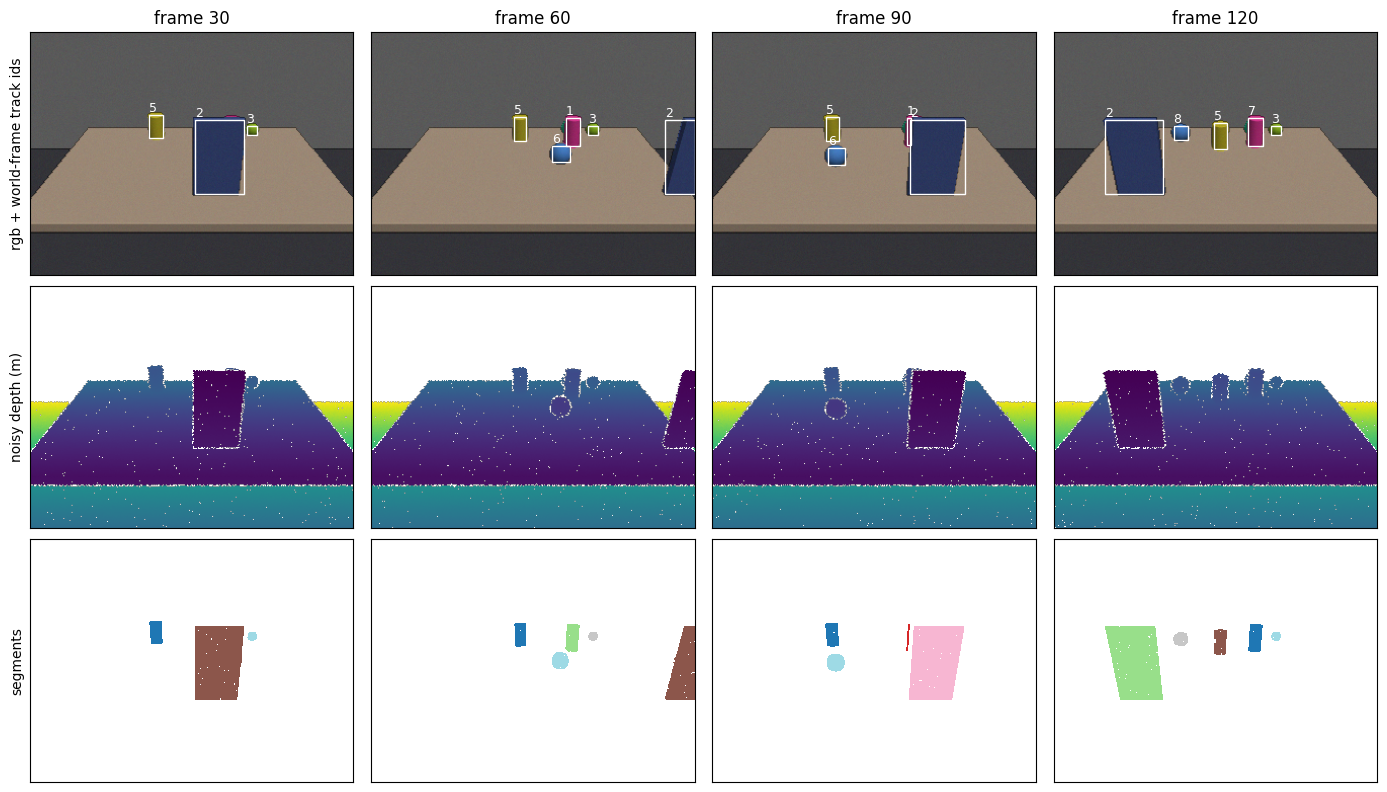

In [ ]:
def replay_with_tracks(seq, keep_frames):
    segmenter = TabletopSegmenter(seed=seq['seed'])
    sensor_rng = np.random.default_rng([seq['seed'], 0])
    tracker = MetricSpaceTracker('world')
    kept = {}
    for t in range(max(keep_frames) + 1):
        rgb_clean, depth_clean, _ = render_frame(seq, t)
        rgb, depth = apply_sensor_model(rgb_clean, depth_clean, sensor_rng)
        detections, labels = segmenter.detect(rgb, depth)
        reported = tracker.step(detections, seq['reported_rot'][t], seq['reported_pos'][t])
        if t in keep_frames:
            kept[t] = (rgb, depth, labels, detections, reported)
    return kept


example_seq = sequences[('occlusion', 2)]
example_frames = [30, 60, 90, 120]
replay = replay_with_tracks(example_seq, example_frames)

fig, axes = plt.subplots(3, len(example_frames), figsize=(14, 8))
for col, t in enumerate(example_frames):
    rgb, depth, labels, detections, reported = replay[t]
    axes[0, col].imshow(rgb)
    for track_id, det_index, _ in reported:
        u0, v0, u1, v1 = detections[det_index]['box']
        axes[0, col].add_patch(plt.Rectangle((u0, v0), u1 - u0, v1 - v0, fill=False, color='white', lw=1))
        axes[0, col].text(u0, v0 - 3, str(track_id), color='white', fontsize=9)
    axes[0, col].set_title(f'frame {t}')
    axes[1, col].imshow(np.where(depth > 0, depth, np.nan), cmap='viridis')
    axes[2, col].imshow(np.where(labels > 0, labels, np.nan), cmap='tab20', interpolation='nearest')
for ax in axes.ravel():
    ax.set_xticks([])
    ax.set_yticks([])
axes[0, 0].set_ylabel('rgb + world-frame track ids')
axes[1, 0].set_ylabel('noisy depth (m)')
axes[2, 0].set_ylabel('segments')
plt.tight_layout()
plt.show()

In [ ]:
area_spread = []
for k in range(N_SEQUENCES):
    seq = sequences[('nominal', k)]
    for gt_id, obj in enumerate(seq['objects']):
        if obj['is_static']:
            areas = np.array([metric_area(det) for record in perception_cache[('nominal', k)]['default']
                              for det in record['detections'] if det['gt_id'] == gt_id])
            if len(areas) > 20:     
                area_spread.append(areas.std() / areas.mean())
print('relative spread of segment area over time, static objects in the nominal scenario')
print('median %.3f, 90th percentile %.3f, max %.3f  (%d objects)' % (np.median(area_spread), np.percentile(area_spread, 90),
                                                                    np.max(area_spread), len(area_spread)))

relative spread of segment area over time, static objects in the nominal scenario
median 0.015, 90th percentile 0.112, max 0.308  (44 objects)


In [ ]:
TRACKERS = {
    'image 2D iou': lambda: ImageSpaceTracker(),
    'image 2D centre': lambda: ImageSpaceTracker(association='centre'),
    'camera 3D': lambda: MetricSpaceTracker('camera'),
    'world 3D': lambda: MetricSpaceTracker('world'),
    'world 3D truncation-aware': lambda: MetricSpaceTracker('world', truncation_aware=True),
}

rows = []
for (scenario, k), seq in sequences.items():
    frame_records = perception_cache[(scenario, k)]['default']
    outputs = {name: run_tracker(make(), seq, frame_records) for name, make in TRACKERS.items()}
    outputs['oracle ids'] = oracle_outputs(frame_records)
    outputs['new id every frame'] = fresh_id_outputs(frame_records)
    for name, track_outputs in outputs.items():
        rows.append({'scenario': scenario, 'sequence': k, 'tracker': name, **score_tracking(frame_records, track_outputs)})
main_results = pd.DataFrame(rows)
main_results.groupby(['scenario', 'tracker'], sort=False)[['idf1', 'mota', 'id_switches', 'missed', 'false_tracks']].mean().round(3)

idf1   mota  id_switches  missed  false_tracks
scenario      tracker                                                                   
nominal       image 2D iou               0.981  0.983        0.333  12.267         0.000
              image 2D centre            0.983  0.984        0.200  11.667         0.000
              camera 3D                  0.987  0.984        0.067  11.667         0.000
              world 3D                   0.987  0.984        0.067  11.667         0.000
              world 3D truncation-aware  0.992  0.984        0.067  11.667         0.000
              oracle ids                 0.999  0.998        0.000   1.667         0.000
              new id every frame         0.007  0.007      731.667   1.667         0.000
occlusion     image 2D iou               0.577  0.918        8.000  46.467         0.000
              image 2D centre            0.719  0.934        5.333  38.467         0.000
              camera 3D                  0.724  0.931        5.067  40.400         0.000
              world 3D                   0.724  0.931        5.067  40.400         0.000
              world 3D truncation-aware  0.889  0.946        1.733  34.067         0.000
              oracle ids                 0.984  0.969        0.000  20.600         0.000
              new id every frame         0.008  0.007      636.800  20.600         0.000
camera_motion image 2D iou               0.934  0.961        2.600  26.333         0.000
              image 2D centre            0.965  0.979        0.600  15.133         0.000
              camera 3D                  0.974  0.979        0.600  15.333         0.000
              world 3D                   0.983  0.980        0.133  14.533         0.000
              world 3D truncation-aware  0.983  0.980        0.133  14.533         0.000
              oracle ids                 0.997  0.994        0.000   4.400         0.000
              new id every frame         0.007  0.007      729.933   4.400         0.000
crowded       image 2D iou               0.935  0.953        1.467  39.800         0.000
              image 2D centre            0.953  0.956        0.867  37.800         0.000
              camera 3D                  0.963  0.956        0.533  38.133         0.000
              world 3D                   0.963  0.956        0.533  38.133         0.000
              world 3D truncation-aware  0.964  0.956        0.533  38.133         0.000
              oracle ids                 0.985  0.971        0.000  25.267         0.000
              new id every frame         0.007  0.007      848.533  25.267         0.133

In [ ]:
def bootstrap_mean_ci(values, rng, n_resamples=5000):
    values = np.asarray(values, dtype=float)
    resampled = values[rng.integers(0, len(values), size=(n_resamples, len(values)))].mean(axis=1)
    return values.mean(), np.percentile(resampled, 2.5), np.percentile(resampled, 97.5)


def paired_wilcoxon(a, b):
    difference = np.asarray(a) - np.asarray(b)
    if np.allclose(difference, 0):
        return np.nan
    return wilcoxon(difference).pvalue


def holm_adjust(p_values):
    p_values = np.asarray(p_values, dtype=float)
    adjusted = np.full(len(p_values), np.nan)
    tested = np.flatnonzero(~np.isnan(p_values))
    order = tested[np.argsort(p_values[tested])]
    running_max = 0.0
    for rank, index in enumerate(order):
        running_max = max(running_max, (len(order) - rank) * p_values[index])
        adjusted[index] = min(1.0, running_max)
    return adjusted


def wilson_interval(successes, n, z=1.96):
    if n == 0:
        return np.nan, np.nan
    share = successes / n
    centre = (share + z ** 2 / (2 * n)) / (1 + z ** 2 / n)
    half = z * np.sqrt(share * (1 - share) / n + z ** 2 / (4 * n ** 2)) / (1 + z ** 2 / n)
    return centre - half, centre + half


boot_rng = np.random.default_rng(2026)
ci_rows = []
for scenario in SCENARIOS:
    for name in TRACKERS:
        picked = main_results[(main_results.scenario == scenario) & (main_results.tracker == name)]
        mean, low, high = bootstrap_mean_ci(picked.idf1, boot_rng)
        ci_rows.append({'scenario': scenario, 'tracker': name, 'idf1': mean, 'ci_low': low, 'ci_high': high,
                        'id_switches_per_seq': picked.id_switches.mean()})
idf1_summary = pd.DataFrame(ci_rows)
idf1_summary.round(3)

,scenario,tracker,idf1,ci_low,ci_high,id_switches_per_seq
0,nominal,image 2D iou,0.981,0.968,0.992,0.333
1,nominal,image 2D centre,0.983,0.968,0.993,0.200
2,nominal,camera 3D,0.987,0.976,0.993,0.067
3,nominal,world 3D,0.987,0.976,0.993,0.067
4,nominal,world 3D truncation-aware,0.992,0.990,0.993,0.067
5,occlusion,image 2D iou,0.577,0.534,0.621,8.000
6,occlusion,image 2D centre,0.719,0.669,0.768,5.333
7,occlusion,camera 3D,0.724,0.679,0.766,5.067
8,occlusion,world 3D,0.724,0.678,0.765,5.067
9,occlusion,world 3D truncation-aware,0.889,0.843,0.925,1.733


In [ ]:
comparisons = [('world 3D', 'image 2D iou'), ('world 3D', 'image 2D centre'), ('world 3D', 'camera 3D'),
               ('world 3D truncation-aware', 'world 3D')]
test_rows = []
for scenario in SCENARIOS:
    per_seq = main_results[main_results.scenario == scenario].pivot(index='sequence', columns='tracker', values='idf1')
    for candidate, baseline in comparisons:
        gain = per_seq[candidate] - per_seq[baseline]
        mean_gain, low, high = bootstrap_mean_ci(gain, boot_rng)
        test_rows.append({'scenario': scenario, 'comparison': f'{candidate} vs {baseline}',
                          'idf1_diff': mean_gain, 'ci_low': low, 'ci_high': high,
                          'n_better': int((gain > 0).sum()), 'n_worse': int((gain < 0).sum()),
                          'p_wilcoxon': paired_wilcoxon(per_seq[candidate], per_seq[baseline])})
paired_tests = pd.DataFrame(test_rows)
paired_tests['p_holm'] = holm_adjust(paired_tests.p_wilcoxon)
paired_tests.round(4)

,scenario,comparison,idf1_diff,ci_low,ci_high,n_better,n_worse,p_wilcoxon,p_holm
0,nominal,world 3D vs image 2D iou,0.0064,-0.0009,0.0165,3,1,0.2733,1.0000
1,nominal,world 3D vs image 2D centre,0.0044,-0.0022,0.0153,1,1,0.6547,1.0000
2,nominal,world 3D vs camera 3D,0.0000,0.0000,0.0000,0,0,NaN,NaN
3,nominal,world 3D truncation-aware vs world 3D,0.0044,-0.0017,0.0147,1,1,0.6547,1.0000
4,occlusion,world 3D vs image 2D iou,0.1467,0.0857,0.2135,12,1,0.0019,0.0206
5,occlusion,world 3D vs image 2D centre,0.0055,-0.0256,0.0396,6,7,0.9165,1.0000
6,occlusion,world 3D vs camera 3D,0.0000,0.0000,0.0000,0,0,NaN,NaN
7,occlusion,world 3D truncation-aware vs world 3D,0.1645,0.1333,0.1963,15,0,0.0001,0.0007
8,camera_motion,world 3D vs image 2D iou,0.0486,0.0085,0.0956,10,1,0.0262,0.2623
9,camera_motion,world 3D vs image 2D centre,0.0175,-0.0089,0.0491,6,2,0.2626,1.0000


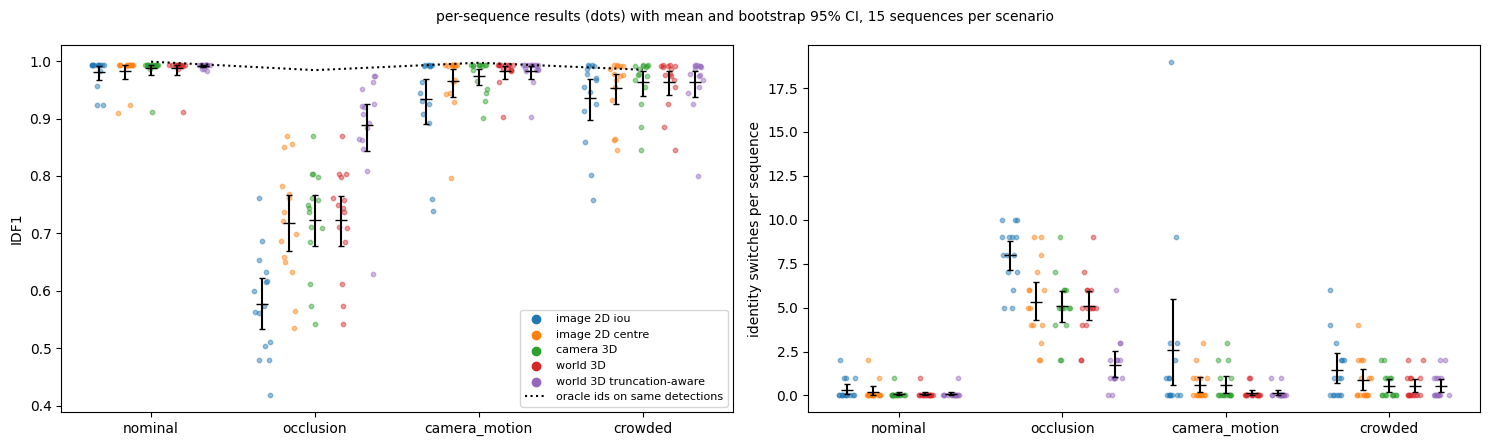

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
jitter_rng = np.random.default_rng(3)
for ax, metric in zip(axes, ['idf1', 'id_switches']):
    for i, name in enumerate(TRACKERS):
        for j, scenario in enumerate(SCENARIOS):
            picked = main_results[(main_results.scenario == scenario) & (main_results.tracker == name)][metric].values
            x = j + (i - 2) * 0.16
            ax.scatter(x + jitter_rng.uniform(-0.05, 0.05, len(picked)), picked, s=10, alpha=0.45, color=f'C{i}')
            mean, low, high = bootstrap_mean_ci(picked, boot_rng)
            ax.errorbar(x, mean, yerr=[[mean - low], [high - mean]], fmt='_', color='k', capsize=2, ms=9)
        ax.scatter([], [], color=f'C{i}', label=name)
    ax.set_xticks(range(len(SCENARIOS)))
    ax.set_xticklabels(SCENARIOS)
    ax.set_ylabel('IDF1' if metric == 'idf1' else 'identity switches per sequence')
ceiling = main_results[main_results.tracker == 'oracle ids'].groupby('scenario', sort=False).idf1.mean()
axes[0].plot(range(len(SCENARIOS)), ceiling[SCENARIOS].values, 'k:', label='oracle ids on same detections')
axes[0].legend(fontsize=8, loc='lower right')
fig.suptitle(f'per-sequence results (dots) with mean and bootstrap 95% CI, {N_SEQUENCES} sequences per scenario', fontsize=10)
plt.tight_layout()
plt.show()

In [ ]:
gates_m = [0.05, 0.1, 0.2]
variants = {f'image 2D iou, iou>={v}': (lambda v=v: ImageSpaceTracker(min_iou=v)) for v in [0.01, 0.1, 0.3]}
variants.update({f'image 2D centre, gate {v} m equiv.': (lambda v=v: ImageSpaceTracker(association='centre', max_pixel_distance=v * PIXELS_PER_METRE))
                 for v in gates_m})
variants.update({f'world 3D, gate {v} m': (lambda v=v: MetricSpaceTracker('world', max_distance=v)) for v in gates_m})
variants.update({f'world 3D truncation-aware, gate {v} m': (lambda v=v: MetricSpaceTracker('world', max_distance=v, truncation_aware=True))
                 for v in gates_m})
variants.update({f'image 2D centre, max_age={v}': (lambda v=v: ImageSpaceTracker(association='centre', max_age=v)) for v in [10, 40]})
variants.update({f'world 3D, max_age={v}': (lambda v=v: MetricSpaceTracker('world', max_age=v)) for v in [10, 40]})

rows = []
for (scenario, k), seq in sequences.items():
    frame_records = perception_cache[(scenario, k)]['default']
    for name, make in variants.items():
        rows.append({'scenario': scenario, 'variant': name,
                     'idf1': score_tracking(frame_records, run_tracker(make(), seq, frame_records))['idf1']})
sensitivity = pd.DataFrame(rows).pivot_table(index='variant', columns='scenario', values='idf1', sort=False)[SCENARIOS]
sensitivity.round(3)

scenario,nominal,occlusion,camera_motion,crowded
variant,,,,
"image 2D iou, iou>=0.01",0.981,0.575,0.952,0.938
"image 2D iou, iou>=0.1",0.981,0.577,0.934,0.935
"image 2D iou, iou>=0.3",0.973,0.561,0.688,0.917
"image 2D centre, gate 0.05 m equiv.",0.983,0.606,0.953,0.938
"image 2D centre, gate 0.1 m equiv.",0.983,0.719,0.965,0.953
"image 2D centre, gate 0.2 m equiv.",0.992,0.834,0.959,0.969
"world 3D, gate 0.05 m",0.980,0.590,0.967,0.941
"world 3D, gate 0.1 m",0.987,0.724,0.983,0.963
"world 3D, gate 0.2 m",0.992,0.897,0.990,0.973


In [ ]:
def position_statistics(seq, frame_records):
    tracker = MetricSpaceTracker('world')
    samples = {}
    for t, record in enumerate(frame_records):
        reported = tracker.step(record['detections'], seq['reported_rot'][t], seq['reported_pos'][t])
        for _, det_index, filtered in reported:
            det = record['detections'][det_index]
            if det['gt_id'] < 0:
                continue
            raw = seq['reported_rot'][t] @ det['centroid_cam'] + seq['reported_pos'][t]
            truth = seq['objects'][det['gt_id']]['path'][t]
            samples.setdefault(det['gt_id'], []).append(np.concatenate([raw, filtered, truth]))

    stats = {'centre_error_raw': [], 'centre_error_filtered': [], 'jitter_raw': [], 'jitter_filtered': []}
    for gt_id, values in samples.items():
        values = np.array(values)
        raw, filtered, truth = values[:, :3], values[:, 3:6], values[:, 6:]
        stats['centre_error_raw'].append(np.linalg.norm(raw - truth, axis=1).mean())
        stats['centre_error_filtered'].append(np.linalg.norm(filtered - truth, axis=1).mean())
        if seq['objects'][gt_id]['is_static'] and len(values) >= 20:
            stats['jitter_raw'].append(np.sqrt(((raw - raw.mean(axis=0)) ** 2).sum(axis=1).mean()))
            stats['jitter_filtered'].append(np.sqrt(((filtered - filtered.mean(axis=0)) ** 2).sum(axis=1).mean()))
    return {name: float(np.mean(v)) if v else np.nan for name, v in stats.items()}


rows = []
for (scenario, k), seq in sequences.items():
    rows.append({'scenario': scenario, 'sequence': k, **position_statistics(seq, perception_cache[(scenario, k)]['default'])})
position_results = pd.DataFrame(rows)
(position_results.groupby('scenario', sort=False).mean().drop(columns='sequence') * 1000).round(2)

,centre_error_raw,centre_error_filtered,jitter_raw,jitter_filtered
scenario,,,,
nominal,35.73,35.71,2.12,2.00
occlusion,36.47,36.46,4.89,4.68
camera_motion,36.77,36.52,9.23,8.08
crowded,36.20,36.19,3.38,3.25


In [ ]:
jitter_pairs = position_results[position_results.scenario.isin(['nominal', 'camera_motion'])]
for column in ['jitter_raw', 'jitter_filtered']:
    still = jitter_pairs[jitter_pairs.scenario == 'nominal'][column].values * 1000
    moving = jitter_pairs[jitter_pairs.scenario == 'camera_motion'][column].values * 1000
    still_ci = bootstrap_mean_ci(still, boot_rng)
    moving_ci = bootstrap_mean_ci(moving, boot_rng)
    print(f'{column} of static objects, fixed camera:  {still_ci[0]:.2f} mm  [{still_ci[1]:.2f}, {still_ci[2]:.2f}]')
    print(f'{column} of static objects, moving camera: {moving_ci[0]:.2f} mm  [{moving_ci[1]:.2f}, {moving_ci[2]:.2f}]')

jitter_raw of static objects, fixed camera:  2.12 mm  [1.56, 2.71]
jitter_raw of static objects, moving camera: 9.23 mm  [8.32, 10.30]
jitter_filtered of static objects, fixed camera:  2.00 mm  [1.44, 2.61]
jitter_filtered of static objects, moving camera: 8.08 mm  [7.07, 9.26]


In [ ]:
noise_levels = [0, 1, 2, 4, 6]
noise_trackers = ['image 2D iou', 'image 2D centre', 'world 3D']
rows = []
for k in range(N_SEQUENCES):
    seq = sequences[('nominal', k)]
    for level in noise_levels:
        frame_records = perception_cache[('nominal', k)]['default' if level == 1 else f'depth_noise_{level}']
        row = {'depth_noise': level, 'sequence': k}
        row.update(position_statistics(seq, frame_records))
        row.update(detection_quality(frame_records))
        for name in noise_trackers:
            row[f'idf1 {name}'] = score_tracking(frame_records, run_tracker(TRACKERS[name](), seq, frame_records))['idf1']
        rows.append(row)
noise_results = pd.DataFrame(rows)
noise_results.groupby('depth_noise').mean().drop(columns='sequence').round(4)

,centre_error_raw,centre_error_filtered,jitter_raw,jitter_filtered,recall,false_alarms_per_frame,idf1 image 2D iou,idf1 image 2D centre,idf1 world 3D
depth_noise,,,,,,,,,
0,0.0357,0.0357,0.0020,0.0019,0.9976,0.0000,0.9829,0.9879,0.9866
1,0.0357,0.0357,0.0021,0.0020,0.9978,0.0000,0.9808,0.9829,0.9872
2,0.0358,0.0357,0.0023,0.0021,0.9975,0.0004,0.9830,0.9878,0.9871
4,0.0370,0.0369,0.0030,0.0026,0.9978,0.0133,0.9741,0.9883,0.9719
6,0.0397,0.0397,0.0035,0.0029,0.9966,0.0196,0.9557,0.9590,0.9536


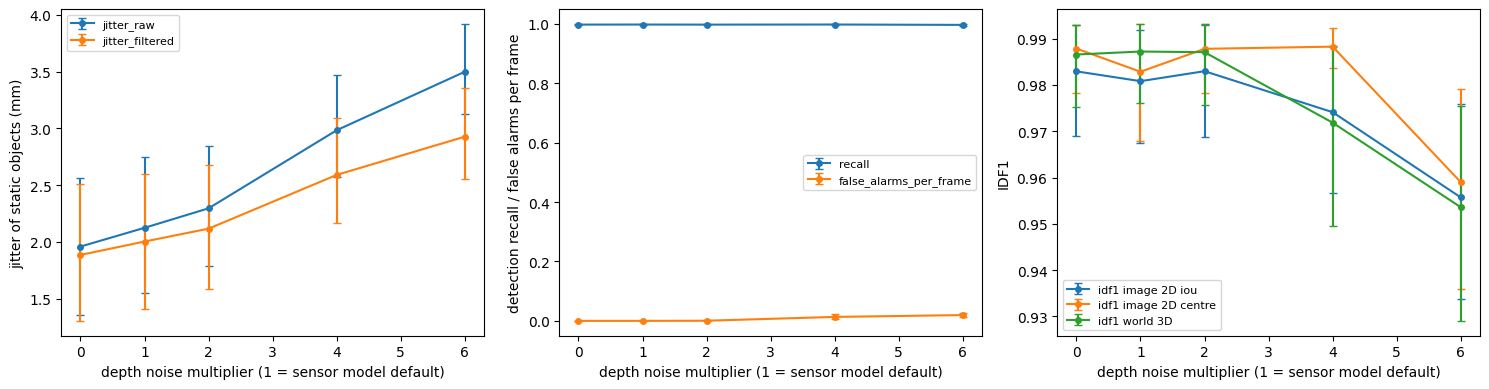

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
panels = [(['jitter_raw', 'jitter_filtered'], 1000, 'jitter of static objects (mm)'),
          (['recall', 'false_alarms_per_frame'], 1, 'detection recall / false alarms per frame'),
          ([f'idf1 {name}' for name in noise_trackers], 1, 'IDF1')]
for ax, (columns, scale, ylabel) in zip(axes, panels):
    for column in columns:
        ci = np.array([bootstrap_mean_ci(noise_results[noise_results.depth_noise == level][column].dropna() * scale, boot_rng)
                       for level in noise_levels])
        ax.errorbar(noise_levels, ci[:, 0], yerr=[ci[:, 0] - ci[:, 1], ci[:, 2] - ci[:, 0]], marker='o', ms=4, capsize=3, label=column)
    ax.set_xlabel('depth noise multiplier (1 = sensor model default)')
    ax.set_ylabel(ylabel)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [ ]:
crowded_conditions = ['depth_only', 'default', 'brightness_0.5', 'brightness_0.25', 'brightness_0.12']
rows = []
for k in range(N_SEQUENCES):
    seq = sequences[('crowded', k)]
    for name in crowded_conditions:
        frame_records = perception_cache[('crowded', k)][name]
        row = {'condition': name, 'sequence': k, **detection_quality(frame_records)}
        row['idf1 oracle ids'] = score_tracking(frame_records, oracle_outputs(frame_records))['idf1']
        row['idf1 world 3D'] = score_tracking(frame_records, run_tracker(MetricSpaceTracker('world'), seq, frame_records))['idf1']
        rows.append(row)
segmentation_results = pd.DataFrame(rows)
segmentation_results.groupby('condition', sort=False).mean().drop(columns='sequence').round(3)

,recall,false_alarms_per_frame,idf1 oracle ids,idf1 world 3D
condition,,,,
depth_only,0.980,0.004,0.989,0.974
default,0.971,0.001,0.985,0.963
brightness_0.5,0.971,0.001,0.985,0.962
brightness_0.25,0.971,0.005,0.985,0.959
brightness_0.12,0.907,0.607,0.950,0.636


In [ ]:
by_seq = segmentation_results.pivot(index='sequence', columns='condition')
for metric in ['recall', 'false_alarms_per_frame', 'idf1 world 3D']:
    change = by_seq[metric]['default'] - by_seq[metric]['depth_only']
    mean, low, high = bootstrap_mean_ci(change, boot_rng)
    p = paired_wilcoxon(by_seq[metric]['default'], by_seq[metric]['depth_only'])
    print(f'adding the colour cue changes {metric} by {mean:+.3f}  [{low:+.3f}, {high:+.3f}],  wilcoxon p = {p:.4f}')

adding the colour cue changes recall by -0.009  [-0.017, -0.001],  wilcoxon p = 0.0186
adding the colour cue changes false_alarms_per_frame by -0.004  [-0.011, +0.001],  wilcoxon p = 0.3573
adding the colour cue changes idf1 world 3D by -0.011  [-0.025, -0.001],  wilcoxon p = 0.0480


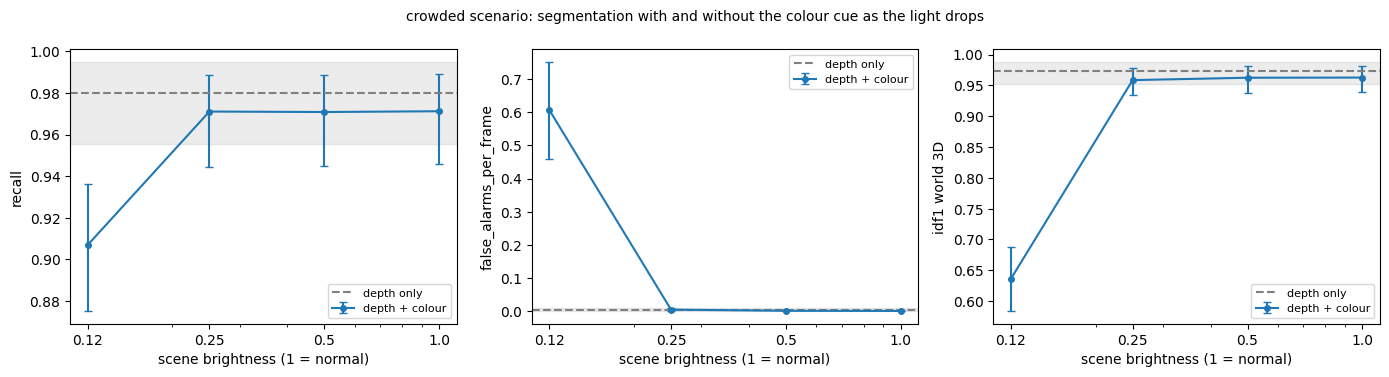

In [ ]:
brightness_levels = [1.0, 0.5, 0.25, 0.12]
brightness_names = ['default', 'brightness_0.5', 'brightness_0.25', 'brightness_0.12']
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, metric in zip(axes, ['recall', 'false_alarms_per_frame', 'idf1 world 3D']):
    ci = np.array([bootstrap_mean_ci(by_seq[metric][name], boot_rng) for name in brightness_names])
    ax.errorbar(brightness_levels, ci[:, 0], yerr=[ci[:, 0] - ci[:, 1], ci[:, 2] - ci[:, 0]], marker='o', ms=4, capsize=3,
                label='depth + colour')
    reference = bootstrap_mean_ci(by_seq[metric]['depth_only'], boot_rng)
    ax.axhline(reference[0], color='gray', ls='--', label='depth only')
    ax.axhspan(reference[1], reference[2], color='gray', alpha=0.15)
    ax.set_xscale('log')
    ax.set_xticks(brightness_levels)
    ax.set_xticklabels(brightness_levels)
    ax.set_xlabel('scene brightness (1 = normal)')
    ax.set_ylabel(metric)
    ax.legend(fontsize=8)
fig.suptitle('crowded scenario: segmentation with and without the colour cue as the light drops', fontsize=10)
plt.tight_layout()
plt.show()

In [ ]:
timing_seq = sequences[('nominal', 0)]
timing_segmenter = TabletopSegmenter(seed=0)
timing_tracker = MetricSpaceTracker('world')
timing_rng = np.random.default_rng(11)
stage_ms = {'segmentation': [], 'tracking': []}
for t in range(N_FRAMES):
    rgb_clean, depth_clean, _ = render_frame(timing_seq, t)
    rgb, depth = apply_sensor_model(rgb_clean, depth_clean, timing_rng)
    t0 = time.perf_counter()
    detections, _ = timing_segmenter.detect(rgb, depth)
    t1 = time.perf_counter()
    timing_tracker.step(detections, timing_seq['reported_rot'][t], timing_seq['reported_pos'][t])
    t2 = time.perf_counter()
    stage_ms['segmentation'].append(1000 * (t1 - t0))
    stage_ms['tracking'].append(1000 * (t2 - t1))

latency = pd.DataFrame(stage_ms)
latency['total'] = latency.sum(axis=1)
print(latency.describe(percentiles=[0.5, 0.95]).loc[['50%', '95%', 'max']].round(2))
print(f"median throughput {1000 / latency.total.median():.0f} frames/s on one cpu core at {IMG_W}x{IMG_H}, camera runs at {FPS}")

     segmentation  tracking  total
50%         42.78      0.45  43.28
95%         46.37      0.55  46.84
max         62.34      0.94  62.78
median throughput 23 frames/s on one cpu core at 320x240, camera runs at 15


In [ ]:
TENTATIVE, CONFIRMED, LOST, DORMANT, DELETED = 'tentative', 'confirmed', 'lost', 'dormant', 'deleted'
ALLOWED_TRANSITIONS = {(None, TENTATIVE), (DORMANT, TENTATIVE), (TENTATIVE, CONFIRMED), (TENTATIVE, DELETED), (TENTATIVE, DORMANT),
                       (CONFIRMED, LOST), (LOST, CONFIRMED), (LOST, DORMANT), (LOST, DELETED), (DORMANT, DELETED),
                       (CONFIRMED, DORMANT), (CONFIRMED, DELETED)}
CHI2_99_3DOF = 11.34
REID_MEMORY = 8.0          
REID_MAX_SPEED = 0.4        
REID_AMBIGUITY_RATIO = 0.7
MEASUREMENT_KEYS = {'centroid': 'centroid_cam', 'model_uncorrected': 'centre_uncorrected_cam', 'model': 'centre_cam'}
VISIBILITY_EDGES = np.array([0.4, TRUNCATED_AREA_RATIO, 1 / TRUNCATED_AREA_RATIO])
NORMAL_VIEW = 2


def appearance(det):
    return np.array([det['chroma'][0], det['chroma'][1], det['height']])


def size_descriptor(det):
    sides = np.sort(det['top_sides'])[::-1]
    return np.array([det['height'], sides[0], sides[1]])


def size_and_colour(det):
    return np.concatenate([appearance(det), size_descriptor(det)[1:]])


DESCRIPTORS = {'colour and height': {'describe': appearance, 'full_view': np.array([False, False, False])},
               'size': {'describe': size_descriptor, 'full_view': np.array([False, True, True])},
               'size and colour': {'describe': size_and_colour, 'full_view': np.array([False, False, False, True, True])}}


def measurement_std(noise_model, detections, view):
    kind = noise_model['kind']
    if kind == 'table':
        by_view = np.array([noise_model['std'][det['shape']] for det in detections])
        std = by_view[np.arange(len(detections))[None, :], view]
        if 'reference_noise' in noise_model:
            frame_noise = np.array([det['noise_std'] for det in detections])
            std = std * np.maximum(1.0, frame_noise / noise_model['reference_noise'])[None, :]
        return std
    depth = np.array([det['centroid_cam'][2] for det in detections])
    if kind == 'distance':
        log_std = noise_model['weights'][0] + noise_model['weights'][1] * np.log(depth)
        return np.exp(log_std)[None, :] * np.ones(view.shape)
    features = np.array([noise_features(det) for det in detections])
    return np.exp(features @ noise_model['weights'])[None, :] * np.exp(np.asarray(noise_model['view_terms'])[view])


def noise_features(det):
    return np.array([1.0, np.log(det['centroid_cam'][2]), np.log(det['n_pixels']), float(det['shape'] == 'sphere'),
                     min(det['sphere_fit_error'] / (2 * det['noise_std'] + 0.001), 5.0), det['occluder_border'],
                     det['unknown_border'], np.log(det['noise_std'] + 1e-4)])


def skew(p):
    return np.array([[0.0, -p[2], p[1]], [p[2], 0.0, -p[0]], [-p[1], p[0], 0.0]])


def pose_jacobian(cam_rot, point_cam):
    return np.hstack([np.eye(3), -cam_rot @ skew(point_cam)])


class TimedKalmanFilter:
    def __init__(self, first_measurement, R, accel_std, speed_std):
        self.x = np.concatenate([first_measurement, np.zeros(3)])
        self.P = np.zeros((6, 6))
        self.P[:3, :3] = R
        self.P[3:, 3:] = speed_std ** 2 * np.eye(3)
        self.H = np.hstack([np.eye(3), np.zeros((3, 3))])
        self.spectral_density = accel_std ** 2 * DT

    def predict(self, dt):
        F = np.eye(6)
        F[:3, 3:] = dt * np.eye(3)
        q = self.spectral_density * np.eye(3)
        Q = np.block([[q * dt ** 3 / 3, q * dt ** 2 / 2], [q * dt ** 2 / 2, q * dt]])
        self.x = F @ self.x
        self.P = F @ self.P @ F.T + Q

    def update(self, measurement, R):
        residual = measurement - self.x[:3]
        S = self.P[:3, :3] + R
        K = np.linalg.solve(S, self.H @ self.P).T
        self.x = self.x + K @ residual
        A = np.eye(6) - K @ self.H
        self.P = A @ self.P @ A.T + K @ R @ K.T
        return residual @ np.linalg.solve(S, residual)


class AdaptiveTracker:
    def __init__(self, association='mahalanobis', truncation_aware=True, measurement='centroid', measurement_std=METRIC_MEAS_STD,
                 pose_aware=False, merge_aware=False, body_gate=False, reid_model=None, noise_model=None,
                 rival_scope='reachable', appearance_gate=None, area_learning_hits=0, shape_cost=0.0, fixed_dt=None,
                 accel_std=METRIC_ACCEL_STD, max_distance=0.10, max_age=20, min_hits=3, descriptor='colour and height',
                 identity_gate=None):
        self.association = association
        self.truncation_aware = truncation_aware
        self.measurement_key = MEASUREMENT_KEYS[measurement]
        self.sensor_var = measurement_std ** 2
        self.pose_aware = pose_aware
        self.merge_aware = merge_aware
        self.body_gate = body_gate
        self.reid_model = reid_model
        self.noise_model = noise_model
        self.rival_scope = rival_scope
        self.appearance_gate = appearance_gate
        self.area_learning_hits = area_learning_hits
        self.shape_cost = shape_cost
        self.describe = DESCRIPTORS[descriptor]['describe']
        self.full_view_only = DESCRIPTORS[descriptor]['full_view']
        self.identity_gate = identity_gate
        self.fixed_dt = fixed_dt
        self.accel_std = accel_std
        self.max_distance = max_distance
        self.max_coast_time = max_age * DT
        self.min_hits = min_hits
        self.tracks, self.lost = [], []
        self.next_id = 0
        self.last_time = None
        self.transitions = deque(maxlen=5000)

    def change_state(self, track, new_state, timestamp):
        old_state = track.get('state')
        if (old_state, new_state) not in ALLOWED_TRANSITIONS:
            raise RuntimeError(f'track {track.get("id")} cannot go from {old_state} to {new_state}')
        track['state'] = new_state
        self.transitions.append((timestamp, track.get('id'), old_state, new_state))

    def match_lost_tracks(self, detections, unmatched, measurements, timestamp):
        for old in self.lost:
            if timestamp - old['last_seen'] > REID_MEMORY:
                self.change_state(old, DELETED, timestamp)
        self.lost = [old for old in self.lost if old['state'] == DORMANT]
        if self.reid_model is None or not self.lost or not unmatched:
            return {}
        looks = np.array([self.describe(detections[j]) for j in unmatched])
        remembered = np.array([old['descriptor'] for old in self.lost])
        distance = np.linalg.norm((looks[:, None, :] - remembered[None, :, :]) / self.reid_model['scale'], axis=2)
        unseen = np.array([timestamp - old['last_seen'] for old in self.lost])
        last_position = np.array([old['last_position'] for old in self.lost])
        travelled = np.linalg.norm(measurements[unmatched][:, None, :] - last_position[None, :, :], axis=2)
        reachable = travelled <= REID_MAX_SPEED * unseen[None, :] + 0.05
        allowed = (distance < self.reid_model['threshold']) & reachable
        rival_distance = np.where(reachable, distance, np.inf) if self.rival_scope == 'reachable' else distance

        rows, cols = linear_sum_assignment(np.where(allowed, distance, 1e6))
        revived = {}
        for r, c in zip(rows, cols):
            if not allowed[r, c]:
                continue
            rivals = np.concatenate([np.delete(rival_distance[r], c), np.delete(rival_distance[:, c], r)])
            if len(rivals) and distance[r, c] > REID_AMBIGUITY_RATIO * rivals.min():
                continue
            revived[unmatched[r]] = c
        return revived

    def step(self, detections, cam_rot, cam_pos, timestamp, pose_cov=None):
        if self.last_time is not None and timestamp <= self.last_time:
            raise ValueError('frame timestamps have to increase')
        previous_time = self.last_time
        dt = DT if previous_time is None else timestamp - previous_time
        if self.fixed_dt is not None:
            dt = self.fixed_dt
        self.last_time = timestamp

        n_dets = len(detections)
        points_cam = [det[self.measurement_key] for det in detections]
        measurements = np.array([cam_rot @ p + cam_pos for p in points_cam]).reshape(-1, 3)
        areas = np.array([metric_area(det) for det in detections])
        pose_part = np.zeros((n_dets, 3, 3))
        if self.pose_aware and pose_cov is not None and pose_cov.any():
            for j, p in enumerate(points_cam):
                J = pose_jacobian(cam_rot, p)
                pose_part[j] = J @ pose_cov @ J.T
        for track in self.tracks:
            track['filter'].predict(dt)

        reported, used = [], set()
        if self.tracks and n_dets:
            predicted = np.array([tr['filter'].x[:3] for tr in self.tracks])
            position_cov = np.array([tr['filter'].P[:3, :3] for tr in self.tracks])
            area_ratio = areas[None, :] / np.array([tr['usual_area'] for tr in self.tracks])[:, None]
            unusual = np.zeros(area_ratio.shape, dtype=bool)
            if self.noise_model is not None:
                view = np.digitize(area_ratio, VISIBILITY_EDGES)
                sensor_var = measurement_std(self.noise_model, detections, view) ** 2
                unusual = view != NORMAL_VIEW
            else:
                if self.truncation_aware:
                    unusual |= area_ratio < TRUNCATED_AREA_RATIO
                if self.merge_aware:
                    unusual |= area_ratio > 1 / TRUNCATED_AREA_RATIO
                sensor_var = np.where(unusual, TRUNCATED_STD_SCALE ** 2, 1.0) * self.sensor_var
            R = sensor_var[:, :, None, None] * np.eye(3) + pose_part[None, :, :, :]
            residual = measurements[None, :, :] - predicted[:, None, :]
            distance = np.linalg.norm(residual, axis=2)
            if self.association == 'euclidean':
                cost = distance
                allowed = distance <= self.max_distance
            else:
                S = position_cov[:, None, :, :] + R
                d2 = np.einsum('ijk,ijk->ij', residual, np.linalg.solve(S, residual[..., None])[..., 0])
                allowed = d2 <= CHI2_99_3DOF
                cost = d2 + np.log(np.linalg.det(S))
            if self.reid_model is not None and (self.shape_cost or self.appearance_gate is not None or self.identity_gate is not None):
                looks = np.array([self.describe(det) for det in detections])
                descriptors = np.array([tr['descriptor'] for tr in self.tracks])
                difference = (descriptors[:, None, :] - looks[None, :, :]) / self.reid_model['scale']
                difference = np.where(unusual[:, :, None] & self.full_view_only, 0.0, difference)
                look_distance = np.linalg.norm(difference, axis=2)
                coasting = np.array([tr['last_seen'] != previous_time for tr in self.tracks])
            if self.shape_cost and self.reid_model is not None:
                cost = cost + self.shape_cost * (look_distance / self.reid_model['threshold']) ** 2
            if self.appearance_gate is not None and self.reid_model is not None:
                allowed &= ~coasting[:, None] | (look_distance < self.appearance_gate * self.reid_model['threshold'])
            if self.identity_gate is not None and self.reid_model is not None:
                confirmed = np.array([tr['state'] == CONFIRMED for tr in self.tracks])
                tested = (confirmed & ~coasting)[:, None] & ~unusual
                allowed &= ~tested | (look_distance < self.identity_gate * self.reid_model['threshold'])
            rows, cols = linear_sum_assignment(np.where(allowed, cost, 1e6))
            matches = [(i, j) for i, j in zip(rows, cols) if allowed[i, j]]
            if self.body_gate:
                fresh = np.array([tr['last_seen'] == previous_time for tr in self.tracks])
                half_width = np.array([tr['half_width'] for tr in self.tracks])
                inside = fresh[:, None] & (distance <= half_width[:, None])
                inside[[i for i, _ in matches], :] = False
                inside[:, [j for _, j in matches]] = False
                rows, cols = linear_sum_assignment(np.where(inside, distance, 1e6))
                matches += [(i, j) for i, j in zip(rows, cols) if inside[i, j]]

            for i, j in matches:
                track = self.tracks[i]
                nis = track['filter'].update(measurements[j], R[i, j])
                if track['hits'] < self.area_learning_hits:
                    track['usual_area'] = max(track['usual_area'], areas[j])
                if not unusual[i, j]:
                    track['usual_area'] = 0.9 * track['usual_area'] + 0.1 * areas[j]
                    track['descriptor'] = 0.9 * track['descriptor'] + 0.1 * self.describe(detections[j])
                    track['half_width'] = 0.9 * track['half_width'] + 0.1 * 0.5 * detections[j]['footprint'][1]
                track['hits'] += 1
                track['last_seen'] = timestamp
                track['last_position'] = measurements[j]
                if track['state'] != CONFIRMED and track['hits'] >= self.min_hits:
                    self.change_state(track, CONFIRMED, timestamp)
                used.add(j)
                if track['state'] == CONFIRMED:
                    reported.append((track['id'], j, track['filter'].x[:3].copy(), track['filter'].P[:3, :3].copy(),
                                     nis, track['hits'], area_ratio[i, j]))

        survivors = []
        for track in self.tracks:
            unseen = timestamp - track['last_seen']
            if unseen == 0:
                survivors.append(track)
            elif track['state'] != TENTATIVE and unseen <= self.max_coast_time + 1e-9:
                if track['state'] == CONFIRMED:
                    self.change_state(track, LOST, timestamp)
                survivors.append(track)
            elif self.reid_model is not None and (track['state'] != TENTATIVE or track['revived']):
                self.change_state(track, DORMANT, timestamp)
                self.lost.append(track)
            else:
                self.change_state(track, DELETED, timestamp)
        self.tracks = survivors

        unmatched = [j for j in range(n_dets) if j not in used]
        revived = self.match_lost_tracks(detections, unmatched, measurements, timestamp)
        for j in unmatched:
            det = detections[j]
            if self.noise_model is None:
                first_var = self.sensor_var
            else:
                first_var = measurement_std(self.noise_model, [det], np.array([[NORMAL_VIEW]]))[0, 0] ** 2
            first_R = first_var * np.eye(3) + pose_part[j]
            track = {'filter': TimedKalmanFilter(measurements[j], first_R, self.accel_std, METRIC_SPEED_STD),
                     'hits': 1, 'last_seen': timestamp, 'last_position': measurements[j], 'revived': j in revived}
            if j in revived:
                old = self.lost[revived[j]]
                track.update(id=old['id'], usual_area=old['usual_area'], descriptor=old['descriptor'], half_width=old['half_width'],
                             state=DORMANT)
            else:
                track.update(id=self.next_id, usual_area=areas[j], descriptor=self.describe(det), half_width=0.5 * det['footprint'][1])
                self.next_id += 1
            self.change_state(track, TENTATIVE, timestamp)
            self.tracks.append(track)
        taken = set(revived.values())
        self.lost = [old for index, old in enumerate(self.lost) if index not in taken]
        return reported


def coasting_tracks(tracker):
    return [(track['id'], track['filter'].x[:3].copy(), track['filter'].P[:3, :3].copy(), track['last_position'].copy())
            for track in tracker.tracks if track['state'] == LOST]


def run_adaptive(tracker, seq, frame_records, frame_ids=None):
    frame_ids = range(len(frame_records)) if frame_ids is None else frame_ids
    return [tracker.step(frame_records[t]['detections'], seq['reported_rot'][t], seq['reported_pos'][t], t * DT, seq['pose_cov'])
            for t in frame_ids]

In [ ]:
def score_association(frame_records, track_outputs):
    gt_frames, track_frames, frames_together, tracked_history = {}, {}, {}, {}
    n_missed = n_false = 0
    for record, reported in zip(frame_records, track_outputs):
        matched = set()
        for entry in reported:
            track_id, gt_id = entry[0], record['detections'][entry[1]]['gt_id']
            if gt_id == IGNORED:
                continue
            track_frames[track_id] = track_frames.get(track_id, 0) + 1
            if gt_id == FALSE_ALARM:
                n_false += 1
                continue
            matched.add(gt_id)
            frames_together[(gt_id, track_id)] = frames_together.get((gt_id, track_id), 0) + 1
        for gt_id in record['visible_gt']:
            gt_frames[gt_id] = gt_frames.get(gt_id, 0) + 1
            tracked_history.setdefault(gt_id, []).append(gt_id in matched)
        n_missed += len(record['visible_gt'] - matched)

    n_true = sum(frames_together.values())
    det_a = n_true / max(n_true + n_missed + n_false, 1)
    ass_a = sum(n * n / (gt_frames[g] + track_frames[k] - n) for (g, k), n in frames_together.items()) / max(n_true, 1)
    fragments = 0
    for history in tracked_history.values():
        history = np.array(history)
        resumed = int((history[1:] & ~history[:-1]).sum())
        fragments += resumed - int(resumed > 0 and not history[0])
    return {'hota_matched': np.sqrt(det_a * ass_a), 'det_a': det_a, 'ass_a': ass_a, 'fragments': fragments}


def estimate_samples(seq, frame_records, track_outputs, frame_ids=None):
    frame_ids = range(len(frame_records)) if frame_ids is None else frame_ids
    rows = []
    for t, reported in zip(frame_ids, track_outputs):
        for _, det_index, position, position_cov, nis, hits, visible_share in reported:
            gt_id = frame_records[t]['detections'][det_index]['gt_id']
            if gt_id < 0:
                continue
            obj = seq['objects'][gt_id]
            error = position - obj['path'][t]
            speed = np.linalg.norm(obj['path'][t] - obj['path'][max(t - 1, 0)]) / DT
            rows.append({'ex': error[0], 'ey': error[1], 'ez': error[2], 'nees': error @ np.linalg.solve(position_cov, error),
                         'nis': nis, 'kind': obj['kind'], 'moving': speed > 0.01, 'track_hits': hits,
                         'visible_share': visible_share})
    return rows


def rmse_mm(samples):
    return 1000 * np.sqrt((samples[['ex', 'ey', 'ez']] ** 2).sum(axis=1).mean())

In [ ]:
HOTA_ALPHAS = np.arange(0.05, 0.99, 0.05)
HOTA_ZERO_DISTANCE = 0.05     


def hota_3d(seq, frame_records, track_outputs, frame_ids=None, zero_distance=HOTA_ZERO_DISTANCE):
    frame_ids = range(len(frame_records)) if frame_ids is None else frame_ids
    gt_per_frame, out_per_frame = [], []
    for t, reported in zip(frame_ids, track_outputs):
        record = frame_records[t]
        gt_ids = sorted(record['visible_gt'])
        kept = [entry for entry in reported if record['detections'][entry[1]]['gt_id'] != IGNORED]
        out_ids = [entry[0] for entry in kept]
        similarity = np.zeros((len(gt_ids), len(kept)))
        if gt_ids and kept:
            truth = np.array([seq['objects'][g]['path'][t] for g in gt_ids])
            estimate = np.array([entry[2] for entry in kept])
            distance = np.linalg.norm(truth[:, None, :] - estimate[None, :, :], axis=2)
            similarity = np.clip(1 - distance / zero_distance, 0, 1)
        gt_per_frame.append(gt_ids)
        out_per_frame.append((out_ids, similarity))

    gt_index = {g: i for i, g in enumerate(sorted({g for ids in gt_per_frame for g in ids}))}
    out_index = {k: i for i, k in enumerate(sorted({k for ids, _ in out_per_frame for k in ids}))}
    potential = np.zeros((len(gt_index), len(out_index)))
    gt_count, out_count = np.zeros(len(gt_index)), np.zeros(len(out_index))
    for gt_ids, (out_ids, similarity) in zip(gt_per_frame, out_per_frame):
        g = np.array([gt_index[i] for i in gt_ids], dtype=int)
        k = np.array([out_index[i] for i in out_ids], dtype=int)
        if len(g) and len(k):
            union = similarity.sum(axis=0)[None, :] + similarity.sum(axis=1)[:, None] - similarity
            potential[g[:, None], k[None, :]] += np.divide(similarity, union, out=np.zeros_like(similarity), where=union > 1e-12)
        gt_count[g] += 1
        out_count[k] += 1
    alignment = potential / np.maximum(gt_count[:, None] + out_count[None, :] - potential, 1e-12)

    n_alpha = len(HOTA_ALPHAS)
    true_pos, false_neg, false_pos, loc = np.zeros(n_alpha), np.zeros(n_alpha), np.zeros(n_alpha), np.zeros(n_alpha)
    matches = np.zeros((n_alpha, len(gt_index), len(out_index)))
    for gt_ids, (out_ids, similarity) in zip(gt_per_frame, out_per_frame):
        if not gt_ids or not out_ids:
            false_neg += len(gt_ids)
            false_pos += len(out_ids)
            continue
        g = np.array([gt_index[i] for i in gt_ids], dtype=int)
        k = np.array([out_index[i] for i in out_ids], dtype=int)
        rows, cols = linear_sum_assignment(-alignment[g[:, None], k[None, :]] * similarity)
        for a, alpha in enumerate(HOTA_ALPHAS):
            ok = similarity[rows, cols] >= alpha - 1e-10
            r, c = rows[ok], cols[ok]
            true_pos[a] += len(r)
            false_neg[a] += len(gt_ids) - len(r)
            false_pos[a] += len(out_ids) - len(r)
            loc[a] += similarity[r, c].sum()
            matches[a, g[r], k[c]] += 1
    det_a = true_pos / np.maximum(true_pos + false_neg + false_pos, 1)
    union = np.maximum(gt_count[None, :, None] + out_count[None, None, :] - matches, 1)
    ass_a = (matches * matches / union).sum(axis=(1, 2)) / np.maximum(true_pos, 1)
    hota = np.sqrt(det_a * ass_a)
    return {'hota': hota.mean(), 'hota_det_a': det_a.mean(), 'hota_ass_a': ass_a.mean(),
            'hota_loc_a': (np.maximum(loc, 1e-10) / np.maximum(true_pos, 1e-10)).mean(), 'hota_at_alpha': hota}


toy_seq = {'objects': [{'path': np.tile([0.1, 0.2, 0.03], (N_FRAMES, 1))}]}
toy_frames = [toy_record([0], [0]) for _ in range(10)]
perfect = hota_3d(toy_seq, toy_frames, [[(5, 0, np.array([0.1, 0.2, 0.03]))] for _ in range(10)])
switched = hota_3d(toy_seq, toy_frames, [[(5 if t < 5 else 6, 0, np.array([0.1, 0.2, 0.03]))] for t in range(10)])
print(f"perfect: HOTA {perfect['hota']:.4f}   id switch halfway: HOTA {switched['hota']:.4f} (sqrt 0.5 = {np.sqrt(0.5):.4f})")
assert np.isclose(perfect['hota'], 1) and np.isclose(switched['hota'], np.sqrt(0.5))
offset = hota_3d(toy_seq, toy_frames, [[(5, 0, np.array([0.11, 0.2, 0.03]))] for _ in range(10)])
expected = np.where(HOTA_ALPHAS <= 0.8 + 1e-9, 1.0, 0.0).mean()
print(f"1 cm offset: HOTA {offset['hota']:.4f}, expected {expected:.4f}, LocA {offset['hota_loc_a']:.3f}")
assert np.isclose(offset['hota'], expected)

perfect: HOTA 1.0000   id switch halfway: HOTA 0.7071 (sqrt 0.5 = 0.7071)
1 cm offset: HOTA 0.8421, expected 0.8421, LocA 0.832


In [ ]:
toy_frames = [toy_record([0], [0]) for _ in range(10)]
toy = score_association(toy_frames, [[(1, 0)] for _ in range(5)] + [[(2, 0)] for _ in range(5)])
print('one object, id changes halfway:', toy)
assert np.isclose(toy['det_a'], 1) and np.isclose(toy['ass_a'], 0.5) and np.isclose(toy['hota_matched'], np.sqrt(0.5))

toy_frames = [toy_record([0], [0]) for _ in range(6)]
toy = score_association(toy_frames, [[(4, 0)], [(4, 0)], [], [], [(4, 0)], [(4, 0)]])
print('one object, same id, lost for two frames:', toy)
assert np.isclose(toy['det_a'], 4 / 6) and np.isclose(toy['ass_a'], 4 / 6) and toy['fragments'] == 1

check_rng = np.random.default_rng(5)
toy_frames, toy_outputs, true_positives = [], [], []
for t in range(40):
    visible = [g for g in range(3) if check_rng.random() < 0.9]
    ids = check_rng.permutation(5)[:len(visible)]
    toy_frames.append(toy_record(visible, visible))
    toy_outputs.append([(int(k), i) for i, k in enumerate(ids) if check_rng.random() < 0.85])
    true_positives += [(t, visible[i], k) for k, i in toy_outputs[-1]]
per_positive = []
for _, g, k in true_positives:
    agree = sum(1 for _, g2, k2 in true_positives if (g2, k2) == (g, k))
    object_frames = sum(g in record['visible_gt'] for record in toy_frames)
    track_frames = sum(1 for _, _, k2 in true_positives if k2 == k)
    per_positive.append(agree / (object_frames + track_frames - agree))
toy = score_association(toy_frames, toy_outputs)
print('AssA closed form %.6f, from the definition %.6f' % (toy['ass_a'], np.mean(per_positive)))
assert np.isclose(toy['ass_a'], np.mean(per_positive))

start_R = METRIC_MEAS_STD ** 2 * np.eye(3)
one_step = TimedKalmanFilter(np.zeros(3), start_R, METRIC_ACCEL_STD, METRIC_SPEED_STD)
two_steps = TimedKalmanFilter(np.zeros(3), start_R, METRIC_ACCEL_STD, METRIC_SPEED_STD)
one_step.predict(2 * DT)
two_steps.predict(DT)
two_steps.predict(DT)
assert np.allclose(one_step.P, two_steps.P)
print('predicting over one skipped frame equals two normal predictions')

stale_tracker = AdaptiveTracker()
stale_tracker.step([], np.eye(3), np.zeros(3), 1.0)
try:
    stale_tracker.step([], np.eye(3), np.zeros(3), 1.0)
    raise AssertionError('a repeated timestamp went through')
except ValueError as err:
    print('repeated timestamp is refused:', err)

point_cam = np.array([0.15, -0.05, 1.3])
pose_cov = sequences[('camera_motion', 0)]['pose_cov']
true_rot = sequences[('camera_motion', 0)]['cam_rot'][10]
J = pose_jacobian(true_rot, point_cam)
shifts = check_rng.multivariate_normal(np.zeros(6), pose_cov, size=20000)
wobbles = Rotation.from_rotvec(shifts[:, 3:]).as_matrix()
sampled = (true_rot @ wobbles @ point_cam) + shifts[:, :3]
gap = np.linalg.norm(np.cov(sampled.T) - J @ pose_cov @ J.T) / np.linalg.norm(J @ pose_cov @ J.T)
print(f'propagated pose covariance vs 20000 sampled poses: relative difference {gap:.3f}')
assert gap < 0.05

rgb_clean, depth_clean, _ = render_frame(probe_seq, 40)
probe_segmenter = TabletopSegmenter(seed=0)
probe_detections, _ = probe_segmenter.detect(rgb_clean, depth_clean)
ball = probe_detections[0]
to_world = lambda p: tilted_rot[40] @ p + tilted_pos[40]
fit_miss = np.linalg.norm(to_world(ball['centre_cam']) - probe['path'][40])
centroid_miss = np.linalg.norm(to_world(ball['centroid_cam']) - probe['path'][40])
print(f"shape called '{ball['shape']}', fitted centre off by {1000 * fit_miss:.4f} mm, surface centroid off by {1000 * centroid_miss:.1f} mm")
assert ball['shape'] == 'sphere' and fit_miss < 1e-5

for kind, size in [('box', np.array([0.05, 0.035, 0.06])), ('cylinder', np.array([0.035, 0.06]))]:
    solid = dict(probe, kind=kind, size=size, yaw=0.6, path=np.tile([0.1, 0.05, size[-1]], (N_FRAMES, 1)))
    rgb_clean, depth_clean, _ = render_frame(dict(probe_seq, objects=[solid]), 40)
    found = TabletopSegmenter(seed=0).detect(rgb_clean, depth_clean)[0][0]
    corrected_miss = np.linalg.norm(to_world(found['centre_cam']) - solid['path'][40])
    plain_miss = np.linalg.norm(to_world(found['centre_uncorrected_cam']) - solid['path'][40])
    print(f"{kind}: called '{found['shape']}', corrected centre off by {1000 * corrected_miss:.1f} mm, top-face mean off by {1000 * plain_miss:.1f} mm")
    assert found['shape'] == 'flat_top' and corrected_miss < 0.005 and corrected_miss < plain_miss

def fake_detection(x):
    position = np.array([x, 0.0, 1.0])
    return {'centroid_cam': position, 'centre_cam': position, 'centre_uncorrected_cam': position, 'n_pixels': 400, 'metric_area': 0.005,
            'shape': 'flat_top', 'height': 0.1, 'footprint': np.array([0.08, 0.08]), 'chroma': np.array([0.4, 0.3, 0.3])}

for use_body_gate in [False, True]:
    jump_tracker = AdaptiveTracker(body_gate=use_body_gate)
    ids = []
    for step, x in enumerate([0.0] * 6 + [0.038] * 3):
        ids.append([entry[0] for entry in jump_tracker.step([fake_detection(x)], np.eye(3), np.zeros(3), step * DT)])
    print('body gate', 'on: ' if use_body_gate else 'off:', 'reported ids per frame', ids)
    assert (ids[-1] == ids[5]) == use_body_gate

check_seq = sequences[('occlusion', 0)]
check_outputs = run_adaptive(AdaptiveTracker(), check_seq, perception_cache[('occlusion', 0)]['depth_only'])
smallest_eigenvalue = min(np.linalg.eigvalsh(entry[3]).min() for reported in check_outputs for entry in reported)
print('smallest covariance eigenvalue over a full occlusion sequence:', smallest_eigenvalue)
assert smallest_eigenvalue > 0

check_seq = sequences[('crowded', 0)]
in_order = perception_cache[('crowded', 0)]['depth_only']
reversed_order = [{'detections': record['detections'][::-1], 'visible_gt': record['visible_gt']} for record in in_order]
forward = score_tracking(in_order, run_adaptive(AdaptiveTracker(), check_seq, in_order))
backward = score_tracking(reversed_order, run_adaptive(AdaptiveTracker(), check_seq, reversed_order))
print('detections in original order:', {k: round(float(v), 4) for k, v in forward.items()})
print('detections in reversed order:', {k: round(float(v), 4) for k, v in backward.items()})

one object, id changes halfway: {'hota_matched': np.float64(0.7071067811865476), 'det_a': 1.0, 'ass_a': 0.5, 'fragments': 0}
one object, same id, lost for two frames: {'hota_matched': np.float64(0.6666666666666666), 'det_a': 0.6666666666666666, 'ass_a': 0.6666666666666666, 'fragments': 1}
AssA closed form 0.144445, from the definition 0.144445
predicting over one skipped frame equals two normal predictions
repeated timestamp is refused: frame timestamps have to increase
propagated pose covariance vs 20000 sampled poses: relative difference 0.006
shape called 'sphere', fitted centre off by 0.0028 mm, surface centroid off by 41.4 mm
box: called 'flat_top', corrected centre off by 1.5 mm, top-face mean off by 14.7 mm
cylinder: called 'flat_top', corrected centre off by 0.6 mm, top-face mean off by 15.4 mm
body gate off: reported ids per frame [[], [], [0], [0], [0], [0], [], [], [1]]
body gate on:  reported ids per frame [[], [], [0], [0], [0], [0], [0], [0], [0]]
smallest covariance eige

In [ ]:
pick_dev_sequences, pick_dev_cache = {}, {}
for k in range(12):
    pick_dev_sequences[k] = build_sequence('pick', seed=7100 + k)
    pick_dev_cache[k] = run_perception(pick_dev_sequences[k], {'depth_only': condition(use_color=False)})['depth_only']


def top_face_rows(seq, frame_records, source):
    usual_area = {}
    for record in frame_records:
        for det in record['detections']:
            usual_area.setdefault(det['gt_id'], []).append(det['metric_area'])
    usual_area = {gt_id: np.median(areas) for gt_id, areas in usual_area.items()}
    rows = []
    for record in frame_records:
        for det in record['detections']:
            if det['gt_id'] < 0 or not seq['objects'][det['gt_id']]['is_target']:
                continue
            row = {'source': source, 'kind': seq['objects'][det['gt_id']]['kind'], 'shape': det['shape'],
                   'visible_share': det['metric_area'] / usual_area[det['gt_id']], 'top_share': det['top_share'],
                   'relative_fit_error': det['sphere_fit_error'] / (2 * det['noise_std'] + 0.001), 'fill': np.nan}
            if det['shape'] == 'flat_top' and np.isfinite(det['top_fill']):
                long_side, short_side = det['top_rect']
                pixel = det['top_pixel']
                row['fill'] = det['top_fill']
                row['log_disc_aspect'] = np.log((long_side + 0.66 * pixel) / (short_side + 1.12 * pixel))
            rows.append(row)
    return rows


dev_faces = pd.DataFrame([row for (scenario, k), seq in sequences.items()
                          for row in top_face_rows(seq, perception_cache[(scenario, k)]['depth_only'], scenario)]
                         + [row for k, seq in pick_dev_sequences.items() for row in top_face_rows(seq, pick_dev_cache[k], 'pick')])
normal_faces = dev_faces[dev_faces.visible_share.between(TRUNCATED_AREA_RATIO, 1 / TRUNCATED_AREA_RATIO)]

passes_fit = normal_faces[normal_faces.relative_fit_error < 1]
loose_and_flat = (passes_fit.relative_fit_error > 0.6) & (passes_fit.top_share > 0.3)
print('detections that pass the sphere fit, share caught by the flat-cap rule')
print(loose_and_flat.groupby(passes_fit.kind).agg(['size', 'mean']).round(4))

faces = normal_faces[normal_faces.fill.notna()]
X = np.column_stack([np.ones(len(faces)), faces.fill, faces.log_disc_aspect])
is_box = (faces.kind == 'box').values.astype(float)
class_weight = np.where(is_box == 1, 0.5 / is_box.mean(), 0.5 / (1 - is_box.mean()))
weights = np.zeros(3)
for _ in range(30):
    p = 1 / (1 + np.exp(-X @ weights))
    hessian = X.T @ (X * (class_weight * p * (1 - p))[:, None]) + 1e-6 * np.eye(3)
    weights = weights + np.linalg.solve(hessian, X.T @ (class_weight * (is_box - p)))
TabletopSegmenter.category_weights = weights
called_box = X @ weights > 0
print()
print('fitted weights [1, fill, log aspect]:', weights.round(2))
for source, label in [(faces.source != 'pick', 'original scenes'), (faces.source == 'pick', 'pick scenes')]:
    box_recall = called_box[source.values & (is_box == 1)].mean()
    cylinder_recall = (~called_box[source.values & (is_box == 0)]).mean()
    print(f'{label}: boxes called box {box_recall:.3f}, cylinders called cylinder {cylinder_recall:.3f} (single frames, dev seeds)')

detections that pass the sphere fit, share caught by the flat-cap rule
           size    mean
kind                   
cylinder    232  0.9828
sphere    15658  0.0016

fitted weights [1, fill, log aspect]: [-45.65  52.85  15.98]
original scenes: boxes called box 0.887, cylinders called cylinder 0.941 (single frames, dev seeds)
pick scenes: boxes called box 0.963, cylinders called cylinder 0.919 (single frames, dev seeds)


In [ ]:
def fit_logistic(X, y, l2=1e-2, iterations=50):
    w = np.zeros(X.shape[1])
    penalty = l2 * np.eye(X.shape[1])
    penalty[0, 0] = 0.0
    for _ in range(iterations):
        p = 1 / (1 + np.exp(-X @ w))
        hessian = X.T @ (X * (p * (1 - p))[:, None]) + penalty
        w = w + np.linalg.solve(hessian, X.T @ (y - p) - penalty @ w)
    return w


def confidence_rows(frame_records):
    rows = []
    for record in frame_records:
        for det in record['detections']:
            if det['gt_id'] != IGNORED:
                rows.append((confidence_features(det), det['gt_id'] >= 0 and det['purity'] >= 0.9))
    return rows


CONFIDENCE_FAULTS = [{}, {'depth_noise': 3}, {'depth_noise': 5}, {'hole_share': 0.1}, {'flying_share': 0.5}, {'speckle_share': 0.005},
                     {'brightness': 0.3, 'color_cast': 0.2}]
fault_rng = np.random.default_rng(20)
confidence_dev_cache = {}
for k in range(16):
    seq = random_scene(20000 + k)
    fault = CONFIDENCE_FAULTS[int(fault_rng.integers(len(CONFIDENCE_FAULTS)))]
    confidence_dev_cache[k] = run_perception(seq, {'default': condition(use_color=False), 'fault': condition(use_color=False, **fault)})
dev_confidence = [row for (scenario, k) in sequences for row in confidence_rows(perception_cache[(scenario, k)]['depth_only'])]
dev_confidence += [row for k in pick_dev_cache for row in confidence_rows(pick_dev_cache[k])]
dev_confidence += [row for runs in confidence_dev_cache.values() for records in runs.values() for row in confidence_rows(records)]
X_conf = np.array([features for features, _ in dev_confidence])
y_conf = np.array([good for _, good in dev_confidence], dtype=float)
TabletopSegmenter.confidence_weights = fit_logistic(X_conf, y_conf, l2=1.0)
print(f'{len(y_conf)} development detections, {y_conf.mean():.3f} of them good')
print('weights:', dict(zip(CONFIDENCE_FEATURES, TabletopSegmenter.confidence_weights.round(3))))

for frame_records in [perception_cache[key]['depth_only'] for key in sequences] + list(pick_dev_cache.values()):
    for record in frame_records:
        for det in record['detections']:
            det['confidence'] = 1 / (1 + np.exp(-TabletopSegmenter.confidence_weights @ confidence_features(det)))

78824 development detections, 0.999 of them good
weights: {'bias': np.float64(-3.208), 'log_pixels': np.float64(2.697), 'log_depth': np.float64(4.695), 'log_noise': np.float64(0.247), 'occluder_border': np.float64(-0.249), 'unknown_border': np.float64(0.701), 'sphere': np.float64(-0.753), 'relative_fit_error': np.float64(-3.16), 'top_share': np.float64(1.199)}


In [ ]:
heldout_sequences, heldout_cache = {}, {}
started = time.time()
for scenario_index, scenario in enumerate(SCENARIOS):
    for k in range(N_HELDOUT):
        seq = build_sequence(scenario, seed=1000 * (scenario_index + 1) + 600 + k)
        heldout_sequences[(scenario, k)] = seq
        heldout_cache[(scenario, k)] = run_perception(seq, {'depth_only': condition(use_color=False)})['depth_only']
print(f'{len(heldout_sequences)} held-out sequences in {time.time() - started:.0f} s')

48 held-out sequences in 482 s


In [ ]:
def geometry_rows(seq, frame_records, scenario, k):
    rows = []
    for t, record in enumerate(frame_records):
        cam_rot, cam_pos = seq['reported_rot'][t], seq['reported_pos'][t]
        for det in record['detections']:
            if det['gt_id'] < 0:
                continue
            obj = seq['objects'][det['gt_id']]
            truth = obj['path'][t]
            if obj['kind'] == 'box':
                true_footprint = 2 * np.sort(obj['size'][:2])[::-1]
            else:
                true_footprint = 2 * obj['size'][[0, 0]]
            model_miss = cam_rot @ det['centre_cam'] + cam_pos - truth
            row = {'scenario': scenario, 'sequence': k, 'frame': t, 'object': det['gt_id'], 'kind': obj['kind'],
                   'called_sphere': det['shape'] == 'sphere', 'area': metric_area(det),
                   'centroid_error': np.linalg.norm(cam_rot @ det['centroid_cam'] + cam_pos - truth),
                   'uncorrected_error': np.linalg.norm(cam_rot @ det['centre_uncorrected_cam'] + cam_pos - truth),
                   'model_error': np.linalg.norm(model_miss), 'ex': model_miss[0], 'ey': model_miss[1], 'ez': model_miss[2],
                   'shape': det['shape'],
                   'height_error': det['height'] - 2 * resting_height(obj),
                   'length_error': det['footprint'][0] - true_footprint[0],
                   'width_error': det['footprint'][1] - true_footprint[1],
                   'yaw_error_deg': np.nan, 'depth': det['centroid_cam'][2],
                   **{f'noise_feature_{i}': value for i, value in enumerate(noise_features(det))}}
            if obj['kind'] == 'box' and true_footprint[0] / true_footprint[1] >= 1.3 and det['major_axis_cam'] is not None:
                axis = cam_rot @ det['major_axis_cam']
                true_yaw = obj['yaw'] + (np.pi / 2 if obj['size'][1] > obj['size'][0] else 0.0)
                gap = (np.arctan2(axis[1], axis[0]) - true_yaw) % np.pi
                row['yaw_error_deg'] = np.degrees(min(gap, np.pi - gap))
            rows.append(row)
    return rows


geometry = pd.DataFrame([row for (scenario, k), seq in heldout_sequences.items()
                         for row in geometry_rows(seq, heldout_cache[(scenario, k)], scenario, k)])
centre_table = geometry.groupby(['scenario', 'kind'], sort=False).agg(
    detections=('model_error', 'size'),
    centroid_mean_mm=('centroid_error', lambda e: 1000 * e.mean()),
    uncorrected_mean_mm=('uncorrected_error', lambda e: 1000 * e.mean()),
    model_mean_mm=('model_error', lambda e: 1000 * e.mean()),
    model_p95_mm=('model_error', lambda e: 1000 * e.quantile(0.95)),
    centroid_rmse_mm=('centroid_error', lambda e: 1000 * np.sqrt((e ** 2).mean())),
    model_rmse_mm=('model_error', lambda e: 1000 * np.sqrt((e ** 2).mean())),
    called_sphere=('called_sphere', 'mean'))
centre_table.round(2)

detections  centroid_mean_mm  uncorrected_mean_mm  model_mean_mm  model_p95_mm  centroid_rmse_mm  model_rmse_mm  called_sphere
scenario      kind                                                                                                                                    
nominal       cylinder        3591             33.03                10.64           3.98          9.69             33.24           6.17            0.0
              box             2821             35.18                10.56           3.02          6.45             35.39           3.98            0.0
              sphere          2550             35.14                 0.46           0.46          1.05             35.25           0.54            1.0
occlusion     box             3207             36.71                10.97           4.59         14.85             37.25           7.89            0.0
              cylinder        2643             32.56                10.27           3.53          8.10             33.01           5.25            0.0
              sphere          2112             32.60                 0.77           0.77          2.14             32.84           1.05            1.0
camera_motion cylinder        4200             34.11                12.44           7.83         14.74             34.54           8.64            0.0
              box             2092             34.78                12.39           7.72         14.21             35.04           8.49            0.0
              sphere          2691             32.80                 6.89           6.89         12.54             33.06           7.59            1.0
crowded       cylinder        4326             35.15                11.33           5.27          7.86             35.96          14.36            0.0
              box             2100             34.39                10.12           2.89          6.20             34.61           4.08            0.0
              sphere          4100             33.38                 0.62           0.60          1.51             33.50           0.79            1.0

nominal: surface centroid 34.3 mm -> corrected centre 2.7 mm, reduction 31.6 mm [30.4, 32.6], wilcoxon p = 0.00049
nominal: top-face mean 7.7 mm -> corrected centre 2.7 mm, reduction 5.0 mm [3.9, 6.0], wilcoxon p = 0.00049
occlusion: surface centroid 34.2 mm -> corrected centre 3.2 mm, reduction 31.0 mm [29.9, 32.1], wilcoxon p = 0.00049
occlusion: top-face mean 8.0 mm -> corrected centre 3.2 mm, reduction 4.8 mm [3.8, 5.8], wilcoxon p = 0.00049
camera_motion: surface centroid 33.9 mm -> corrected centre 7.5 mm, reduction 26.3 mm [25.5, 27.2], wilcoxon p = 0.00049
camera_motion: top-face mean 10.8 mm -> corrected centre 7.5 mm, reduction 3.2 mm [2.7, 3.7], wilcoxon p = 0.00049
crowded: surface centroid 34.3 mm -> corrected centre 3.1 mm, reduction 31.2 mm [29.5, 32.5], wilcoxon p = 0.00049
crowded: top-face mean 7.0 mm -> corrected centre 3.1 mm, reduction 3.9 mm [2.9, 4.9], wilcoxon p = 0.00049

size and yaw errors in the nominal scenario (estimate minus truth, mm)
         height_err

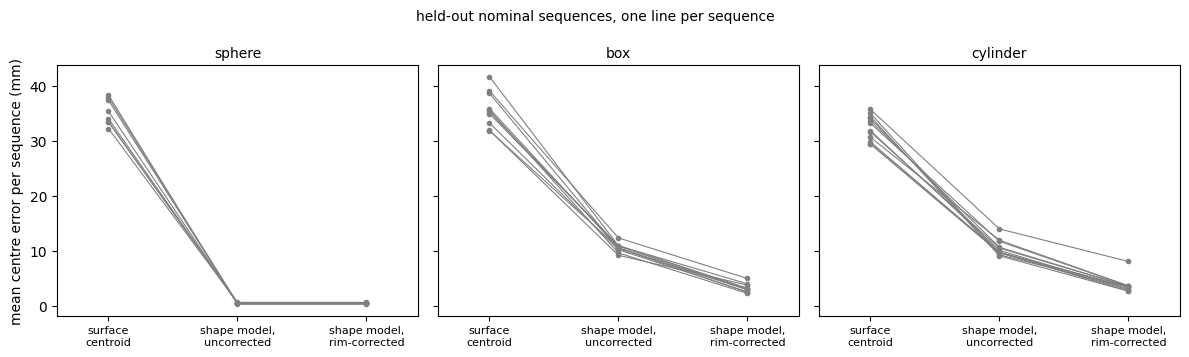

In [ ]:
per_sequence = geometry.groupby(['scenario', 'sequence'], sort=False)[['centroid_error', 'uncorrected_error', 'model_error']].mean() * 1000
for scenario in SCENARIOS:
    picked = per_sequence.loc[scenario]
    for before, label in [('centroid_error', 'surface centroid'), ('uncorrected_error', 'top-face mean')]:
        gain = picked[before] - picked.model_error
        mean, low, high = bootstrap_mean_ci(gain, boot_rng)
        p = paired_wilcoxon(picked[before], picked.model_error)
        print(f'{scenario}: {label} {picked[before].mean():.1f} mm -> corrected centre {picked.model_error.mean():.1f} mm, '
              f'reduction {mean:.1f} mm [{low:.1f}, {high:.1f}], wilcoxon p = {p:.5f}')

unoccluded = geometry[geometry.scenario == 'nominal']
print()
print('size and yaw errors in the nominal scenario (estimate minus truth, mm)')
print((unoccluded.groupby('kind')[['height_error', 'length_error', 'width_error']].agg(['mean', 'std']) * 1000).round(1))
yaw = unoccluded.yaw_error_deg.dropna()
print(f'yaw error of elongated boxes: median {yaw.median():.1f} deg, 90th percentile {yaw.quantile(0.9):.1f} deg, {len(yaw)} detections')

estimates = ['centroid_error', 'uncorrected_error', 'model_error']
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
by_kind = geometry[geometry.scenario == 'nominal'].groupby(['kind', 'sequence'])[estimates].mean() * 1000
for ax, kind in zip(axes, ['sphere', 'box', 'cylinder']):
    if kind in by_kind.index.get_level_values(0):
        for _, row in by_kind.loc[kind].iterrows():
            ax.plot([0, 1, 2], row[estimates].values, color='gray', lw=0.8, marker='o', ms=3)
    ax.set_xticks([0, 1, 2])
    ax.set_xticklabels(['surface\ncentroid', 'shape model,\nuncorrected', 'shape model,\nrim-corrected'], fontsize=8)
    ax.set_xlim(-0.4, 2.4)
    ax.set_title(kind, fontsize=10)
axes[0].set_ylabel('mean centre error per sequence (mm)')
fig.suptitle('held-out nominal sequences, one line per sequence', fontsize=10)
plt.tight_layout()
plt.show()

In [ ]:
usual = geometry.groupby(['scenario', 'sequence', 'object']).area.transform('median')
geometry['visible_share'] = geometry.area / usual
hidden_part = geometry[geometry.scenario == 'occlusion'].copy()
hidden_part['visible'] = pd.cut(hidden_part.visible_share, [0, 0.4, 0.6, 0.8, 1.25, np.inf],
                                labels=['under 40%', '40-60%', '60-80%', '80-125%', 'over 125% (merged)'])
visibility_table = hidden_part.groupby(['visible', 'kind'], observed=True).agg(
    detections=('model_error', 'size'),
    centroid_mean_mm=('centroid_error', lambda e: 1000 * e.mean()),
    uncorrected_mean_mm=('uncorrected_error', lambda e: 1000 * e.mean()),
    model_mean_mm=('model_error', lambda e: 1000 * e.mean()),
    model_p95_mm=('model_error', lambda e: 1000 * e.quantile(0.95)),
    called_sphere=('called_sphere', 'mean'))
visibility_table.round(2)

detections  centroid_mean_mm  uncorrected_mean_mm  model_mean_mm  model_p95_mm  called_sphere
visible            kind                                                                                                   
under 40%          box              131             51.02                26.98          25.48         47.09           0.05
                   cylinder          70             48.10                19.80          16.59         29.57           0.07
                   sphere            50             39.85                 2.31           2.31          4.52           1.00
40-60%             box               99             45.39                16.54          14.02         28.57           0.00
                   cylinder          97             45.24                13.63           7.80         16.41           0.00
                   sphere            40             36.05                 1.04           1.04          2.08           1.00
60-80%             box              116             40.64                12.49           8.39         17.08           0.00
                   cylinder          81             36.70                11.91           5.76         10.99           0.00
                   sphere            51             32.94                 1.03           1.03          2.56           1.00
80-125%            box             2860             35.59                 9.98           3.15          7.63           0.00
                   cylinder        2395             31.45                 9.80           2.90          6.72           0.00
                   sphere          1971             32.34                 0.72           0.72          1.85           1.00
over 125% (merged) box                1             51.43                 2.18          12.21         12.21           0.00

In [ ]:
rows = []
for k in range(N_SEQUENCES):
    for level, name in {0: 'depth_noise_0', 1: 'default', 2: 'depth_noise_2', 4: 'depth_noise_4', 6: 'depth_noise_6'}.items():
        seen = [record['detections'][0]['noise_std'] for record in perception_cache[('nominal', k)][name] if record['detections']]
        rows.append({'depth_noise_multiplier': level, 'plane_noise_estimate_mm': 1000 * np.mean(seen)})
print(pd.DataFrame(rows).groupby('depth_noise_multiplier').mean().round(2))


def static_scatter(seq, frame_records, key):
    samples = {}
    for t, record in enumerate(frame_records):
        for det in record['detections']:
            if det['gt_id'] >= 0 and seq['objects'][det['gt_id']]['is_static']:
                samples.setdefault(det['gt_id'], []).append(seq['reported_rot'][t] @ det[key] + seq['reported_pos'][t])
    per_object = [np.sqrt(np.array(v).var(axis=0).mean()) for v in samples.values() if len(v) >= 50]
    return np.median(per_object) if per_object else np.nan


scatter = [static_scatter(sequences[('nominal', k)], perception_cache[('nominal', k)]['depth_only'], 'centroid_cam')
           for k in range(N_SEQUENCES)]
static_measurement_std = float(np.nanmedian(scatter))
print()
print(f'per-axis scatter of the centroid measurement on static objects: {1000 * static_measurement_std:.2f} mm, '
      f'the filter assumes {1000 * METRIC_MEAS_STD:.0f} mm')

                        plane_noise_estimate_mm
depth_noise_multiplier                         
0                                          0.35
1                                          1.49
2                                          2.92
4                                          5.73
6                                          8.45

per-axis scatter of the centroid measurement on static objects: 0.87 mm, the filter assumes 5 mm


In [ ]:
def fit_descriptor_model(describe):
    within, between, deviations, object_means = [], [], [], {}
    for (scenario, k), seq in sequences.items():
        by_object = {}
        for record in perception_cache[(scenario, k)]['depth_only']:
            for det in record['detections']:
                if det['gt_id'] >= 0:
                    by_object.setdefault(det['gt_id'], []).append(describe(det))
        for gt_id, values in by_object.items():
            values = np.array(values)
            object_means[(scenario, k, gt_id)] = values.mean(axis=0)
            deviations.append(values - values.mean(axis=0))
    scale = np.concatenate(deviations).std(axis=0)
    within = np.concatenate([np.linalg.norm(deviation / scale, axis=1) for deviation in deviations])
    for (scenario, k, gt_id), mean in object_means.items():
        others = [m for (s, kk, g), m in object_means.items() if (s, kk) == (scenario, k) and g > gt_id]
        between += [np.linalg.norm((mean - other) / scale) for other in others]
    model = {'scale': scale, 'threshold': np.percentile(within, 99)}
    return model, np.mean(np.array(between) < model['threshold'])


descriptor_models = {}
for name, descriptor in DESCRIPTORS.items():
    descriptor_models[name], overlap = fit_descriptor_model(descriptor['describe'])
    print(f"{name}: scale {descriptor_models[name]['scale'].round(4)}, 99% of same-object frames within "
          f"{descriptor_models[name]['threshold']:.2f} scaled units, {100 * overlap:.1f}% of different-object pairs in a scene closer than that")
reid_model = descriptor_models['colour and height']
reid_scale = reid_model['scale']

colour and height: scale [0.0035 0.0032 0.0009], 99% of same-object frames within 2.04 scaled units, 0.0% of different-object pairs in a scene closer than that
size: scale [0.0009 0.0043 0.0056], 99% of same-object frames within 4.83 scaled units, 5.1% of different-object pairs in a scene closer than that
size and colour: scale [0.0035 0.0032 0.0009 0.0043 0.0056], 99% of same-object frames within 6.06 scaled units, 0.0% of different-object pairs in a scene closer than that


In [ ]:
dev_geometry = pd.DataFrame([row for (scenario, k), seq in sequences.items() if scenario != 'camera_motion'
                             for row in geometry_rows(seq, perception_cache[(scenario, k)]['depth_only'], scenario, k)])
usual = dev_geometry.groupby(['scenario', 'sequence', 'object']).area.transform('median')
view_names = ['under 40%', '40-70%', 'normal', 'merged']
dev_geometry['view'] = pd.Categorical.from_codes(np.digitize(dev_geometry.area / usual, VISIBILITY_EDGES), view_names)
print(dev_geometry.groupby(['shape', 'view'], observed=True).model_error.agg(
    detections='size', std_per_axis_mm=lambda e: 1000 * np.sqrt((e ** 2).mean() / 3), p95_mm=lambda e: 1000 * e.quantile(0.95)).round(2))


def fitted_std_by_view(shape):
    errors = dev_geometry[dev_geometry['shape'] == shape]
    std = np.sqrt(errors.groupby('view', observed=True).model_error.agg(lambda e: (e ** 2).mean() / 3)).reindex(view_names).values
    return np.where(np.isnan(std), np.nanmax(std), std)


fitted_noise = {'kind': 'table', 'std': {shape: fitted_std_by_view(shape) for shape in ['sphere', 'flat_top']}}


cautious_noise = {'kind': 'table', 'std': {}}
for shape, std in fitted_noise['std'].items():
    cautious_noise['std'][shape] = np.maximum(std, TRUNCATED_STD_SCALE * std[NORMAL_VIEW])
    cautious_noise['std'][shape][NORMAL_VIEW] = std[NORMAL_VIEW]
print()
for shape, std in fitted_noise['std'].items():
    print(f'{shape}: fitted std by view (mm)', (1000 * std).round(2), ' cautious version', (1000 * cautious_noise['std'][shape]).round(2))

axes_xyz = ['ex', 'ey', 'ez']
ordered = dev_geometry.sort_values(['scenario', 'sequence', 'object', 'frame']).reset_index(drop=True)
ordered['normal'] = ordered.view == 'normal'
previous = ordered.groupby(['scenario', 'sequence', 'object'])[['frame', 'normal'] + axes_xyz].shift(1)
paired = (ordered.frame - previous.frame == 1) & (ordered.normal == previous.normal)
dot = (ordered[axes_xyz].values * previous[axes_xyz].values).sum(axis=1)
power = 0.5 * ((ordered[axes_xyz] ** 2).sum(axis=1) + (previous[axes_xyz] ** 2).sum(axis=1))
print()
for is_normal, label in [(True, 'normal views'), (False, 'truncated or merged views')]:
    use = paired & (ordered.normal == is_normal)
    print(f'{label}: frame-to-frame correlation of the centre error {dot[use].sum() / power[use].sum():.2f} over {use.sum()} frame pairs')

                    detections  std_per_axis_mm  p95_mm
shape    view                                          
flat_top under 40%         312            10.14   33.92
         40-70%            813             5.19   18.91
         normal          21746             2.47    6.86
         merged             37            32.34   85.34
sphere   under 40%         259             8.47   12.08
         40-70%            593             0.93    3.07
         normal          10078             0.47    1.48

sphere: fitted std by view (mm) [8.47 0.93 0.47 8.47]  cautious version [8.47 4.66 0.47 8.47]
flat_top: fitted std by view (mm) [10.14  5.19  2.47 32.34]  cautious version [24.67 24.67  2.47 32.34]

normal views: frame-to-frame correlation of the centre error 0.39 over 31282 frame pairs
truncated or merged views: frame-to-frame correlation of the centre error 0.72 over 1516 frame pairs


In [ ]:
noisy_dev_sequences, noisy_dev_cache = {}, {}
for scenario in ['nominal', 'occlusion']:
    for k in range(6):
        noisy_dev_sequences[(scenario, k)] = sequences[(scenario, k)]
        noisy_dev_cache[(scenario, k)] = run_perception(sequences[(scenario, k)],
                                                        {'noisy': condition(use_color=False, depth_noise=2.5)})['noisy']
noisy_geometry = pd.DataFrame([row for (scenario, k), seq in noisy_dev_sequences.items()
                               for row in geometry_rows(seq, noisy_dev_cache[(scenario, k)], scenario, k)])
noise_fit = pd.concat([dev_geometry, noisy_geometry], ignore_index=True)
noise_usual = pd.concat([usual, noisy_geometry.groupby(['scenario', 'sequence', 'object']).area.transform('median')], ignore_index=True)
noise_errors = (noise_fit[['ex', 'ey', 'ez']] ** 2).sum(axis=1).values
noise_view = np.digitize(noise_fit.area / noise_usual, VISIBILITY_EDGES)
noise_X = noise_fit[[f'noise_feature_{i}' for i in range(8)]].values


def gaussian_nll(log_std, squared_error):
    return 3 * log_std + 0.5 * squared_error * np.exp(-2 * log_std)


def fit_log_std(X, squared_error):
    def objective(w):
        log_std = X @ w
        weight = 3 - squared_error * np.exp(-2 * log_std)
        return gaussian_nll(log_std, squared_error).mean(), X.T @ weight / len(X)
    start = np.zeros(X.shape[1])
    start[0] = 0.5 * np.log(squared_error.mean() / 3)
    return minimize(objective, start, jac=True, method='L-BFGS-B').x


fixed_std = np.sqrt(noise_errors.mean() / 3)
fixed_noise = {'kind': 'distance', 'weights': [np.log(fixed_std), 0.0]}
distance_weights = fit_log_std(np.column_stack([np.ones(len(noise_X)), np.log(noise_fit.depth)]), noise_errors)
distance_noise = {'kind': 'distance', 'weights': distance_weights.tolist()}
view_onehot = np.eye(4)[noise_view][:, [0, 1, 3]]
quality_weights = fit_log_std(np.column_stack([noise_X, view_onehot]), noise_errors)
quality_noise = {'kind': 'quality', 'weights': quality_weights[:8].tolist(),
                 'view_terms': [quality_weights[8], quality_weights[9], 0.0, quality_weights[10]]}

names = ['bias', 'log range', 'log pixels', 'sphere', 'fit error', 'occluder border', 'unknown border', 'log frame noise']
print(f'fixed: {1000 * fixed_std:.2f} mm per axis for every detection')
print(f'distance: std = {1000 * np.exp(distance_weights[0]):.2f} mm x range^{distance_weights[1]:.2f}')
print('quality model, effect on log std:', {n: round(float(w), 3) for n, w in zip(names, quality_weights)})
print('view terms (under 40%, 40-70%, normal, merged):', np.round(quality_noise['view_terms'], 3))

def predicted_std(model, rows, view):
    if model['kind'] == 'table':
        std = np.array([model['std'][shape][v] for shape, v in zip(rows['shape'], view)])
        if 'reference_noise' in model:
            std = std * np.maximum(1.0, (np.exp(rows['noise_feature_7'].values) - 1e-4) / model['reference_noise'])
        return std
    if model['kind'] == 'distance':
        return np.exp(model['weights'][0] + model['weights'][1] * np.log(rows['depth'].values))
    X = rows[[f'noise_feature_{i}' for i in range(8)]].values
    return np.exp(X @ np.array(model['weights']) + np.asarray(model['view_terms'])[view])


reference_noise = float(np.quantile(np.exp(dev_geometry.noise_feature_7.values) - 1e-4, 0.95))
scaled_noise = dict(cautious_noise, reference_noise=reference_noise)
print(f'table noise of the default sensor, 95th percentile over the development detections: {1000 * reference_noise:.2f} mm')
noise_models = {'fixed': fixed_noise, 'distance': distance_noise, 'shape and view, cautious': cautious_noise, 'quality': quality_noise,
                'shape and view, scaled by frame noise': scaled_noise}
in_sample = {}
for name, model in noise_models.items():
    std = predicted_std(model, noise_fit, noise_view)
    in_sample[name] = {'mean_nll': gaussian_nll(np.log(std), noise_errors).mean(),
                       'inside_95%': (noise_errors / std ** 2 < chi2.ppf(0.95, 3)).mean()}
print()
print('development fit, per detection (in-sample, the held-out check comes later)')
print(pd.DataFrame(in_sample).T.round(3))

fixed: 3.46 mm per axis for every detection
distance: std = 4.46 mm x range^-0.97
quality model, effect on log std: {'bias': 11.87, 'log range': -1.704, 'log pixels': -1.04, 'sphere': 0.443, 'fit error': 2.172, 'occluder border': -0.591, 'unknown border': -0.691, 'log frame noise': 2.325}
view terms (under 40%, 40-70%, normal, merged): [1.104 0.389 0.    1.311]
table noise of the default sensor, 95th percentile over the development detections: 1.53 mm

development fit, per detection (in-sample, the held-out check comes later)
                                       mean_nll  inside_95%
fixed                                   -15.496       0.954
distance                                -15.517       0.951
shape and view, cautious                 11.045       0.877
quality                                 -17.398       0.914
shape and view, scaled by frame noise   -12.507       0.913


In [ ]:
T6 = dict(pose_aware=True, measurement='model_uncorrected')
T8 = dict(T6, body_gate=True, merge_aware=True)
T10 = dict(T8, reid_model=reid_model, measurement='model')
variants = {
    'T0 euclidean, fixed R': dict(association='euclidean', truncation_aware=False),
    'T1 mahalanobis, fixed R': dict(truncation_aware=False),
    'T2 euclidean, truncation-aware': dict(association='euclidean'),
    'T3 mahalanobis, truncation-aware': dict(),
    'T4 = T3 + R from static scatter': dict(measurement_std=static_measurement_std),
    'T5 = T3 + odometry covariance': dict(pose_aware=True),
    'T6 = T5 + model-based centre': T6,
    'T7 = T6 + re-identification': dict(T6, reid_model=reid_model),
    'T8 = T6 + body gate, merge-aware': T8,
    'T9 = T8 + re-identification': dict(T8, reid_model=reid_model),
    'T10 = T9 + rim-corrected centre': T10,
    'T11 = T10 + R fitted per shape and view': dict(T10, noise_model=fitted_noise),
    'T12 = T10 + R fitted per shape, cautious views': dict(T10, noise_model=cautious_noise),
    'T13 = T12 + appearance gate when coasting': dict(T10, noise_model=cautious_noise, appearance_gate=4.0),
    'T14 = T13 + area learning for young tracks': dict(T10, noise_model=cautious_noise, appearance_gate=4.0, area_learning_hits=15),
}
T14 = variants['T14 = T13 + area learning for young tracks']
variants.update({
    'T15 = T14 with one fixed R': dict(T14, noise_model=fixed_noise),
    'T16 = T14 with range-dependent R': dict(T14, noise_model=distance_noise),
    'T17 = T14 with R from detection quality': dict(T14, noise_model=quality_noise),
    'T18 = T14 + appearance in the association cost': dict(T14, shape_cost=1.0),
    'T19 = T17 + appearance in the association cost': dict(T14, noise_model=quality_noise, shape_cost=1.0),
    'T20 = T18 with R scaled by the frame noise': dict(T14, noise_model=scaled_noise, shape_cost=1.0),
})
variants.update({
    'T21 = T14 + size in the association cost': dict(T14, shape_cost=1.0, descriptor='size', reid_model=descriptor_models['size']),
    'T22 = T14 + size and colour in the association cost': dict(T14, shape_cost=1.0, descriptor='size and colour',
                                                               reid_model=descriptor_models['size and colour']),
    'T23 = T22 + identity kept unless the descriptor agrees': dict(T14, shape_cost=1.0, descriptor='size and colour',
                                                                   reid_model=descriptor_models['size and colour'], identity_gate=2.0),
})

def view_coverage(samples):
    inside = samples.nees < chi2.ppf(0.95, 3)
    normal = samples.visible_share.between(TRUNCATED_AREA_RATIO, 1 / TRUNCATED_AREA_RATIO)
    return {'inside_95_normal_view': inside[normal].mean(), 'inside_95_flagged_view': inside[~normal].mean() if (~normal).any() else np.nan}


development_items = [(key, seq, perception_cache[key]['depth_only']) for key, seq in sequences.items()]
development_items += [(('pick', k), seq, pick_dev_cache[k]) for k, seq in pick_dev_sequences.items()]
development_items += [(('noisier sensor', i), noisy_dev_sequences[key], noisy_dev_cache[key]) for i, key in enumerate(noisy_dev_sequences)]
DEV_COLUMNS = SCENARIOS + ['pick', 'noisier sensor']

rows = []
for (scenario, k), seq, frame_records in development_items:
    for name in ['world 3D', 'world 3D truncation-aware']:
        outputs = run_tracker(TRACKERS[name](), seq, frame_records)
        rows.append({'scenario': scenario, 'sequence': k, 'tracker': 'v1 ' + name,
                     **score_tracking(frame_records, outputs), **score_association(frame_records, outputs)})
    for name, settings in variants.items():
        outputs = run_adaptive(AdaptiveTracker(**settings), seq, frame_records)
        samples = pd.DataFrame(estimate_samples(seq, frame_records, outputs))
        rows.append({'scenario': scenario, 'sequence': k, 'tracker': name, 'position_rmse_mm': rmse_mm(samples),
                     **view_coverage(samples),
                     **score_tracking(frame_records, outputs), **score_association(frame_records, outputs)})
development = pd.DataFrame(rows)
development_idf1 = development.pivot_table(index='tracker', columns='scenario', values='idf1', sort=False)[DEV_COLUMNS]
development_idf1['mean'] = development_idf1.mean(axis=1)
development_idf1.round(3)

scenario,nominal,occlusion,camera_motion,crowded,pick,noisier sensor,mean
tracker,,,,,,,
v1 world 3D,0.988,0.692,0.987,0.974,0.800,0.831,0.879
v1 world 3D truncation-aware,0.992,0.878,0.985,0.968,0.898,0.932,0.942
"T0 euclidean, fixed R",0.988,0.692,0.987,0.974,0.800,0.831,0.879
"T1 mahalanobis, fixed R",0.991,0.918,0.972,0.965,0.873,0.956,0.946
"T2 euclidean, truncation-aware",0.992,0.878,0.985,0.968,0.898,0.932,0.942
"T3 mahalanobis, truncation-aware",0.993,0.934,0.967,0.973,0.881,0.971,0.953
T4 = T3 + R from static scatter,0.968,0.910,0.488,0.893,0.863,0.932,0.842
T5 = T3 + odometry covariance,0.993,0.934,0.988,0.973,0.881,0.971,0.957
T6 = T5 + model-based centre,0.993,0.914,0.993,0.974,0.874,0.852,0.933


In [ ]:
development.pivot_table(index='tracker', columns='scenario', values=['hota_matched', 'id_switches', 'position_rmse_mm'], sort=False).round(3)

hota_matched                                                       id_switches                                                       position_rmse_mm            \
scenario                                                nominal occlusion camera_motion crowded   pick noisier sensor     nominal occlusion camera_motion crowded   pick noisier sensor          nominal occlusion   
tracker                                                                                                                                                                                                              
v1 world 3D                                               0.983     0.757         0.983   0.966  0.843          0.862       0.067     5.867         0.067   0.400  4.333          3.417              NaN       NaN   
v1 world 3D truncation-aware                              0.986     0.896         0.981   0.963  0.912          0.937       0.067     2.200         0.133   0.467  2.000          1.250              NaN       NaN   
T0 euclidean, fixed R                                     0.983     0.757         0.983   0.966  0.843          0.862       0.067     5.867         0.067   0.400  4.333          3.417           33.496    34.564   
T1 mahalanobis, fixed R                                   0.984     0.916         0.970   0.956  0.883          0.952       0.067     2.267         0.600   0.800  3.167          1.500           33.497    34.607   
T2 euclidean, truncation-aware                            0.986     0.896         0.981   0.963  0.912          0.937       0.067     2.200         0.133   0.467  2.000          1.250           33.529    34.449   
T3 mahalanobis, truncation-aware                          0.986     0.929         0.966   0.964  0.886          0.962       0.000     1.733         0.867   0.400  2.417          0.667           33.532    34.590   
T4 = T3 + R from static scatter                           0.965     0.916         0.579   0.903  0.872          0.936       1.200     2.867       222.200   4.733  3.917          2.250           33.507    34.628   
T5 = T3 + odometry covariance                             0.986     0.929         0.983   0.964  0.886          0.962       0.000     1.733         0.067   0.400  2.417          0.667           33.532    34.590   
T6 = T5 + model-based centre                              0.986     0.914         0.986   0.964  0.880          0.864       0.000     1.733         0.000   1.933  2.500         37.333            8.499     9.406   
T7 = T6 + re-identification                               0.986     0.914         0.986   0.967  0.880          0.866       0.000     1.733         0.000   1.800  2.500         37.333            8.499     9.406   
T8 = T6 + body gate, merge-aware                          0.986     0.920         0.986   0.965  0.893          0.878       0.000     1.400         0.000   1.867  2.250         33.083            8.499     9.511   
T9 = T8 + re-identification                               0.986     0.920         0.986   0.968  0.893          0.878       0.000     1.400         0.000   1.733  2.250         33.083            8.499     9.511   
T10 = T9 + rim-corrected centre                           0.986     0.913         0.986   0.966  0.893          0.924       0.000     1.667         0.000   2.067  2.250         12.833            3.056     5.635   
T11 = T10 + R fitted per shape and view                   0.986     0.917         0.979   0.961  0.883          0.856       0.000     1.467         0.600   1.733  3.167         28.667            2.671     4.938   
T12 = T10 + R fitted per shape, cautious views            0.986     0.935         0.979   0.964  0.893          0.867       0.000     1.133         0.600   1.867  2.500         27.750            2.722     4.788   
T13 = T12 + appearance gate when coasting                 0.986     0.951         0.979   0.963  0.961          0.873       0.000     0.667         0.600   1.933  0.583         13.000            2.72

In [ ]:
by_variant = development[development.tracker.isin(list(variants))].groupby('tracker', sort=False)
selection = pd.DataFrame({'idf1': by_variant.idf1.mean(), 'position_rmse_mm': by_variant.position_rmse_mm.mean(),
                          'inside_95_normal_view': by_variant.inside_95_normal_view.mean(),
                          'inside_95_flagged_view': by_variant.inside_95_flagged_view.mean()})
selection['calibration_gap'] = 0.5 * ((selection.inside_95_normal_view - 0.95).abs() + (selection.inside_95_flagged_view - 0.95).abs())
selection['mean_rank'] = (selection.idf1.rank(ascending=False) + selection.position_rmse_mm.rank()
                          + selection.calibration_gap.rank()) / 3
print(selection.round(4))
selected = selection.mean_rank.idxmin()
print()
print('best average rank on the development seeds:', selected)

with_reid = 'T9 = T8 + re-identification'
rows = []
for factor in [0.5, 1.0, 2.0]:
    settings = dict(variants[with_reid], reid_model={'scale': reid_scale, 'threshold': factor * reid_model['threshold']})
    for (scenario, k), seq in sequences.items():
        frame_records = perception_cache[(scenario, k)]['depth_only']
        scores = score_tracking(frame_records, run_adaptive(AdaptiveTracker(**settings), seq, frame_records))
        rows.append({'threshold_factor': factor, 'scenario': scenario, 'idf1': scores['idf1'], 'id_switches': scores['id_switches']})
print()
print(pd.DataFrame(rows).pivot_table(index='threshold_factor', columns='scenario', values=['idf1', 'id_switches'])[
    [('idf1', s) for s in SCENARIOS] + [('id_switches', s) for s in SCENARIOS]].round(3))

rows = []
for factor in [1.0, 2.0, 4.0, 8.0]:
    settings = dict(variants['T14 = T13 + area learning for young tracks'], appearance_gate=factor)
    for (scenario, k), seq, frame_records in development_items:
        scores = score_tracking(frame_records, run_adaptive(AdaptiveTracker(**settings), seq, frame_records))
        rows.append({'gate_factor': factor, 'scenario': scenario, 'idf1': scores['idf1'], 'id_switches': scores['id_switches']})
print()
print(pd.DataFrame(rows).pivot_table(index='gate_factor', columns='scenario', values='idf1')[DEV_COLUMNS].round(3))

                                                      idf1  position_rmse_mm  inside_95_normal_view  inside_95_flagged_view  calibration_gap  mean_rank
tracker                                                                                                                                                
T0 euclidean, fixed R                               0.8832           33.4808                 0.0000                  0.0000           0.9500    22.1667
T1 mahalanobis, fixed R                             0.9478           33.5013                 0.0000                  0.0000           0.9500    19.8333
T2 euclidean, truncation-aware                      0.9442           33.4654                 0.0000                  0.5248           0.6876    19.3333
T3 mahalanobis, truncation-aware                    0.9551           33.5399                 0.0000                  0.6224           0.6388    18.6667
T4 = T3 + R from static scatter                     0.8383           33.5727            

In [ ]:
finalist_names = [name for name in variants if int(name.split(' ')[0][1:]) >= 5]
rows = []
for (scenario, k), seq in heldout_sequences.items():
    frame_records = heldout_cache[(scenario, k)]
    for name in ['world 3D', 'world 3D truncation-aware']:
        outputs = run_tracker(TRACKERS[name](), seq, frame_records)
        rows.append({'scenario': scenario, 'sequence': k, 'tracker': 'v1 ' + name,
                     **score_tracking(frame_records, outputs), **score_association(frame_records, outputs)})
    for name in finalist_names:
        outputs = run_adaptive(AdaptiveTracker(**variants[name]), seq, frame_records)
        rows.append({'scenario': scenario, 'sequence': k, 'tracker': name,
                     'position_rmse_mm': rmse_mm(pd.DataFrame(estimate_samples(seq, frame_records, outputs))),
                     **score_tracking(frame_records, outputs), **score_association(frame_records, outputs)})
heldout = pd.DataFrame(rows)
heldout.groupby(['scenario', 'tracker'], sort=False)[['idf1', 'hota_matched', 'ass_a', 'det_a', 'mota', 'id_switches', 'fragments', 'position_rmse_mm']].mean().round(3)

idf1  hota_matched  ass_a  det_a   mota  id_switches  fragments  position_rmse_mm
scenario tracker                                                                                                                               
nominal  v1 world 3D                                         0.991         0.983  0.983  0.983  0.983        0.000      0.417               NaN
         v1 world 3D truncation-aware                        0.991         0.983  0.983  0.983  0.983        0.000      0.417               NaN
         T5 = T3 + odometry covariance                       0.991         0.983  0.983  0.983  0.983        0.000      0.417            34.469
         T6 = T5 + model-based centre                        0.991         0.983  0.983  0.983  0.983        0.000      0.583             9.003
         T7 = T6 + re-identification                         0.991         0.983  0.983  0.983  0.983        0.000      0.583             9.003
...                                                            ...           ...    ...    ...    ...          ...        ...               ...
crowded  T19 = T17 + appearance in the association cost      0.967         0.963  0.956  0.970  0.964        4.833      5.083             5.189
         T20 = T18 with R scaled by the frame noise          0.972         0.966  0.961  0.970  0.964        5.083      5.000             5.686
         T21 = T14 + size in the association cost            0.972         0.965  0.960  0.970  0.964        5.583      4.917             6.053
         T22 = T14 + size and colour in the association ...  0.972         0.966  0.961  0.970  0.964        5.083      5.000             5.686
         T23 = T22 + identity kept unless the descriptor...  0.972         0.966  0.961  0.970  0.964        5.083      5.000             5.686

[84 rows x 8 columns]

In [ ]:
with_rim, without_reid = 'T10 = T9 + rim-corrected centre', 'T8 = T6 + body gate, merge-aware'
comparisons = list(dict.fromkeys([(selected, 'v1 world 3D'), (selected, 'v1 world 3D truncation-aware'), (selected, with_reid),
                                  (selected, 'T12 = T10 + R fitted per shape, cautious views'),
                                  ('T14 = T13 + area learning for young tracks', 'T13 = T12 + appearance gate when coasting'),
                                  (with_rim, with_reid), (with_reid, without_reid),
                                  (without_reid, 'T6 = T5 + model-based centre')]))
test_rows = []
for scenario in SCENARIOS:
    for metric in ['idf1', 'id_switches', 'position_rmse_mm']:
        per_seq = heldout[heldout.scenario == scenario].pivot(index='sequence', columns='tracker', values=metric)
        for candidate, baseline in comparisons:
            if candidate == baseline or per_seq[baseline].isna().any():
                continue
            change = per_seq[candidate] - per_seq[baseline]
            mean_change, low, high = bootstrap_mean_ci(change, boot_rng)
            test_rows.append({'scenario': scenario, 'metric': metric, 'candidate': candidate.split(' ')[0] if candidate[0] == 'T' else candidate,
                              'against': baseline.split(' ')[0] if baseline[0] == 'T' else baseline,
                              'baseline_mean': per_seq[baseline].mean(), 'candidate_mean': per_seq[candidate].mean(),
                              'diff': mean_change, 'ci_low': low, 'ci_high': high,
                              'p_wilcoxon': paired_wilcoxon(per_seq[candidate], per_seq[baseline])})
heldout_tests = pd.DataFrame(test_rows)
heldout_tests['p_holm'] = holm_adjust(heldout_tests.p_wilcoxon)
heldout_tests[heldout_tests.metric != 'position_rmse_mm'].round(4)

,scenario,metric,candidate,against,baseline_mean,candidate_mean,diff,ci_low,ci_high,p_wilcoxon,p_holm
0,nominal,idf1,T18,v1 world 3D,0.9913,0.9840,-0.0073,-0.0218,0.0,0.5,1.0
1,nominal,idf1,T18,v1 world 3D truncation-aware,0.9913,0.9840,-0.0073,-0.0219,0.0,0.5,1.0
2,nominal,idf1,T18,T9,0.9910,0.9840,-0.0070,-0.0208,0.0,0.5,1.0
3,nominal,idf1,T18,T12,0.9846,0.9840,-0.0006,-0.0019,0.0,1.0,1.0
4,nominal,idf1,T14,T13,0.9846,0.9846,0.0000,0.0000,0.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
77,crowded,id_switches,T18,T12,5.5000,5.0833,-0.4167,-1.2500,0.0,1.0,1.0
78,crowded,id_switches,T14,T13,5.5000,5.5000,0.0000,0.0000,0.0,NaN,NaN
79,crowded,id_switches,T10,T9,5.5000,5.8333,0.3333,0.0000,1.0,1.0,1.0
80,crowded,id_switches,T9,T8,5.5833,5.5000,-0.0833,-0.2500,0.0,1.0,1.0


In [ ]:
heldout_tests[heldout_tests.metric == 'position_rmse_mm'].round(4)

,scenario,metric,candidate,against,baseline_mean,candidate_mean,diff,ci_low,ci_high,p_wilcoxon,p_holm
16,nominal,position_rmse_mm,T18,T9,9.1215,3.5176,-5.6039,-6.2764,-4.8646,0.0005,0.0356
17,nominal,position_rmse_mm,T18,T12,3.6062,3.5176,-0.0886,-0.2658,0.0000,1.0000,1.0000
18,nominal,position_rmse_mm,T14,T13,3.5212,3.5157,-0.0055,-0.0165,0.0000,1.0000,1.0000
19,nominal,position_rmse_mm,T10,T9,9.1215,3.6763,-5.4452,-6.1908,-4.6439,0.0005,0.0356
20,nominal,position_rmse_mm,T9,T8,9.1215,9.1215,0.0000,0.0000,0.0000,NaN,NaN
21,nominal,position_rmse_mm,T8,T6,9.0028,9.1215,0.1187,0.0000,0.3561,1.0000,1.0000
38,occlusion,position_rmse_mm,T18,T9,9.5310,4.4072,-5.1238,-5.8585,-4.4352,0.0005,0.0356
39,occlusion,position_rmse_mm,T18,T12,4.7382,4.4072,-0.3310,-0.6372,-0.1067,0.0195,1.0000
40,occlusion,position_rmse_mm,T14,T13,4.4458,4.3933,-0.0525,-0.1185,-0.0058,0.1250,1.0000
41,occlusion,position_rmse_mm,T10,T9,9.5310,5.0109,-4.5200,-5.2692,-3.7708,0.0005,0.0356


In [ ]:
DESCRIPTOR_TRACKERS = {'motion, colour gate when coasting': 'T14 = T13 + area learning for young tracks',
                       'motion + colour and height': 'T18 = T14 + appearance in the association cost',
                       'motion + size': 'T21 = T14 + size in the association cost',
                       'motion + size and colour': 'T22 = T14 + size and colour in the association cost',
                       'motion + size and colour, identity gate': 'T23 = T22 + identity kept unless the descriptor agrees'}
per_sequence = heldout[heldout.tracker.isin(DESCRIPTOR_TRACKERS.values())].copy()
per_sequence['descriptor'] = per_sequence.tracker.map({tracker: name for name, tracker in DESCRIPTOR_TRACKERS.items()})
descriptor_metrics = ['idf1', 'id_switches', 'fragments', 'position_rmse_mm']
descriptor_table = per_sequence.groupby('descriptor', sort=False)[descriptor_metrics].mean()
descriptor_table = descriptor_table.loc[list(DESCRIPTOR_TRACKERS)]
rows = []
reference = per_sequence[per_sequence.descriptor == 'motion, colour gate when coasting'].set_index(['scenario', 'sequence'])
for name in list(DESCRIPTOR_TRACKERS)[1:]:
    other = per_sequence[per_sequence.descriptor == name].set_index(['scenario', 'sequence'])
    for metric in descriptor_metrics:
        change = other[metric] - reference[metric]
        mean, low, high = bootstrap_mean_ci(change, boot_rng)
        rows.append({'descriptor': name, 'metric': metric, 'diff': mean, 'ci_low': low, 'ci_high': high,
                     'p_wilcoxon': paired_wilcoxon(other[metric], reference[metric])})
descriptor_tests = pd.DataFrame(rows)
descriptor_tests['p_holm'] = holm_adjust(descriptor_tests.p_wilcoxon)
print(f'{len(reference)} held-out sequences, mean per sequence')
print(descriptor_table.round(3).to_string())
print()
print('against motion with the colour gate only, paired by sequence')
print(descriptor_tests.round(4).to_string(index=False))
print()
print('the tracker carried forward was chosen on the development seeds:', selected)

48 held-out sequences, mean per sequence
                                          idf1  id_switches  fragments  position_rmse_mm
descriptor                                                                              
motion, colour gate when coasting        0.978        1.688      3.354             5.204
motion + colour and height               0.981        1.500      3.312             5.115
motion + size                            0.977        1.792      3.188             5.245
motion + size and colour                 0.979        1.646      3.208             5.153
motion + size and colour, identity gate  0.979        1.688      3.208             5.154

against motion with the colour gate only, paired by sequence
                             descriptor           metric    diff  ci_low  ci_high  p_wilcoxon  p_holm
             motion + colour and height             idf1  0.0030  0.0001   0.0072      0.0630  0.9447
             motion + colour and height      id_switches -0.1875 -0.43

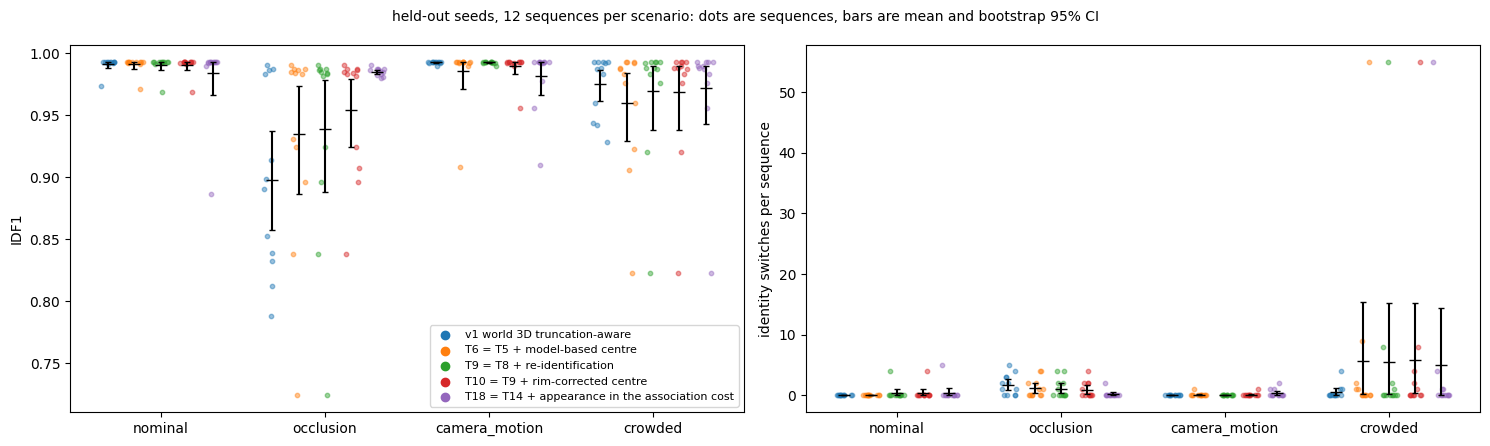

In [ ]:
plotted = list(dict.fromkeys(['v1 world 3D truncation-aware', 'T6 = T5 + model-based centre', with_reid, with_rim, selected]))
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, metric in zip(axes, ['idf1', 'id_switches']):
    for i, name in enumerate(plotted):
        for j, scenario in enumerate(SCENARIOS):
            picked = heldout[(heldout.scenario == scenario) & (heldout.tracker == name)][metric].values
            x = j + (i - (len(plotted) - 1) / 2) * 0.16
            ax.scatter(x + jitter_rng.uniform(-0.05, 0.05, len(picked)), picked, s=10, alpha=0.45, color=f'C{i}')
            mean, low, high = bootstrap_mean_ci(picked, boot_rng)
            ax.errorbar(x, mean, yerr=[[mean - low], [high - mean]], fmt='_', color='k', capsize=2, ms=9)
        ax.scatter([], [], color=f'C{i}', label=name)
    ax.set_xticks(range(len(SCENARIOS)))
    ax.set_xticklabels(SCENARIOS)
    ax.set_ylabel('IDF1' if metric == 'idf1' else 'identity switches per sequence')
axes[0].legend(fontsize=8, loc='lower right')
fig.suptitle(f'held-out seeds, {N_HELDOUT} sequences per scenario: dots are sequences, bars are mean and bootstrap 95% CI', fontsize=10)
plt.tight_layout()
plt.show()

In [ ]:
consistency_variants = list(dict.fromkeys(['T5 = T3 + odometry covariance', with_reid, with_rim,
                                           'T11 = T10 + R fitted per shape and view', selected]))
rows = []
for scenario in ['nominal', 'occlusion', 'camera_motion']:
    for name in consistency_variants:
        for k in range(N_HELDOUT):
            seq, frame_records = heldout_sequences[(scenario, k)], heldout_cache[(scenario, k)]
            outputs = run_adaptive(AdaptiveTracker(**variants[name]), seq, frame_records)
            rows += [{'scenario': scenario, 'tracker': name, **row} for row in estimate_samples(seq, frame_records, outputs)]
consistency = pd.DataFrame(rows)

def consistency_summary(samples):
    return pd.Series({'updates': len(samples), 'position_rmse_mm': rmse_mm(samples),
                      'bias_mm': 1000 * np.linalg.norm(samples[['ex', 'ey', 'ez']].mean().values),
                      'mean_nis': samples.nis.mean(), 'nis_under_7.81': (samples.nis < 7.81).mean(),
                      'mean_nees': samples.nees.mean(), 'nees_under_7.81': (samples.nees < 7.81).mean()})

pd.DataFrame({key: consistency_summary(group) for key, group in consistency.groupby(['scenario', 'tracker'], sort=False)}).T.round(3)

updates  position_rmse_mm  bias_mm  mean_nis  nis_under_7.81  mean_nees  nees_under_7.81
nominal       T5 = T3 + odometry covariance                    8841.0            34.492   33.435     0.112           1.000     63.362            0.005
              T9 = T8 + re-identification                      8840.0             9.481    7.331     0.111           1.000      4.496            0.897
              T10 = T9 + rim-corrected centre                  8840.0             4.545    0.914     0.225           1.000      0.840            0.984
              T11 = T10 + R fitted per shape and view          8833.0             4.305    0.891     0.670           0.998      5.464            0.949
              T18 = T14 + appearance in the association cost   8825.0             4.097    0.901     0.672           0.998      3.266            0.951
occlusion     T5 = T3 + odometry covariance                    7833.0            34.622   32.491     0.172           1.000     56.857            0.055
              T9 = T8 + re-identification                      7833.0             9.651    7.216     0.139           1.000      3.672            0.923
              T10 = T9 + rim-corrected centre                  7833.0             5.214    0.801     0.250           1.000      0.461            0.999
              T11 = T10 + R fitted per shape and view          7817.0             5.593    0.807     0.784           0.996      3.366            0.910
              T18 = T14 + appearance in the association cost   7828.0             4.520    0.830     0.730           0.997      2.782            0.929
camera_motion T5 = T3 + odometry covariance                    8863.0            33.901   32.244     0.916           1.000     50.903            0.015
              T9 = T8 + re-identification                      8862.0            10.590    7.016     0.915           1.000      4.142            0.880
              T10 = T9 + rim-corrected centre                  8860.0             6.796    0.897     1.013           1.000      1.294            0.999
              T11 = T10 + R fitted per shape and view          8855.0             6.846    0.873     1.844           0.994      2.730            0.957
              T18 = T14 + appearance in the association cost   8855.0             6.866    0.889     1.826           0.994      2.707            0.958

                        updates  mean_nis  nis_under_7.81  mean_nees  nees_under_7.81
nominal       cylinder   3527.0     0.982           0.996      5.684            0.910
              box        2782.0     0.747           0.999      1.935            0.970
              sphere     2516.0     0.155           0.999      1.348            0.986
occlusion     box        3150.0     0.821           0.997      2.610            0.918
              cylinder   2598.0     0.865           0.997      1.886            0.960
              sphere     2080.0     0.423           0.996      4.160            0.907
camera_motion cylinder   4136.0     1.783           0.994      2.729            0.952
              box        2064.0     1.828           0.996      2.586            0.963
              sphere     2655.0     1.893           0.991      2.768            0.962

                     updates  mean_nis  nis_under_7.81  mean_nees  nees_under_7.81
nominal       False   6329.0     0.665           0.998  

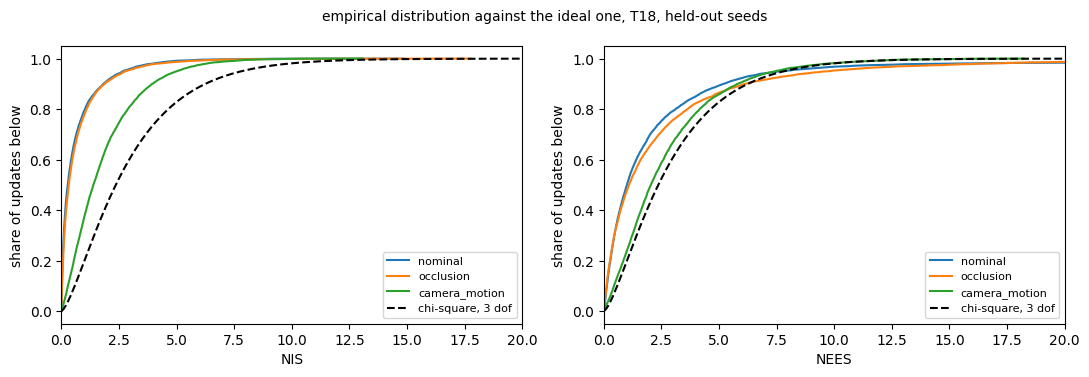

In [ ]:
chosen = consistency[consistency.tracker == selected].copy()
chosen['track_age'] = np.where(chosen.track_hits <= 10, 'first 10 updates', 'established')
for column in ['kind', 'moving', 'track_age']:
    print(pd.DataFrame({key: consistency_summary(group) for key, group in chosen.groupby(['scenario', column], sort=False)}).T[
        ['updates', 'mean_nis', 'nis_under_7.81', 'mean_nees', 'nees_under_7.81']].round(3))
    print()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
grid = np.linspace(0, 20, 200)
for ax, column in zip(axes, ['nis', 'nees']):
    for scenario in ['nominal', 'occlusion', 'camera_motion']:
        values = np.sort(chosen[chosen.scenario == scenario][column].values)
        ax.plot(values, np.arange(1, len(values) + 1) / len(values), label=scenario)
    ax.plot(grid, chi2.cdf(grid, df=3), 'k--', label='chi-square, 3 dof')
    ax.set_xlim(0, 20)
    ax.set_xlabel(column.upper())
    ax.set_ylabel('share of updates below')
    ax.legend(fontsize=8)
fig.suptitle(f'empirical distribution against the ideal one, {selected.split(" ")[0]}, held-out seeds', fontsize=10)
plt.tight_layout()
plt.show()

In [ ]:
chosen['error_mm'] = 1000 * np.sqrt(chosen.ex ** 2 + chosen.ey ** 2 + chosen.ez ** 2)
normal_view = chosen.visible_share.between(TRUNCATED_AREA_RATIO, 1 / TRUNCATED_AREA_RATIO)
chosen['view'] = np.where(normal_view, 'normal', 'flagged')
print(chosen.groupby(['scenario', 'view'], sort=False).error_mm.agg(
    updates='size', mean_mm='mean', p95_mm=lambda e: e.quantile(0.95), worst_mm='max').round(2))
far_off = chosen.error_mm > 20
print()
print(f'{100 * (~normal_view).mean():.1f}% of all estimates are flagged, they hold {100 * (~normal_view[far_off]).mean():.0f}% '
      f'of the {far_off.sum()} estimates that are more than 20 mm off')

                       updates  mean_mm  p95_mm  worst_mm
scenario      view                                       
nominal       normal      8740     2.41    6.15     29.94
              flagged       85     9.32   32.01     39.13
occlusion     normal      7259     2.28    6.34     20.40
              flagged      569     9.39   27.64     44.79
camera_motion normal      8555     6.12   11.34     18.94
              flagged      300     8.48   18.36     26.25

3.7% of all estimates are flagged, they hold 45% of the 220 estimates that are more than 20 mm off


In [ ]:
rows = []
for accel_std in [1.0, 0.5, 0.25, 0.1]:
    for (scenario, k), seq in sequences.items():
        frame_records = perception_cache[(scenario, k)]['depth_only']
        outputs = run_adaptive(AdaptiveTracker(accel_std=accel_std, **variants[selected]), seq, frame_records)
        samples = pd.DataFrame(estimate_samples(seq, frame_records, outputs))
        rows.append({'accel_std': accel_std, 'scenario': scenario, 'idf1': score_tracking(frame_records, outputs)['idf1'],
                     'mean_nis': samples.nis.mean(), 'nis_under_7.81': (samples.nis < 7.81).mean(),
                     'nees_under_7.81': (samples.nees < 7.81).mean()})
process_noise = pd.DataFrame(rows)
process_noise.pivot_table(index='accel_std', columns='scenario', values=['idf1', 'mean_nis', 'nees_under_7.81'])[
    [(m, s) for m in ['idf1', 'mean_nis', 'nees_under_7.81'] for s in SCENARIOS]].round(3)

idf1                                 mean_nis                                 nees_under_7.81                                
scenario  nominal occlusion camera_motion crowded  nominal occlusion camera_motion crowded         nominal occlusion camera_motion crowded
accel_std                                                                                                                                 
0.10        0.954     0.891         0.888   0.869    4.648     4.220         3.835   7.117           0.849     0.825         0.852   0.786
0.25        0.978     0.954         0.934   0.946    1.863     1.857         2.622   2.385           0.927     0.903         0.942   0.901
0.50        0.980     0.972         0.969   0.972    1.073     1.107         2.111   1.233           0.949     0.922         0.965   0.937
1.00        0.993     0.980         0.984   0.977    0.676     0.676         1.717   0.706           0.954     0.926         0.967   0.945

In [ ]:
def blackout(frame_records, gt_ids, start, length):
    hidden = []
    for t, record in enumerate(frame_records):
        if start <= t < start + length:
            record = {'detections': [det for det in record['detections'] if det['gt_id'] not in gt_ids],
                      'visible_gt': record['visible_gt'] - gt_ids}
        hidden.append(record)
    return hidden


def identity_recovered(frame_records, track_outputs, gt_id, start, length, window=15):
    def track_on_object(t):
        for entry in track_outputs[t]:
            if frame_records[t]['detections'][entry[1]]['gt_id'] == gt_id:
                return entry[0]
        return None
    before = [track_on_object(t) for t in range(max(0, start - 10), start)]
    after = [track_on_object(t) for t in range(start + length, min(len(track_outputs), start + length + window))]
    before = [b for b in before if b is not None]
    after = [a for a in after if a is not None]
    if not before or not after:
        return np.nan      
    return float(after[0] == before[-1])


blackout_start = 60
blackout_trackers = list(dict.fromkeys(['T2 euclidean, truncation-aware', 'T8 = T6 + body gate, merge-aware',
                                        'T7 = T6 + re-identification', 'T9 = T8 + re-identification', selected]))
rows = []
for scenario in ['nominal', 'crowded']:
    for k in range(N_HELDOUT):
        seq, frame_records = heldout_sequences[(scenario, k)], heldout_cache[(scenario, k)]
        for gt_id in [0, 2]:      # object 0 moves, object 2 stands still in the nominal scenes
            for length in [5, 10, 20, 40]:
                hidden = blackout(frame_records, {gt_id}, blackout_start, length)
                for name in blackout_trackers:
                    outputs = run_adaptive(AdaptiveTracker(**variants[name]), seq, hidden)
                    rows.append({'scenario': scenario, 'hidden_frames': length, 'tracker': name, 'sequence': k, 'object': gt_id,
                                 'recovered': identity_recovered(hidden, outputs, gt_id, blackout_start, length)})
blackout_results = pd.DataFrame(rows)
usable = blackout_results.groupby(['scenario', 'hidden_frames', 'tracker']).recovered.count()
print('trials with a usable outcome per cell:', int(usable.min()), 'to', int(usable.max()))
blackout_results.pivot_table(index=['scenario', 'tracker'], columns='hidden_frames', values='recovered', sort=False).round(3)

trials with a usable outcome per cell: 24 to 24


hidden_frames                                               5      10     20     40
scenario tracker                                                                   
nominal  T2 euclidean, truncation-aware                  0.958  0.875  0.667  0.000
         T8 = T6 + body gate, merge-aware                1.000  1.000  0.958  0.000
         T7 = T6 + re-identification                     1.000  1.000  1.000  1.000
         T9 = T8 + re-identification                     1.000  1.000  1.000  1.000
         T18 = T14 + appearance in the association cost  1.000  1.000  1.000  1.000
crowded  T2 euclidean, truncation-aware                  0.958  0.792  0.250  0.000
         T8 = T6 + body gate, merge-aware                1.000  0.958  0.958  0.000
         T7 = T6 + re-identification                     1.000  0.958  1.000  0.750
         T9 = T8 + re-identification                     1.000  0.958  0.958  0.833
         T18 = T14 + appearance in the association cost  1.000  1.000  1.000  0.958

In [ ]:
drop_rng = np.random.default_rng(77)
rows = []
for drop_rate in [0.0, 0.1, 0.2, 0.3]:
    for (scenario, k), seq in heldout_sequences.items():
        frame_records = heldout_cache[(scenario, k)]
        kept = np.flatnonzero(drop_rng.random(N_FRAMES) >= drop_rate)
        kept_records = [frame_records[t] for t in kept]
        for name, fixed_dt in [('assumes nominal period', DT), ('uses frame timestamps', None)]:
            outputs = run_adaptive(AdaptiveTracker(fixed_dt=fixed_dt, **variants[selected]), seq, frame_records, frame_ids=kept)
            samples = pd.DataFrame(estimate_samples(seq, frame_records, outputs, frame_ids=kept))
            scores = score_tracking(kept_records, outputs)
            rows.append({'drop_rate': drop_rate, 'filter': name, 'scenario': scenario, 'sequence': k, 'idf1': scores['idf1'],
                         'id_switches': scores['id_switches'], 'position_rmse_mm': rmse_mm(samples)})
drop_results = pd.DataFrame(rows)
drop_results.pivot_table(index='drop_rate', columns='filter', values=['idf1', 'id_switches', 'position_rmse_mm']).round(3)

id_switches                                         idf1                             position_rmse_mm                      
filter    assumes nominal period uses frame timestamps assumes nominal period uses frame timestamps assumes nominal period uses frame timestamps
drop_rate                                                                                                                                       
0.0                        1.500                 1.500                  0.981                 0.981                  5.115                 5.115
0.1                        2.438                 1.458                  0.956                 0.978                  5.223                 5.171
0.2                        4.000                 1.208                  0.913                 0.976                  5.301                 5.294
0.3                        5.938                 0.979                  0.882                 0.973                  5.566                 5.240

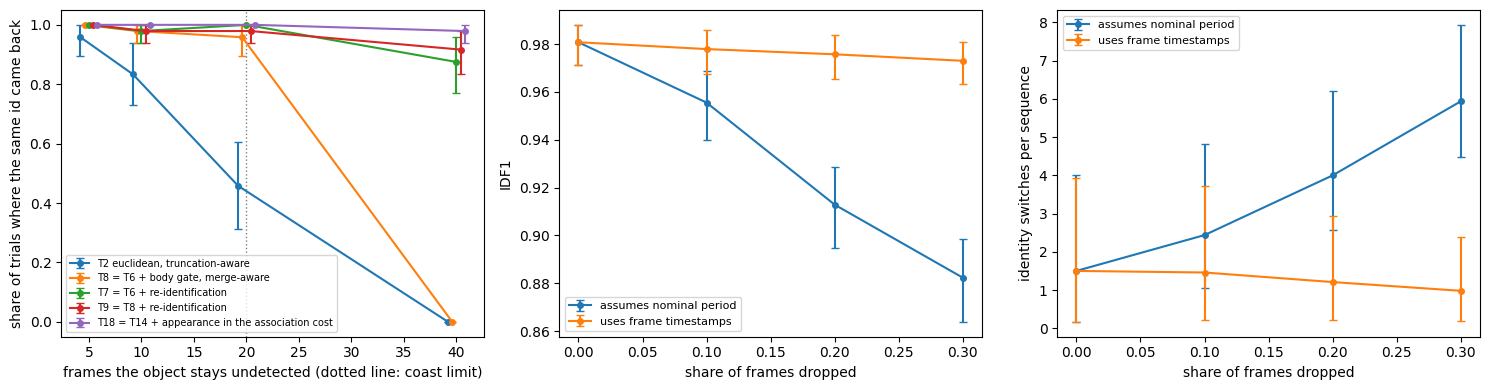

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
lengths = sorted(blackout_results.hidden_frames.unique())
for i, name in enumerate(blackout_trackers):
    ci = np.array([bootstrap_mean_ci(blackout_results[(blackout_results.tracker == name) & (blackout_results.hidden_frames == n)].recovered.dropna(), boot_rng)
                   for n in lengths])
    shift = (i - (len(blackout_trackers) - 1) / 2) * 0.4
    axes[0].errorbar(np.array(lengths) + shift, ci[:, 0], yerr=[ci[:, 0] - ci[:, 1], ci[:, 2] - ci[:, 0]], marker='o', ms=4, capsize=3, label=name)
axes[0].axvline(20, color='gray', ls=':', lw=1)
axes[0].set_xlabel('frames the object stays undetected (dotted line: coast limit)')
axes[0].set_ylabel('share of trials where the same id came back')
axes[0].legend(fontsize=7)
rates = sorted(drop_results.drop_rate.unique())
for ax, metric in zip(axes[1:], ['idf1', 'id_switches']):
    for name in drop_results['filter'].unique():
        ci = np.array([bootstrap_mean_ci(drop_results[(drop_results['filter'] == name) & (drop_results.drop_rate == r)][metric], boot_rng) for r in rates])
        ax.errorbar(rates, ci[:, 0], yerr=[ci[:, 0] - ci[:, 1], ci[:, 2] - ci[:, 0]], marker='o', ms=4, capsize=3, label=name)
    ax.set_xlabel('share of frames dropped')
    ax.set_ylabel('IDF1' if metric == 'idf1' else 'identity switches per sequence')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [ ]:
lookalike_conditions = {'normal light': condition(use_color=False), 'half light': condition(brightness=0.5, use_color=False)}
lookalike_sequences, lookalike_cache = {}, {}
for k in range(N_HELDOUT):
    lookalike_sequences[k] = build_sequence('lookalike', seed=9000 + k)
    lookalike_cache[k] = run_perception(lookalike_sequences[k], lookalike_conditions)

rows = []
for k in range(N_HELDOUT):
    for light in lookalike_conditions:
        seen = {}
        for record in lookalike_cache[k][light]:
            for det in record['detections']:
                if det['gt_id'] >= 0:
                    seen.setdefault(det['gt_id'], []).append(appearance(det))
        mean_look = {gt_id: np.mean(values, axis=0) for gt_id, values in seen.items()}
        for a in mean_look:
            for b in mean_look:
                if a < b:
                    gap = np.linalg.norm((mean_look[a] - mean_look[b]) / reid_scale)
                    rows.append({'light': light, 'pair': 'twins' if (a % 2 == 0 and b == a + 1) else 'different objects',
                                 'descriptor_gap': gap, 'inside_threshold': gap < reid_model['threshold']})
lookalike_pairs = pd.DataFrame(rows)
lookalike_pairs.groupby(['light', 'pair'], sort=False).agg(pairs=('inside_threshold', 'size'), median_gap=('descriptor_gap', 'median'),
                                                           inside_threshold=('inside_threshold', 'mean')).round(3)

pairs  median_gap  inside_threshold
light        pair                                                  
normal light twins                 36       0.244               1.0
             different objects    144     102.998               0.0
half light   twins                 36       0.224               1.0
             different objects    144     102.971               0.0

In [ ]:
def identity_after_blackout(frame_records, track_outputs, gt_id, start, length, window=15):
    def track_on(t, wanted):
        for entry in track_outputs[t]:
            if frame_records[t]['detections'][entry[1]]['gt_id'] == wanted:
                return entry[0]
        return None
    before = [track_on(t, gt_id) for t in range(max(0, start - 10), start)]
    before = [b for b in before if b is not None]
    if not before:
        return 'not tracked'
    used_elsewhere = set()
    for t in range(min(len(track_outputs), start + length + window)):
        if t >= start + length and track_on(t, gt_id) is not None:
            if track_on(t, gt_id) == before[-1]:
                return 'same id'
            return "another object's id" if track_on(t, gt_id) in used_elsewhere else 'new id'
        used_elsewhere |= {entry[0] for entry in track_outputs[t] if frame_records[t]['detections'][entry[1]]['gt_id'] != gt_id}
    return 'not tracked'


final_settings = dict(variants[selected], reid_model=reid_model)
reid_trackers = {'no re-identification': dict(final_settings, reid_model=None),
                 're-id, rivals: every look-alike': dict(final_settings, rival_scope='all'),
                 're-id, rivals: reachable only': final_settings}
rows = []
for k, seq in lookalike_sequences.items():
    for light in lookalike_conditions:
        frame_records = lookalike_cache[k][light]
        for name, settings in reid_trackers.items():
            scores = score_tracking(frame_records, run_adaptive(AdaptiveTracker(**settings), seq, frame_records))
            rows.append({'light': light, 'tracker': name, 'trial': 'nothing hidden', 'idf1': scores['idf1'],
                         'id_switches': scores['id_switches']})
            for first in [0, 4]:
                for trial, hidden_ids in [('one twin hidden', {first}), ('both twins hidden', {first, first + 1})]:
                    hidden = blackout(frame_records, hidden_ids, blackout_start, 40)
                    outputs = run_adaptive(AdaptiveTracker(**settings), seq, hidden)
                    for gt_id in hidden_ids:
                        rows.append({'light': light, 'tracker': name, 'trial': trial,
                                     'outcome': identity_after_blackout(hidden, outputs, gt_id, blackout_start, 40)})
lookalike_results = pd.DataFrame(rows)
print(lookalike_results[lookalike_results.trial == 'nothing hidden'].groupby(['light', 'tracker'], sort=False)[['idf1', 'id_switches']].mean().round(3))
print()
trials = lookalike_results[lookalike_results.trial != 'nothing hidden']
outcome_counts = trials.groupby(['light', 'trial', 'tracker', 'outcome'], sort=False).size().unstack(fill_value=0)
outcome_counts

                                               idf1  id_switches
light        tracker                                            
normal light no re-identification             0.988        0.083
             re-id, rivals: every look-alike  0.991        0.000
             re-id, rivals: reachable only    0.991        0.000
half light   no re-identification             0.986        0.167
             re-id, rivals: every look-alike  0.989        0.083
             re-id, rivals: reachable only    0.989        0.083



outcome                                                         new id  same id  another object's id
light        trial             tracker                                                              
normal light one twin hidden   no re-identification                 24        0                    0
                               re-id, rivals: every look-alike       0       24                    0
                               re-id, rivals: reachable only         0       24                    0
             both twins hidden no re-identification                 48        0                    0
                               re-id, rivals: every look-alike      31       12                    5
                               re-id, rivals: reachable only        31       12                    5
half light   one twin hidden   no re-identification                 23        0                    1
                               re-id, rivals: every look-alike       0       24                    0
                               re-id, rivals: reachable only         0       24                    0
             both twins hidden no re-identification                 47        0                    1
                               re-id, rivals: every look-alike      33       12                    3
                               re-id, rivals: reachable only        33       12                    3

In [ ]:
def table_frame(plane, cam_rot, cam_pos):
    normal = cam_rot @ plane[0]
    point = cam_rot @ (-plane[1] * plane[0]) + cam_pos
    e1 = np.array([1.0, 0.0, 0.0]) - normal[0] * normal
    if np.linalg.norm(e1) < 0.1:
        e1 = np.array([0.0, 1.0, 0.0]) - normal[1] * normal
    e1 = e1 / np.linalg.norm(e1)
    return {'normal': normal, 'point': point, 'basis': np.column_stack([e1, np.cross(normal, e1), normal])}


class TrackShape:
    def __init__(self, gain=0.3):
        self.gain = gain
        self.votes = {}
        self.quarter_turn = None
        self.box_sides = None
        self.round_width = None
        self.height = None
        self.updates = 0
        self.last_seen = None
        self.last_outline = None

    def observe(self, det, long_axis_angle, normal_view, timestamp):
        self.last_seen = timestamp
        self.last_outline = np.array([det['footprint'].max(), det['height']])
        if normal_view:
            self.update(det, long_axis_angle)

    def update(self, det, long_axis_angle):
        g = self.gain if self.updates else 1.0
        if det['category'] != 'unknown':
            for category in self.votes:
                self.votes[category] *= 1 - self.gain
            self.votes[det['category']] = self.votes.get(det['category'], 0.0) + self.gain
        self.height = det['height'] if self.height is None else (1 - g) * self.height + g * det['height']
        if det['category'] == 'box':
            turn = np.exp(4j * long_axis_angle)
            self.quarter_turn = turn if self.quarter_turn is None else (1 - g) * self.quarter_turn + g * turn
            frame_angle = np.angle(self.quarter_turn) / 4
            offset = (long_axis_angle - frame_angle + np.pi / 2) % np.pi - np.pi / 2
            sides = det['top_sides'] if abs(offset) < np.pi / 4 else det['top_sides'][::-1]
            self.box_sides = sides if self.box_sides is None else (1 - g) * self.box_sides + g * sides
        else:
            width = det['top_sides'][0]
            self.round_width = width if self.round_width is None else (1 - g) * self.round_width + g * width
        self.updates += 1

    def category(self):
        return max(self.votes, key=self.votes.get) if self.votes else 'unknown'

    def describe(self, table):
        category = self.category() if self.updates else 'unknown'
        e1, e2, normal = table['basis'].T
        yaw, consistency = 0.0, 0.0
        if self.updates == 0:
            width, height = self.last_outline
            size = np.array([width, width, height])
        elif category == 'box' and self.box_sides is not None:
            frame_angle = np.angle(self.quarter_turn) / 4
            yaw = frame_angle if self.box_sides[0] >= self.box_sides[1] else frame_angle + np.pi / 2
            yaw = (yaw + np.pi / 2) % np.pi - np.pi / 2
            consistency = float(abs(self.quarter_turn))
            size = np.array([self.box_sides.max(), self.box_sides.min(), self.height])
        else:
            width = self.round_width if self.round_width is not None else self.box_sides.max()
            size = np.array([width, width, self.height if category != 'sphere' else width])
        long_axis = np.cos(yaw) * e1 + np.sin(yaw) * e2
        rotation = np.column_stack([long_axis, np.cross(normal, long_axis), normal])
        return {'category': category, 'size': size, 'rotation': rotation, 'yaw': yaw,
                'yaw_valid': category == 'box' and self.updates >= 3, 'yaw_consistency': consistency,
                'shape_updates': self.updates}


class TabletopPerception:
    def __init__(self, tracker_settings, seed=0, camera=None, decimation=1, extrinsic_cov=None, plane_prior=True):
        self.decimation = decimation
        self.full_camera = SIM_CAMERA if camera is None else camera
        self.plane_prior = plane_prior
        self.segmenter = TabletopSegmenter(use_color=False, seed=seed, camera=self.full_camera.reduced(decimation),
                                           follow_plane=plane_prior)
        self.tracker = AdaptiveTracker(**tracker_settings)
        self.extrinsic_cov = extrinsic_cov
        self.shapes = {}
        self.confidence = {}
        self.table = None
        self.last_detections = []

    def process_frame(self, rgb, depth, cam_rot, cam_pos, timestamp, pose_cov=None):
        if rgb.shape != (*depth.shape, 3):
            raise ValueError('rgb and depth images have different sizes')
        if self.decimation > 1:
            rgb, depth = rgb[::self.decimation, ::self.decimation], depth[::self.decimation, ::self.decimation]
        detections, _ = self.segmenter.detect(rgb, depth, up=cam_rot.T @ UP_AXIS if self.plane_prior else None)
        return self.process_detections(detections, self.segmenter.plane, cam_rot, cam_pos, timestamp, pose_cov)

    def process_detections(self, detections, plane, cam_rot, cam_pos, timestamp, pose_cov=None):
        self.last_detections = detections
        if plane is not None:
            self.table = table_frame(plane, cam_rot, cam_pos)
        objects = []
        for track_id, det_index, position, position_cov, nis, _, visible_share in self.tracker.step(
                detections, cam_rot, cam_pos, timestamp, pose_cov):
            det = detections[det_index]
            normal_view = TRUNCATED_AREA_RATIO <= visible_share <= 1 / TRUNCATED_AREA_RATIO
            shape = self.shapes.setdefault(track_id, TrackShape())
            long_axis_angle = None
            if det['long_axis_cam'] is not None:
                axis = cam_rot @ det['long_axis_cam']
                long_axis_angle = np.arctan2(axis @ self.table['basis'][:, 1], axis @ self.table['basis'][:, 0])
            shape.observe(det, long_axis_angle, normal_view, timestamp)
            if 'confidence' in det:
                previous = self.confidence.get(track_id, det['confidence'])
                self.confidence[track_id] = 0.7 * previous + 0.3 * det['confidence']
            objects.append({'id': track_id, 'state': 'tracked', 'position': position,
                            'covariance': position_cov + self.mounting_part(position, cam_rot, cam_pos), 'nis': nis,
                            'confidence': self.confidence.get(track_id, np.nan),
                            'shape': det['shape'], 'height': det['height'], 'footprint': det['footprint'],
                            'visible_share': visible_share, 'normal_view': normal_view, 'detection_index': det_index,
                            **shape.describe(self.table)})
        for track_id, position, position_cov, last_measured in coasting_tracks(self.tracker):
            coasting = {'id': track_id, 'state': 'coasting', 'position': position,
                        'covariance': position_cov + self.mounting_part(position, cam_rot, cam_pos),
                        'last_measured': last_measured, 'confidence': self.confidence.get(track_id, np.nan)}
            if track_id in self.shapes:
                coasting.update(self.shapes[track_id].describe(self.table))
            objects.append(coasting)
        self.shapes = {track_id: shape for track_id, shape in self.shapes.items()
                       if timestamp - shape.last_seen <= REID_MEMORY + 1.0}
        self.confidence = {track_id: c for track_id, c in self.confidence.items() if track_id in self.shapes}
        return objects

    def mounting_part(self, position, cam_rot, cam_pos):
        if self.extrinsic_cov is None:
            return 0.0
        J = pose_jacobian(cam_rot, cam_rot.T @ (position - cam_pos))
        return J @ self.extrinsic_cov @ J.T

    def predict_objects(self, objects, delay, moving_test=True):
        filters = {track['id']: track['filter'] for track in self.tracker.tracks}
        predicted = []
        for obj in objects:
            obj = dict(obj)
            if obj['id'] in filters and delay > 0:
                current = filters[obj['id']]
                velocity, velocity_cov = current.x[3:], current.P[3:, 3:]
                if not moving_test or velocity @ np.linalg.solve(velocity_cov, velocity) > chi2.ppf(0.99, 3):
                    future = TimedKalmanFilter(np.zeros(3), np.eye(3), self.tracker.accel_std, METRIC_SPEED_STD)
                    future.x, future.P = current.x.copy(), current.P.copy()
                    future.predict(delay)
                    extra = obj['covariance'] - current.P[:3, :3]
                    obj['position'], obj['covariance'] = future.x[:3].copy(), future.P[:3, :3] + extra
                    obj['predicted_moving'] = True
            predicted.append(obj)
        return predicted


seq = heldout_sequences[('occlusion', 0)]
reference = run_adaptive(AdaptiveTracker(**variants[selected]), seq, heldout_cache[('occlusion', 0)])
pipeline = TabletopPerception(variants[selected], seed=seq['seed'])
sensor_rng = np.random.default_rng([seq['seed'], 0])
for t in range(N_FRAMES):
    rgb_clean, depth_clean, _ = render_frame(seq, t)
    rgb, depth = apply_sensor_model(rgb_clean, depth_clean, sensor_rng)
    objects = pipeline.process_frame(rgb, depth, seq['reported_rot'][t], seq['reported_pos'][t], t * DT, seq['pose_cov'])
    tracked = [obj for obj in objects if obj['state'] == 'tracked']
    assert [obj['id'] for obj in tracked] == [entry[0] for entry in reference[t]]
    assert all(np.array_equal(obj['position'], entry[2]) for obj, entry in zip(tracked, reference[t]))
print(f'pipeline output matches the evaluated tracker on all {N_FRAMES} frames. last frame:')
for obj in objects:
    spread = (1000 * np.sqrt(np.diag(obj['covariance']))).round(1)
    if obj['state'] == 'coasting':
        print(obj['id'], 'not seen this frame, predicted at', obj['position'].round(3), 'm, std', spread, 'mm')
    else:
        yaw = f"yaw {np.degrees(obj['yaw']):.0f} deg" if obj['yaw_valid'] else 'no yaw'
        print(obj['id'], obj['category'], 'at', obj['position'].round(3), 'm, std', spread, 'mm, size',
              (1000 * obj['size']).round(0), 'mm,', yaw, ',', 'normal view' if obj['normal_view'] else 'partly hidden or merged')

pipeline output matches the evaluated tracker on all 150 frames. last frame:
0 box at [0.307 0.26  0.058] m, std [2.3 2.3 2.3] mm, size [104.  80. 115.] mm, yaw -39 deg , normal view
1 box at [-0.195 -0.295  0.165] m, std [2.3 2.3 2.3] mm, size [158.  30. 330.] mm, yaw 0 deg , normal view
2 box at [-0.037  0.27   0.043] m, std [2.3 2.3 2.3] mm, size [98. 68. 85.] mm, yaw 16 deg , normal view
3 box at [0.312 0.084 0.038] m, std [2.3 2.3 2.3] mm, size [97. 64. 77.] mm, yaw -29 deg , normal view
4 box at [-0.357 -0.073  0.06 ] m, std [10.2 10.2 10.2] mm, size [100.  61. 120.] mm, yaw 85 deg , partly hidden or merged
5 cylinder at [-0.113 -0.091  0.057] m, std [2.5 2.5 2.5] mm, size [ 68.  68. 113.] mm, no yaw , normal view


In [ ]:
class ParallelGripper:
    def __init__(self, max_opening=0.08, finger_length=0.05, finger_thickness=0.012, finger_width=0.02,
                 pad_height=0.02, palm_across=0.125, palm_along=0.06, palm_height=0.07, clearance=0.008,
                 grasp_depth=0.025, approach_distance=0.10, lift_distance=0.10, size_std=0.004):
        self.max_opening = max_opening
        self.finger_length = finger_length
        self.finger_thickness = finger_thickness
        self.finger_width = finger_width
        self.pad_height = pad_height
        self.palm_across = palm_across
        self.palm_along = palm_along
        self.palm_height = palm_height
        self.clearance = clearance
        self.grasp_depth = grasp_depth
        self.approach_distance = approach_distance
        self.lift_distance = lift_distance
        self.size_std = size_std


def footprint(category, centre_uv, size, yaw, z_low, z_high, inflate=0.0):
    if category == 'box':
        return {'kind': 'rect', 'centre': centre_uv, 'half': 0.5 * size[:2] + inflate, 'angle': yaw, 'z': (z_low, z_high)}
    return {'kind': 'circle', 'centre': centre_uv, 'radius': 0.5 * size[0] + inflate, 'z': (z_low, z_high)}


def rect_corners(part):
    c, s = np.cos(part['angle']), np.sin(part['angle'])
    axes = np.array([[c, s], [-s, c]])
    signs = np.array([[1, 1], [1, -1], [-1, -1], [-1, 1]])
    return part['centre'] + (signs * part['half']) @ axes, axes


def bounding_radius(shape):
    return shape['radius'] if shape['kind'] == 'circle' else float(np.hypot(*shape['half']))


def footprints_overlap(a, b):
    if a['z'][1] <= b['z'][0] or b['z'][1] <= a['z'][0]:
        return False
    if np.hypot(*(a['centre'] - b['centre'])) >= bounding_radius(a) + bounding_radius(b):
        return False
    if a['kind'] == 'circle' and b['kind'] == 'circle':
        return np.linalg.norm(a['centre'] - b['centre']) < a['radius'] + b['radius']
    if a['kind'] == 'circle':
        a, b = b, a
    corners_a, axes_a = rect_corners(a)
    if b['kind'] == 'circle':
        local = axes_a @ (b['centre'] - a['centre'])
        nearest = np.clip(local, -a['half'], a['half'])
        return np.linalg.norm(local - nearest) < b['radius']
    corners_b, axes_b = rect_corners(b)
    for axis in np.vstack([axes_a, axes_b]):
        pa, pb = corners_a @ axis, corners_b @ axis
        if pa.max() <= pb.min() or pb.max() <= pa.min():
            return False
    return True


def gripper_parts(tcp_uv, tcp_h, closing_angle, opening, gripper):
    closing = np.array([np.cos(closing_angle), np.sin(closing_angle)])
    finger_bottom = tcp_h - 0.5 * gripper.pad_height
    finger_top = finger_bottom + gripper.finger_length
    offset = 0.5 * (opening + gripper.finger_thickness)
    finger_half = np.array([0.5 * gripper.finger_thickness, 0.5 * gripper.finger_width])
    parts = [{'kind': 'rect', 'centre': tcp_uv + side * offset * closing, 'half': finger_half, 'angle': closing_angle,
              'z': (finger_bottom, finger_top)} for side in [-1, 1]]
    parts.append({'kind': 'rect', 'centre': tcp_uv, 'half': 0.5 * np.array([gripper.palm_across, gripper.palm_along]),
                  'angle': closing_angle, 'z': (finger_top, finger_top + gripper.palm_height + gripper.approach_distance)})
    return parts


def in_table_frame(obj, table):
    local = table['basis'].T @ (obj['position'] - table['point'])
    cov_uv = (table['basis'].T @ obj['covariance'] @ table['basis'])[:2, :2]
    return local[:2], local[2], cov_uv


def object_footprint(obj, table, n_sigma=2.0, margin=0.005):
    centre_uv, centre_h, cov_uv = in_table_frame(obj, table)
    spread = np.sqrt(np.linalg.eigvalsh(cov_uv).max())
    height = obj['size'][2]
    z_low, z_high = (centre_h - 0.5 * height, centre_h + 0.5 * height)
    return footprint(obj['category'], centre_uv, obj['size'], obj['yaw'], min(z_low, 0.0), z_high, n_sigma * spread + margin)


class GraspPlanner:
    def __init__(self, gripper=None, round_angles=8, n_sigma=2.0):
        self.gripper = ParallelGripper() if gripper is None else gripper
        self.round_angles = round_angles
        self.n_sigma = n_sigma

    def closing_options(self, obj):
        length, width, _ = obj['size']
        if obj['category'] == 'box' and obj['yaw_valid']:
            options = [(obj['yaw'] + np.pi / 2, width, length, 'short side'), (obj['yaw'], length, width, 'long side')]
        else:
            angles = np.arange(self.round_angles) * np.pi / self.round_angles
            span = length if obj['category'] != 'box' else np.hypot(length, width)
            options = [(angle, span, span, 'round') for angle in angles]
        return options

    def plan(self, objects, table, target_ids=None):
        gripper = self.gripper
        sized = [obj for obj in objects if 'category' in obj]
        obstacles = {obj['id']: object_footprint(obj, table, self.n_sigma) for obj in sized}
        plans = {}
        for obj in sized:
            if obj['state'] != 'tracked' or (target_ids is not None and obj['id'] not in target_ids):
                continue
            if obj['category'] == 'unknown':
                plans[obj['id']] = []
                continue
            centre_uv, centre_h, cov_uv = in_table_frame(obj, table)
            height = obj['size'][2]
            if obj['category'] == 'sphere':
                tcp_h = centre_h
            else:
                top = centre_h + 0.5 * height
                tcp_h = max(top - gripper.grasp_depth, 0.5 * gripper.pad_height + 0.003)
            candidates = []
            for closing_angle, grip_width, other_side, across in self.closing_options(obj):
                opening = grip_width + 2 * gripper.clearance
                candidate = {'object_id': obj['id'], 'across': across, 'closing_angle': closing_angle,
                             'grip_width': grip_width, 'opening': min(opening, gripper.max_opening), 'tcp_uv': centre_uv,
                             'tcp_h': tcp_h}
                if opening > gripper.max_opening:
                    candidate.update(feasible=False, reason='wider than the gripper opens')
                    candidates.append(candidate)
                    continue
                parts = gripper_parts(centre_uv, tcp_h, closing_angle, opening, gripper)
                blocked = [other for other, shape in obstacles.items()
                           if other != obj['id'] and any(footprints_overlap(part, shape) for part in parts)]
                if tcp_h - 0.5 * gripper.pad_height < 0.0:
                    candidate.update(feasible=False, reason='fingers would hit the table')
                elif blocked:
                    candidate.update(feasible=False, reason=f'collides with track {blocked[0]}')
                else:
                    candidate.update(feasible=True, reason='')
                closing = np.array([np.cos(closing_angle), np.sin(closing_angle)])
                finger_axis = np.array([-closing[1], closing[0]])
                slack = 0.5 * (opening - grip_width)
                spread_closing = np.sqrt(closing @ cov_uv @ closing + 0.25 * gripper.size_std ** 2)
                spread_finger = np.sqrt(finger_axis @ cov_uv @ finger_axis)
                if obj['category'] == 'box':
                    contact_half = 0.5 * (other_side - gripper.finger_width)
                else:
                    contact_half = 0.25 * grip_width
                capture = erf(slack / (np.sqrt(2) * spread_closing)) * erf(max(contact_half, 0.0) / (np.sqrt(2) * spread_finger))
                candidate.update(capture_probability=capture, slack=slack, contact_half=max(contact_half, 0.0),
                                 spread=np.array([spread_closing, spread_finger]))
                e1, e2, normal = table['basis'].T
                closing_world = closing[0] * e1 + closing[1] * e2
                tcp = table['point'] + centre_uv[0] * e1 + centre_uv[1] * e2 + tcp_h * normal
                rotation = np.column_stack([np.cross(normal, closing_world), closing_world, -normal])
                candidate.update(tcp=tcp, rotation=rotation, pre_grasp=tcp + gripper.approach_distance * normal,
                                 retreat=tcp + gripper.lift_distance * normal)
                candidates.append(candidate)
            candidates.sort(key=lambda c: (c['feasible'], c.get('capture_probability', 0.0)), reverse=True)
            plans[obj['id']] = candidates
        return plans


def held_capture(candidate, shift):
    def inside(half, offset, spread):
        spread = max(spread, 1e-4)
        return 0.5 * (erf((half - offset) / (np.sqrt(2) * spread)) + erf((half + offset) / (np.sqrt(2) * spread)))

    closing, finger_axis = candidate['rotation'][:, 1], candidate['rotation'][:, 0]
    return inside(candidate['slack'], shift @ closing, candidate['spread'][0]) \
        * inside(candidate['contact_half'], shift @ finger_axis, candidate['spread'][1])

In [ ]:
box = {'kind': 'rect', 'centre': np.zeros(2), 'half': np.array([0.05, 0.02]), 'angle': 0.0, 'z': (0.0, 0.1)}
turned = dict(box, centre=np.array([0.0, 0.075]), angle=np.pi / 2)
ball = {'kind': 'circle', 'centre': np.array([0.075, 0.0]), 'radius': 0.03, 'z': (0.0, 0.1)}
assert not footprints_overlap(box, turned) and footprints_overlap(box, dict(turned, centre=np.array([0.0, 0.065])))
assert footprints_overlap(box, ball) and not footprints_overlap(box, dict(ball, centre=np.array([0.09, 0.0])))
assert not footprints_overlap(box, dict(ball, z=(0.11, 0.2)))
diamond = dict(box, centre=np.array([0.06, 0.03]), half=np.array([0.01, 0.01]), angle=np.pi / 4)
assert not footprints_overlap(box, diamond) and footprints_overlap(box, dict(diamond, centre=np.array([0.054, 0.024])))

flat_table = table_frame((np.array([0.0, 0.0, 1.0]), 0.0), np.eye(3), np.zeros(3))
planner = GraspPlanner()
lying_box = {'id': 0, 'state': 'tracked', 'category': 'box', 'position': np.array([0.1, 0.2, 0.04]),
             'covariance': np.diag([0.002 ** 2] * 3), 'size': np.array([0.10, 0.05, 0.08]), 'yaw': np.deg2rad(30),
             'yaw_valid': True}
best = planner.plan([lying_box], flat_table)[0][0]
closing_world = best['rotation'][:, 1]
print(f"box at 30 deg: grasp across the {best['across']}, jaws open {1000 * best['opening']:.0f} mm, "
      f"capture probability {best['capture_probability']:.3f}")
assert best['feasible'] and best['across'] == 'short side'
assert abs(closing_world @ np.array([np.cos(np.deg2rad(30)), np.sin(np.deg2rad(30)), 0])) < 1e-9
assert np.allclose(best['rotation'].T @ best['rotation'], np.eye(3)) and np.isclose(np.linalg.det(best['rotation']), 1)
assert np.allclose(best['rotation'][:, 2], [0, 0, -1]) and np.isclose(best['tcp'][2], 0.08 - 0.025)

beside = 0.065 * np.array([np.cos(np.deg2rad(120)), np.sin(np.deg2rad(120)), 0.0])
neighbour = {'id': 1, 'state': 'tracked', 'category': 'cylinder', 'position': lying_box['position'] + beside,
             'covariance': np.diag([0.002 ** 2] * 3), 'size': np.array([0.03, 0.03, 0.08]), 'yaw': 0.0, 'yaw_valid': False}
blocked = planner.plan([lying_box, neighbour], flat_table, target_ids={0})[0]
print('with a neighbour beside it:', [(c['across'], c['feasible'], c['reason']) for c in blocked])
assert not any(c['feasible'] for c in blocked) and blocked[0]['reason'] == 'collides with track 1'

wide_ball = {'id': 2, 'state': 'tracked', 'category': 'sphere', 'position': np.array([0.0, 0.0, 0.05]),
             'covariance': np.diag([0.001 ** 2] * 3), 'size': np.array([0.1, 0.1, 0.1]), 'yaw': 0.0, 'yaw_valid': False}
assert not any(c['feasible'] for c in planner.plan([wide_ball], flat_table)[2])
vague_box = dict(lying_box, covariance=np.diag([0.01 ** 2] * 3))
print(f"same box, 10 mm position std instead of 2 mm: {planner.plan([vague_box], flat_table)[0][0]['capture_probability']:.3f}")
assert planner.plan([vague_box], flat_table)[0][0]['capture_probability'] < best['capture_probability']

box at 30 deg: grasp across the short side, jaws open 66 mm, capture probability 0.995
with a neighbour beside it: [('short side', False, 'collides with track 1'), ('long side', False, 'wider than the gripper opens')]
same box, 10 mm position std instead of 2 mm: 0.567


In [ ]:
seq = heldout_sequences[('nominal', 0)]
pipeline = TabletopPerception(variants[selected], seed=seq['seed'])
sensor_rng = np.random.default_rng([seq['seed'], 0])
broken = {60: 'zeros', 61: 'nan', 62: 'inf', 63: 'corner only', 64: 'zeros'}
ids_by_frame = []
for t in range(90):
    rgb_clean, depth_clean, _ = render_frame(seq, t)
    rgb, depth = apply_sensor_model(rgb_clean, depth_clean, sensor_rng)
    if broken.get(t) == 'zeros':
        depth = np.zeros_like(depth)
    elif broken.get(t) == 'nan':
        depth = np.full_like(depth, np.nan)
    elif broken.get(t) == 'inf':
        depth = np.where(np.arange(IMG_W) % 2 == 0, np.inf, 0.0) * np.ones_like(depth)
    elif broken.get(t) == 'corner only':
        depth = np.where(PIXEL_INDEX < 200, depth, 0.0)
    objects = pipeline.process_frame(rgb, depth, seq['reported_rot'][t], seq['reported_pos'][t], t * DT, seq['pose_cov'])
    ids_by_frame.append({state: sorted(obj['id'] for obj in objects if obj['state'] == state) for state in ['tracked', 'coasting']})
    if t in broken:
        print(f"frame {t} ({broken[t]}): tracked {ids_by_frame[-1]['tracked']}, coasting {ids_by_frame[-1]['coasting']}")
print('ids before the bad frames', ids_by_frame[59]['tracked'], 'and after', ids_by_frame[65]['tracked'])
assert all(not ids_by_frame[t]['tracked'] for t in broken)
assert ids_by_frame[65]['tracked'] == ids_by_frame[59]['tracked']

try:
    TabletopSegmenter(seed=0).detect(rgb[:100], depth[:100])
except ValueError as error:
    print('wrong image size is refused:', error)

frame 60 (zeros): tracked [], coasting [0, 1, 2, 3, 4]
frame 61 (nan): tracked [], coasting [0, 1, 2, 3, 4]
frame 62 (inf): tracked [], coasting [0, 1, 2, 3, 4]
frame 63 (corner only): tracked [], coasting [0, 1, 2, 3, 4]
frame 64 (zeros): tracked [], coasting [0, 1, 2, 3, 4]
ids before the bad frames [0, 1, 2, 3, 4] and after [0, 1, 2, 3, 4]
wrong image size is refused: depth image does not match the camera model


In [ ]:
def run_pipeline_on_records(seq, frame_records, settings):
    pipeline = TabletopPerception(settings, seed=seq['seed'])
    outputs, tables = [], []
    for t, record in enumerate(frame_records):
        outputs.append(pipeline.process_detections(record['detections'], record['plane'], seq['reported_rot'][t],
                                                   seq['reported_pos'][t], t * DT, seq['pose_cov']))
        tables.append(pipeline.table)
    return outputs, tables


def true_long_axis_yaw(obj):
    return obj['yaw'] + (0.0 if obj['size'][0] >= obj['size'][1] else np.pi / 2)


def yaw_error_deg(estimated, obj):
    sides = np.sort(2 * obj['size'][:2])[::-1]
    period = np.pi if sides[0] / sides[1] >= 1.15 else np.pi / 2
    return np.degrees(abs((estimated - true_long_axis_yaw(obj) + period / 2) % period - period / 2))


pipeline_outputs, pipeline_tables = {}, {}
shape_rows = []
for (scenario, k), seq in heldout_sequences.items():
    frame_records = heldout_cache[(scenario, k)]
    outputs, pipeline_tables[(scenario, k)] = run_pipeline_on_records(seq, frame_records, variants[selected])
    pipeline_outputs[(scenario, k)] = outputs
    for t, objects in enumerate(outputs):
        for obj in objects:
            if obj['state'] != 'tracked':
                continue
            det = frame_records[t]['detections'][obj['detection_index']]
            if det['gt_id'] < 0 or not seq['objects'][det['gt_id']]['is_target']:
                continue
            truth = seq['objects'][det['gt_id']]
            row = {'scenario': scenario, 'sequence': k, 'kind': truth['kind'], 'track_category': obj['category'],
                   'frame_category': det['category'], 'normal_view': obj['normal_view'], 'yaw_error_track': np.nan,
                   'yaw_error_frame': np.nan, 'shape_updates': obj['shape_updates']}
            if truth['kind'] == 'box':
                true_size = np.array([*np.sort(2 * truth['size'][:2])[::-1], 2 * truth['size'][2]])
                if obj['yaw_valid']:
                    row['yaw_error_track'] = yaw_error_deg(obj['yaw'], truth)
                if det['long_axis_cam'] is not None and det['category'] == 'box':
                    axis = seq['reported_rot'][t] @ det['long_axis_cam']
                    row['yaw_error_frame'] = yaw_error_deg(np.arctan2(axis[1], axis[0]), truth)
            elif truth['kind'] == 'cylinder':
                true_size = 2 * np.array([truth['size'][0], truth['size'][0], truth['size'][1]])
            else:
                true_size = np.full(3, 2 * truth['size'][0])
            error = obj['size'] - true_size
            row.update(length_error=error[0], width_error=error[1], height_error=error[2])
            shape_rows.append(row)
shapes = pd.DataFrame(shape_rows)

print('category of the track (rows: true kind), share of tracked frames')
print(pd.crosstab(shapes.kind, shapes.track_category, normalize='index').round(3))
print()
print('same, single-frame call of the detection')
print(pd.crosstab(shapes.kind, shapes.frame_category, normalize='index').round(3))
print()
correct = shapes.track_category == shapes.kind
print('track category correct by scenario:', correct.groupby(shapes.scenario, sort=False).mean().round(3).to_dict())

category of the track (rows: true kind), share of tracked frames
track_category    box  cylinder  sphere  unknown
kind                                            
box             0.912     0.087     0.0      0.0
cylinder        0.017     0.983     0.0      0.0
sphere          0.000     0.000     1.0      0.0

same, single-frame call of the detection
frame_category    box  cylinder  sphere  unknown
kind                                            
box             0.853     0.147   0.000      0.0
cylinder        0.068     0.932   0.000      0.0
sphere          0.000     0.000   0.999      0.0

track category correct by scenario: {'nominal': 0.96, 'occlusion': 0.95, 'camera_motion': 0.972, 'crowded': 0.986}


In [ ]:
size_table = shapes[shapes.track_category == shapes.kind].groupby('kind')[['length_error', 'width_error', 'height_error']]
print('size error of correctly classified tracks, estimate minus truth (mm)')
print((size_table.agg(['mean', 'std']) * 1000).round(1))
print()
boxes = shapes[shapes.kind == 'box']
yaw_summary = pd.DataFrame({
    'single frame': boxes.groupby('scenario', sort=False).yaw_error_frame.agg(
        median='median', p90=lambda e: e.quantile(0.9), p99=lambda e: e.quantile(0.99)).stack(),
    'tracked': boxes.groupby('scenario', sort=False).yaw_error_track.agg(
        median='median', p90=lambda e: e.quantile(0.9), p99=lambda e: e.quantile(0.99)).stack()}).unstack()
print('yaw error of boxes in degrees (modulo 180, or 90 for near-square tops)')
print(yaw_summary.round(2))
print(f"boxes with a published yaw: {boxes.yaw_error_track.notna().mean():.1%} of tracked box frames")

size error of correctly classified tracks, estimate minus truth (mm)
         length_error      width_error      height_error     
                 mean  std        mean  std         mean  std
kind                                                         
box              -0.6  2.8        -0.4  3.1         -0.4  0.2
cylinder          0.1  2.3         0.1  2.3         -0.2  2.0
sphere           -0.2  0.3        -0.2  0.3         -0.2  0.3

yaw error of boxes in degrees (modulo 180, or 90 for near-square tops)
              single frame              tracked             
                    median   p90    p99  median   p90    p99
scenario                                                    
nominal               1.50  4.59   9.45    0.74  2.31  42.75
occlusion             1.53  4.80  35.91    0.87  2.47   3.93
camera_motion         1.65  4.61   9.29    0.85  2.46   4.49
crowded               1.58  4.88  14.44    0.82  2.02   4.15
boxes with a published yaw: 90.1% of tracked box frames


In [ ]:
def true_footprint(obj, t, inflate=0.0):
    centre = obj['path'][t]
    if obj['kind'] == 'box':
        size, yaw, half_height = 2 * obj['size'][:2], obj['yaw'], obj['size'][2]
        return {'kind': 'rect', 'centre': centre[:2], 'half': 0.5 * size + inflate, 'angle': yaw,
                'z': (centre[2] - half_height, centre[2] + half_height)}
    radius = obj['size'][0]
    half_height = obj['size'][1] if obj['kind'] == 'cylinder' else radius
    return {'kind': 'circle', 'centre': centre[:2], 'radius': radius + inflate, 'z': (centre[2] - half_height, centre[2] + half_height)}


def half_extent(obj, direction):
    if obj['kind'] != 'box':
        return obj['size'][0]
    local_angle = np.arctan2(direction[1], direction[0]) - obj['yaw']
    return abs(obj['size'][0] * np.cos(local_angle)) + abs(obj['size'][1] * np.sin(local_angle))


def grasp_outcome(candidate, seq, t, gt_id, gripper):
    obj = seq['objects'][gt_id]
    tcp = candidate['tcp']
    closing = candidate['rotation'][:2, 1] / np.linalg.norm(candidate['rotation'][:2, 1])
    finger_axis = np.array([-closing[1], closing[0]])
    offset = obj['path'][t][:2] - tcp[:2]
    if abs(offset @ closing) + half_extent(obj, closing) > 0.5 * candidate['opening']:
        return 'jaws land on the object'
    if obj['kind'] == 'box':
        if abs(offset @ finger_axis) + 0.5 * gripper.finger_width > half_extent(obj, finger_axis):
            return 'fingers miss the object'
    elif abs(offset @ finger_axis) > 0.5 * obj['size'][0]:
        return 'fingers miss the object'
    low, high = true_footprint(obj, t)['z']
    pad_low, pad_high = tcp[2] - 0.5 * gripper.pad_height, tcp[2] + 0.5 * gripper.pad_height
    if pad_low < 0.0:
        return 'fingers hit the table'
    if obj['kind'] == 'sphere':
        if abs(tcp[2] - obj['path'][t][2]) > 0.5 * obj['size'][0]:
            return 'pads off the equator'
    elif min(pad_high, high) - max(pad_low, low) < 0.01:
        return 'pads above the object'
    parts = gripper_parts(tcp[:2], tcp[2], np.arctan2(closing[1], closing[0]), candidate['opening'], gripper)
    for other_id, other in enumerate(seq['objects']):
        if other_id != gt_id and any(footprints_overlap(part, true_footprint(other, t)) for part in parts):
            return 'hits a neighbour'
    return 'success'


def oracle_objects(seq, t):
    objects = []
    for gt_id, obj in enumerate(seq['objects']):
        if obj['kind'] == 'box':
            size = np.array([*np.sort(2 * obj['size'][:2])[::-1], 2 * obj['size'][2]])
            yaw = (true_long_axis_yaw(obj) + np.pi / 2) % np.pi - np.pi / 2
        else:
            size = 2 * np.array([obj['size'][0], obj['size'][0], obj['size'][1] if obj['kind'] == 'cylinder' else obj['size'][0]])
            yaw = 0.0
        objects.append({'id': gt_id, 'state': 'tracked', 'category': obj['kind'], 'position': obj['path'][t].copy(),
                        'covariance': np.eye(3) * 1e-8, 'size': size, 'yaw': yaw, 'yaw_valid': obj['kind'] == 'box'})
    return objects


def ablated(objects, frame_record, seq, t, mode):
    changed = []
    for obj in objects:
        obj = dict(obj)
        if mode == 'no orientation':
            obj['yaw_valid'] = False
        elif mode == 'surface centroid' and obj['state'] == 'tracked':
            det = frame_record['detections'][obj['detection_index']]
            obj['position'] = seq['reported_rot'][t] @ det['centroid_cam'] + seq['reported_pos'][t]
        changed.append(obj)
    return changed


def grasp_frames(seq, frame_records, outputs, tables, planner, modes):
    flat_world_table = table_frame((np.array([0.0, 0.0, 1.0]), 0.0), np.eye(3), np.zeros(3))
    rows = []
    for t, objects in enumerate(outputs):
        targets = {}
        for obj in objects:
            if obj['state'] == 'tracked' and 'category' in obj:
                gt_id = frame_records[t]['detections'][obj['detection_index']]['gt_id']
                if gt_id >= 0 and seq['objects'][gt_id]['is_target']:
                    targets[obj['id']] = gt_id
        if not targets:
            continue
        oracle_plans = planner.plan(oracle_objects(seq, t), flat_world_table, set(targets.values()))
        for mode in modes:
            if mode == 'oracle':
                plans = {track_id: oracle_plans[gt_id] for track_id, gt_id in targets.items()}
            else:
                used = objects if mode == 'full' else ablated(objects, frame_records[t], seq, t, mode)
                plans = planner.plan(used, tables[t], set(targets))
            for track_id, gt_id in targets.items():
                feasible = [c for c in plans[track_id] if c['feasible']]
                row = {'frame': t, 'mode': mode, 'object': gt_id, 'kind': seq['objects'][gt_id]['kind'],
                       'oracle_feasible': any(c['feasible'] for c in oracle_plans[gt_id]), 'ready': bool(feasible),
                       'outcome': 'no grasp offered', 'capture_probability': np.nan, 'across': ''}
                if feasible:
                    row['outcome'] = grasp_outcome(feasible[0], seq, t, gt_id, planner.gripper)
                    row['capture_probability'] = feasible[0]['capture_probability']
                    row['across'] = feasible[0]['across']
                rows.append(row)
    return rows


grasp_planner = GraspPlanner()
rows = []
for (scenario, k), seq in heldout_sequences.items():
    for row in grasp_frames(seq, heldout_cache[(scenario, k)], pipeline_outputs[(scenario, k)],
                            pipeline_tables[(scenario, k)], grasp_planner, ['oracle']):
        rows.append({'scenario': scenario, **row})
original_scenes = pd.DataFrame(rows)
print('original scenes, share of tracked target frames with a feasible grasp under perfect perception:')
print(original_scenes.groupby('scenario', sort=False).ready.mean().round(3).to_dict())
print('by kind:', original_scenes.groupby('kind').ready.mean().round(3).to_dict())

original scenes, share of tracked target frames with a feasible grasp under perfect perception:
{'nominal': 0.13, 'occlusion': 0.145, 'camera_motion': 0.166, 'crowded': 0.255}
by kind: {'box': 0.251, 'cylinder': 0.267, 'sphere': 0.0}


In [ ]:
pick_conditions = {'depth_only': condition(use_color=False), 'depth noise x3': condition(use_color=False, depth_noise=3),
                   'depth noise x5': condition(use_color=False, depth_noise=5)}
pick_sequences, pick_cache, pick_stress_cache, pick_outputs, pick_tables = {}, {}, {}, {}, {}
started = time.perf_counter()
for k in range(N_HELDOUT):
    seq = build_sequence('pick', seed=7700 + k)
    pick_sequences[k] = seq
    runs = run_perception(seq, pick_conditions)
    pick_cache[k] = runs['depth_only']
    pick_stress_cache.update({(k, name): records for name, records in runs.items()})
    pick_outputs[k], pick_tables[k] = run_pipeline_on_records(seq, pick_cache[k], variants[selected])
print(f'{N_HELDOUT} pick sequences in {time.perf_counter() - started:.0f} s')

pick_trackers = list(dict.fromkeys(['T9 = T8 + re-identification', 'T12 = T10 + R fitted per shape, cautious views',
                                     'T13 = T12 + appearance gate when coasting', selected]))
pick_tracking = pd.DataFrame([{'sequence': k, 'tracker': name.split(' ')[0],
                               **score_tracking(pick_cache[k], run_adaptive(AdaptiveTracker(**variants[name]), pick_sequences[k], pick_cache[k]))}
                              for k in range(N_HELDOUT) for name in pick_trackers])
print('tracking on the held-out pick sequences')
print(pick_tracking.groupby('tracker', sort=False)[['idf1', 'mota', 'id_switches', 'false_tracks']].mean().round(3))
per_seq = pick_tracking.pivot(index='sequence', columns='tracker', values='idf1')
chosen = selected.split(' ')[0]
for other in [name.split(' ')[0] for name in pick_trackers if name != selected]:
    mean, low, high = bootstrap_mean_ci(per_seq[chosen] - per_seq[other], boot_rng)
    print(f'{chosen} - {other} IDF1: {mean:+.4f} [{low:+.4f}, {high:+.4f}], wilcoxon p = {paired_wilcoxon(per_seq[chosen], per_seq[other]):.4f}')

grasp_modes = ['full', 'no orientation', 'surface centroid', 'oracle']
grasps = pd.DataFrame([{'sequence': k, **row} for k in range(N_HELDOUT)
                       for row in grasp_frames(pick_sequences[k], pick_cache[k], pick_outputs[k], pick_tables[k],
                                               grasp_planner, grasp_modes)])
grasps['success'] = grasps.outcome == 'success'
by_mode = grasps.groupby('mode', sort=False)
summary = pd.DataFrame({'object frames': by_mode.size(), 'grasp offered': by_mode.ready.mean(),
                        'offered grasp works': grasps[grasps.ready].groupby('mode', sort=False).success.mean(),
                        'works, of all frames': by_mode.success.mean()})
print()
print('top-ranked grasp per tracked target and frame, checked against the true shapes')
summary.round(3)

12 pick sequences in 317 s
tracking on the held-out pick sequences
          idf1   mota  id_switches  false_tracks
tracker                                         
T9       0.897  0.972        2.833           0.0
T12      0.928  0.972        2.667           0.0
T13      0.954  0.972        1.333           0.0
T18      0.981  0.973        0.833           0.0
T18 - T9 IDF1: +0.0838 [+0.0277, +0.1498], wilcoxon p = 0.0273
T18 - T12 IDF1: +0.0523 [+0.0219, +0.0902], wilcoxon p = 0.0078
T18 - T13 IDF1: +0.0261 [+0.0110, +0.0428], wilcoxon p = 0.0156

top-ranked grasp per tracked target and frame, checked against the true shapes


,object frames,grasp offered,offered grasp works,"works, of all frames"
mode,,,,
full,8836,0.839,0.987,0.828
no orientation,8836,0.546,0.995,0.543
surface centroid,8836,0.850,0.033,0.028
oracle,8836,0.915,1.000,0.915


In [ ]:
per_sequence = grasps.groupby(['mode', 'sequence']).agg(works=('success', 'mean'), offered=('ready', 'mean')).reset_index()
rows = []
for mode in grasp_modes:
    values = per_sequence[per_sequence['mode'] == mode].set_index('sequence')
    mean, low, high = bootstrap_mean_ci(values.works, boot_rng)
    row = {'mode': mode, 'works, of all frames': mean, 'ci_low': low, 'ci_high': high}
    if mode != 'full':
        full = per_sequence[per_sequence['mode'] == 'full'].set_index('sequence')
        row['p_wilcoxon vs full'] = paired_wilcoxon(full.works, values.works)
    rows.append(row)
grasp_tests = pd.DataFrame(rows).set_index('mode')
grasp_tests['p_holm'] = np.nan
tested = grasp_tests['p_wilcoxon vs full'].notna()
grasp_tests.loc[tested, 'p_holm'] = holm_adjust(grasp_tests.loc[tested, 'p_wilcoxon vs full'])
print(grasp_tests.round(4))

full_grasps = grasps[grasps['mode'] == 'full']
print()
print('outcome of the offered grasp, full pipeline')
print(full_grasps[full_grasps.ready].outcome.value_counts(normalize=True).round(3).to_dict())
print()
print('by true kind')
print(full_grasps.groupby('kind').agg(frames=('ready', 'size'), feasible_with_truth=('oracle_feasible', 'mean'),
                                      offered=('ready', 'mean'), works=('success', 'mean')).round(3))

print()
for bar in [0.0, 0.9, 0.95, 0.99]:
    taken = full_grasps[full_grasps.ready & (full_grasps.capture_probability >= bar)]
    print(f'capture probability >= {bar:.2f}: attempted in {len(taken) / len(full_grasps):.1%} of object frames, '
          f'works {taken.success.mean():.1%} of those')

                  works, of all frames  ci_low  ci_high  p_wilcoxon vs full  p_holm
mode                                                                               
full                            0.8278  0.7522   0.8944                 NaN     NaN
no orientation                  0.5374  0.4076   0.6483              0.0010  0.0020
surface centroid                0.0274  0.0034   0.0588              0.0005  0.0015
oracle                          0.9118  0.8352   0.9827              0.0210  0.0210

outcome of the offered grasp, full pipeline
{'success': 0.987, 'jaws land on the object': 0.012, 'fingers miss the object': 0.001}

by true kind
          frames  feasible_with_truth  offered  works
kind                                                 
box         3028                1.000    0.850  0.834
cylinder    2896                0.912    0.855  0.839
sphere      2912                0.828    0.812  0.811

capture probability >= 0.00: attempted in 83.9% of object frames, works 98.7% o

capture probability against how often the grasp worked on the true shape
               grasps  predicted  observed
bin                                       
(-0.001, 0.5]     127      0.264     0.661
(0.5, 0.8]         39      0.643     0.795
(0.8, 0.9]         59      0.827     0.949
(0.9, 0.95]         9      0.925     1.000
(0.95, 0.99]       86      0.987     0.965
(0.99, 1.0]      7094      0.994     0.995
brier score 0.0136, against 0.0128 for always predicting the overall rate


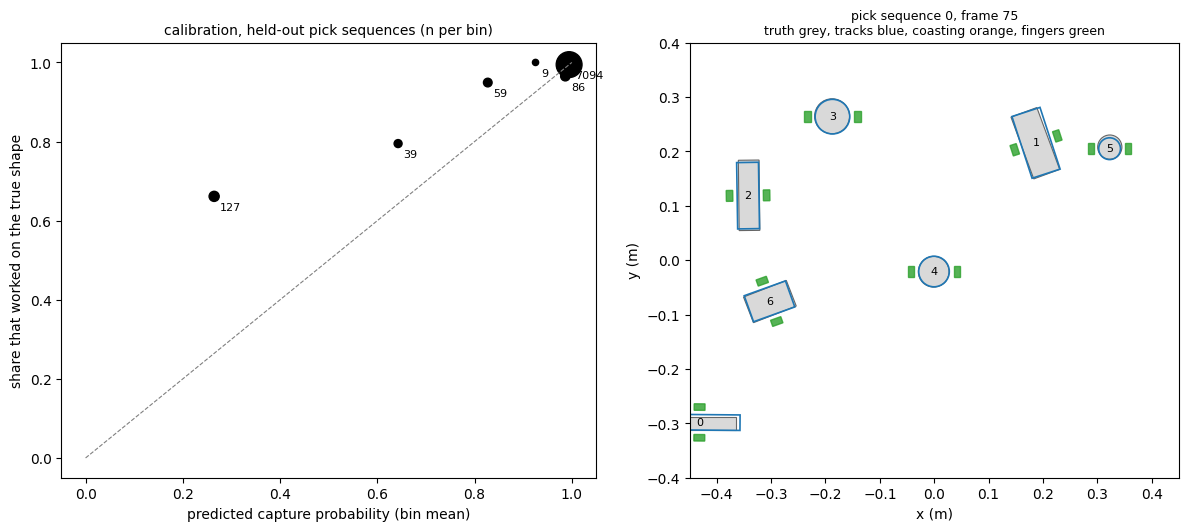

In [ ]:
offered = full_grasps[full_grasps.ready].copy()
offered['bin'] = pd.cut(offered.capture_probability, [0, 0.5, 0.8, 0.9, 0.95, 0.99, 1.0], include_lowest=True)
calibration = offered.groupby('bin', observed=True).agg(grasps=('success', 'size'), predicted=('capture_probability', 'mean'),
                                                        observed=('success', 'mean'))
print('capture probability against how often the grasp worked on the true shape')
print(calibration.round(3))
brier = ((offered.capture_probability - offered.success) ** 2).mean()
base_rate = offered.success.mean()
print(f'brier score {brier:.4f}, against {base_rate * (1 - base_rate):.4f} for always predicting the overall rate')

fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), layout='constrained')
ax = axes[0]
ax.plot([0, 1], [0, 1], color='gray', lw=0.8, ls='--')
ax.scatter(calibration.predicted, calibration.observed, s=8 + 4 * np.sqrt(calibration.grasps), color='k')
for _, row in calibration.iterrows():
    ax.annotate(f'{row.grasps:.0f}', (row.predicted, row.observed), textcoords='offset points', xytext=(4, -10), fontsize=8)
ax.set_xlabel('predicted capture probability (bin mean)')
ax.set_ylabel('share that worked on the true shape')
ax.set_title('calibration, held-out pick sequences (n per bin)', fontsize=10)

k, t = 0, 75
ax = axes[1]
seq = pick_sequences[k]
for obj in seq['objects']:
    shape = true_footprint(obj, t)
    if shape['kind'] == 'rect':
        corners, _ = rect_corners(shape)
        ax.fill(*corners.T, color='0.85', ec='0.4', lw=0.8)
    else:
        ax.add_patch(plt.Circle(shape['centre'], shape['radius'], color='0.85', ec='0.4', lw=0.8))
objects = pick_outputs[k][t]
plans = grasp_planner.plan(objects, pick_tables[k][t])
for obj in objects:
    if 'category' not in obj or obj['category'] == 'unknown':
        continue
    shape = object_footprint(obj, pick_tables[k][t], n_sigma=0.0, margin=0.0)
    shape['centre'] = obj['position'][:2]
    style = dict(fill=False, ec='tab:blue' if obj['state'] == 'tracked' else 'tab:orange', lw=1.2,
                 ls='-' if obj['state'] == 'tracked' else '--')
    if shape['kind'] == 'rect':
        corners, _ = rect_corners(shape)
        ax.add_patch(plt.Polygon(corners, **style))
    else:
        ax.add_patch(plt.Circle(shape['centre'], shape['radius'], **style))
    ax.text(*shape['centre'], str(obj['id']), fontsize=8, ha='center', va='center', clip_on=True)
    feasible = [c for c in plans.get(obj['id'], []) if c['feasible']]
    if feasible:
        best = feasible[0]
        for part in gripper_parts(best['tcp'][:2], best['tcp'][2], best['closing_angle'], best['opening'], grasp_planner.gripper)[:2]:
            corners, _ = rect_corners(part)
            ax.fill(*corners.T, color='tab:green', alpha=0.8)
ax.set_aspect('equal')
ax.set_xlim(-0.45, 0.45)
ax.set_ylim(-0.4, 0.4)
ax.set_xlabel('x (m)')
ax.set_ylabel('y (m)')
ax.set_title(f'pick sequence {k}, frame {t}\ntruth grey, tracks blue, coasting orange, fingers green', fontsize=9)
plt.show()

In [ ]:
def recovery_events(frame_records, track_outputs, seq, max_wait=30):
    events = []
    ids_by_frame = [{frame_records[t]['detections'][entry[1]]['gt_id']: entry[0] for entry in reported}
                    for t, reported in enumerate(track_outputs)]
    for gt_id, obj in enumerate(seq['objects']):
        if not obj['is_target']:
            continue
        visible = np.array([gt_id in record['visible_gt'] for record in frame_records])
        t = 1
        while t < len(visible):
            if visible[t - 1] and not visible[t]:
                start = t
                while t < len(visible) and not visible[t]:
                    t += 1
                if t == len(visible):
                    break
                before = [ids_by_frame[s][gt_id] for s in range(max(0, start - 10), start) if gt_id in ids_by_frame[s]]
                if before:
                    outcome, wait = 'not reported again', np.nan
                    for s in range(t, min(len(visible), t + max_wait)):
                        if gt_id in ids_by_frame[s]:
                            outcome = 'same id' if ids_by_frame[s][gt_id] == before[-1] else 'other id'
                            wait = s - t
                            break
                    events.append({'hidden_frames': t - start, 'outcome': outcome, 'frames_to_report': wait})
            t += 1
    return events


rows = []
for (scenario, k), seq in heldout_sequences.items():
    if scenario in ['occlusion', 'crowded']:
        outputs = run_adaptive(AdaptiveTracker(**variants[selected]), seq, heldout_cache[(scenario, k)])
        rows += [{'scenario': scenario, **event} for event in recovery_events(heldout_cache[(scenario, k)], outputs, seq)]
for k, seq in pick_sequences.items():
    outputs = run_adaptive(AdaptiveTracker(**variants[selected]), seq, pick_cache[k])
    rows += [{'scenario': 'pick', **event} for event in recovery_events(pick_cache[k], outputs, seq)]
recovery = pd.DataFrame(rows)
recovery['hidden'] = pd.cut(recovery.hidden_frames, [0, 5, 20, 150], labels=['1-5 frames', '6-20 frames', 'over 20 frames'])
print(f'{len(recovery)} times an object went out of view and came back, selected tracker')
table = recovery.groupby(['scenario', 'hidden'], observed=True).agg(
    events=('outcome', 'size'), same_id=('outcome', lambda o: (o == 'same id').mean()),
    median_frames_to_report=('frames_to_report', 'median'), p90_frames=('frames_to_report', lambda f: f.quantile(0.9)))
table['median_ms'] = 1000 * DT * table.median_frames_to_report
table.round(3)

267 times an object went out of view and came back, selected tracker


events  same_id  median_frames_to_report  p90_frames  median_ms
scenario  hidden                                                                         
crowded   1-5 frames           9    1.000                      0.0         1.0      0.000
          6-20 frames          1    1.000                      4.0         4.0    266.667
          over 20 frames       2    1.000                      2.5         2.9    166.667
occlusion 1-5 frames          32    1.000                      0.5         1.0     33.333
          6-20 frames         93    0.989                      0.0         1.0      0.000
          over 20 frames       1    1.000                      5.0         5.0    333.333
pick      1-5 frames           8    1.000                      0.0         1.0      0.000
          6-20 frames        119    0.992                      0.0         1.0      0.000
          over 20 frames       2    1.000                      2.0         2.8    133.333

In [ ]:
def straight_path(start, end, first, last):
    s = np.clip((np.arange(N_FRAMES) - first) / (last - first), 0, 1)
    return np.asarray(start) + s[:, None] * (np.asarray(end) - np.asarray(start))


def back_and_forth(x_range, y, speed, phase, sudden=False):
    span = x_range[1] - x_range[0]
    time_s = np.arange(N_FRAMES) * DT
    if sudden:
        travel = (speed * time_s + phase * span) % (2 * span)
        x = x_range[0] + np.where(travel < span, travel, 2 * span - travel)
    else:
        x = x_range[0] + 0.5 * span * (1 - np.cos(2 * speed / span * time_s + 2 * np.pi * phase))
    return np.column_stack([x, np.full(N_FRAMES, y)])


def placed(obj, xy_path):
    obj = dict(obj, path=np.column_stack([xy_path, np.full(N_FRAMES, resting_height(obj))]))
    obj['is_static'] = bool(np.allclose(xy_path, xy_path[0]))
    return obj


def hard_case(case, seed):
    rng = np.random.default_rng(seed)
    small = lambda: random_object(rng, pick_sized=True)
    if case == 'crossing':
        objects = [placed(small(), straight_path([-0.32, -0.02], [0.32, -0.02], 30, 110)),
                   placed(small(), straight_path([0.32, 0.20], [-0.32, 0.20], 30, 110)),
                   placed(small(), np.tile([0.0, -0.21], (N_FRAMES, 1)))]
    elif case == 'look-alikes side by side':
        twin = small()
        gap = 2 * footprint_radius(twin) + 0.015
        objects = [placed(twin, straight_path([-0.30, 0.0], [0.20, 0.0], 20, 90)),
                   placed(dict(twin, yaw=rng.uniform(0, np.pi)),
                          np.where(np.arange(N_FRAMES)[:, None] < 95, straight_path([-0.30, gap], [0.20, gap], 20, 90),
                                   straight_path([0.20, gap], [-0.25, gap], 95, 145)))]
    elif case == 'passes behind another':
        tall = {'kind': 'box', 'size': np.array([0.08, 0.03, 0.12]), 'color': np.array([0.55, 0.55, 0.6]), 'yaw': 0.0,
                'is_target': True}
        objects = [placed(tall, np.tile([0.0, 0.02], (N_FRAMES, 1))),
                   placed(small(), straight_path([-0.32, 0.22], [0.32, 0.22], 30, 120))]
    elif case == 'long occlusion':
        panel_x = np.interp(np.arange(N_FRAMES), [0, 30, 45, 97, 112, N_FRAMES], [0.75, 0.75, 0.08, 0.08, 0.75, 0.75])
        panel = {'kind': 'box', 'size': np.array([0.10, 0.012, 0.16]), 'color': np.array([0.25, 0.32, 0.55]), 'yaw': 0.0,
                 'is_target': False, 'is_static': False,
                 'path': np.column_stack([panel_x, np.full(N_FRAMES, -0.30), np.full(N_FRAMES, 0.17)])}
        objects = [placed(small(), np.tile([0.08, 0.12], (N_FRAMES, 1))), placed(small(), np.tile([-0.28, 0.10], (N_FRAMES, 1))),
                   panel]
    elif case in ['different speeds', 'sudden reversals']:
        objects = [placed(small(), back_and_forth((-0.25, 0.25), y, speed, rng.uniform(), sudden=case == 'sudden reversals'))
                   for y, speed in [(-0.06, 0.05), (0.10, 0.15), (0.26, 0.30)]]
    else:
        raise ValueError(case)
    cam_rot, cam_pos = static_camera()
    return {'scenario': case, 'seed': seed, 'objects': objects, 'cam_rot': cam_rot, 'cam_pos': cam_pos,
            'reported_rot': cam_rot, 'reported_pos': cam_pos, 'pose_cov': np.zeros((6, 6))}


def irregular_frames(rng, drop_rate=0.25, jitter=0.004):
    kept = np.flatnonzero(rng.random(N_FRAMES) >= drop_rate)
    stamps = kept * DT + rng.normal(scale=jitter, size=len(kept))
    for i in range(1, len(stamps)):
        stamps[i] = max(stamps[i], stamps[i - 1] + 1e-3)
    return kept, stamps


HARD_CASES = ['crossing', 'look-alikes side by side', 'passes behind another', 'long occlusion', 'different speeds', 'sudden reversals']
N_HARD_SEEDS = 8
hard_sequences, hard_cache = {}, {}
started = time.perf_counter()
for case_index, case in enumerate(HARD_CASES):
    for k in range(N_HARD_SEEDS):
        seq = hard_case(case, seed=11000 + 100 * case_index + k)
        for a in range(len(seq['objects'])):
            for b in range(a + 1, len(seq['objects'])):
                if seq['objects'][a]['is_target'] and seq['objects'][b]['is_target']:
                    assert min_clearance(seq['objects'][a]['path'][:, :2], seq['objects'][a],
                                         seq['objects'][b]['path'][:, :2], seq['objects'][b]) > 0, (case, k)
        hard_sequences[(case, k)] = seq
        hard_cache[(case, k)] = run_perception(seq, {'depth_only': condition(use_color=False)})['depth_only']
print(f'{len(hard_sequences)} scripted sequences in {time.perf_counter() - started:.0f} s')

48 scripted sequences in 415 s


In [ ]:
hard_trackers = {'v1 world 3D': None, 'T9 = T8 + re-identification': variants['T9 = T8 + re-identification'],
                 'T14 = T13 + area learning for young tracks': variants['T14 = T13 + area learning for young tracks'],
                 selected: variants[selected]}


def tracking_scores(seq, frame_records, outputs, frame_ids=None):
    kept = frame_records if frame_ids is None else [frame_records[t] for t in frame_ids]
    scores = {**score_tracking(kept, outputs), **score_association(kept, outputs)}
    hota = hota_3d(seq, frame_records, outputs, frame_ids)
    return {**scores, **{key.replace('hota', 'hota_3d'): value for key, value in hota.items() if key != 'hota_at_alpha'}}


rows, recovery_rows = [], []
timing_rng = np.random.default_rng(12)
for (case, k), seq in hard_sequences.items():
    frame_records = hard_cache[(case, k)]
    for name, settings in hard_trackers.items():
        if settings is None:
            outputs = run_tracker(TRACKERS['world 3D'](), seq, frame_records)
        else:
            outputs = run_adaptive(AdaptiveTracker(**settings), seq, frame_records)
        rows.append({'case': case, 'sequence': k, 'tracker': name.split(' ')[0] if name[0] == 'T' else name,
                     **tracking_scores(seq, frame_records, outputs)})
        recovery_rows += [{'case': case, 'tracker': name.split(' ')[0] if name[0] == 'T' else name, **event}
                          for event in recovery_events(frame_records, outputs, seq)]


for k in range(N_HARD_SEEDS):
    seq, frame_records = heldout_sequences[('nominal', k)], heldout_cache[('nominal', k)]
    kept, stamps = irregular_frames(timing_rng)
    for name, settings in hard_trackers.items():
        if settings is None:
            continue
        tracker = AdaptiveTracker(**settings)
        outputs = [tracker.step(frame_records[t]['detections'], seq['reported_rot'][t], seq['reported_pos'][t], stamp, seq['pose_cov'])
                   for t, stamp in zip(kept, stamps)]
        rows.append({'case': 'irregular timing', 'sequence': k, 'tracker': name.split(' ')[0],
                     **tracking_scores(seq, frame_records, outputs, kept)})
hard_results = pd.DataFrame(rows)
metric_columns = ['hota_3d', 'hota_3d_det_a', 'hota_3d_ass_a', 'idf1', 'mota', 'id_switches', 'fragments']
hard_table = hard_results.groupby(['case', 'tracker'], sort=False)[metric_columns].mean()
hard_table.round(3)

hota_3d  hota_3d_det_a  hota_3d_ass_a   idf1   mota  id_switches  fragments
case                     tracker                                                                                 
crossing                 v1 world 3D    0.479          0.454          0.522  0.993  0.987        0.000      0.000
                         T9             0.881          0.855          0.930  0.993  0.987        0.000      0.000
                         T14            0.964          0.961          0.966  0.993  0.987        0.000      0.000
                         T18            0.964          0.961          0.966  0.993  0.987        0.000      0.000
look-alikes side by side v1 world 3D    0.385          0.365          0.409  0.899  0.829        0.000      0.125
                         T9             0.646          0.669          0.629  0.747  0.827        0.500      0.625
                         T14            0.660          0.659          0.662  0.706  0.825        1.000      0.750
                         T18            0.660          0.659          0.662  0.706  0.825        1.000      0.750
passes behind another    v1 world 3D    0.260          0.259          0.271  0.767  0.968        1.000      1.000
                         T9             0.763          0.787          0.748  0.903  0.971        0.375      1.000
                         T14            0.874          0.910          0.843  0.903  0.970        0.375      1.000
                         T18            0.874          0.910          0.843  0.903  0.970        0.375      1.000
long occlusion           v1 world 3D    0.394          0.417          0.380  0.813  0.969        1.000      1.000
                         T9             0.839          0.828          0.854  0.987  0.974        0.000      1.000
                         T14            0.930          0.941          0.920  0.965  0.971        0.250      1.125
                         T18            0.930          0.941          0.920  0.965  0.971        0.250      1.125
different speeds         v1 world 3D    0.410          0.369          0.478  0.991  0.984        0.125      0.375
                         T9             0.848          0.820          0.899  0.993  0.986        0.000      0.375
                         T14            0.949          0.943          0.955  0.993  0.986        0.000      0.375
                         T18            0.949          0.943          0.955  0.993  0.986        0.000      0.375
sudden reversals         v1 world 3D    0.477          0.449          0.521  0.983  0.983        0.250      0.500
                         T9             0.755          0.811          0.731  0.805  0.953        5.500      4.875
                         T14            0.856          0.918          0.802  0.839  0.939        7.625      7.125
                         T18            0.856          0.918          0.802  0.839  0.938        8.625      6.875
irregular timing         T9             0.849          0.821          0.901  0.991  0.981        0.000      0.375
                         T14            0.935          0.942          0.929  0.974  0.980        0.250      0.625
                         T18            0.935          0.942          0.929  0.974  0.980        0.250      0.625

                    case tracker  hota_3d_gain_over_v1  ci_low  ci_high
                crossing     T14                 0.485   0.451    0.520
                crossing     T18                 0.485   0.451    0.520
                crossing      T9                 0.402   0.377    0.427
look-alikes side by side     T14                 0.275   0.099    0.460
look-alikes side by side     T18                 0.275   0.093    0.463
look-alikes side by side      T9                 0.261   0.103    0.419
   passes behind another     T14                 0.613   0.579    0.639
   passes behind another     T18                 0.613   0.577    0.640
   passes behind another      T9                 0.503   0.472    0.532
          long occlusion     T14                 0.536   0.485    0.583
          long occlusion     T18                 0.536   0.485    0.581
          long occlusion      T9                 0.445   0.423    0.475
        different speeds     T14                 0.539   0.472  

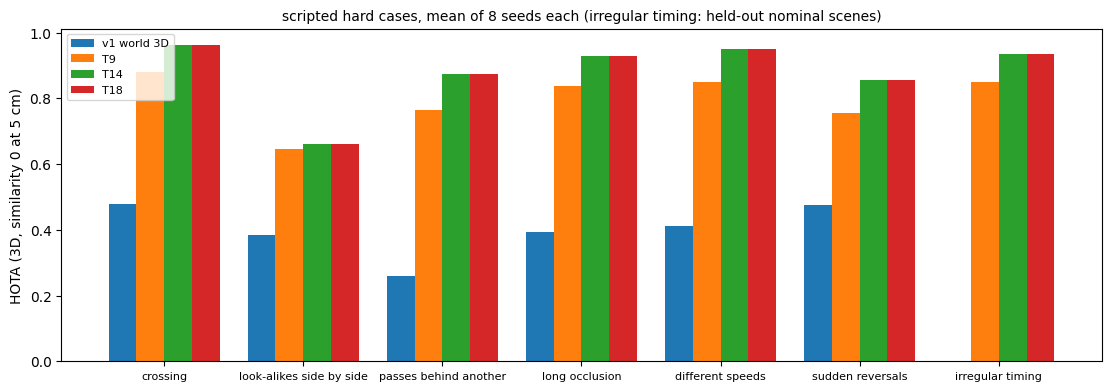

In [ ]:
rows = []
for case in hard_results.case.unique():
    per_seq = hard_results[hard_results.case == case].pivot(index='sequence', columns='tracker', values='hota_3d')
    for name in per_seq.columns:
        if name != 'v1 world 3D' and 'v1 world 3D' in per_seq.columns:
            mean, low, high = bootstrap_mean_ci(per_seq[name] - per_seq['v1 world 3D'], boot_rng)
            rows.append({'case': case, 'tracker': name, 'hota_3d_gain_over_v1': mean, 'ci_low': low, 'ci_high': high})
print(pd.DataFrame(rows).round(3).to_string(index=False))

recovery_by_case = pd.DataFrame(recovery_rows).groupby(['case', 'tracker'], sort=False).outcome.value_counts().unstack(fill_value=0)
print()
print('every time an object went out of view and came back, which id it was reported with')
print(recovery_by_case)

fig, ax = plt.subplots(figsize=(11, 3.8), layout='constrained')
cases = list(hard_results.case.unique())
names = list(hard_results.tracker.unique())
for i, name in enumerate(names):
    means = [hard_results[(hard_results.case == c) & (hard_results.tracker == name)].hota_3d.mean() for c in cases]
    ax.bar(np.arange(len(cases)) + (i - (len(names) - 1) / 2) * 0.2, means, width=0.2, label=name)
ax.set_xticks(range(len(cases)))
ax.set_xticklabels(cases, fontsize=8)
ax.set_ylabel(f'HOTA (3D, similarity 0 at {100 * HOTA_ZERO_DISTANCE:.0f} cm)')
ax.set_title(f'scripted hard cases, mean of {N_HARD_SEEDS} seeds each (irregular timing: held-out nominal scenes)', fontsize=10)
ax.legend(fontsize=8)
plt.show()

27450 held-out detections. an honest model has inside_p equal to p
                                       mean_nll  inside_50%  inside_68%  inside_90%  inside_95%  inside_99%  inside_95%, normal views  inside_95%, under 40% views
model                                                                                                                                                             
fixed                                   -14.891       0.890       0.934       0.969       0.974       0.978                     0.986                        0.572
distance                                -14.895       0.879       0.924       0.964       0.972       0.978                     0.984                        0.569
shape and view, cautious                -15.541       0.733       0.819       0.920       0.945       0.970                     0.942                        0.976
quality                                 -17.652       0.670       0.767       0.878       0.909       0.942           

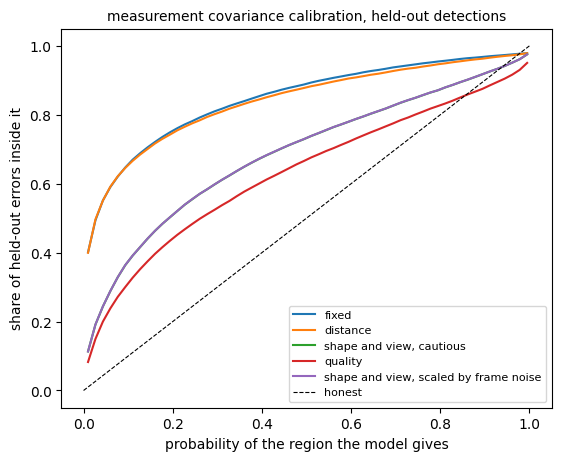

In [ ]:
heldout_fixed = geometry[geometry.scenario != 'camera_motion']
heldout_errors = (heldout_fixed[['ex', 'ey', 'ez']] ** 2).sum(axis=1).values
heldout_usual = heldout_fixed.groupby(['scenario', 'sequence', 'object']).area.transform('median')
heldout_view = np.digitize(heldout_fixed.area / heldout_usual, VISIBILITY_EDGES)
levels = [0.5, 0.68, 0.9, 0.95, 0.99]
rows = []
for name, model in noise_models.items():
    std = predicted_std(model, heldout_fixed, heldout_view)
    normalised = heldout_errors / std ** 2
    row = {'model': name, 'mean_nll': gaussian_nll(np.log(std), heldout_errors).mean()}
    row.update({f'inside_{int(100 * p)}%': (normalised < chi2.ppf(p, 3)).mean() for p in levels})
    for view, label in [(NORMAL_VIEW, 'normal'), (0, 'under 40%')]:
        picked = heldout_view == view
        row[f'inside_95%, {label} views'] = (normalised[picked] < chi2.ppf(0.95, 3)).mean()
    rows.append(row)
measurement_calibration = pd.DataFrame(rows).set_index('model')
print(f'{len(heldout_errors)} held-out detections. an honest model has inside_p equal to p')
print(measurement_calibration.round(3))

fig, ax = plt.subplots(figsize=(5.5, 4.5), layout='constrained')
grid = np.linspace(0.01, 0.995, 60)
for name, model in noise_models.items():
    normalised = heldout_errors / predicted_std(model, heldout_fixed, heldout_view) ** 2
    ax.plot(grid, [(normalised < chi2.ppf(p, 3)).mean() for p in grid], label=name)
ax.plot([0, 1], [0, 1], 'k--', lw=0.8, label='honest')
ax.set_xlabel('probability of the region the model gives')
ax.set_ylabel('share of held-out errors inside it')
ax.set_title('measurement covariance calibration, held-out detections', fontsize=10)
ax.legend(fontsize=8)
plt.show()

In [ ]:
rows = [{'confidence': det['confidence'], 'good': det['gt_id'] >= 0 and det['purity'] >= 0.9, 'source': source}
        for source, caches in [('held-out scenarios', [heldout_cache[key] for key in heldout_cache]),
                               ('pick, depth noise x5', [pick_stress_cache[(k, 'depth noise x5')] for k in pick_sequences])]
        for records in caches for record in records for det in record['detections'] if det['gt_id'] != IGNORED]
confidence_check = pd.DataFrame(rows)
for source, group in confidence_check.groupby('source', sort=False):
    bad, good = group[~group.good].confidence.values, group[group.good].confidence.values
    auroc = np.mean(good[:, None] > bad[None, :]) + 0.5 * np.mean(good[:, None] == bad[None, :]) if len(bad) else np.nan
    brier = ((group.confidence - group.good) ** 2).mean()
    print(f'{source}: {len(group)} detections, {len(bad)} bad, AUROC {auroc:.3f}, brier {brier:.4f} '
          f'against {group.good.mean() * (1 - group.good.mean()):.4f} for always predicting the overall rate')
confidence_check['bin'] = pd.cut(confidence_check.confidence, [0, 0.5, 0.9, 0.99, 0.999, 1.0], include_lowest=True)
confidence_check.groupby(['source', 'bin'], sort=False, observed=True).agg(
    detections=('good', 'size'), stated=('confidence', 'mean'), observed_good=('good', 'mean')).round(4)

held-out scenarios: 36452 detections, 149 bad, AUROC 0.967, brier 0.0040 against 0.0041 for always predicting the overall rate
pick, depth noise x5: 8336 detections, 83 bad, AUROC 0.353, brier 0.0100 against 0.0099 for always predicting the overall rate


detections  stated  observed_good
source               bin                                             
held-out scenarios   (0.99, 0.999]       10635  0.9981         0.9889
                     (0.999, 1.0]        25638  0.9996         1.0000
                     (0.9, 0.99]           176  0.9823         0.8409
                     (0.5, 0.9]              3  0.6741         0.0000
pick, depth noise x5 (0.999, 1.0]         6837  0.9997         0.9884
                     (0.99, 0.999]        1496  0.9980         0.9973
                     (0.9, 0.99]             3  0.9870         1.0000

In [ ]:
def coasting_samples(seq, frame_records, outputs):
    owner, last_tracked, rows = {}, {}, []
    for t, objects in enumerate(outputs):
        for obj in objects:
            if obj['state'] == 'tracked':
                gt_id = frame_records[t]['detections'][obj['detection_index']]['gt_id']
                if gt_id >= 0:
                    owner[obj['id']], last_tracked[obj['id']] = gt_id, t
            elif obj['state'] == 'coasting' and obj['id'] in owner:
                truth = seq['objects'][owner[obj['id']]]
                error = obj['position'] - truth['path'][t]
                rows.append({'unseen_frames': t - last_tracked[obj['id']], 'error_mm': 1000 * np.linalg.norm(error),
                             'predicted_std_mm': 1000 * np.sqrt(np.trace(obj['covariance']) / 3),
                             'nees': error @ np.linalg.solve(obj['covariance'], error), 'moving': not truth['is_static']})
    return rows


rows = [{'scenario': scenario, **row} for (scenario, k), seq in heldout_sequences.items() if scenario in ['occlusion', 'crowded']
        for row in coasting_samples(seq, heldout_cache[(scenario, k)], pipeline_outputs[(scenario, k)])]
rows += [{'scenario': 'pick', **row} for k, seq in pick_sequences.items() for row in coasting_samples(seq, pick_cache[k], pick_outputs[k])]
coasting = pd.DataFrame(rows)
coasting['unseen'] = pd.cut(coasting.unseen_frames, [0, 3, 10, 20], labels=['1-3 frames', '4-10 frames', '11-20 frames'])
coasting_table = coasting.groupby(['unseen', 'moving'], observed=True).agg(
    predictions=('nees', 'size'), rms_error_mm=('error_mm', lambda e: np.sqrt((e ** 2).mean())),
    mean_predicted_std_x_sqrt3_mm=('predicted_std_mm', lambda s: np.sqrt(3) * s.mean()),
    inside_95=('nees', lambda n: (n < chi2.ppf(0.95, 3)).mean()), mean_nees=('nees', 'mean'))
print('coasting predictions of the selected tracker, held-out occlusion, crowded and pick scenes')
print('an honest covariance puts 95% inside and has mean NEES 3. rms error and sqrt(3) x predicted std should be close')
coasting_table.round(3)

coasting predictions of the selected tracker, held-out occlusion, crowded and pick scenes
an honest covariance puts 95% inside and has mean NEES 3. rms error and sqrt(3) x predicted std should be close


predictions  rms_error_mm  mean_predicted_std_x_sqrt3_mm  inside_95  mean_nees
unseen       moving                                                                                
1-3 frames   False           672        22.640                         29.272      0.945      2.183
             True            293        24.338                         30.226      0.939      2.695
4-10 frames  False          1113        45.388                         99.351      0.989      0.671
             True            379        52.003                         97.658      1.000      0.816
11-20 frames False           239        87.602                        241.673      1.000      0.394
             True             79       162.203                        273.751      1.000      0.916

28821 tracked estimates from 40 scenes. honest: inside_p equals p, mean NEES 3, rmse about equal to sqrt(3) x reported std
                                    estimates  rmse_mm  reported_std_x_sqrt3_mm  mean_nees  inside_50%  inside_90%  inside_95%
mounting                                                                                                                      
calibration exact                       28821    4.439                    6.253      1.712       0.776       0.956       0.974
calibration off, pipeline not told      28821    7.910                    6.253     50.589       0.168       0.438       0.524
calibration off, covariance given       28821    7.910                    9.442      2.296       0.631       0.959       0.986

                estimates  rmse_mm  reported_std_x_sqrt3_mm  mean_nees  inside_50%  inside_90%  inside_95%
range                                                                                                     
(0.823, 1.14]        9614  

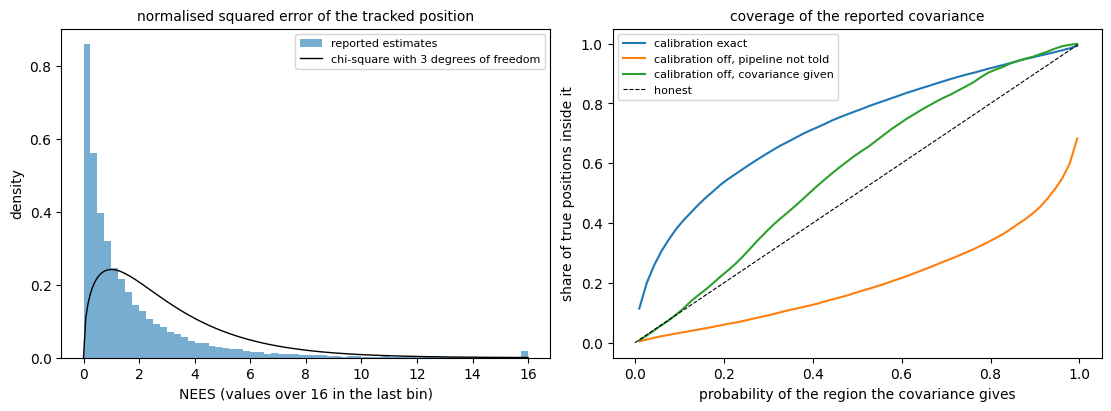

In [ ]:
N_WORKERS = min(4, os.cpu_count() or 1)


def parallel_map(function, items):
    if N_WORKERS == 1:
        return [function(item) for item in items]
    with concurrent.futures.ProcessPoolExecutor(N_WORKERS, mp_context=multiprocessing.get_context('fork')) as pool:
        return list(pool.map(function, items))



N_CALIBRATION_SCENES = 40
MOUNTING_STD = (0.002, np.deg2rad(0.2))
MOUNTING_COV = np.diag([MOUNTING_STD[0] ** 2] * 3 + [MOUNTING_STD[1] ** 2] * 3)


def reported_estimates(seq, frame_records, settings, mounting_error=None, extrinsic_cov=None):
    pipeline = TabletopPerception(settings, seed=seq['seed'], extrinsic_cov=extrinsic_cov)
    rows = []
    for t, record in enumerate(frame_records):
        cam_rot, cam_pos = seq['reported_rot'][t], seq['reported_pos'][t]
        if mounting_error is not None:
            cam_rot, cam_pos = cam_rot @ mounting_error[0], cam_pos + mounting_error[1]
        objects = pipeline.process_detections(record['detections'], record['plane'], cam_rot, cam_pos, t * DT, seq['pose_cov'])
        camera_speed = np.linalg.norm(seq['cam_pos'][t] - seq['cam_pos'][max(t - 1, 0)]) / DT
        for obj in objects:
            if obj['state'] != 'tracked':
                continue
            gt_id = record['detections'][obj['detection_index']]['gt_id']
            if gt_id < 0:
                continue
            truth = seq['objects'][gt_id]
            error = obj['position'] - truth['path'][t]
            rows.append({'error_mm': 1000 * np.linalg.norm(error), 'nees': error @ np.linalg.solve(obj['covariance'], error),
                         'range_m': np.linalg.norm(truth['path'][t] - seq['cam_pos'][t]), 'visible_share': obj['visible_share'],
                         'camera_speed': camera_speed, 'object_moves': not truth['is_static'],
                         'reported_std_mm': 1000 * np.sqrt(np.trace(obj['covariance']) / 3)})
    return rows


def calibration_scene(k):
    seq = random_scene(41000 + k)
    records = run_perception(seq, {'default': condition(use_color=False)})['default']
    rng = np.random.default_rng([41000, k])
    mounting_error = (Rotation.from_rotvec(rng.normal(scale=MOUNTING_STD[1], size=3)).as_matrix(), rng.normal(scale=MOUNTING_STD[0], size=3))
    rows = []
    for name, error, cov in [('calibration exact', None, None), ('calibration off, pipeline not told', mounting_error, None),
                             ('calibration off, covariance given', mounting_error, MOUNTING_COV)]:
        rows += [{'scene': k, 'mounting': name, **row} for row in reported_estimates(seq, records, variants[selected], error, cov)]
    return rows


estimates = pd.DataFrame([row for rows in parallel_map(calibration_scene, range(N_CALIBRATION_SCENES)) for row in rows])
COVERAGE_LEVELS = [0.5, 0.9, 0.95]


def coverage_table(samples, by):
    grouped = samples.groupby(by, sort=False, observed=True)
    table = grouped.agg(estimates=('nees', 'size'), rmse_mm=('error_mm', lambda e: np.sqrt((e ** 2).mean())),
                        reported_std_x_sqrt3_mm=('reported_std_mm', lambda s: np.sqrt(3 * (s ** 2).mean())),
                        mean_nees=('nees', 'mean'))
    for level in COVERAGE_LEVELS:
        table[f'inside_{int(100 * level)}%'] = grouped.nees.apply(lambda n: (n < chi2.ppf(level, 3)).mean())
    return table


exact = estimates[estimates.mounting == 'calibration exact'].copy()
print(f'{len(exact)} tracked estimates from {N_CALIBRATION_SCENES} scenes. honest: inside_p equals p, mean NEES 3, '
      'rmse about equal to sqrt(3) x reported std')
print(coverage_table(estimates, 'mounting').round(3))
exact['range'] = pd.qcut(exact.range_m, 3).astype(str)
exact['view'] = pd.cut(exact.visible_share, [0, TRUNCATED_AREA_RATIO, 1 / TRUNCATED_AREA_RATIO, np.inf],
                       labels=['partly hidden', 'normal', 'merged with a neighbour'])
exact['camera'] = pd.cut(exact.camera_speed, [-1, 1e-9, 0.1, np.inf], labels=['still', 'under 0.1 m/s', 'over 0.1 m/s'])
exact['object'] = np.where(exact.object_moves, 'moving object', 'still object')
for column in ['range', 'view', 'camera', 'object']:
    print()
    print(coverage_table(exact, column).round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout='constrained')
grid = np.linspace(0, 16, 200)
axes[0].hist(exact.nees.clip(upper=16), bins=64, density=True, color='tab:blue', alpha=0.6, label='reported estimates')
axes[0].plot(grid, chi2.pdf(grid, 3), 'k', lw=1, label='chi-square with 3 degrees of freedom')
axes[0].set_xlabel('NEES (values over 16 in the last bin)')
axes[0].set_ylabel('density')
axes[0].set_title('normalised squared error of the tracked position', fontsize=10)
axes[0].legend(fontsize=8)
levels = np.linspace(0.01, 0.995, 60)
for name, group in estimates.groupby('mounting', sort=False):
    axes[1].plot(levels, [(group.nees < chi2.ppf(p, 3)).mean() for p in levels], label=name)
axes[1].plot([0, 1], [0, 1], 'k--', lw=0.8, label='honest')
axes[1].set_xlabel('probability of the region the covariance gives')
axes[1].set_ylabel('share of true positions inside it')
axes[1].set_title('coverage of the reported covariance', fontsize=10)
axes[1].legend(fontsize=8)
plt.show()

In [ ]:
PANDA_JOINT_ORIGINS = [((0, 0, 0.333), 0.0), ((0, 0, 0), -np.pi / 2), ((0, -0.316, 0), np.pi / 2), ((0.0825, 0, 0), np.pi / 2),
                       ((-0.0825, 0.384, 0), -np.pi / 2), ((0, 0, 0), np.pi / 2), ((0.088, 0, 0), np.pi / 2)]
PANDA_LIMITS = np.array([[-2.9671, 2.9671], [-1.8326, 1.8326], [-2.9671, 2.9671], [-3.1416, 0.0873],
                         [-2.9671, 2.9671], [-0.0873, 3.8223], [-2.9671, 2.9671]])
PANDA_READY = np.array([0.0, -0.785, 0.0, -2.356, 0.0, 1.571, 0.785])
FLANGE_TO_TCP = 0.107 + 0.1034      
PANDA_FLANGE_REACH = 0.88
ARM_BASE_IN_TABLE = np.array([0.0, 0.55, 0.0])
ARM_BASE_YAW = -np.pi / 2


def fixed_transform(xyz, roll):
    T = np.eye(4)
    c, s = np.cos(roll), np.sin(roll)
    T[:3, :3] = [[1, 0, 0], [0, c, -s], [0, s, c]]
    T[:3, 3] = xyz
    return T


PANDA_ORIGIN_TRANSFORMS = np.array([fixed_transform(xyz, roll) for xyz, roll in PANDA_JOINT_ORIGINS])
HAND_TRANSFORM = np.eye(4)
HAND_TRANSFORM[:3, :3] = Rotation.from_euler('z', -np.pi / 4).as_matrix()
HAND_TRANSFORM[2, 3] = FLANGE_TO_TCP


def panda_forward(q):
    n = len(q)
    T = np.tile(np.eye(4), (n, 1, 1))
    frames = []
    for i in range(7):
        T = T @ PANDA_ORIGIN_TRANSFORMS[i]
        c, s = np.cos(q[:, i]), np.sin(q[:, i])
        turn = np.tile(np.eye(4), (n, 1, 1))
        turn[:, 0, 0], turn[:, 0, 1], turn[:, 1, 0], turn[:, 1, 1] = c, -s, s, c
        T = T @ turn
        frames.append(T)
    return T @ HAND_TRANSFORM, frames


def cross3(a, b):
    return np.stack([a[:, 1] * b[:, 2] - a[:, 2] * b[:, 1], a[:, 2] * b[:, 0] - a[:, 0] * b[:, 2],
                     a[:, 0] * b[:, 1] - a[:, 1] * b[:, 0]], axis=1)


def panda_ik(goals, seeds, iterations=120, damping=0.05):
    q = seeds.copy()
    active = np.ones(len(q), dtype=bool)
    for iteration in range(iterations):
        tcp, frames = panda_forward(q[active])
        goal = goals[active]
        position_error = goal[:, :3, 3] - tcp[:, :3, 3]
        rotation_error = 0.5 * sum(cross3(tcp[:, :3, k], goal[:, :3, k]) for k in range(3))
        error = np.concatenate([position_error, rotation_error], axis=1)
        done = (np.linalg.norm(position_error, axis=1) < 1e-4) & (np.linalg.norm(rotation_error, axis=1) < 1e-4)
        done |= (iteration >= 40) & (np.linalg.norm(position_error, axis=1) > 0.02)
        jacobian = np.zeros((len(tcp), 6, 7))
        for i, frame in enumerate(frames):
            axis, origin = frame[:, :3, 2], frame[:, :3, 3]
            jacobian[:, :3, i] = cross3(axis, tcp[:, :3, 3] - origin)
            jacobian[:, 3:, i] = axis
        JJt = jacobian @ jacobian.transpose(0, 2, 1) + damping ** 2 * np.eye(6)
        step = (jacobian.transpose(0, 2, 1) @ np.linalg.solve(JJt, error[..., None]))[..., 0]
        q[active] = np.clip(q[active] + np.clip(step, -0.3, 0.3), PANDA_LIMITS[:, 0], PANDA_LIMITS[:, 1])
        index = np.flatnonzero(active)
        active[index[done]] = False
        if not active.any():
            break
    tcp, _ = panda_forward(q)
    position_miss = np.linalg.norm(goals[:, :3, 3] - tcp[:, :3, 3], axis=1)
    angle_miss = np.arccos(np.clip((np.einsum('nij,nij->n', goals[:, :3, :3], tcp[:, :3, :3]) - 1) / 2, -1, 1))
    solved = (position_miss < 0.001) & (angle_miss < np.deg2rad(1.0))
    to_limit = np.minimum(q - PANDA_LIMITS[:, 0], PANDA_LIMITS[:, 1] - q) / (PANDA_LIMITS[:, 1] - PANDA_LIMITS[:, 0])
    return solved, np.where(solved, to_limit.min(axis=1), -1.0), q


def table_to_base():
    c, s = np.cos(ARM_BASE_YAW), np.sin(ARM_BASE_YAW)
    base_in_table = np.eye(4)
    base_in_table[:3, :3] = [[c, -s, 0], [s, c, 0], [0, 0, 1]]
    base_in_table[:3, 3] = ARM_BASE_IN_TABLE
    return np.linalg.inv(base_in_table)


def solve_reachability(tcps, rotations, to_base):
    goals = np.tile(np.eye(4), (2 * len(tcps), 1, 1))
    for i, (tcp, rotation) in enumerate(zip(tcps, rotations)):
        for k, flip in enumerate([1.0, -1.0]):
            goals[2 * i + k, :3, :3] = to_base[:3, :3] @ rotation @ np.diag([flip, flip, 1.0])
            goals[2 * i + k, :3, 3] = to_base[:3, :3] @ tcp + to_base[:3, 3]
    azimuth = np.arctan2(goals[:, 1, 3], goals[:, 0, 3])
    margin = np.full(len(goals), -1.0)
    flange = goals[:, :3, 3] - FLANGE_TO_TCP * goals[:, :3, 2]
    within = np.linalg.norm(flange - [0.0, 0.0, 0.333], axis=1) < PANDA_FLANGE_REACH
    for elbow in [-2.356, -1.6, -2.8]:
        todo = np.flatnonzero((margin < 0) & within)
        if not len(todo):
            break
        seeds = np.tile(PANDA_READY, (len(todo), 1))
        seeds[:, 0], seeds[:, 3] = azimuth[todo], elbow
        margin[todo] = panda_ik(goals[todo], seeds)[1]
    return margin.reshape(-1, 2).max(axis=1)


REACH_CACHE = {}


def grasp_reachability(tcps, rotations, to_base=None):
    to_base = table_to_base() if to_base is None else to_base
    base_key = tuple(np.round(to_base[:3], 4).ravel())
    keys, todo = [], {}
    for tcp, rotation in zip(tcps, rotations):
        angle = np.arctan2(rotation[1, 1], rotation[0, 1]) % np.pi
        key = (int(round(tcp[0] / 0.01)), int(round(tcp[1] / 0.01)), int(round(tcp[2] / 0.01)), int(round(angle / np.deg2rad(5))) % 36)
        key = base_key + key
        keys.append(key)
        if key not in REACH_CACHE and key not in todo:
            closing = np.array([np.cos(key[-1] * np.deg2rad(5)), np.sin(key[-1] * np.deg2rad(5)), 0.0])
            todo[key] = (0.01 * np.array(key[-4:-1], dtype=float),
                         np.column_stack([np.cross([0.0, 0.0, 1.0], closing), closing, [0.0, 0.0, -1.0]]))
    if todo:
        margins = solve_reachability([pose[0] for pose in todo.values()], [pose[1] for pose in todo.values()], to_base)
        REACH_CACHE.update(zip(todo, margins))
    margin = np.array([REACH_CACHE[key] for key in keys])
    return margin >= 0, margin

In [ ]:
def footprint_gap(a, b):
    if a['z'][1] <= b['z'][0] or b['z'][1] <= a['z'][0]:
        return np.inf
    if a['kind'] == 'circle' and b['kind'] == 'circle':
        return np.linalg.norm(a['centre'] - b['centre']) - a['radius'] - b['radius']
    if a['kind'] == 'circle':
        a, b = b, a
    corners_a, axes_a = rect_corners(a)
    if b['kind'] == 'circle':
        local = axes_a @ (b['centre'] - a['centre'])
        outside = np.abs(local) - a['half']
        return np.linalg.norm(np.maximum(outside, 0)) + min(outside.max(), 0.0) - b['radius']
    corners_b, axes_b = rect_corners(b)
    gaps = []
    for axis in np.vstack([axes_a, axes_b]):
        pa, pb = corners_a @ axis, corners_b @ axis
        gaps.append(max(pb.min() - pa.max(), pa.min() - pb.max()))
    return max(gaps)


def yaw_std(obj):
    if obj['category'] != 'box' or not obj.get('yaw_valid', False):
        return np.inf
    return np.sqrt(abs(2 * np.log(np.clip(obj['yaw_consistency'], 1e-6, 1.0)))) / 4


def grasp_checks(candidate, kind, centre_uv, centre_h, size, yaw, gripper):
    closing = np.array([np.cos(candidate['closing_angle']), np.sin(candidate['closing_angle'])])
    finger_axis = np.array([-closing[1], closing[0]])
    tcp_uv, tcp_h = candidate['tcp_uv'], candidate['tcp_h']
    offset = centre_uv - tcp_uv
    if kind == 'box':
        angle = candidate['closing_angle'] - yaw
        across = 0.5 * (np.abs(size[:, 0] * np.cos(angle)) + np.abs(size[:, 1] * np.sin(angle)))
        along = 0.5 * (np.abs(size[:, 0] * np.sin(angle)) + np.abs(size[:, 1] * np.cos(angle)))
        holds_sideways = np.abs(offset @ finger_axis) + 0.5 * gripper.finger_width <= along
    else:
        across = 0.5 * size[:, 0]
        holds_sideways = np.abs(offset @ finger_axis) <= 0.25 * size[:, 0]
    clears_jaws = np.abs(offset @ closing) + across <= 0.5 * candidate['opening']
    pad_low, pad_high = tcp_h - 0.5 * gripper.pad_height, tcp_h + 0.5 * gripper.pad_height
    if kind == 'sphere':
        at_height = np.abs(tcp_h - centre_h) <= 0.25 * size[:, 0]
    else:
        low, high = centre_h - 0.5 * size[:, 2], centre_h + 0.5 * size[:, 2]
        at_height = np.minimum(pad_high, high) - np.maximum(pad_low, low) >= 0.01
    return clears_jaws & holds_sideways & at_height & (pad_low >= 0.0)


def perturbed_success(candidate, obj, table, gripper, rng, n_samples=128):
    centre_uv, centre_h, _ = in_table_frame(obj, table)
    cov_table = table['basis'].T @ obj['covariance'] @ table['basis']
    shift = rng.multivariate_normal(np.zeros(3), cov_table + 1e-12 * np.eye(3), size=n_samples)
    size = obj['size'] + gripper.size_std * rng.normal(size=(n_samples, 3))
    if obj['category'] == 'box':
        spread = yaw_std(obj)
        yaw = obj['yaw'] + (rng.normal(scale=spread, size=n_samples) if np.isfinite(spread) else rng.uniform(0, np.pi, n_samples))
    else:
        yaw = np.zeros(n_samples)
        size[:, 1] = size[:, 0]
    holds = grasp_checks(candidate, obj['category'], centre_uv + shift[:, :2], centre_h + shift[:, 2], size, yaw, gripper)
    return holds.mean()


def nominal_margins(candidate, obj, table, gripper, neighbours):
    closing_angle = candidate['closing_angle']
    if obj['category'] == 'box':
        angle = closing_angle - obj['yaw']
        across = 0.5 * (abs(obj['size'][0] * np.cos(angle)) + abs(obj['size'][1] * np.sin(angle)))
        along = 0.5 * (abs(obj['size'][0] * np.sin(angle)) + abs(obj['size'][1] * np.cos(angle)))
        contact = along - 0.5 * gripper.finger_width
    else:
        across, contact = 0.5 * obj['size'][0], 0.25 * obj['size'][0]
    parts = gripper_parts(candidate['tcp_uv'], candidate['tcp_h'], closing_angle, candidate['opening'], gripper)
    clearance = min([footprint_gap(part, other) for part in parts for other in neighbours] + [0.05])
    slack = 0.5 * candidate['opening'] - across
    return {'slack': slack, 'contact_room': contact, 'clearance': min(clearance, 0.05),
            'geometric_margin': min(slack, contact, clearance)}


def logit(p):
    p = np.clip(p, 1e-3, 1 - 1e-3)
    return np.log(p / (1 - p))


GRASP_FEATURES = ['slack_cm', 'contact_room_cm', 'clearance_cm', 'logit_capture', 'logit_perturbed', 'confidence', 'reach_margin']


def grasp_feature_vector(row):
    return np.array([1.0, 100 * row['slack'], 100 * row['contact_room'], 100 * row['clearance'], logit(row['capture']),
                     logit(row['perturbed']), row['confidence'], row['reach_margin']])


def candidate_rows(seq, frame_records, outputs, tables, planner, rng, delay_frames=0, predicted=None, every=1):
    rows = []
    for t in range(0, len(outputs) - delay_frames, every):
        objects = outputs[t] if predicted is None else predicted[t]
        table = tables[t]
        targets = {}
        for obj in outputs[t]:
            if obj['state'] == 'tracked' and obj.get('category', 'unknown') != 'unknown':
                gt_id = frame_records[t]['detections'][obj['detection_index']]['gt_id']
                if gt_id >= 0 and seq['objects'][gt_id]['is_target']:
                    targets[obj['id']] = gt_id
        if not targets:
            continue
        plans = planner.plan(objects, table, set(targets))
        offered = [(track_id, c) for track_id, candidates in plans.items() for c in candidates if c['feasible']]
        if not offered:
            continue
        reachable, reach_margin = grasp_reachability(np.array([c['tcp'] for _, c in offered]), [c['rotation'] for _, c in offered])
        by_id = {obj['id']: obj for obj in objects if 'category' in obj}
        nominal = {obj_id: object_footprint(obj, table, n_sigma=0.0, margin=0.0) for obj_id, obj in by_id.items()}
        for (track_id, candidate), can_reach, margin in zip(offered, reachable, reach_margin):
            obj = by_id[track_id]
            neighbours = [shape for other, shape in nominal.items() if other != track_id]
            row = {'frame': t, 'track': track_id, 'object': targets[track_id], 'kind': seq['objects'][targets[track_id]]['kind'],
                   'across': candidate['across'], 'closing_angle': candidate['closing_angle'] % np.pi,
                   'capture': candidate['capture_probability'],
                   'perturbed': perturbed_success(candidate, obj, table, planner.gripper, rng),
                   'confidence': obj.get('confidence', np.nan), 'reachable': bool(can_reach), 'reach_margin': margin,
                   'visible_share': obj.get('visible_share', np.nan),
                   'success': grasp_outcome(candidate, seq, t + delay_frames, targets[track_id], planner.gripper) == 'success'}
            row.update(nominal_margins(candidate, obj, table, planner.gripper, neighbours))
            rows.append(row)
    return rows


def choose_grasps(rows, choose, score):
    eligible = rows[rows.reachable]
    keys = [key for key in ['condition', 'config', 'sequence', 'frame', 'track'] if key in rows.columns]
    picked = eligible.loc[eligible.groupby(keys)[choose].idxmax()]
    return picked.assign(attempt_score=picked[score])


def risk_coverage(picked, coverages=(0.25, 0.5, 0.75, 1.0)):
    ordered = picked.sort_values('attempt_score', ascending=False, kind='stable').success.values
    rates = {f'success_top_{int(100 * c)}%': ordered[:max(1, int(round(c * len(ordered))))].mean() for c in coverages}
    rates['aurc'] = np.mean(np.cumsum(ordered) / np.arange(1, len(ordered) + 1)) if len(ordered) else np.nan
    return rates

In [ ]:
GRASP_POLICIES = {'nominal geometry': ('geometric_margin', 'geometric_margin'),
                  'detection confidence': ('geometric_margin', 'confidence'),
                  'covariance, analytic': ('capture', 'capture'),
                  'covariance, perturbed': ('perturbed', 'perturbed'),
                  'fitted score J(g)': ('fitted', 'fitted')}


def pipeline_with_prediction(seq, frame_records, settings, delay=0.0, prediction='moving only'):
    pipeline = TabletopPerception(settings, seed=seq['seed'])
    outputs, tables, predicted = [], [], []
    for t, record in enumerate(frame_records):
        objects = pipeline.process_detections(record['detections'], record['plane'], seq['reported_rot'][t],
                                              seq['reported_pos'][t], t * DT, seq['pose_cov'])
        outputs.append(objects)
        tables.append(pipeline.table)
        if delay and prediction != 'none':
            objects = pipeline.predict_objects(objects, delay, moving_test=prediction == 'moving only')
        predicted.append(objects)
    return outputs, tables, predicted


def policy_summary(candidates, group_by=(), policies=None):
    rows = []
    for policy, (choose, score) in (GRASP_POLICIES if policies is None else policies).items():
        picked = choose_grasps(candidates, choose, score)
        for key, group in picked.groupby(list(group_by) + ['sequence']):
            key = key if isinstance(key, tuple) else (key,)
            rows.append({'policy': policy, **dict(zip(list(group_by) + ['sequence'], key)), 'chosen': len(group),
                         'chosen_works': group.success.mean(), **risk_coverage(group)})
    return pd.DataFrame(rows)


grasp_rng = np.random.default_rng(31)
pick_dev_noisy = {k: run_perception(seq, {'depth noise x3': condition(use_color=False, depth_noise=3)})['depth noise x3']
                  for k, seq in pick_dev_sequences.items()}
EXECUTION_DELAY = 0.5
rows = []
for k, seq in pick_dev_sequences.items():
    for name, records in [('nominal', pick_dev_cache[k]), ('depth noise x3', pick_dev_noisy[k])]:
        outputs, tables, _ = pipeline_with_prediction(seq, records, variants[selected])
        rows += [{'condition': name, 'sequence': k, **row}
                 for row in candidate_rows(seq, records, outputs, tables, grasp_planner, grasp_rng, every=2)]
    for prediction in ['none', 'constant velocity', 'moving only']:
        outputs, tables, predicted = pipeline_with_prediction(seq, pick_dev_cache[k], variants[selected], EXECUTION_DELAY, prediction)
        rows += [{'condition': f'executed {EXECUTION_DELAY} s later, prediction: {prediction}', 'sequence': k, **row}
                 for row in candidate_rows(seq, pick_dev_cache[k], outputs, tables, grasp_planner, grasp_rng,
                                           delay_frames=int(round(EXECUTION_DELAY / DT)), predicted=predicted, every=3)]
dev_candidates = pd.DataFrame(rows)
print(f'{len(dev_candidates)} development candidates, {dev_candidates.reachable.mean():.1%} reachable')

fit_part = dev_candidates.condition.isin(['nominal', 'depth noise x3']) & dev_candidates.reachable
X_dev = np.array([grasp_feature_vector(row) for row in dev_candidates[fit_part].to_dict('records')])
y_dev = dev_candidates[fit_part].success.values.astype(float)
dev_candidates['fitted'] = np.nan
for k in pick_dev_sequences:
    held = (dev_candidates[fit_part].sequence == k).values
    dev_candidates.loc[dev_candidates[fit_part].index[held], 'fitted'] = \
        1 / (1 + np.exp(-X_dev[held] @ fit_logistic(X_dev[~held], y_dev[~held], l2=1.0)))
grasp_weights = fit_logistic(X_dev, y_dev, l2=1.0)
print('J(g) weights:', dict(zip(['bias'] + GRASP_FEATURES, grasp_weights.round(3))))

dev_policies = policy_summary(dev_candidates[dev_candidates.condition.isin(['nominal', 'depth noise x3'])], ['condition'])
dev_table = dev_policies.groupby(['condition', 'policy'], sort=False)[['chosen_works', 'success_top_50%', 'aurc']].mean()
print()
print('development seeds, mean over sequences (J out of fold)')
print(dev_table.round(4))
final_policy = dev_table.aurc.groupby('policy', sort=False).mean().idxmax()
print()
print('policy carried forward:', final_policy)

delayed = dev_candidates[dev_candidates.condition.str.startswith('executed')]
delay_table = policy_summary(delayed, ['condition'], {'covariance, analytic': GRASP_POLICIES['covariance, analytic']})
delay_table = delay_table.groupby('condition').chosen_works.mean()
print()
print('grasp executed half a second after planning, analytic ranking, share that works:')
print(delay_table.round(4).to_string())
final_prediction = delay_table.idxmax().split('prediction: ')[1]
print('prediction carried forward:', final_prediction)

49658 development candidates, 99.9% reachable
J(g) weights: {'bias': np.float64(0.107), 'slack_cm': np.float64(0.32), 'contact_room_cm': np.float64(0.512), 'clearance_cm': np.float64(-0.036), 'logit_capture': np.float64(0.304), 'logit_perturbed': np.float64(-0.045), 'confidence': np.float64(-0.364), 'reach_margin': np.float64(3.259)}

development seeds, mean over sequences (J out of fold)
                                      chosen_works  success_top_50%    aurc
condition      policy                                                      
depth noise x3 nominal geometry             0.8901           0.8839  0.8802
nominal        nominal geometry             0.9840           0.9876  0.9900
depth noise x3 detection confidence         0.8901           0.9425  0.9308
nominal        detection confidence         0.9840           0.9847  0.9816
depth noise x3 covariance, analytic         0.8906           0.9139  0.9086
nominal        covariance, analytic         0.9822           0.9943  0.9938


In [ ]:
grasp_conditions = {'nominal': ('depth_only', 0.0, 'none'), 'depth noise x3': ('depth noise x3', 0.0, 'none'),
                    'depth noise x5': ('depth noise x5', 0.0, 'none'),
                    f'executed {EXECUTION_DELAY} s later': ('depth_only', EXECUTION_DELAY, final_prediction)}
rows = []
started = time.perf_counter()
for name, (sensing, delay, prediction) in grasp_conditions.items():
    for k, seq in pick_sequences.items():
        records = pick_stress_cache[(k, sensing)]
        outputs, tables, predicted = pipeline_with_prediction(seq, records, variants[selected], delay, prediction)
        rows += [{'condition': name, 'sequence': k, **row}
                 for row in candidate_rows(seq, records, outputs, tables, grasp_planner, grasp_rng,
                                           delay_frames=int(round(delay / DT)), predicted=predicted, every=2)]
heldout_candidates = pd.DataFrame(rows)
eligible = heldout_candidates.reachable
heldout_candidates['fitted'] = np.nan
heldout_candidates.loc[eligible, 'fitted'] = 1 / (1 + np.exp(-np.array(
    [grasp_feature_vector(row) for row in heldout_candidates[eligible].to_dict('records')]) @ grasp_weights))
print(f'{len(heldout_candidates)} held-out candidates in {time.perf_counter() - started:.0f} s')

heldout_policies = policy_summary(heldout_candidates, ['condition'])
policy_table = heldout_policies.groupby(['condition', 'policy'], sort=False)[['chosen', 'chosen_works', 'success_top_50%', 'aurc']].mean()
policy_table['chosen'] = heldout_policies.groupby(['condition', 'policy'], sort=False).chosen.sum()
policy_table.round(4)

48627 held-out candidates in 181 s


,,chosen,chosen_works,success_top_50%,aurc
condition,policy,,,,
depth noise x3,nominal geometry,1717,0.9169,0.9154,0.9189
depth noise x5,nominal geometry,818,0.7084,0.6192,0.6172
executed 0.5 s later,nominal geometry,3405,0.8564,0.8356,0.8467
nominal,nominal geometry,3699,0.9856,0.9891,0.9871
depth noise x3,detection confidence,1717,0.9169,0.9537,0.9389
depth noise x5,detection confidence,818,0.7084,0.8851,0.8659
executed 0.5 s later,detection confidence,3405,0.8564,0.8499,0.8320
nominal,detection confidence,3699,0.9856,0.9953,0.9944
depth noise x3,"covariance, analytic",1717,0.9113,0.9362,0.9381


In [ ]:
rows = []
for condition_name in grasp_conditions:
    per_seq = heldout_policies[heldout_policies.condition == condition_name].pivot(index='sequence', columns='policy')
    for policy in GRASP_POLICIES:
        if policy == 'nominal geometry':
            continue
        for metric in ['chosen_works', 'aurc']:
            change = per_seq[metric][policy] - per_seq[metric]['nominal geometry']
            mean, low, high = bootstrap_mean_ci(change, boot_rng)
            rows.append({'condition': condition_name, 'policy': policy, 'metric': metric,
                         'nominal_geometry': per_seq[metric]['nominal geometry'].mean(), 'policy_mean': per_seq[metric][policy].mean(), 'diff': mean, 'ci_low': low, 'ci_high': high,
                         'n_better': int((change > 0).sum()), 'n_worse': int((change < 0).sum()),
                         'p_wilcoxon': paired_wilcoxon(per_seq[metric][policy], per_seq[metric]['nominal geometry'])})
policy_tests = pd.DataFrame(rows)
policy_tests['p_holm'] = holm_adjust(policy_tests.p_wilcoxon)
print(policy_tests[policy_tests.metric == 'chosen_works'].drop(columns='metric').round(4).to_string(index=False))
print()
print(policy_tests[policy_tests.metric == 'aurc'].drop(columns='metric').round(4).to_string(index=False))

nominal_candidates = heldout_candidates[heldout_candidates.condition == 'nominal'].copy()
nominal_candidates['view'] = np.where(nominal_candidates.visible_share.between(TRUNCATED_AREA_RATIO, 1 / TRUNCATED_AREA_RATIO),
                                      'normal view', 'partly hidden or merged')
by_view = policy_summary(nominal_candidates, ['view']).groupby(['view', 'policy'], sort=False)[['chosen_works', 'aurc']].mean()
pooled = {view: choose_grasps(group, *GRASP_POLICIES[final_policy]).shape[0] for view, group in nominal_candidates.groupby('view')}
print()
print('nominal condition by view of the target, chosen grasps per view for the final policy:', pooled)
print(by_view.round(4))

           condition                policy  nominal_geometry  policy_mean    diff  ci_low  ci_high  n_better  n_worse  p_wilcoxon  p_holm
             nominal  detection confidence            0.9856       0.9856  0.0000  0.0000   0.0000         0        0         NaN     NaN
             nominal  covariance, analytic            0.9856       0.9856  0.0000  0.0000   0.0000         0        0         NaN     NaN
             nominal covariance, perturbed            0.9856       0.9877  0.0020  0.0004   0.0038         6        1      0.0781  1.0000
             nominal     fitted score J(g)            0.9856       0.9868  0.0012 -0.0006   0.0032         5        3      0.1953  1.0000
      depth noise x3  detection confidence            0.9169       0.9169  0.0000  0.0000   0.0000         0        0         NaN     NaN
      depth noise x3  covariance, analytic            0.9169       0.9113 -0.0056 -0.0138  -0.0006         0        4      0.1250  1.0000
      depth noise x3 covariance, p

In [ ]:
choose, score = GRASP_POLICIES[final_policy]
GRASP_HYSTERESIS = 0.02


def same_grasp(row, previous):
    turn = abs((row['closing_angle'] - previous['closing_angle'] + np.pi / 2) % np.pi - np.pi / 2)
    return row['across'] == previous['across'] and turn < np.deg2rad(10)


rows = []
nominal_eligible = heldout_candidates[(heldout_candidates.condition == 'nominal') & heldout_candidates.reachable]
for (k, track), group in nominal_eligible.groupby(['sequence', 'track']):
    held, previous_free = None, None
    frames = sorted(group.frame.unique())
    for t in frames:
        options = group[group.frame == t].to_dict('records')
        best = max(options, key=lambda row: row[choose])
        if held is not None:
            kept = [row for row in options if same_grasp(row, held) and row[choose] >= best[choose] - GRASP_HYSTERESIS]
            held_now = kept[0] if kept else best
        else:
            held_now = best
        rows.append({'sequence': k, 'track': track, 'frame': t, 'switch_free': previous_free is not None and not same_grasp(best, previous_free),
                     'switch_held': held is not None and not same_grasp(held_now, held),
                     'works_free': best['success'], 'works_held': held_now['success']})
        held, previous_free = held_now, best
replanning = pd.DataFrame(rows)
seconds = len(replanning) * 2 * DT
print(f"{replanning.groupby(['sequence', 'track']).ngroups} tracked objects, {len(replanning)} planning steps (every second frame)")
for mode in ['free', 'held']:
    print(f"{'best each frame' if mode == 'free' else 'with hysteresis'}: {replanning[f'switch_{mode}'].sum() / seconds:.2f} grasp switches "
          f"per object-second, chosen grasp works {replanning[f'works_{mode}'].mean():.4f}")

69 tracked objects, 3699 planning steps (every second frame)
best each frame: 0.45 grasp switches per object-second, chosen grasp works 0.9868
with hysteresis: 0.16 grasp switches per object-second, chosen grasp works 0.9865


In [ ]:
def evaluate_tracking(seq, frame_records, settings, frame_ids=None, timestamps=None):
    frame_ids = list(range(len(frame_records))) if frame_ids is None else list(frame_ids)
    timestamps = [t * DT for t in frame_ids] if timestamps is None else timestamps
    tracker = AdaptiveTracker(**settings)
    outputs = [tracker.step(frame_records[t]['detections'], seq['reported_rot'][t], seq['reported_pos'][t], stamp, seq['pose_cov'])
               for t, stamp in zip(frame_ids, timestamps)]
    samples = pd.DataFrame(estimate_samples(seq, frame_records, outputs, frame_ids))
    calibration = (samples.nees < chi2.ppf(0.95, 3)).mean() if len(samples) else np.nan
    return {**tracking_scores(seq, frame_records, outputs, frame_ids),
            'position_rmse_mm': rmse_mm(samples) if len(samples) else np.nan, 'nees_inside_95': calibration}


def evaluate_grasps(seq, frame_records, settings, planner, policy, seed, every=5):
    outputs, tables, _ = pipeline_with_prediction(seq, frame_records, settings)
    rows = candidate_rows(seq, frame_records, outputs, tables, planner, np.random.default_rng(seed), every=every)
    candidates = pd.DataFrame(rows).assign(sequence=0)
    if not len(candidates) or not candidates.reachable.any():
        return {'grasp_object_frames': 0, 'chosen_works': np.nan, 'failed_grasps': 0, 'aurc': np.nan}
    if policy == 'fitted score J(g)':
        eligible = candidates.reachable
        candidates.loc[eligible, 'fitted'] = 1 / (1 + np.exp(-np.array(
            [grasp_feature_vector(row) for row in candidates[eligible].to_dict('records')]) @ grasp_weights))
    picked = choose_grasps(candidates, *GRASP_POLICIES[policy])
    return {'grasp_object_frames': len(picked), 'chosen_works': picked.success.mean(), 'failed_grasps': int((~picked.success).sum()),
            'aurc': risk_coverage(picked)['aurc']}


STRESS_CONDITIONS = {
    'default': {}, 'depth noise x2': {'depth_noise': 2}, 'depth noise x4': {'depth_noise': 4},
    'holes 5%': {'hole_share': 0.05}, 'holes 15%': {'hole_share': 0.15},
    'flying pixels 30%': {'flying_share': 0.3}, 'flying pixels 60%': {'flying_share': 0.6},
    'speckle 0.2%': {'speckle_share': 0.002}, 'speckle 1%': {'speckle_share': 0.01},
    'warm light cast': {'color_cast': 0.2}, 'light drifting over the sequence': {'light_drift': 1.0}, 'dim light 0.3': {'brightness': 0.3},
    'fixed thresholds, depth noise x4': {'depth_noise': 4, 'adaptive': False},
    'fixed thresholds, flying pixels 60%': {'flying_share': 0.6, 'adaptive': False},
    'fixed thresholds, holes 15%': {'hole_share': 0.15, 'adaptive': False}}
N_STRESS_SCENES = 8
NOISE_FOLLOWING = {'T17': 'T17 = T14 with R from detection quality', 'T20': 'T20 = T18 with R scaled by the frame noise'}


def stress_scene(k):
    seq = build_sequence('pick', seed=7900 + k)
    runs = run_perception(seq, {name: condition(use_color=False, **settings) for name, settings in STRESS_CONDITIONS.items()})
    rows = []
    for name, records in runs.items():
        row = {'condition': name, 'sequence': k, 'tracker': 'selected', **detection_quality(records),
               **evaluate_tracking(seq, records, variants[selected])}
        row.update(evaluate_grasps(seq, records, variants[selected], grasp_planner, final_policy, seed=k))
        rows.append(row)
        rows += [{'condition': name, 'sequence': k, 'tracker': short, **evaluate_tracking(seq, records, variants[full])}
                 for short, full in NOISE_FOLLOWING.items() if full != selected]
    rng = np.random.default_rng([7900 + k, 1])
    for name, drop_rate, jitter in [('dropped frames 20%', 0.2, 0.0), ('dropped frames 40%', 0.4, 0.0),
                                    ('stamp jitter 5 ms', 0.0, 0.005), ('stamp jitter 15 ms', 0.0, 0.015)]:
        kept, stamps = irregular_frames(rng, drop_rate, jitter)
        rows.append({'condition': name, 'sequence': k, 'tracker': 'selected',
                     **evaluate_tracking(seq, runs['default'], variants[selected], kept, stamps)})
    return rows


started = time.perf_counter()
stress = pd.DataFrame([row for rows in parallel_map(stress_scene, range(N_STRESS_SCENES)) for row in rows])
print(f'{N_STRESS_SCENES} scenes x {stress.condition.nunique()} conditions in {time.perf_counter() - started:.0f} s, {N_WORKERS} workers')
stress_columns = ['recall', 'false_alarms_per_frame', 'hota_3d', 'idf1', 'id_switches', 'position_rmse_mm', 'nees_inside_95', 'chosen_works']
print(f'selected tracker ({selected.split(" ")[0]}), mean over {N_STRESS_SCENES} held-out pick scenes')
print(stress[stress.tracker == 'selected'].groupby('condition', sort=False)[stress_columns].mean().round(3))

compare = stress[stress.condition.isin(STRESS_CONDITIONS)].pivot_table(index='condition', columns='tracker',
                                                                       values=['idf1', 'id_switches', 'nees_inside_95'], sort=False)
print()
print(compare.round(3))

8 scenes x 19 conditions in 576 s, 4 workers
selected tracker (T18), mean over 8 held-out pick scenes
                                     recall  false_alarms_per_frame  hota_3d   idf1  id_switches  position_rmse_mm  nees_inside_95  chosen_works
condition                                                                                                                                       
default                               0.987                   0.004    0.915  0.973        0.250             4.813           0.901         0.985
depth noise x2                        0.986                   0.003    0.861  0.949        7.000             7.374           0.617         0.982
depth noise x4                        0.964                   0.014    0.545  0.700       62.875            20.169           0.305         0.843
holes 5%                              0.963                   0.029    0.838  0.896        4.625             5.345           0.887         0.981
holes 15%                   

In [ ]:
rows = []
for k in range(N_HELDOUT):
    seq, frame_records = heldout_sequences[('camera_motion', k)], heldout_cache[('camera_motion', k)]
    for lag in [0, 1, 3]:
        lagged = dict(seq, reported_rot=np.concatenate([seq['reported_rot'][:1].repeat(lag, axis=0), seq['reported_rot'][:N_FRAMES - lag]]),
                      reported_pos=np.concatenate([seq['reported_pos'][:1].repeat(lag, axis=0), seq['reported_pos'][:N_FRAMES - lag]]))
        rows.append({'pose_lag_ms': round(1000 * lag * DT), 'sequence': k, **evaluate_tracking(lagged, frame_records, variants[selected])})
pose_lag = pd.DataFrame(rows)
pose_lag.groupby('pose_lag_ms')[['hota_3d', 'idf1', 'id_switches', 'position_rmse_mm', 'nees_inside_95']].mean().round(3)

,hota_3d,idf1,id_switches,position_rmse_mm,nees_inside_95
pose_lag_ms,,,,,
0,0.854,0.982,0.333,6.850,0.958
67,0.325,0.956,1.667,31.979,0.135
200,0.048,0.688,33.917,89.600,0.017


In [ ]:
N_BENCHMARK = 120
no_inflation_planner = GraspPlanner(n_sigma=0.0)
final_settings = variants[selected]
BENCHMARK_CONFIGS = {
    'baseline: earlier pipeline': ('fixed thresholds', variants['T14 = T13 + area learning for young tracks'], 'covariance, analytic',
                                   grasp_planner),
    'A: no uncertainty-aware association': ('adaptive', dict(final_settings, association='euclidean'), final_policy, grasp_planner),
    'B: no re-identification': ('adaptive', dict(final_settings, reid_model=None), final_policy, grasp_planner),
    'C: fixed measurement noise': ('adaptive', dict(final_settings, noise_model=fixed_noise), final_policy, grasp_planner),
    'D: no uncertainty-aware grasp selection': ('adaptive', final_settings, 'nominal geometry', no_inflation_planner),
    'E: complete system': ('adaptive', final_settings, final_policy, grasp_planner),
    'F: no table plane prior': ('no plane prior', final_settings, final_policy, grasp_planner),
    'G: no touching-object split': ('no split', final_settings, final_policy, grasp_planner)}


def benchmark_scene(k):
    seq = random_scene(30000 + k)
    runs = run_perception(seq, {'adaptive': condition(use_color=False),
                                'fixed thresholds': condition(use_color=False, adaptive=False, follow_plane=False, split=False),
                                'no plane prior': condition(use_color=False, follow_plane=False),
                                'no split': condition(use_color=False, split=False)})
    base = {'scene': k, **seq['factors']}
    outputs = run_tracker(TRACKERS['world 3D'](), seq, runs['adaptive'])
    rows = [{**base, 'config': 'v1 world 3D', **detection_quality(runs['adaptive']), **tracking_scores(seq, runs['adaptive'], outputs)}]
    tracked = {}
    for name, (sensing, settings, policy, planner) in BENCHMARK_CONFIGS.items():
        records = runs[sensing]
        key = (sensing, repr(sorted(settings.items(), key=lambda item: item[0])))
        if key not in tracked:
            tracked[key] = evaluate_tracking(seq, records, settings)
        rows.append({**base, 'config': name, **detection_quality(records), **tracked[key],
                     **evaluate_grasps(seq, records, settings, planner, policy, seed=k, every=6)})
    return rows


started = time.perf_counter()
benchmark = pd.DataFrame([row for rows in parallel_map(benchmark_scene, range(N_BENCHMARK)) for row in rows])
print(f'{N_BENCHMARK} randomized scenes in {time.perf_counter() - started:.0f} s with {N_WORKERS} workers')
factors = benchmark[benchmark.config == 'E: complete system']
print(f"scenes: {factors.objects.mean():.1f} targets on average ({factors.objects.min()} to {factors.objects.max()}), "
      f"{factors.occluder.mean():.0%} with an occluder, {factors.camera_moves.mean():.0%} with a moving camera, "
      f"{factors.look_alikes.mean():.0%} with look-alikes, {factors.pick_sized.mean():.0%} with gripper-sized objects, "
      f"camera {factors.camera_elevation_deg.min():.0f} to {factors.camera_elevation_deg.max():.0f} degrees down")

benchmark_metrics = ['recall', 'hota_3d', 'idf1', 'mota', 'id_switches', 'fragments', 'position_rmse_mm', 'nees_inside_95', 'chosen_works']
summary = benchmark.groupby('config', sort=False)[benchmark_metrics].agg(['mean', 'std'])
summary.columns = [f'{metric} {stat}' for metric, stat in summary.columns]
summary.round(3).T

120 randomized scenes in 2084 s with 4 workers
scenes: 4.8 targets on average (3 to 7), 52% with an occluder, 32% with a moving camera, 23% with look-alikes, 62% with gripper-sized objects, camera 25 to 50 degrees down


config,v1 world 3D,baseline: earlier pipeline,A: no uncertainty-aware association,B: no re-identification,C: fixed measurement noise,D: no uncertainty-aware grasp selection,E: complete system,F: no table plane prior,G: no touching-object split
recall mean,0.997,0.994,0.997,0.997,0.997,0.997,0.997,0.995,0.988
recall std,0.009,0.018,0.009,0.009,0.009,0.009,0.009,0.012,0.092
hota_3d mean,0.349,0.920,0.923,0.919,0.925,0.925,0.925,0.924,0.918
hota_3d std,0.089,0.068,0.059,0.070,0.057,0.058,0.058,0.063,0.104
idf1 mean,0.955,0.974,0.977,0.974,0.977,0.982,0.982,0.980,0.974
idf1 std,0.077,0.048,0.041,0.054,0.041,0.036,0.036,0.041,0.097
mota mean,0.979,0.977,0.980,0.979,0.979,0.979,0.979,0.978,0.971
mota std,0.014,0.024,0.016,0.018,0.018,0.020,0.020,0.018,0.092
id_switches mean,0.925,1.092,0.717,1.267,1.108,1.183,1.183,0.933,0.783
id_switches std,1.852,5.331,3.911,6.804,6.829,8.735,8.735,6.076,4.952


In [ ]:
grouped = benchmark.groupby('config', sort=False)
failures = pd.DataFrame({'scenes with an identity switch': grouped.id_switches.apply(lambda s: int((s > 0).sum())),
                         'identity switches in total': grouped.id_switches.sum().astype(int),
                         'scenes with IDF1 under 0.9': grouped.idf1.apply(lambda s: int((s < 0.9).sum())),
                         'grasps chosen': grouped.grasp_object_frames.sum(),
                         'chosen grasps that fail': grouped.failed_grasps.sum()})
print(failures.to_string())

complete = benchmark[benchmark.config == 'E: complete system'].set_index('scene')
rows = []
for name in benchmark.config.unique():
    if name == 'E: complete system':
        continue
    other = benchmark[benchmark.config == name].set_index('scene')
    for metric in ['hota_3d', 'idf1', 'id_switches', 'position_rmse_mm', 'chosen_works']:
        both = pd.concat([complete[metric], other[metric]], axis=1, keys=['E', 'other']).dropna()
        if both.empty:
            continue
        mean, low, high = bootstrap_mean_ci(both.E - both.other, boot_rng)
        rows.append({'against': name, 'metric': metric, 'scenes': len(both), 'E': both.E.mean(), 'other': both.other.mean(),
                     'diff': mean, 'ci_low': low, 'ci_high': high, 'p_wilcoxon': paired_wilcoxon(both.E, both.other)})
benchmark_tests = pd.DataFrame(rows)
benchmark_tests['p_holm'] = holm_adjust(benchmark_tests.p_wilcoxon)
print()
print(benchmark_tests.round(4).to_string(index=False))

                                         scenes with an identity switch  identity switches in total  scenes with IDF1 under 0.9  grasps chosen  chosen grasps that fail
config                                                                                                                                                                 
v1 world 3D                                                          39                         111                          19            0.0                      0.0
baseline: earlier pipeline                                           28                         131                           9         7454.0                    194.0
A: no uncertainty-aware association                                  23                          86                          11         7482.0                    222.0
B: no re-identification                                              29                         152                           9         7463.0                  

          hota_3d   idf1  id_switches  position_rmse_mm  chosen_works  scenes
occluder                                                                     
False       0.932  0.982        2.316             3.704         0.978      57
True        0.919  0.981        0.159             4.191         0.972      63

              hota_3d   idf1  id_switches  position_rmse_mm  chosen_works  scenes
camera_moves                                                                     
False           0.957  0.985        1.573             2.733         0.986      82
True            0.855  0.975        0.342             6.607         0.951      38

             hota_3d   idf1  id_switches  position_rmse_mm  chosen_works  scenes
look_alikes                                                                     
False          0.928  0.983        0.500             3.701         0.978      92
True           0.915  0.978        3.429             4.811         0.965      28

            hota_3d   idf1  id_sw

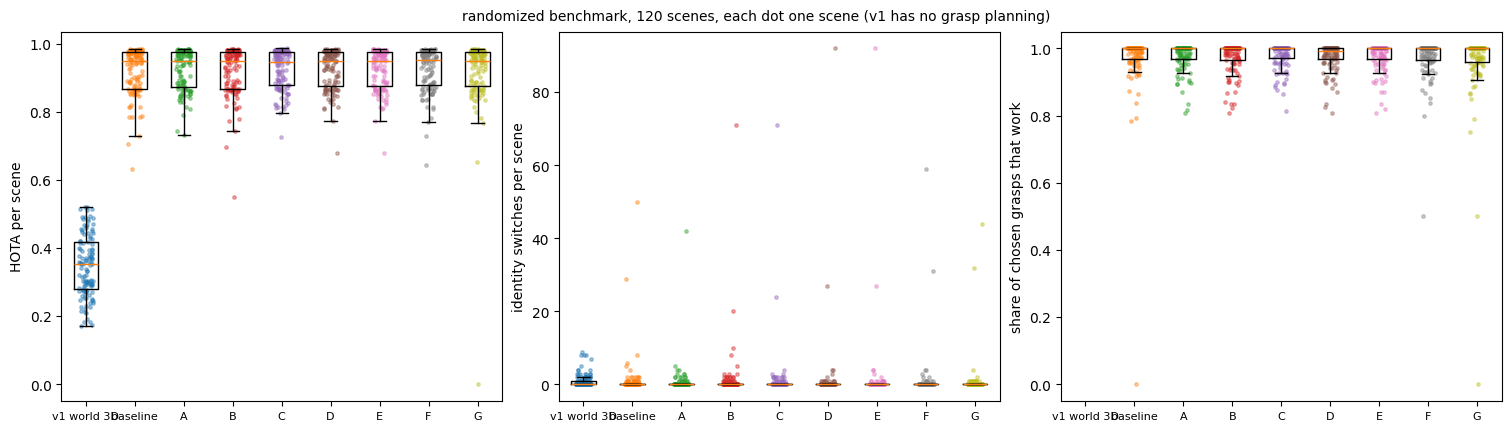

In [ ]:
complete = benchmark[benchmark.config == 'E: complete system'].copy()
complete['targets'] = pd.cut(complete.objects, [2, 4, 6, 7], labels=['3-4', '5-6', '7'])
complete['camera'] = pd.cut(complete.camera_elevation_deg, [0, 35, 60], labels=['25-35 deg down', '35-50 deg down'])
for factor in ['occluder', 'camera_moves', 'look_alikes', 'pick_sized', 'targets', 'camera']:
    print(complete.groupby(factor, observed=True)[['hota_3d', 'idf1', 'id_switches', 'position_rmse_mm', 'chosen_works']].agg(
        lambda s: s.mean()).assign(scenes=complete.groupby(factor, observed=True).size()).round(3))
    print()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), layout='constrained')
names = list(benchmark.config.unique())
for ax, metric, label in zip(axes, ['hota_3d', 'id_switches', 'chosen_works'],
                             ['HOTA per scene', 'identity switches per scene', 'share of chosen grasps that work']):
    values = [benchmark[benchmark.config == name][metric].dropna().values for name in names]
    ax.boxplot(values, showfliers=False)
    for i, v in enumerate(values):
        ax.scatter(i + 1 + jitter_rng.uniform(-0.15, 0.15, len(v)), v, s=6, alpha=0.4)
    ax.set_xticks(range(1, len(names) + 1))
    ax.set_xticklabels([name.split(':')[0] for name in names], fontsize=8)
    ax.set_ylabel(label)
fig.suptitle(f'randomized benchmark, {N_BENCHMARK} scenes, each dot one scene (v1 has no grasp planning)', fontsize=10)
plt.show()

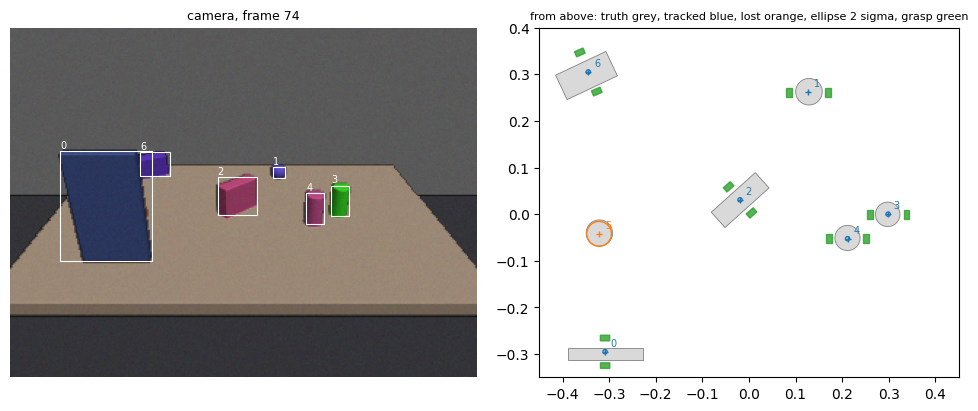

pipeline_demo.gif: 75 frames, 6.8 MB


In [ ]:
demo_k = 1
demo_seq = pick_sequences[demo_k]
demo_pipeline = TabletopPerception(variants[selected], seed=demo_seq['seed'])
demo_rng = np.random.default_rng([demo_seq['seed'], 0])
demo_frames = []
for t in range(N_FRAMES):
    rgb_clean, depth_clean, _ = render_frame(demo_seq, t)
    rgb, depth = apply_sensor_model(rgb_clean, depth_clean, demo_rng)
    objects = demo_pipeline.process_frame(rgb, depth, demo_seq['reported_rot'][t], demo_seq['reported_pos'][t], t * DT, demo_seq['pose_cov'])
    if t % 2 == 0:
        plans = grasp_planner.plan(objects, demo_pipeline.table)
        boxes = {obj['id']: demo_pipeline.last_detections[obj['detection_index']]['box'] for obj in objects if obj['state'] == 'tracked'}
        demo_frames.append((t, rgb, objects, plans, boxes))

fig, (ax_image, ax_top) = plt.subplots(1, 2, figsize=(10, 4), layout='constrained')


def draw(index):
    t, rgb, objects, plans, boxes = demo_frames[index]
    ax_image.clear()
    ax_top.clear()
    ax_image.imshow(rgb)
    for track_id, (u0, v0, u1, v1) in boxes.items():
        ax_image.add_patch(plt.Rectangle((u0, v0), u1 - u0, v1 - v0, fill=False, color='white', lw=0.8))
        ax_image.text(u0, v0 - 2, str(track_id), color='white', fontsize=7)
    ax_image.set_title(f'camera, frame {t}', fontsize=9)
    ax_image.axis('off')
    for obj in demo_seq['objects']:
        shape = true_footprint(obj, t)
        if shape['kind'] == 'rect':
            ax_top.fill(*rect_corners(shape)[0].T, color='0.85', ec='0.5', lw=0.6)
        else:
            ax_top.add_patch(plt.Circle(shape['centre'], shape['radius'], color='0.85', ec='0.5', lw=0.6))
    for obj in objects:
        colour = 'tab:blue' if obj['state'] == 'tracked' else 'tab:orange'
        values, vectors = np.linalg.eigh(obj['covariance'][:2, :2])
        angle = np.degrees(np.arctan2(vectors[1, 1], vectors[0, 1]))
        ax_top.add_patch(Ellipse(obj['position'][:2], *(4 * np.sqrt(values[::-1])), angle=angle, fill=False, color=colour, lw=1))
        ax_top.plot(*obj['position'][:2], '+', color=colour, ms=5)
        ax_top.text(obj['position'][0] + 0.012, obj['position'][1] + 0.012, str(obj['id']), fontsize=7, color=colour)
        feasible = [c for c in plans.get(obj['id'], []) if c['feasible']]
        if feasible:
            best = max(feasible, key=lambda c: c['capture_probability'])
            for part in gripper_parts(best['tcp'][:2], best['tcp'][2], best['closing_angle'], best['opening'], grasp_planner.gripper)[:2]:
                ax_top.fill(*rect_corners(part)[0].T, color='tab:green', alpha=0.8)
    ax_top.set_xlim(-0.45, 0.45)
    ax_top.set_ylim(-0.35, 0.4)
    ax_top.set_aspect('equal')
    ax_top.set_title('from above: truth grey, tracked blue, lost orange, ellipse 2 sigma, grasp green', fontsize=8)


demo = FuncAnimation(fig, draw, frames=len(demo_frames))
demo.save('pipeline_demo.gif', writer=PillowWriter(fps=7), dpi=70)
draw(len(demo_frames) // 2)
plt.show()
print(f"pipeline_demo.gif: {len(demo_frames)} frames, {Path('pipeline_demo.gif').stat().st_size / 1e6:.1f} MB")

In [ ]:
REACH_TOP_K = 4
rows = []
wall_s = cpu_s = 0.0
for scenario, seq in [('nominal', heldout_sequences[('nominal', 0)]), ('crowded', heldout_sequences[('crowded', 0)]),
                      ('pick', pick_sequences[0])]:
    pipeline = TabletopPerception(variants[selected], seed=seq['seed'])
    sensor_rng = np.random.default_rng([seq['seed'], 0])
    REACH_CACHE.clear()
    for t in range(N_FRAMES):
        rgb_clean, depth_clean, _ = render_frame(seq, t)
        rgb, depth = apply_sensor_model(rgb_clean, depth_clean, sensor_rng)
        tracing = t >= N_FRAMES - 30
        if tracing:
            tracemalloc.start()
        cpu0, t0 = time.process_time(), time.perf_counter()
        tracked = pipeline.process_frame(rgb, depth, seq['reported_rot'][t], seq['reported_pos'][t], t * DT, seq['pose_cov'])
        t1, cpu1 = time.perf_counter(), time.process_time()
        plans = grasp_planner.plan(tracked, pipeline.table)
        t2 = time.perf_counter()
        for candidates in plans.values():
            offered = [c for c in candidates if c['feasible']][:REACH_TOP_K]
            if offered:
                grasp_reachability(np.array([c['tcp'] for c in offered]), [c['rotation'] for c in offered])
        t3 = time.perf_counter()
        segmenter_ms = sum(pipeline.segmenter.stage_ms.values())
        row = {'scenario': scenario, 'objects': sum(obj['state'] == 'tracked' for obj in tracked), 'traced': tracing,
               **pipeline.segmenter.stage_ms, 'tracking and shape': 1000 * (t1 - t0) - segmenter_ms,
               'perception path': 1000 * (t1 - t0), 'grasp candidates': 1000 * (t2 - t1), 'arm reach': 1000 * (t3 - t2),
               'planning path': 1000 * (t3 - t1), 'traced_peak_mb': np.nan}
        if tracing:
            row['traced_peak_mb'] = tracemalloc.get_traced_memory()[1] / 1e6
            tracemalloc.stop()
        else:
            wall_s += t1 - t0
            cpu_s += cpu1 - cpu0
        rows.append(row)
profile = pd.DataFrame(rows)
perception_columns = ['plane fit', 'segmentation', 'object geometry', 'tracking and shape', 'perception path']
planning_columns = ['grasp candidates', 'arm reach', 'planning path']
timed = profile[~profile.traced]
print(f'perception path in ms with {selected.split(" ")[0]}, {IMG_W}x{IMG_H}')
print(timed.groupby('scenario', sort=False)[perception_columns].quantile([0.5, 0.95, 0.99]).round(2))
print()
print('planning path in ms, beside the perception path')
print(timed.groupby('scenario', sort=False)[planning_columns].quantile([0.5, 0.95, 0.99]).round(2))
print()
for scenario, group in timed.groupby('scenario', sort=False):
    worst = group['perception path'].quantile(0.99)
    plan_frames = int(np.ceil(group['planning path'].quantile(0.99) / (1000 * DT)))
    print(f"{scenario}: {group.objects.mean():.1f} tracked objects per frame. perception 99th percentile {worst:.1f} ms against a "
          f"{1000 * DT:.0f} ms frame period ({'fits' if worst < 1000 * DT else 'does not fit'}). "
          f"a plan is at most {plan_frames} frame{'s' if plan_frames > 1 else ''} old when it is ready")
print(f'cpu time / wall time of the perception path over the timed frames: {cpu_s / wall_s:.2f}')
print(f'peak python-level allocation while processing one frame: {profile.traced_peak_mb.max():.1f} MB '
      '(tracemalloc, not the memory of the whole process)')

perception path in ms with T18, 320x240
               plane fit  segmentation  object geometry  tracking and shape  perception path
scenario                                                                                    
nominal  0.50       6.91         18.90            11.77                2.07            39.77
         0.95       7.17         20.53            12.76                2.32            41.81
         0.99       9.65         23.17            16.99                2.59            48.32
crowded  0.50       6.89         17.77            11.76                2.32            38.90
         0.95       7.28         19.18            12.54                2.50            40.69
         0.99       7.68         19.64            13.37                2.71            41.43
pick     0.50       6.80         20.17            13.64                2.54            43.08
         0.95       7.33         22.24            15.11                2.76            46.56
         0.99       8.22      

In [ ]:
ARM_GAINS = [(4500, 450), (4500, 450), (3500, 350), (3500, 350), (2000, 200), (2000, 200), (2000, 200)]
ARM_LAG = np.array([kv / kp for kp, kv in ARM_GAINS])
ARM_CAPSULES = {4: ((0.0, 0.0, 0.0), (-0.0825, 0.384, 0.0), 0.055), 6: ((0.0, 0.0, -0.02), (0.088, 0.0, 0.0), 0.05)}
ARM_PARKED = PANDA_READY + np.array([np.pi / 2, 0, 0, 0, 0, 0, 0])
FINGER_FORCE = 35.0
OBJECT_DENSITY = 350.0
PAD_FRICTION, OBJECT_FRICTION = 1.5, 0.8


def quaternion_wxyz(rotation):
    x, y, z, w = Rotation.from_matrix(rotation).as_quat()
    return f'{w:.8f} {x:.8f} {y:.8f} {z:.8f}'


def arm_xml(gripper):
    xml = ''
    for i, (xyz, roll) in enumerate(PANDA_JOINT_ORIGINS):
        low, high = PANDA_LIMITS[i]
        xml += (f'<body name="link{i + 1}" pos="{xyz[0]} {xyz[1]} {xyz[2]}" '
                f'quat="{quaternion_wxyz(Rotation.from_euler("x", roll).as_matrix())}" gravcomp="1">'
                '<inertial pos="0 0 0" mass="2.0" diaginertia="0.02 0.02 0.01"/>'
                f'<joint name="joint{i + 1}" type="hinge" axis="0 0 1" range="{low} {high}" damping="2" armature="0.1"/>')
        if i + 1 in ARM_CAPSULES:
            start, end, radius = ARM_CAPSULES[i + 1]
            xml += (f'<geom name="arm{i + 1}" type="capsule" fromto="{" ".join(str(v) for v in start + end)}" size="{radius}" '
                    'contype="2" conaffinity="0"/>')
    finger_z = 0.5 * gripper.pad_height - 0.5 * gripper.finger_length
    palm_z = 0.5 * gripper.pad_height - gripper.finger_length - 0.5 * gripper.palm_height
    xml += (f'<body name="hand" pos="0 0 {FLANGE_TO_TCP}" quat="{quaternion_wxyz(HAND_TRANSFORM[:3, :3])}" gravcomp="1">'
            f'<inertial pos="0 0 {palm_z}" mass="0.7" diaginertia="0.002 0.002 0.002"/><site name="tcp" pos="0 0 0" size="0.004"/>'
            f'<geom name="palm" type="box" pos="0 0 {palm_z}" size="{gripper.palm_along / 2} {gripper.palm_across / 2} '
            f'{gripper.palm_height / 2}" contype="2" conaffinity="0"/>')
    for name, sign in [('left', -1), ('right', 1)]:
        xml += (f'<body name="finger_{name}" pos="0 {sign * gripper.finger_thickness / 2} {finger_z}" gravcomp="1">'
                '<inertial pos="0 0 0" mass="0.05" diaginertia="1e-5 1e-5 1e-5"/>'
                f'<joint name="finger_{name}" type="slide" axis="0 {sign} 0" range="0 {gripper.max_opening / 2 + 0.002}" '
                'damping="20" armature="0.01"/>'
                f'<geom name="pad_{name}" type="box" size="{gripper.finger_width / 2} {gripper.finger_thickness / 2} '
                f'{gripper.finger_length / 2}" contype="2" conaffinity="0" friction="{PAD_FRICTION} 0.05 0.001" condim="4" '
                'solref="0.004 1"/></body>')
    return xml + '</body>' * 8


def physics_scene_xml(objects, gripper, friction):
    bodies = ''
    for k, obj in enumerate(objects):
        position = obj['path'][0]
        yaw = obj['yaw'] if obj['kind'] == 'box' else 0.0
        if obj['kind'] == 'box':
            shape = f'type="box" size="{obj["size"][0]} {obj["size"][1]} {obj["size"][2]}"'
        elif obj['kind'] == 'cylinder':
            shape = f'type="cylinder" size="{obj["size"][0]} {obj["size"][1]}"'
        else:
            shape = f'type="sphere" size="{obj["size"][0]}"'
        priority = 1 if friction[k] < OBJECT_FRICTION else 0
        bodies += (f'<body name="object{k}" pos="{position[0]} {position[1]} {position[2]}" '
                   f'quat="{quaternion_wxyz(Rotation.from_euler("z", yaw).as_matrix())}"><freejoint name="object{k}"/>'
                   f'<geom name="object{k}" {shape} density="{OBJECT_DENSITY}" friction="{friction[k]} 0.02 0.001" '
                   f'priority="{priority}" condim="4" solref="0.004 1" contype="1" conaffinity="3"/></body>')
    actuators = ''.join(f'<position name="arm{i + 1}" joint="joint{i + 1}" kp="{kp}" kv="{kv}" '
                        f'ctrlrange="{PANDA_LIMITS[i, 0]} {PANDA_LIMITS[i, 1]}"/>' for i, (kp, kv) in enumerate(ARM_GAINS))
    actuators += ''.join(f'<position name="grip_{name}" joint="finger_{name}" kp="600" kv="30" '
                         f'ctrlrange="0 {gripper.max_opening / 2}" forcerange="{-FINGER_FORCE} {FINGER_FORCE}"/>'
                         for name in ['left', 'right'])
    base_rotation = Rotation.from_euler('z', ARM_BASE_YAW).as_matrix()
    return f'''<mujoco model="tabletop">
  <compiler angle="radian"/>
  <option timestep="0.002" integrator="implicitfast" cone="elliptic" impratio="10" noslip_iterations="2"/>
  <worldbody>
    <geom name="table" type="box" pos="{TABLE_CENTER[0]} {TABLE_CENTER[1]} {TABLE_CENTER[2]}"
          size="{TABLE_HALF_SIZE[0]} {TABLE_HALF_SIZE[1]} {TABLE_HALF_SIZE[2]}" friction="{OBJECT_FRICTION} 0.02 0.001"
          contype="1" conaffinity="3"/>
    <body name="arm_base" pos="{ARM_BASE_IN_TABLE[0]} {ARM_BASE_IN_TABLE[1]} {ARM_BASE_IN_TABLE[2]}"
          quat="{quaternion_wxyz(base_rotation)}">
      {arm_xml(gripper)}
    </body>
    {bodies}
  </worldbody>
  <actuator>{actuators}</actuator>
</mujoco>'''


class TabletopPhysics:
    def __init__(self, objects, gripper, friction=None):
        self.objects, self.gripper = objects, gripper
        friction = [OBJECT_FRICTION] * len(objects) if friction is None else friction
        self.model = mujoco.MjModel.from_xml_string(physics_scene_xml(objects, gripper, friction))
        self.data = mujoco.MjData(self.model)
        self.arm_address = [self.model.joint(f'joint{i + 1}').qposadr[0] for i in range(7)]
        self.finger_address = [self.model.joint(f'finger_{name}').qposadr[0] for name in ['left', 'right']]
        self.data.qpos[self.arm_address] = ARM_PARKED
        self.data.qpos[self.finger_address] = gripper.max_opening / 2
        self.data.ctrl[:7] = ARM_PARKED
        self.data.ctrl[7:] = gripper.max_opening / 2
        mujoco.mj_forward(self.model, self.data)
        self.robot_geoms = {self.model.geom(name).id for name in ['palm', 'pad_left', 'pad_right'] + [f'arm{i}' for i in ARM_CAPSULES]}

    @property
    def time(self):
        return self.data.time

    def step(self):
        mujoco.mj_step(self.model, self.data)

    def arm_joints(self):
        return self.data.qpos[self.arm_address].copy()

    def command_arm(self, q, velocity=None):
        self.data.ctrl[:7] = q if velocity is None else q + ARM_LAG * velocity

    def command_gripper(self, opening):
        self.data.ctrl[7:] = 0.5 * opening

    def gripper_opening(self):
        return float(self.data.qpos[self.finger_address].sum())

    def tcp(self):
        site = self.data.site('tcp')
        return site.xpos.copy(), site.xmat.reshape(3, 3).copy()

    def object_pose(self, k):
        body = self.data.body(f'object{k}')
        return body.xpos.copy(), body.xmat.reshape(3, 3).copy()

    def move_object(self, k, position, yaw=None):
        address = self.model.joint(f'object{k}').qposadr[0]
        velocity = self.model.joint(f'object{k}').dofadr[0]
        self.data.qpos[address:address + 3] = position
        if yaw is not None:
            x, y, z, w = Rotation.from_euler('z', yaw).as_quat()
            self.data.qpos[address + 3:address + 7] = [w, x, y, z]
        self.data.qvel[velocity:velocity + 6] = 0.0
        mujoco.mj_forward(self.model, self.data)

    def robot_contacts(self):
        touched = set()
        for contact in self.data.contact[:self.data.ncon]:
            if contact.geom1 in self.robot_geoms or contact.geom2 in self.robot_geoms:
                other = contact.geom2 if contact.geom1 in self.robot_geoms else contact.geom1
                robot = contact.geom1 if contact.geom1 in self.robot_geoms else contact.geom2
                touched.add((self.model.geom(robot).name, self.model.geom(other).name))
        return touched

    def object_contacts(self, k):
        own = self.model.geom(f'object{k}').id
        touched = set()
        for contact in self.data.contact[:self.data.ncon]:
            if own in (contact.geom1, contact.geom2):
                name = self.model.geom(contact.geom2 if contact.geom1 == own else contact.geom1).name
                if name.startswith('object'):
                    touched.add(name)
        return touched


if mujoco is not None:
    check_world = TabletopPhysics([], ParallelGripper())
    base_to_world = np.linalg.inv(table_to_base())
    check_rng = np.random.default_rng(3)
    worst = 0.0
    for q in check_rng.uniform(PANDA_LIMITS[:, 0], PANDA_LIMITS[:, 1], size=(50, 7)):
        check_world.data.qpos[check_world.arm_address] = q
        mujoco.mj_forward(check_world.model, check_world.data)
        expected = base_to_world @ panda_forward(q[None])[0][0]
        position, rotation = check_world.tcp()
        worst = max(worst, np.linalg.norm(position - expected[:3, 3]), np.abs(rotation - expected[:3, :3]).max())
    print(f'MuJoCo {mujoco.__version__}: hand pose of the physics model against the kinematic model over 50 random postures, '
          f'largest difference {worst:.1e}')
    assert worst < 1e-6
else:
    print('mujoco is not installed (pip install mujoco), the physics cells are skipped')

MuJoCo 4.0.1: hand pose of the physics model against the kinematic model over 50 random postures, largest difference 2.4e-09


In [ ]:
GRIPPER_COLOR = np.array([0.2, 0.2, 0.22])
WRIST_RADIUS, WRIST_HALF_LENGTH = 0.045, 0.12


def physics_view(world, cam_rot, cam_pos):
    shown = []
    for k, obj in enumerate(world.objects):
        position, rotation = world.object_pose(k)
        view = dict(obj, path=position[None])
        if obj['kind'] != 'sphere':
            if rotation[2, 2] > 0.985:
                view['yaw'] = np.arctan2(rotation[1, 0], rotation[0, 0])
            else:
                half = obj['size'] if obj['kind'] == 'box' else np.array([obj['size'][0], obj['size'][0], obj['size'][1]])
                view.update(kind='box', size=np.abs(rotation) @ half, yaw=0.0)
        shown.append(view)
    tcp, hand = world.tcp()
    if hand[2, 2] < -0.9:
        gripper = world.gripper
        yaw = np.arctan2(hand[1, 0], hand[0, 0])
        part = {'color': GRIPPER_COLOR, 'yaw': yaw, 'is_target': False}
        for name in ['left', 'right']:
            shown.append(dict(part, kind='box', path=world.data.body(f'finger_{name}').xpos[None].copy(),
                              size=0.5 * np.array([gripper.finger_width, gripper.finger_thickness, gripper.finger_length])))
        palm_top = 0.5 * gripper.pad_height - gripper.finger_length - gripper.palm_height
        shown.append(dict(part, kind='box', path=(tcp + hand[:, 2] * (palm_top + 0.5 * gripper.palm_height))[None],
                          size=0.5 * np.array([gripper.palm_along, gripper.palm_across, gripper.palm_height])))
        shown.append(dict(part, kind='cylinder', path=(tcp + hand[:, 2] * (palm_top - WRIST_HALF_LENGTH))[None],
                          size=np.array([WRIST_RADIUS, WRIST_HALF_LENGTH])))
    return {'objects': shown, 'cam_rot': cam_rot[None], 'cam_pos': cam_pos[None]}


def robot_mask(depth, cam_rot, cam_pos, world, padding=0.015, held=None):
    tcp, hand = world.tcp()
    points = (SIM_CAMERA.ray_grid * depth[..., None]) @ cam_rot.T + cam_pos
    local = (points - tcp) @ hand
    gripper = world.gripper
    finger_top = 0.5 * gripper.pad_height - gripper.finger_length
    wrist_top = finger_top - gripper.palm_height - 2 * WRIST_HALF_LENGTH
    column = (np.abs(local[..., 0]) < 0.5 * gripper.palm_along + padding) & (np.abs(local[..., 1]) < 0.5 * gripper.palm_across + padding) \
        & (local[..., 2] > wrist_top - padding) & (local[..., 2] < finger_top + padding)
    finger_offset = 0.5 * world.gripper_opening() + 0.5 * gripper.finger_thickness
    fingers = (np.abs(local[..., 0]) < 0.5 * gripper.finger_width + padding) \
        & (np.abs(np.abs(local[..., 1]) - finger_offset) < 0.5 * gripper.finger_thickness + padding) \
        & (local[..., 2] > finger_top - padding) & (local[..., 2] < 0.5 * gripper.pad_height + padding)
    carried = np.zeros(depth.shape, dtype=bool)
    if held is not None:
        radius, top_above_tcp, height = held
        above_tcp = points[..., 2] - tcp[2]
        carried = (np.linalg.norm(points[..., :2] - tcp[:2], axis=-1) < radius + padding) \
            & (above_tcp < top_above_tcp + padding) & (above_tcp > top_above_tcp - height - padding)
    return (depth > 0) & (column | fingers | carried)

In [ ]:
TRANSIT_HEIGHT = 0.32           
MOVE_SPEED, APPROACH_SPEED = 0.35, 0.08
HOLDING_OPENING = 0.004         
GRIP_WIDTH_TOLERANCE = 0.015    
STALE_DISTANCE = 0.015          
PLACE_TOLERANCE = 0.03
PLACE_CLEARANCE = 0.05
UNKNOWN_RADIUS = 0.05
RETRY_RADIUS = 0.06            
MIN_CAPTURE = 0.5                
PLANNING_BUDGET = 0.5           
CARRY_CLEARANCE = 0.03          
BASE_TO_WORLD = np.linalg.inv(table_to_base())
PARKED_HAND = BASE_TO_WORLD @ panda_forward(ARM_PARKED[None])[0][0]


def spot_seen_free(depth, camera, cam_rot, cam_pos, table, spot, radius, sigmas=3.0, min_tolerance=0.003, plane_tolerance=0.006,
                   min_seen=0.9, max_blocked=0.01, max_height=0.05):
    normal = table['normal']
    up = normal if normal[2] > 0 else -normal
    centre = np.array([spot[0], spot[1], table['point'][2] - (up[0] * (spot[0] - table['point'][0]) + up[1] * (spot[1] - table['point'][1])) / up[2]])
    across = np.cross(up, [1.0, 0.0, 0.0])
    across = across / np.linalg.norm(across)
    along = np.cross(up, across)
    angles = np.linspace(0, 2 * np.pi, 24, endpoint=False)
    rim = centre + radius * (np.cos(angles)[:, None] * across + np.sin(angles)[:, None] * along)
    outline = (np.vstack([rim, rim + max_height * up]) - cam_pos) @ cam_rot
    if (outline[:, 2] < 0.1).any():
        return False
    u = camera.fx * outline[:, 0] / outline[:, 2] + camera.cx
    v = camera.fy * outline[:, 1] / outline[:, 2] + camera.cy
    if u[:24].min() < 0 or v[:24].min() < 0 or u[:24].max() > camera.width - 1 or v[:24].max() > camera.height - 1:
        return False
    rows, cols = np.mgrid[max(int(v.min()), 0):min(int(np.ceil(v.max())), camera.height - 1) + 1,
                          max(int(u.min()), 0):min(int(np.ceil(u.max())), camera.width - 1) + 1]
    rays = np.stack([(cols - camera.cx) / camera.fx, (rows - camera.cy) / camera.fy, np.ones(rows.shape)], axis=-1) @ cam_rot.T
    expected = ((centre - cam_pos) @ up) / (rays @ up)
    on_disc = np.linalg.norm(cam_pos + expected[..., None] * rays - centre, axis=-1) <= radius
    if on_disc.sum() < 10:
        return False
    measured = depth[rows, cols]
    returned = np.isfinite(measured) & (measured > 0)
    if returned[on_disc].mean() < min_seen:
        return False
    seen_points = cam_pos + np.where(returned, measured, 0.0)[..., None] * rays
    height = (seen_points - centre) @ up
    level = np.median(height[on_disc & returned])
    if abs(level) > plane_tolerance:
        return False
    noise = 1.4826 * np.median(np.abs(height[on_disc & returned] - level))
    tolerance = max(min_tolerance, sigmas * noise)
    table_seen = on_disc & returned & (np.abs(height - level) <= tolerance)
    foot = seen_points - (height - level)[..., None] * up
    above_disc = returned & (np.linalg.norm(foot - centre, axis=-1) <= radius)
    raised = above_disc & (height - level > tolerance)
    seen = (table_seen | (on_disc & raised)).sum() / on_disc.sum()
    touching = (raised[:, 1:] & raised[:, :-1]).any() or (raised[1:] & raised[:-1]).any()
    return bool(seen >= min_seen and not touching and raised.sum() <= max_blocked * on_disc.sum())


MIN_CONFIDENCE = 0.5


def segment_call(obj):
    confidence = obj.get('confidence', np.nan)
    if np.isfinite(confidence) and confidence < MIN_CONFIDENCE:
        return 'uncertain'
    if obj.get('visible_share', 1.0) > 1 / TRUNCATED_AREA_RATIO:
        return 'possible merge'
    return 'one object'


def plan_is_stale(candidate, shift, elapsed, remaining, min_capture, max_shift, shift_std):
    drifting = np.linalg.norm(shift[:2]) > 3 * shift_std
    predicted = shift * (1.0 + remaining / max(elapsed, 1e-3)) if drifting else shift
    return bool(np.linalg.norm(shift[:2]) > max_shift or held_capture(candidate, predicted) < min_capture)


def shift_noise(candidate, track):
    return np.sqrt(np.max(candidate['spread']) ** 2 + np.linalg.eigvalsh(track['covariance'][:2, :2]).max())


def sweep_obstacles(objects, table, ignore_ids, unknown_radius, n_sigma=2.0):
    obstacles = []
    for obj in objects:
        if obj['id'] in ignore_ids:
            continue
        centre_height = (obj['position'] - table['point']) @ table['normal']
        radius = 0.5 * np.hypot(*obj['size'][:2]) if 'size' in obj else unknown_radius
        top = obj['size'][2] if 'size' in obj else 2 * centre_height
        spread = np.sqrt(np.linalg.eigvalsh(obj['covariance'][:2, :2]).max())
        obstacles.append({'id': obj['id'], 'xy': obj['position'][:2], 'radius': radius + n_sigma * spread, 'top': top})
    return obstacles


def transit_height(start, goal, body, obstacles, clearance=0.03, minimum=0.0):
    route = np.asarray(goal[:2], dtype=float) - np.asarray(start[:2], dtype=float)
    height = minimum
    for obstacle in obstacles:
        share = np.clip((obstacle['xy'] - start[:2]) @ route / max(route @ route, 1e-12), 0.0, 1.0)
        gap = np.linalg.norm(start[:2] + share * route - obstacle['xy'])
        if gap < body['radius'] + obstacle['radius'] + clearance:
            height = max(height, obstacle['top'] + clearance + body['below'])
    return height


def swept_clear(path, body, obstacles, table, clearance=0.02):
    heights = (np.asarray(path) - table['point']) @ table['normal']
    for obstacle in obstacles:
        near = np.linalg.norm(np.asarray(path)[:, :2] - obstacle['xy'], axis=1) < body['radius'] + obstacle['radius'] + clearance
        low = heights - body['below'] < obstacle['top'] + clearance
        if (near & low).any():
            return obstacle['id']
    return None


def looks_like(obj, size):
    return 'size' in obj and bool(np.all(np.abs(obj['size'] - size) < np.maximum(0.015, 0.25 * size)))


class PickPlaceRun:
    def __init__(self, world, pipeline, planner, camera, reported_camera, rng, keep_frames=False):
        self.world, self.pipeline, self.planner, self.rng = world, pipeline, planner, rng
        self.cam_rot, self.cam_pos = camera
        self.reported_rot, self.reported_pos = reported_camera
        self.sensor_rng = np.random.default_rng(rng.integers(2 ** 32))
        self.q = ARM_PARKED.copy()
        self.objects = []
        self.holding = None
        self.events = {'empty grasps': 0, 'drops': 0, 'stale plans': 0, 'place spot changes': 0, 'lost from view': 0,
                       'wrong grip width': 0, 'planning over budget': 0, 'carry path blocked': 0}
        self.contact_ticks, self.touched = 0, set()
        self.requested = None
        self.grasp_log = []
        self.moved_by_hand = set()
        self.carried_ids = set()
        self.top_above_tcp = 0.0
        self.decline_reason = ''
        self.held_shape = None
        self.planning_seconds, self.frame_seconds = [], []
        self.frames = [] if keep_frames else None

    def tick(self, motion=None):
        allowed = {'table', f'object{self.requested}'}
        unintended = set()
        step = self.world.model.opt.timestep
        for _ in range(int(round(DT / step))):
            if motion is not None:
                now = self.world.time
                self.world.command_arm(motion(now), (motion(now + step) - motion(now - step)) / (2 * step))
            self.world.step()
            unintended |= {(part, other) for part, other in self.world.robot_contacts()
                           if other not in allowed or (other == 'table' and not part.startswith('pad'))}
            if self.requested is not None:
                unintended |= {('carried object', other) for other in self.world.object_contacts(self.requested)}
        self.contact_ticks += bool(unintended)
        self.touched |= unintended
        rgb, depth, _ = render_frame(physics_view(self.world, self.cam_rot, self.cam_pos), 0)
        rgb, depth = apply_sensor_model(rgb, depth, self.sensor_rng)
        depth[robot_mask(depth, self.cam_rot, self.cam_pos, self.world, held=self.held_shape)] = 0.0
        started = time.perf_counter()
        self.objects = self.pipeline.process_frame(rgb, depth, self.reported_rot, self.reported_pos, self.world.time)
        self.last_depth = depth
        self.frame_seconds.append(time.perf_counter() - started)
        if self.holding is not None:
            tcp = self.world.tcp()[0]
            tcp_height = self.height_above_table(tcp)
            self.carried_ids |= {obj['id'] for obj in self.objects if obj['state'] == 'tracked' and 'size' in obj
                                 and np.linalg.norm(obj['position'][:2] - tcp[:2]) < 0.08
                                 and abs(obj['size'][2] - tcp_height - self.top_above_tcp) < 0.03}
        else:
            self.carried_ids &= {obj['id'] for obj in self.objects if obj['state'] != 'tracked'}
        if self.frames is not None:
            self.frames.append(rgb)

    def height_above_table(self, point):
        table = self.pipeline.table
        return (point - table['point']) @ table['normal']

    def observe(self, n_frames):
        for _ in range(n_frames):
            self.tick()

    def hand_pose(self):
        pose = BASE_TO_WORLD @ panda_forward(self.q[None])[0][0]
        return pose[:3, 3], pose[:3, :3]

    def plan_line(self, target, rotation=None):
        started = time.perf_counter()
        start, start_rotation = self.hand_pose()
        if rotation is None:
            rotation = start_rotation
        elif np.trace(start_rotation.T @ rotation @ np.diag([-1.0, -1.0, 1.0])) > np.trace(start_rotation.T @ rotation):
            rotation = rotation @ np.diag([-1.0, -1.0, 1.0])
        turn = Rotation.from_matrix(start_rotation.T @ rotation).magnitude()
        n_points = max(int(np.ceil(np.linalg.norm(target - start) / 0.01)), int(np.ceil(turn / np.deg2rad(8))), 1)
        between = Slerp([0.0, 1.0], Rotation.from_matrix(np.stack([start_rotation, rotation])))
        to_base = table_to_base()
        path, q = [], self.q
        for share in np.arange(1, n_points + 1) / n_points:
            goal = np.eye(4)
            goal[:3, :3] = to_base[:3, :3] @ between(share).as_matrix()
            goal[:3, 3] = to_base[:3, :3] @ (start + share * (target - start)) + to_base[:3, 3]
            solved, _, solution = panda_ik(goal[None], q[None])
            if not solved[0]:
                path = None
                break
            q = solution[0]
            path.append(q)
        self.planning_seconds.append(time.perf_counter() - started)
        self.events['planning over budget'] += self.planning_seconds[-1] > PLANNING_BUDGET
        return path

    def follow(self, path, speed, watch=None):
        duration = max(0.01 * len(path) / speed, 0.4)
        start_time = self.world.time
        points = np.vstack([self.q, path])

        def motion(now):
            share = np.clip((now - start_time) / duration, 0.0, 1.0)
            along = (3 * share ** 2 - 2 * share ** 3) * (len(points) - 1)
            i = min(int(along), len(points) - 2)
            return points[i] + (along - i) * (points[i + 1] - points[i])

        while self.world.time < start_time + duration:
            self.tick(motion)
            reason = watch() if watch is not None else ''
            if reason:
                self.q = self.world.arm_joints()
                self.world.command_arm(self.q)
                return reason
        self.q = points[-1]
        self.world.command_arm(self.q)
        return ''

    def go(self, target, rotation=None, speed=MOVE_SPEED, watch=None):
        path = self.plan_line(np.asarray(target, dtype=float), rotation)
        if path is None:
            return 'out of reach'
        return self.follow(path, speed, watch)

    def grip(self, opening, n_frames=9):
        self.world.command_gripper(opening)
        self.observe(n_frames)

    def retreat(self):
        self.holding, self.held_shape = None, None
        self.grip(self.world.gripper.max_opening, 4)
        position, _ = self.hand_pose()
        self.go([position[0], position[1], TRANSIT_HEIGHT])
        self.go(PARKED_HAND[:3, 3], PARKED_HAND[:3, :3])

    def tracked(self, track_id=None, near=None, within=0.04):
        tracked = [obj for obj in self.objects if obj['state'] == 'tracked']
        if track_id is not None:
            return next((obj for obj in tracked if obj['id'] == track_id), None)
        if not tracked:
            return None
        nearest = min(tracked, key=lambda obj: np.linalg.norm(obj['position'][:2] - near[:2]))
        return nearest if np.linalg.norm(nearest['position'][:2] - near[:2]) < within else None

    def plan_grasp(self, track_id):
        call = segment_call(self.tracked(track_id))
        if call != 'one object':
            self.decline_reason = f'segment is {call}'
            return None, 'no grasp offered'
        started = time.perf_counter()
        plans = self.planner.plan(self.objects, self.pipeline.table, target_ids=[track_id])
        offered = [c for c in plans.get(track_id, []) if c['feasible'] and c['capture_probability'] >= MIN_CAPTURE][:REACH_TOP_K]
        chosen = None
        if offered:
            reachable, _ = grasp_reachability(np.array([c['tcp'] for c in offered]), [c['rotation'] for c in offered])
            chosen = next((c for c, ok in zip(offered, reachable) if ok), None)
        self.planning_seconds.append(time.perf_counter() - started)
        self.events['planning over budget'] += self.planning_seconds[-1] > PLANNING_BUDGET
        if chosen is None:
            if not offered:
                candidates = plans.get(track_id, [])
                self.decline_reason = candidates[0]['reason'] if candidates and candidates[0]['reason'] else 'capture probability too low'
            return None, 'out of reach' if offered else 'no grasp offered'
        return chosen, ''

    def spot_blocked(self, spot, own_radius, ignore_id=None):
        for obj in self.objects:
            if obj['id'] == ignore_id or obj['id'] in self.carried_ids:
                continue
            radius = 0.5 * max(obj['size'][:2]) if 'size' in obj else UNKNOWN_RADIUS
            if np.linalg.norm(obj['position'][:2] - spot) < own_radius + radius + PLACE_CLEARANCE:
                return True
        return False

    def free_spot(self, own_radius, away_from, ignore_id=None):
        for _ in range(300):
            spot = self.rng.uniform(WORK_REGION[0], WORK_REGION[1])
            if np.linalg.norm(spot - away_from[:2]) > 0.12 and not self.spot_blocked(spot, own_radius, ignore_id) \
                    and spot_seen_free(self.last_depth, SIM_CAMERA, self.reported_rot, self.reported_pos, self.pipeline.table,
                                       spot, own_radius + PLACE_CLEARANCE):
                return spot
        return None

    def attempt(self, track_id, disturb=None):
        target = self.tracked(track_id)
        if target is None:
            return 'lost from view'
        grasp, reason = self.plan_grasp(track_id)
        if grasp is None:
            return reason
        planned_at, planned_time = target['position'].copy(), self.world.time
        planned_size = target['size'].copy()
        tcp, rotation = grasp['tcp'], grasp['rotation']
        self.world.command_gripper(grasp['opening'])
        above = np.array([tcp[0], tcp[1], TRANSIT_HEIGHT])
        if self.go(above, rotation) or self.go(grasp['pre_grasp'], rotation):
            return 'out of reach'
        if disturb is not None:
            disturb('at pre-grasp', self)
        self.observe(6)
        target = self.tracked(track_id)
        waited = 0
        while target is None and waited < 15:
            self.observe(1)
            target = self.tracked(track_id)
            waited += 1
        if target is None and self.tracked(near=planned_at, within=0.10) is None:
            self.events['lost from view'] += 1
            return 'lost from view'
        remaining = np.linalg.norm(grasp['pre_grasp'] - tcp) / APPROACH_SPEED + 9 * DT
        if target is None or plan_is_stale(grasp, target['position'] - planned_at, self.world.time - planned_time, remaining,
                                           MIN_CAPTURE, STALE_DISTANCE, shift_noise(grasp, target)):
            self.events['stale plans'] += 1
            return 'stale plan'
        if self.go(tcp, rotation, APPROACH_SPEED):
            return 'out of reach'
        real = {'objects': physics_view(self.world, self.cam_rot, self.cam_pos)['objects'][:len(self.world.objects)]}
        self.grasp_log.append({'geometric check': grasp_outcome(grasp, real, 0, self.requested, self.world.gripper),
                               'capture_probability': grasp['capture_probability'], 'held': False})
        self.holding = self.requested
        self.carried_ids.add(track_id)
        self.top_above_tcp = planned_size[2] - self.height_above_table(tcp)
        self.grip(0.0)
        if self.world.gripper_opening() >= HOLDING_OPENING and abs(self.world.gripper_opening() - grasp['grip_width']) > GRIP_WIDTH_TOLERANCE:
            self.events['wrong grip width'] += 1
            self.holding = None
            return 'wrong grip width'
        self.held_shape = (0.5 * np.hypot(*planned_size[:2]), self.top_above_tcp, planned_size[2])
        if self.world.gripper_opening() < HOLDING_OPENING:
            self.events['empty grasps'] += 1
            return 'empty grasp'

        def dropped():
            return 'dropped' if self.world.gripper_opening() < HOLDING_OPENING else ''
        
        gripper = self.planner.gripper
        body = {'radius': max(0.5 * np.hypot(*planned_size[:2]), 0.5 * np.hypot(gripper.palm_along, gripper.palm_across)) + 0.01,
                'below': self.height_above_table(tcp)}
        lift_to = TRANSIT_HEIGHT
        if self.goal is not None:
            obstacles = sweep_obstacles(self.objects, self.pipeline.table, self.carried_ids | {track_id}, UNKNOWN_RADIUS)
            lift_to = max(TRANSIT_HEIGHT, self.pipeline.table['point'][2]
                          + transit_height(tcp, self.goal, body, obstacles, CARRY_CLEARANCE))
        above = np.array([tcp[0], tcp[1], lift_to])
        reason = self.go(above, rotation, 0.5 * MOVE_SPEED, dropped)
        if reason:
            self.events['drops'] += reason == 'dropped'
            return reason
        self.grasp_log[-1]['held'] = True
        if disturb is not None:
            disturb('lifted', self)
        own_radius = 0.5 * max(planned_size[:2])
        self.observe(6)
        for check in range(2):
            if self.spot_blocked(self.goal, own_radius, track_id):
                self.events['place spot changes'] += 1
                self.goal = self.free_spot(own_radius, tcp, track_id)
                if self.goal is None:
                    self.goal, self.put_back = tcp[:2].copy(), True
            if check == 0:
                position, _ = self.hand_pose()
                obstacles = sweep_obstacles(self.objects, self.pipeline.table, self.carried_ids | {track_id}, UNKNOWN_RADIUS)
                needed = self.pipeline.table['point'][2] + transit_height(position, self.goal, body, obstacles, CARRY_CLEARANCE)
                if needed > position[2] + 0.001:
                    reason = self.go([position[0], position[1], needed], rotation, 0.5 * MOVE_SPEED, dropped)
                    if reason:
                        self.events['drops'] += reason == 'dropped'
                        return reason
                    position, _ = self.hand_pose()
                across = np.array([self.goal[0], self.goal[1], position[2]])
                if swept_clear(np.linspace(position, across, 30), body, obstacles, self.pipeline.table, 0.5 * CARRY_CLEARANCE) is not None:
                    self.events['carry path blocked'] += 1
                    self.go([tcp[0], tcp[1], tcp[2] + 0.004], rotation, APPROACH_SPEED)
                    return 'carry path blocked'
                reason = self.go(across, rotation, MOVE_SPEED, dropped)
                if reason:
                    self.events['drops'] += reason == 'dropped'
                    return reason
                self.observe(3)
        reason = self.go([self.goal[0], self.goal[1], tcp[2] + 0.004], rotation, APPROACH_SPEED, dropped)
        if reason:
            self.events['drops'] += reason == 'dropped'
            return reason
        return 'released'

    def run(self, requested, max_tries=5, disturb=None):
        self.requested = requested
        start_positions = [self.world.object_pose(k)[0] for k in range(len(self.world.objects))]
        self.observe(25)
        track = self.tracked(near=self.world.object_pose(requested)[0])
        result = {'outcome': 'object not tracked', 'tries': 0, 'verified': False, 'placement_error': np.nan}
        self.goal, self.put_back = None, False
        if track is not None and 'size' in track:
            requested_size = track['size'].copy()
            self.goal = self.free_spot(0.5 * max(track['size'][:2]), track['position'], track['id'])
            result['outcome'] = 'no free place'
        while track is not None and self.goal is not None and result['tries'] < max_tries:
            result['tries'] += 1
            status = self.attempt(track['id'], disturb if result['tries'] == 1 else None)
            last_seen = self.world.tcp()[0] if status == 'dropped' else track['position']
            self.retreat()
            self.observe(15)
            result['outcome'] = status
            if status in ('released', 'no grasp offered', 'out of reach'):
                break
            radius = 0.15 if status == 'dropped' else RETRY_RADIUS
            same_id = self.tracked(track['id'])
            if same_id is not None and np.linalg.norm(same_id['position'][:2] - last_seen[:2]) < radius:
                track = same_id
            else:
                track = self.tracked(near=last_seen, within=radius)
            if track is not None and not looks_like(track, requested_size):
                track = None
            if track is None:
                result['outcome'] = 'object lost after ' + status
        truth, rotation = self.world.object_pose(requested)
        if result['outcome'] == 'released':
            result['verified'] = self.tracked(near=self.goal, within=PLACE_TOLERANCE) is not None
            result['placement_error'] = np.linalg.norm(truth[:2] - self.goal)
            upright = self.world.objects[requested]['kind'] == 'sphere' or rotation[2, 2] > 0.95
            result['outcome'] = 'placed' if result['placement_error'] < PLACE_TOLERANCE and upright else 'placed badly'
            if self.put_back:
                result['outcome'] = 'put back, no free place'
        others = [k for k in range(len(self.world.objects)) if k != requested and k not in self.moved_by_hand]
        result.update(self.events, success=result['outcome'] == 'placed',
                      neighbours_displaced=sum(np.linalg.norm(self.world.object_pose(k)[0] - start_positions[k]) > 0.01 for k in others),
                      grasps=self.grasp_log, decline_reason=self.decline_reason, contact_frames=self.contact_ticks, touched=sorted(f'{part} on {other}' for part, other in self.touched),
                      sim_seconds=self.world.time, planning_calls=len(self.planning_seconds),
                      planning_ms_max=1000 * max(self.planning_seconds, default=0.0),
                      planning_ms_total=1000 * sum(self.planning_seconds),
                      perception_ms_p99=1000 * np.quantile(self.frame_seconds, 0.99))
        return result

In [ ]:
STALE_PUSHES = [0.004, 0.008, 0.012, 0.015]
DRIFT_SPEEDS = [0.002, 0.004, 0.006]
PLAN_AGE, TO_GO = 3.0, 0.10 / APPROACH_SPEED + 9 * DT


def moved_sequence(seq, gt_id, t, shift):
    objects = list(seq['objects'])
    objects[gt_id] = dict(objects[gt_id], path=objects[gt_id]['path'].copy())
    objects[gt_id]['path'][t, :2] += shift[:2]
    return dict(seq, objects=objects)


stale_rng = np.random.default_rng(611)
rows = []
for k, seq in pick_sequences.items():
    for t in range(0, N_FRAMES, 10):
        objects = pick_outputs[k][t]
        for obj in objects:
            if obj['state'] != 'tracked' or 'category' not in obj:
                continue
            gt_id = pick_cache[k][t]['detections'][obj['detection_index']]['gt_id']
            if gt_id < 0 or not seq['objects'][gt_id]['is_target']:
                continue
            offered = [c for c in grasp_planner.plan(objects, pick_tables[k][t], [obj['id']])[obj['id']]
                       if c['feasible'] and c['capture_probability'] >= MIN_CAPTURE]
            if not offered or grasp_outcome(offered[0], seq, t, gt_id, grasp_planner.gripper) != 'success':
                continue
            grasp = offered[0]
            width = 'under 4 cm' if grasp['grip_width'] < 0.04 else '4 to 6 cm' if grasp['grip_width'] < 0.06 else '6 cm or more'
            for _ in range(4):
                angle = stale_rng.uniform(0, 2 * np.pi)
                direction = np.array([np.cos(angle), np.sin(angle), 0.0])
                cases = [('pushed', f'{1000 * push:.0f} mm', push, push) for push in STALE_PUSHES]
                cases += [('drifting', f'{1000 * speed:.0f} mm/s', speed * PLAN_AGE, speed * (PLAN_AGE + TO_GO)) for speed in DRIFT_SPEEDS]
                for case, amount, at_check, at_grasp in cases:
                    works = grasp_outcome(grasp, moved_sequence(seq, gt_id, t, at_grasp * direction), t, gt_id, grasp_planner.gripper) == 'success'
                    rows.append({'case': case, 'amount': amount, 'grip width': width, 'works': works,
                                 'fixed limit takes it': at_check <= STALE_DISTANCE,
                                 'rule takes it': not plan_is_stale(grasp, at_check * direction, PLAN_AGE, TO_GO, MIN_CAPTURE, STALE_DISTANCE,
                                                                    shift_noise(grasp, obj))})
stale_check = pd.DataFrame(rows)
stale_summary = {}
for rule in ['fixed limit takes it', 'rule takes it']:
    taken = stale_check[stale_check[rule]]
    stale_summary[rule.replace(' takes it', '')] = {'plans kept': stale_check[rule].mean(),
                                              'kept plans that fail': (~taken.works).mean(),
                                              'refused plans that would work': stale_check[~stale_check[rule]].works.mean()}
print(f"{len(stale_check)} moved grasps from {stale_check.groupby(['case', 'amount']).size().iloc[0]} planned ones on the held-out pick sequences")
print(pd.DataFrame(stale_summary).T.round(3))
grouped = stale_check.groupby(['case', 'amount', 'grip width'], sort=False)
print()
print('share of kept plans that fail, by how far the object moved and how wide the grasp is')
print(pd.DataFrame({'still works': grouped.works.mean(),
                    'fixed limit': grouped.apply(lambda g: (~g.works[g['fixed limit takes it']]).mean() if g['fixed limit takes it'].any() else np.nan),
                    'rule': grouped.apply(lambda g: (~g.works[g['rule takes it']]).mean() if g['rule takes it'].any() else np.nan),
                    'rule keeps': grouped['rule takes it'].mean()}).round(3).to_string())

19292 moved grasps from 2756 planned ones on the held-out pick sequences
             plans kept  kept plans that fail  refused plans that would work
fixed limit       0.857                 0.492                          0.043
rule              0.429                 0.211                          0.180

share of kept plans that fail, by how far the object moved and how wide the grasp is
                              still works  fixed limit   rule  rule keeps
case     amount grip width                                               
pushed   4 mm   4 to 6 cm           0.978        0.022  0.022       1.000
         8 mm   4 to 6 cm           0.781        0.219  0.226       0.783
         12 mm  4 to 6 cm           0.410        0.590  0.048       0.085
         15 mm  4 to 6 cm           0.181        0.819  0.026       0.052
drifting 2 mm/s 4 to 6 cm           0.585        0.415  0.415       1.000
         4 mm/s 4 to 6 cm           0.081        0.919  0.171       0.085
         6 mm/s 4 

/tmp/ipykernel_16/4072857112.py:62: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  'fixed limit': grouped.apply(lambda g: (~g.works[g['fixed limit takes it']]).mean() if g['fixed limit takes it'].any() else np.nan),
/tmp/ipykernel_16/4072857112.py:63: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  'rule': grouped.apply(lambda g: (~g.works[g['rule takes it']]).mean() if g['rule takes it'].any() else np.nan),


In [ ]:
LOW_HEIGHTS = [0.005, 0.010, 0.015, 0.020]
SPOT_RADIUS = 0.03 + PLACE_CLEARANCE


def spot_check_before(depth, camera, cam_rot, cam_pos, table, spot, radius, tolerance=0.02, min_share=0.8):
    normal = table['normal']
    up = normal if normal[2] > 0 else -normal
    centre = np.array([spot[0], spot[1], table['point'][2] - (up[0] * (spot[0] - table['point'][0]) + up[1] * (spot[1] - table['point'][1])) / up[2]])
    across = np.cross(up, [1.0, 0.0, 0.0])
    across = across / np.linalg.norm(across)
    along = np.cross(up, across)
    radii, angles = np.meshgrid(np.linspace(0, radius, 6), np.linspace(0, 2 * np.pi, 16, endpoint=False))
    points = centre + (radii * np.cos(angles)).reshape(-1, 1) * across + (radii * np.sin(angles)).reshape(-1, 1) * along
    in_camera = (points - cam_pos) @ cam_rot
    u = np.round(camera.fx * in_camera[:, 0] / in_camera[:, 2] + camera.cx).astype(int)
    v = np.round(camera.fy * in_camera[:, 1] / in_camera[:, 2] + camera.cy).astype(int)
    inside = (in_camera[:, 2] > 0.1) & (u >= 0) & (u < camera.width) & (v >= 0) & (v < camera.height)
    if inside.mean() < min_share:
        return False
    measured = depth[v[inside], u[inside]]
    return np.mean(np.abs(measured - in_camera[inside, 2]) < tolerance) >= min_share


spot_rng = np.random.default_rng(612)
cam_rot, cam_pos = static_camera()
cam_rot, cam_pos = cam_rot[0], cam_pos[0]
flat_table = {'point': np.zeros(3), 'normal': np.array([0.0, 0.0, 1.0])}
rows = []
for trial in range(30):
    spot = spot_rng.uniform(WORK_REGION[0] + 0.08, WORK_REGION[1] - 0.08)
    half_side = spot_rng.uniform(0.01, 0.025)
    yaw = spot_rng.uniform(0, np.pi)
    toward = (cam_pos[:2] - spot) / np.linalg.norm(cam_pos[:2] - spot)
    for height in [0.0] + LOW_HEIGHTS:
        for place in ['on the spot', 'at its edge', 'partly hidden']:
            if height == 0.0 and place != 'on the spot':
                continue
            shown = []
            if height > 0:
                offset = 0.0 if place != 'at its edge' else SPOT_RADIUS
                centre = spot + offset * np.array([np.cos(yaw), np.sin(yaw)])
                shown.append({'kind': 'box', 'size': np.array([half_side, half_side, 0.5 * height]), 'yaw': yaw, 'color': np.array([0.6, 0.5, 0.4]),
                              'is_target': True, 'path': np.append(centre, 0.5 * height)[None]})
            if place == 'partly hidden':
                shown.append({'kind': 'box', 'size': np.array([0.03, 0.05, 0.09]), 'yaw': np.arctan2(toward[1], toward[0]),
                              'color': np.array([0.3, 0.4, 0.7]), 'is_target': True,
                              'path': np.append(spot + (SPOT_RADIUS + 0.05) * toward, 0.09)[None]})
            rgb, depth, _ = render_frame({'objects': shown, 'cam_rot': cam_rot[None], 'cam_pos': cam_pos[None]}, 0)
            rgb, depth = apply_sensor_model(rgb, depth, spot_rng)
            rows.append({'height (mm)': round(1000 * height), 'where': place if height > 0 else 'nothing there',
                         'before: free': spot_check_before(depth, SIM_CAMERA, cam_rot, cam_pos, flat_table, spot, SPOT_RADIUS),
                         'now: free': spot_seen_free(depth, SIM_CAMERA, cam_rot, cam_pos, flat_table, spot, SPOT_RADIUS)})
spot_check = pd.DataFrame(rows)
print('share of 30 spots called free (for the empty spot higher is better, for every other row lower is safer)')
print(spot_check.groupby(['where', 'height (mm)'], sort=False)[['before: free', 'now: free']].mean().round(3).to_string())

share of 30 spots called free (for the empty spot higher is better, for every other row lower is safer)
                           before: free  now: free
where         height (mm)                         
nothing there 0                     1.0      1.000
on the spot   5                     1.0      0.000
at its edge   5                     1.0      0.033
partly hidden 5                     0.0      0.000
on the spot   10                    0.7      0.000
at its edge   10                    1.0      0.000
partly hidden 10                    0.0      0.000
on the spot   15                    0.5      0.000
at its edge   15                    1.0      0.000
partly hidden 15                    0.0      0.000
on the spot   20                    0.5      0.000
at its edge   20                    1.0      0.000
partly hidden 20                    0.0      0.000


In [ ]:
N_PICK_TRIALS = 46
PICK_SEED = 61000
CALIBRATION_STD = (0.002, np.deg2rad(0.2))
DISTURBANCES = ['none'] * 22 + ['object moved after planning'] * 6 + ['object nudged 1 cm after planning'] * 6 \
    + ['slippery object'] * 6 + ['place spot taken'] * 6
SHIFTS = {'object moved after planning': 0.04, 'object nudged 1 cm after planning': 0.01}
SPARE_CORNER = np.array([0.50, -0.30])


def pick_place_trial(k, keep_frames=False, seed=PICK_SEED):
    rng = np.random.default_rng(seed + k)
    disturbance = DISTURBANCES[k % len(DISTURBANCES)]
    objects = place_objects(rng, int(rng.integers(4, 7)), 0, WORK_REGION, min_gap=0.03, pick_sized=True)
    requested = int(rng.integers(len(objects)))
    friction = [OBJECT_FRICTION] * len(objects)
    if disturbance == 'slippery object':
        friction[requested] = 0.005
    if disturbance == 'place spot taken':
        spare = random_object(rng, pick_sized=True)
        spare['path'] = np.append(SPARE_CORNER, resting_height(spare))[None]
        objects.append(spare)
        friction.append(OBJECT_FRICTION)
    world = TabletopPhysics(objects, grasp_planner.gripper, friction)
    cam_rot, cam_pos = static_camera()
    cam_rot, cam_pos = cam_rot[0], cam_pos[0]
    reported_rot = cam_rot @ Rotation.from_rotvec(rng.normal(scale=CALIBRATION_STD[1], size=3)).as_matrix()
    reported_pos = cam_pos + rng.normal(scale=CALIBRATION_STD[0], size=3)
    calibration_cov = np.diag([CALIBRATION_STD[0] ** 2] * 3 + [CALIBRATION_STD[1] ** 2] * 3)
    pipeline = TabletopPerception(variants[selected], seed=seed + k, extrinsic_cov=calibration_cov)
    run = PickPlaceRun(world, pipeline, grasp_planner, (cam_rot, cam_pos), (reported_rot, reported_pos), rng, keep_frames)

    def disturb(stage, run):
        if disturbance in SHIFTS and stage == 'at pre-grasp':
            position = world.object_pose(requested)[0]
            others = [world.object_pose(j)[0][:2] for j in range(len(objects)) if j != requested]
            for _ in range(50):
                angle = rng.uniform(0, 2 * np.pi)
                moved = position[:2] + SHIFTS[disturbance] * np.array([np.cos(angle), np.sin(angle)])
                room = [np.linalg.norm(moved - other) - footprint_radius(objects[j]) - footprint_radius(objects[requested])
                        for j, other in zip([j for j in range(len(objects)) if j != requested], others)]
                if min(room) > 0.02 and np.all(moved > WORK_REGION[0]) and np.all(moved < WORK_REGION[1]):
                    world.move_object(requested, np.append(moved, position[2]))
                    break
        if disturbance == 'place spot taken' and stage == 'lifted':
            spare_index = len(objects) - 1
            world.move_object(spare_index, np.append(run.goal, resting_height(objects[spare_index]) + 0.002))
            run.moved_by_hand.add(spare_index)

    result = run.run(requested, disturb=disturb)
    result.update(trial=k, disturbance=disturbance, objects=len(objects), kind=objects[requested]['kind'])
    return (result, run.frames) if keep_frames else result


pick_trials = None
if mujoco is not None:
    started = time.perf_counter()
    pick_trials = pd.DataFrame(parallel_map(pick_place_trial, range(N_PICK_TRIALS)))
    print(f'{N_PICK_TRIALS} trials in {time.perf_counter() - started:.0f} s, {pick_trials.sim_seconds.sum() / 60:.1f} minutes of simulated time')
    by_disturbance = pick_trials.groupby('disturbance', sort=False).agg(
        trials=('success', 'size'), placed=('success', 'sum'), tries=('tries', 'mean'), stale_plans=('stale plans', 'sum'),
        empty_grasps=('empty grasps', 'sum'), wrong_width=('wrong grip width', 'sum'), drops=('drops', 'sum'),
        spot_changes=('place spot changes', 'sum'), carry_blocked=('carry path blocked', 'sum'), seconds=('sim_seconds', 'mean'))
    print(by_disturbance.round(2))
    print()
    print('outcomes:', pick_trials.outcome.value_counts().to_dict())
    declined = pick_trials.outcome.isin(['object not tracked', 'no grasp offered', 'out of reach', 'no free place'])
    reasons = pick_trials[pick_trials.outcome == 'no grasp offered'].decline_reason.str.replace(r'track \d+', 'a neighbour', regex=True).value_counts()
    print('why no grasp was offered:', reasons.to_dict())
    undisturbed = pick_trials[pick_trials.disturbance == 'none']
    for name, group in [('undisturbed trials', undisturbed), ('all trials', pick_trials)]:
        tried = group[~declined[group.index]]
        low, high = wilson_interval(tried.success.sum(), len(tried))
        print(f'{name}: {len(group) - len(tried)} of {len(group)} requests declined, {tried.success.sum()} of the {len(tried)} '
              f'attempted were completed, {tried.success.mean():.1%} [{low:.1%}, {high:.1%}]')
    placed = pick_trials[pick_trials.outcome.isin(['placed', 'placed badly'])]
    on_target = placed[placed.success]
    print(f'placement error of the {len(on_target)} objects placed: median {1000 * on_target.placement_error.median():.1f} mm, '
          f'largest {1000 * on_target.placement_error.max():.1f} mm. {len(placed) - len(on_target)} more were let go of at the '
          'place but did not end up there upright')
    print(f"perception says the object is at its place in {placed.verified.sum()} of {len(placed)} cases, "
          f"it really is in {placed.success.sum()}, both agree in {(placed.verified == placed.success).sum()}")
    print(f"arm touching something it should not: {(pick_trials.contact_frames > 0).sum()} trials, "
          f"neighbours pushed over 1 cm: {(pick_trials.neighbours_displaced > 0).sum()} trials")
    touched = pd.Series([name for names in pick_trials.touched for name in names]).value_counts()
    if len(touched):
        print('what touched what:', touched.to_dict())
    print(f"planning: {pick_trials.planning_calls.sum()} calls, slowest {pick_trials.planning_ms_max.max():.0f} ms, "
          f"{pick_trials['planning over budget'].sum()} over the {1000 * PLANNING_BUDGET:.0f} ms budget. "
          f"perception while the arm moves: 99th percentile {pick_trials.perception_ms_p99.median():.1f} ms per frame (median over trials)")

    closed = pd.DataFrame([dict(grasp, disturbance=row.disturbance) for row in pick_trials.itertuples() for grasp in row.grasps])
    slippery = closed[closed.disturbance == 'slippery object']
    closed = closed[closed.disturbance != 'slippery object']
    closed['check says'] = np.where(closed['geometric check'] == 'success', 'holds', 'fails')
    print()
    print(f'{len(closed)} grasps closed on objects with normal friction: quasi-static check against physics')
    print(pd.crosstab(closed['check says'], closed.held.map({True: 'held in physics', False: 'not held in physics'})))
    print(f'the planner gave these grasps a capture probability of {closed.capture_probability.mean():.2f} on average, '
          f'{closed.held.mean():.2f} of them were held')
    print(f'slippery objects: {int(slippery.held.sum())} of {len(slippery)} grasps held. the quasi-static check knows no friction '
          f"and says 'holds' for {(slippery['geometric check'] == 'success').sum()} of them")

46 trials in 695 s, 12.6 minutes of simulated time
                                   trials  placed  tries  stale_plans  empty_grasps  wrong_width  drops  spot_changes  carry_blocked  seconds
disturbance                                                                                                                                  
none                                   22      19   1.00            1             0            1      0             1              0    15.43
object moved after planning             6       5   1.83            5             0            0      0             0              0    19.65
object nudged 1 cm after planning       6       3   1.33            2             0            0      1             0              0    13.19
slippery object                         6       0   2.33            0             0            0     11             0              0    21.31
place spot taken                        6       4   1.17            0             0            1 

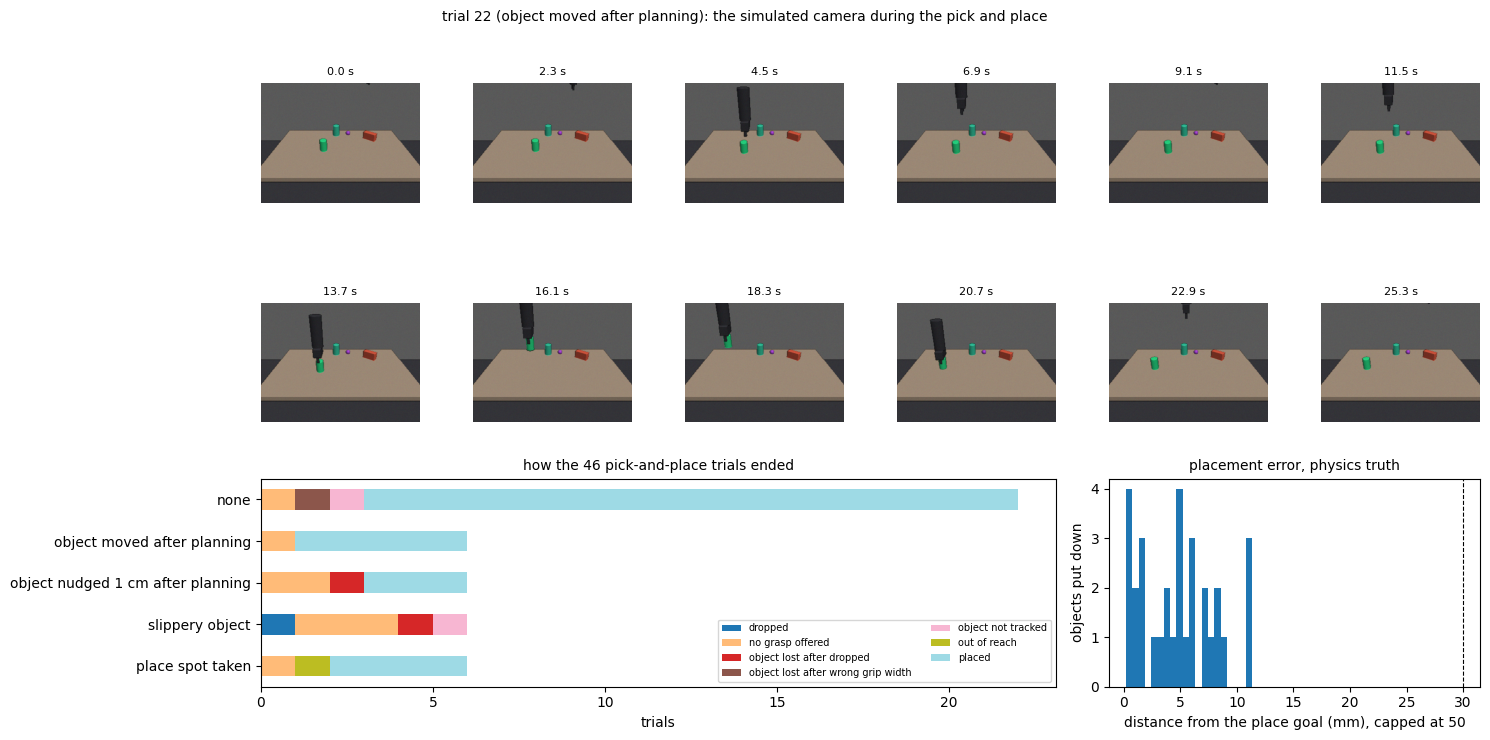

In [ ]:
if pick_trials is not None:
    shown_trial = int(pick_trials[pick_trials.success & (pick_trials.disturbance == 'object moved after planning')].trial.iloc[0]) \
        if (pick_trials.success & (pick_trials.disturbance == 'object moved after planning')).any() else int(pick_trials[pick_trials.success].trial.iloc[0])
    _, frames = pick_place_trial(shown_trial, keep_frames=True)
    fig = plt.figure(figsize=(15, 7.5))
    grid = fig.add_gridspec(3, 6)
    for index, frame in enumerate(np.linspace(0, len(frames) - 1, 12).astype(int)):
        ax = fig.add_subplot(grid[index // 6, index % 6])
        ax.imshow(np.clip(frames[frame], 0, 1))
        ax.set_title(f'{frame * DT:.1f} s', fontsize=8)
        ax.axis('off')
    ax = fig.add_subplot(grid[2, :4])
    counts = pd.crosstab(pick_trials.disturbance, pick_trials.outcome).reindex(pd.unique(pick_trials.disturbance))
    counts.plot.barh(stacked=True, ax=ax, colormap='tab20')
    ax.invert_yaxis()
    ax.set_xlabel('trials')
    ax.set_ylabel('')
    ax.set_title(f'how the {len(pick_trials)} pick-and-place trials ended', fontsize=10)
    ax.legend(fontsize=7, ncol=2)
    ax = fig.add_subplot(grid[2, 4:])
    put_down = pick_trials[pick_trials.outcome.isin(['placed', 'placed badly'])]
    ax.hist(1000 * put_down.placement_error.clip(upper=0.05), bins=20, color='tab:blue')
    ax.axvline(1000 * PLACE_TOLERANCE, color='k', lw=0.8, ls='--')
    ax.set_xlabel('distance from the place goal (mm), capped at 50')
    ax.set_ylabel('objects put down')
    ax.set_title('placement error, physics truth', fontsize=10)
    fig.suptitle(f'trial {shown_trial} ({pick_trials.disturbance[shown_trial]}): the simulated camera during the pick and place', fontsize=10)
    plt.tight_layout()
    plt.show()

In [ ]:
def plain(value):
    if isinstance(value, dict):
        return {key: plain(v) for key, v in value.items()}
    if isinstance(value, (list, tuple, np.ndarray)):
        return [plain(v) for v in value]
    if isinstance(value, np.generic):
        return value.item()
    return value


export = plain({'tracker': selected, 'settings': variants[selected],
                'segmenter': {'category_weights': TabletopSegmenter.category_weights,
                              'confidence_weights': TabletopSegmenter.confidence_weights, 'adaptive': TabletopSegmenter().adaptive,
                              'split_settings': TabletopSegmenter.split_settings},
                'grasping': {'ranking': final_policy, 'ranking_weights': grasp_weights, 'n_sigma': grasp_planner.n_sigma,
                             'prediction': final_prediction, 'execution_delay': EXECUTION_DELAY, 'hysteresis': GRASP_HYSTERESIS,
                             'gripper': vars(grasp_planner.gripper), 'arm_base_in_table': ARM_BASE_IN_TABLE,
                             'arm_base_yaw': ARM_BASE_YAW}})
with open('pipeline_config.json', 'w') as f:
    json.dump(export, f, indent=2)
print(json.dumps(export, indent=2))

{
  "tracker": "T18 = T14 + appearance in the association cost",
  "settings": {
    "pose_aware": true,
    "measurement": "model",
    "body_gate": true,
    "merge_aware": true,
    "reid_model": {
      "scale": [
        0.003451687029268731,
        0.003242210914192737,
        0.0008662102630385537
      ],
      "threshold": 2.0364299534546553
    },
    "noise_model": {
      "kind": "table",
      "std": {
        "sphere": [
          0.008471424830135119,
          0.00466384804973793,
          0.000466384804973793,
          0.008471424830135119
        ],
        "flat_top": [
          0.02467159325906819,
          0.02467159325906819,
          0.002467159325906819,
          0.032344671904260165
        ]
      }
    },
    "appearance_gate": 4.0,
    "area_learning_hits": 15,
    "shape_cost": 1.0
  },
  "segmenter": {
    "category_weights": [
      -45.65494159309795,
      52.84907927463104,
      15.975669430487612
    ],
    "confidence_weights": [
      -3.20

In [ ]:
def write_bop_scene(seq, out_dir, frames, rng):
    out_dir = Path(out_dir)
    for folder in ['rgb', 'depth', 'mask_visib']:
        (out_dir / folder).mkdir(parents=True, exist_ok=True)
    cameras, gts, infos = {}, {}, {}
    for t in frames:
        rgb_clean, depth_clean, instance = render_frame(seq, t)
        rgb, depth = apply_sensor_model(rgb_clean, depth_clean, rng)
        Image.fromarray((np.clip(rgb, 0, 1) * 255).round().astype(np.uint8)).save(out_dir / 'rgb' / f'{t:06d}.png')
        Image.fromarray((depth * 10000).round().astype(np.uint16)).save(out_dir / 'depth' / f'{t:06d}.png')
        cam_rot, cam_pos = seq['cam_rot'][t], seq['cam_pos'][t]
        cameras[t] = {'cam_K': [FX, 0.0, CX, 0.0, FY, CY, 0.0, 0.0, 1.0], 'depth_scale': 0.1,
                      'cam_R_w2c': cam_rot.T.ravel().tolist(), 'cam_t_w2c': (-1000 * cam_rot.T @ cam_pos).tolist()}
        gts[t], infos[t] = [], []
        for index, obj in enumerate(seq['objects']):
            yaw = obj['yaw'] if obj['kind'] == 'box' else 0.0
            object_rot = Rotation.from_euler('z', yaw).as_matrix()
            gts[t].append({'cam_R_m2c': (cam_rot.T @ object_rot).ravel().tolist(),
                           'cam_t_m2c': (1000 * cam_rot.T @ (obj['path'][t] - cam_pos)).tolist(), 'obj_id': index + 1})
            mask = instance == FIRST_OBJECT + index
            Image.fromarray(mask.astype(np.uint8) * 255).save(out_dir / 'mask_visib' / f'{t:06d}_{index:06d}.png')
            infos[t].append({'px_count_visib': int(mask.sum())})
    for name, content in [('scene_camera.json', cameras), ('scene_gt.json', gts), ('scene_gt_info.json', infos)]:
        (out_dir / name).write_text(json.dumps({str(k): v for k, v in content.items()}))
    models = {}
    for index, obj in enumerate(seq['objects']):
        if obj['kind'] == 'box':
            half = obj['size']
        elif obj['kind'] == 'cylinder':
            half = np.array([obj['size'][0], obj['size'][0], obj['size'][1]])
        else:
            half = np.full(3, obj['size'][0])
        models[str(index + 1)] = {'min_x': -1000 * half[0], 'min_y': -1000 * half[1], 'min_z': -1000 * half[2],
                                  'size_x': 2000 * half[0], 'size_y': 2000 * half[1], 'size_z': 2000 * half[2]}
    (out_dir / 'models_info.json').write_text(json.dumps(models))


def write_tum_sequence(seq, out_dir, frames, rng):
    out_dir = Path(out_dir)
    for folder in ['rgb', 'depth']:
        (out_dir / folder).mkdir(parents=True, exist_ok=True)
    rgb_lines, depth_lines, pose_lines = [], [], []
    for t in frames:
        stamp = 1000.0 + t * DT
        rgb_clean, depth_clean, _ = render_frame(seq, t)
        rgb, depth = apply_sensor_model(rgb_clean, depth_clean, rng)
        Image.fromarray((np.clip(rgb, 0, 1) * 255).round().astype(np.uint8)).save(out_dir / 'rgb' / f'{stamp:.6f}.png')
        Image.fromarray((depth * 5000).round().astype(np.uint16)).save(out_dir / 'depth' / f'{stamp:.6f}.png')
        rgb_lines.append(f'{stamp:.6f} rgb/{stamp:.6f}.png')
        depth_lines.append(f'{stamp:.6f} depth/{stamp:.6f}.png')
        qx, qy, qz, qw = Rotation.from_matrix(seq['cam_rot'][t]).as_quat()
        x, y, z = seq['cam_pos'][t]
        pose_lines.append(f'{stamp:.6f} {x:.6f} {y:.6f} {z:.6f} {qx:.8f} {qy:.8f} {qz:.8f} {qw:.8f}')
    for name, lines in [('rgb.txt', rgb_lines), ('depth.txt', depth_lines), ('groundtruth.txt', pose_lines)]:
        (out_dir / name).write_text('# written from the simulator\n' + '\n'.join(lines) + '\n')


def as_track_entries(objects):
    return [(obj['id'], obj['detection_index'], obj['position'], obj['covariance'], np.nan, 0, obj['visible_share'])
            for obj in objects if obj['state'] == 'tracked']


def ideal_association(records, outputs):
    relabelled = []
    for record, entries in zip(records, outputs):
        frame = []
        for entry in entries:
            gt_id = record['detections'][entry[1]]['gt_id']
            frame.append((gt_id if gt_id >= 0 else -1000 - entry[0], *entry[1:]))
        relabelled.append(frame)
    return relabelled


def object_centre_cam(gt, models_info):
    info = models_info[str(gt['obj_id'])]
    model_centre = np.array([info['min_x'] + info['size_x'] / 2, info['min_y'] + info['size_y'] / 2,
                             info['min_z'] + info['size_z'] / 2]) / 1000.0
    return np.array(gt['cam_R_m2c']).reshape(3, 3) @ model_centre + np.array(gt['cam_t_m2c']) / 1000.0


def check_bop_scene(scene, models_info, n_frames=6):
    problems, depth_gaps = [], []
    for im_id in scene.frame_ids[::max(len(scene.frame_ids) // n_frames, 1)][:n_frames]:
        try:
            frame = scene.frame(im_id)
        except (FileNotFoundError, OSError) as error:
            problems.append(f'image {im_id}: {error}')
            continue
        height, width = frame['depth'].shape
        K = frame['K']
        if frame['rgb'].shape[:2] != (height, width):
            problems.append(f'image {im_id}: colour and depth have different sizes')
        if not (K[0, 0] > 0 and K[1, 1] > 0 and 0 < K[0, 2] < width and 0 < K[1, 2] < height):
            problems.append(f'image {im_id}: intrinsics do not fit a {width}x{height} image')
        if not (frame['depth'] > 0).any():
            problems.append(f'image {im_id}: depth image is empty')
        for index, gt in enumerate(scene.gt.get(im_id, [])):
            name = f'image {im_id}, object {gt["obj_id"]}'
            R = np.array(gt['cam_R_m2c']).reshape(3, 3)
            if abs(np.linalg.det(R) - 1) > 1e-3 or np.abs(R @ R.T - np.eye(3)).max() > 1e-3:
                problems.append(f'{name}: annotated rotation is not a rotation matrix')
                continue
            if str(gt['obj_id']) not in models_info:
                problems.append(f'{name}: no entry in models_info.json')
                continue
            mask = scene.visible_mask(im_id, index)
            if mask is None or mask.shape != (height, width):
                problems.append(f'{name}: visible mask missing or of the wrong size')
                continue
            if mask.sum() < MIN_VISIBLE_PIXELS:
                continue
            centre = object_centre_cam(gt, models_info)
            info = models_info[str(gt['obj_id'])]
            half_diagonal = 0.5 * np.linalg.norm([info['size_x'], info['size_y'], info['size_z']]) / 1000.0
            u, v = K[0, 0] * centre[0] / centre[2] + K[0, 2], K[1, 1] * centre[1] / centre[2] + K[1, 2]
            rows, cols = np.nonzero(mask)
            reach = K[0, 0] * half_diagonal / max(centre[2], 0.05)
            if not (cols.min() - reach <= u <= cols.max() + reach and rows.min() - reach <= v <= rows.max() + reach):
                problems.append(f'{name}: annotated centre does not project onto its mask')
            seen = frame['depth'][mask]
            seen = seen[seen > 0]
            if len(seen):
                depth_gaps.append(np.median(seen) - centre[2])
                if abs(depth_gaps[-1]) > half_diagonal + 0.02:
                    problems.append(f'{name}: depth under the mask is {depth_gaps[-1]:+.3f} m from the annotated distance')
    return problems, np.array(depth_gaps)


def bop_camera_pose(scene, im_id, source, reference):
    if source == 'dataset':
        camera = scene.camera[im_id]
        if 'cam_R_w2c' not in camera:
            return None
        R_w2c = np.array(camera['cam_R_w2c']).reshape(3, 3)
        return R_w2c.T, -R_w2c.T @ np.array(camera['cam_t_w2c']) / 1000.0
    for gt in scene.gt.get(im_id, []):
        if gt['obj_id'] == reference:
            R_m2c = np.array(gt['cam_R_m2c']).reshape(3, 3)
            return R_m2c.T, -R_m2c.T @ np.array(gt['cam_t_m2c']) / 1000.0
    return None


def run_bop_scene(scene, models_info, settings, pose_source='reference object', fps=30.0, max_frames=None, seed=0,
                  decimation=None):
    counts = {}
    for gts in scene.gt.values():
        for gt in gts:
            counts[gt['obj_id']] = counts.get(gt['obj_id'], 0) + 1
    reference = max(counts, key=counts.get)
    stand_in = {'objects': [{'is_target': True}] * (max(counts) + 1)}
    pipeline, cameras = None, {}
    frame_records, outputs, rows = [], [], []
    seconds, false_alarms = 0.0, 0
    for im_id in scene.frame_ids[:max_frames]:
        pose = bop_camera_pose(scene, im_id, pose_source, reference)
        if pose is None:
            continue
        cam_rot, cam_pos = pose
        frame = scene.frame(im_id)
        height, width = frame['depth'].shape
        if pipeline is None:
            step = max(round(width / IMG_W), 1) if decimation is None else decimation
            pipeline = TabletopPerception(settings, seed=seed, camera=camera_from_K(frame['K'], width, height), decimation=step)
        key = (width, height, *frame['K'][[0, 1, 0, 1], [0, 1, 2, 2]])
        if key not in cameras:
            cameras[key] = camera_from_K(frame['K'], width, height).reduced(step)
        pipeline.segmenter.camera = cameras[key]
        gts = scene.gt.get(im_id, [])
        rgb, depth = frame['rgb'][::step, ::step], frame['depth'][::step, ::step]
        started = time.perf_counter()
        detections, labels = pipeline.segmenter.detect(rgb, depth)
        seconds += time.perf_counter() - started

        instance = np.zeros(depth.shape, dtype=int)
        centres = {}
        for index, gt in enumerate(gts):
            mask = scene.visible_mask(im_id, index)
            if mask is None:
                raise FileNotFoundError('mask_visib is needed to match detections to objects')
            instance[mask[::step, ::step]] = FIRST_OBJECT + gt['obj_id']
            centres[gt['obj_id']] = object_centre_cam(gt, models_info)
        visible = visible_targets(instance, stand_in)
        assign_ground_truth(detections, labels, instance, stand_in, visible)
        started = time.perf_counter()
        objects = pipeline.process_detections(detections, pipeline.segmenter.plane, cam_rot, cam_pos, im_id / fps)
        seconds += time.perf_counter() - started
        frame_records.append({'detections': detections, 'visible_gt': visible})
        outputs.append(as_track_entries(objects))

        found = {det['gt_id']: det for det in detections if det['gt_id'] >= 0}
        tracked = {detections[obj['detection_index']]['gt_id']: obj for obj in objects if obj['state'] == 'tracked'}
        false_alarms += sum(det['gt_id'] == FALSE_ALARM for det in detections)
        for obj_id in sorted(visible):
            row = {'im_id': im_id, 'obj_id': obj_id, 'found': obj_id in found, 'shape': None, 'category': None,
                   'purity': np.nan, 'centroid_error': np.nan, 'model_error': np.nan, 'track_category': None,
                   'tracked_error': np.nan}
            if obj_id in found:
                det, truth = found[obj_id], centres[obj_id]
                row.update(shape=det['shape'], category=det['category'], purity=det['purity'],
                           centroid_error=np.linalg.norm(det['centroid_cam'] - truth),
                           model_error=np.linalg.norm(det['centre_cam'] - truth))
            if obj_id in tracked:
                truth_world = cam_rot @ centres[obj_id] + cam_pos
                row.update(track_category=tracked[obj_id]['category'],
                           tracked_error=np.linalg.norm(tracked[obj_id]['position'] - truth_world))
            rows.append(row)
    return {'records': frame_records, 'outputs': outputs, 'rows': pd.DataFrame(rows), 'false_alarms': false_alarms,
            'seconds_per_frame': seconds / max(len(frame_records), 1)}


def timing_pose_cov(linear_speed, angular_speed, time_std, position_std=0.001, angle_std=np.deg2rad(0.1)):
    return np.diag([position_std ** 2 + (linear_speed * time_std) ** 2] * 3
                   + [angle_std ** 2 + (angular_speed * time_std) ** 2] * 3)


def run_tum_sequence(sequence, camera, settings, decimation=1, plane_prior=True, time_std=None, stride=1,
                     max_frames=None, seed=0, split=True):
    pipeline = TabletopPerception(settings, seed=seed, camera=camera, decimation=decimation, plane_prior=plane_prior)
    if not split:
        pipeline.segmenter.split = None
    small = camera.reduced(decimation)
    track_rows, frame_rows = [], []
    seconds = 0.0
    indices = range(0, len(sequence.frames), stride)[:max_frames]
    first_stamp = sequence.frames[indices[0]]['stamp']
    for index in indices:
        frame = sequence.frame(index)
        pose_cov = None
        if time_std is not None:
            pose_cov = timing_pose_cov(*sequence.camera_motion(frame['stamp']), time_std)
        started = time.perf_counter()
        objects = pipeline.process_frame(frame['rgb'], frame['depth'], frame['cam_rot'], frame['cam_pos'],
                                         frame['stamp'] - first_stamp, pose_cov)
        frame_seconds = time.perf_counter() - started
        seconds += frame_seconds
        row = {'frame': index, 'stamp': frame['stamp'], 'ms': 1000 * frame_seconds, 'plane_found': pipeline.segmenter.plane is not None,
               'detections': len(pipeline.last_detections), 'plane_source': pipeline.segmenter.plane_source}
        if pipeline.segmenter.plane is not None:
            normal, offset = pipeline.segmenter.plane
            depth = frame['depth'][::decimation, ::decimation]
            points = small.ray_grid * depth[..., None]
            on_table = (depth > 0) & (np.abs(points @ normal + offset) < 0.01)
            row.update(normal_cam=normal, table_cam=points[on_table].mean(axis=0))
        frame_rows.append(row)
        for obj in objects:
            if obj['state'] == 'tracked':
                det = pipeline.last_detections[obj['detection_index']]
                track_rows.append({'frame': index, 'stamp': frame['stamp'], 'id': obj['id'], 'x': obj['position'][0],
                                   'y': obj['position'][1], 'z': obj['position'][2], 'nis': obj['nis'],
                                   'category': obj['category'], 'normal_view': obj['normal_view'],
                                   'image_edge': det['image_edge'], 'depth': det['centroid_cam'][2],
                                   'reported_std': np.sqrt(np.trace(obj['covariance']) / 3)})
    return {'tracks': pd.DataFrame(track_rows), 'frames': pd.DataFrame(frame_rows),
            'seconds_per_frame': seconds / max(len(indices), 1)}


def table_in_world(sequence, frames, time_offset=None):
    time_offset = sequence.time_offset if time_offset is None else time_offset
    normals, middles = [], []
    for row in frames[frames.plane_found].itertuples():
        cam_rot, cam_pos, gap = sequence.pose_at(row.stamp + time_offset)
        if np.isfinite(gap):
            normals.append(cam_rot @ row.normal_cam)
            middles.append(cam_rot @ row.table_cam + cam_pos)
    return np.array(normals), np.array(middles)


def table_consistency(normals, middles):
    mean_normal = np.median(normals, axis=0)
    mean_normal = mean_normal / np.linalg.norm(mean_normal)
    angle = np.degrees(np.arccos(np.clip(normals @ mean_normal, -1, 1)))
    height = (middles - np.median(middles, axis=0)) @ mean_normal
    offset = np.einsum('ij,ij->i', normals, middles)
    return {'normal spread, median (deg)': np.median(angle), 'frames over 10 deg off': np.mean(angle > 10),
            'table height std (mm)': 1000 * height.std(),
            'table height, robust std (mm)': 1000 * 1.4826 * np.median(np.abs(height - np.median(height))),
            'plane offset at the world origin, std (mm)': 1000 * offset.std()}


def static_scene_stability(tracks, min_reports=30, hop_distance=0.05):
    rows = []
    for _, track in tracks.groupby('id'):
        if len(track) < min_reports:
            continue
        positions = track[['x', 'y', 'z']].to_numpy()
        steps = np.linalg.norm(np.diff(positions, axis=0), axis=1)
        hops = steps > hop_distance
        legs = np.split(positions, np.nonzero(hops)[0] + 1)
        leg_std = [leg.std(axis=0).mean() for leg in legs if len(leg) >= 10]
        rows.append({'reports': len(track), 'seconds': track.stamp.max() - track.stamp.min(), 'hops': hops.sum(),
                     'std_all': positions.std(axis=0).mean(), 'std_between_hops': np.mean(leg_std) if leg_std else np.nan,
                     'step': np.median(steps[~hops]) if (~hops).any() else np.nan})
    table = pd.DataFrame(rows)
    return {'tracks with 30 reports or more': len(table),
            'position std over the whole track, median (mm)': 1000 * table.std_all.median(),
            'position std between hops, median (mm)': 1000 * table.std_between_hops.median(),
            'frame to frame step, median (mm)': 1000 * table.step.median(),
            'hops per track per minute': 60 * table.hops.sum() / table.seconds.sum(),
            'tracks that never hop': (table.hops == 0).mean()}


def reprojection_residual(sequence, pairs, intrinsics, depth_factor=5000.0, step=4, max_residual=0.10):
    fx, fy, cx, cy = intrinsics
    medians, agreeing = [], []
    for a, b in pairs:
        frame_a, frame_b = sequence.frame(a, depth_factor), sequence.frame(b, depth_factor)
        height, width = frame_a['depth'].shape
        v, u = np.mgrid[0:height:step, 0:width:step]
        z = frame_a['depth'][v, u]
        seen = (z > 0.3) & (z < 3.0)
        points = np.stack([(u - cx) / fx * z, (v - cy) / fy * z, z], axis=-1)[seen]
        in_b = (points @ frame_a['cam_rot'].T + frame_a['cam_pos'] - frame_b['cam_pos']) @ frame_b['cam_rot']
        in_front = in_b[:, 2] > 0.3
        in_b = in_b[in_front]
        u_b = np.round(fx * in_b[:, 0] / in_b[:, 2] + cx).astype(int)
        v_b = np.round(fy * in_b[:, 1] / in_b[:, 2] + cy).astype(int)
        inside = (u_b >= 0) & (u_b < width) & (v_b >= 0) & (v_b < height)
        measured = frame_b['depth'][v_b[inside], u_b[inside]]
        residual = in_b[inside, 2] - measured
        same_surface = (measured > 0) & (np.abs(residual) < max_residual)
        if same_surface.any():
            medians.append(np.median(np.abs(residual[same_surface])))
        agreeing.append(same_surface.mean() if len(same_surface) else 0.0)
    return (np.mean(medians) if medians else np.nan), np.mean(agreeing)

In [ ]:
check_dir = Path(tempfile.mkdtemp())
seq = pick_dev_sequences[0]
frames = list(range(60))
write_bop_scene(seq, check_dir / 'bop' / '000000', frames, np.random.default_rng([seq['seed'], 0]))
write_tum_sequence(seq, check_dir / 'tum', frames, np.random.default_rng([seq['seed'], 0]))

direct_records = pick_dev_cache[0][:60]
direct = [as_track_entries(objects) for objects in run_pipeline_on_records(seq, direct_records, variants[selected])[0]]
direct_scores = score_tracking(direct_records, direct)

bop_scene = BopScene(check_dir / 'bop' / '000000')
models_info = json.loads((check_dir / 'bop' / '000000' / 'models_info.json').read_text())
problems, depth_gaps = check_bop_scene(bop_scene, models_info)
print(f'validation of the written scene: {len(problems)} problems, depth under the masks is {1000 * np.median(depth_gaps):+.0f} mm '
      'from the annotated centres (the visible surface lies in front of the centre)')
assert not problems
for field, change in [('depth_scale', lambda value: 1.5 * value), ('cam_K', lambda K: [K[0], 0.0, K[2] + 120, 0.0, K[4], K[5], 0.0, 0.0, 1.0])]:
    broken = BopScene(check_dir / 'bop' / '000000')
    for camera in broken.camera.values():
        camera[field] = change(camera[field])
    assert check_bop_scene(broken, models_info)[0], f'a wrong {field} went unnoticed'
print('a depth scale off by 1.5 and a principal point off by 120 pixels are both reported')

print('direct run                         ', {k: round(v, 4) for k, v in direct_scores.items() if k in ['idf1', 'mota', 'id_switches']})
for source in ['dataset', 'reference object']:
    bop_run = run_bop_scene(bop_scene, models_info, variants[selected], pose_source=source, fps=1 / DT, seed=seq['seed'])
    bop_scores = score_tracking(bop_run['records'], bop_run['outputs'])
    print(f'read back as BOP, pose from {source:17s}', {k: round(v, 4) for k, v in bop_scores.items() if k in ['idf1', 'mota', 'id_switches']})
    assert abs(bop_scores['idf1'] - direct_scores['idf1']) < 0.01
ideal = score_tracking(bop_run['records'], ideal_association(bop_run['records'], bop_run['outputs']))['idf1']
print(f"IDF1 with perfect association on the same detections: {ideal:.4f} (measured {bop_scores['idf1']:.4f})")
assert ideal >= bop_scores['idf1'] - 1e-9

sim_errors = [np.linalg.norm(seq['cam_rot'][t] @ det['centre_cam'] + seq['cam_pos'][t] - seq['objects'][det['gt_id']]['path'][t])
              for t, record in enumerate(direct_records) for det in record['detections'] if det['gt_id'] >= 0]
targets = [index + 1 for index, obj in enumerate(seq['objects']) if obj['is_target']]
bop_rows = bop_run['rows']
bop_errors = bop_rows[bop_rows.obj_id.isin(targets)].model_error.dropna()
print(f'mean centre error, simulator truth {1000 * np.mean(sim_errors):.2f} mm, BOP ground truth {1000 * bop_errors.mean():.2f} mm')
assert abs(np.mean(sim_errors) - bop_errors.mean()) < 0.0005

tum = TumSequence(check_dir / 'tum')
assert len(tum.frames) == len(frames) and not any(tum.rejected.values())
tum_tracks = run_tum_sequence(tum, SIM_CAMERA, variants[selected], seed=seq['seed'])['tracks']
direct_positions = {(t, entry[0]): entry[2] for t, entries in enumerate(direct) for entry in entries}
tum_positions = {(row.frame, row.id): np.array([row.x, row.y, row.z]) for row in tum_tracks.itertuples()}
shared = set(direct_positions) & set(tum_positions)
gaps = np.array([np.linalg.norm(direct_positions[key] - tum_positions[key]) for key in shared])
print(f'TUM read back: {len(tum.frames)} frames, {len(shared)} of {len(direct_positions)} track positions under the same id, '
      f'difference median {1000 * np.median(gaps):.3f} mm, largest {1000 * gaps.max():.2f} mm')
assert len(shared) >= 0.98 * len(direct_positions) and np.median(gaps) < 0.0005 and gaps.max() < 0.005

moving = heldout_sequences[('camera_motion', 0)]
sparse_dir = check_dir / 'sparse'
sparse_dir.mkdir()
stamps = 1000.0 + np.arange(N_FRAMES) * DT
image_lines = [f'{stamp:.6f} none.png' for stamp in stamps]
pose_lines = []
for t in range(0, N_FRAMES, 5):
    qx, qy, qz, qw = Rotation.from_matrix(moving['cam_rot'][t]).as_quat()
    x, y, z = moving['cam_pos'][t]
    pose_lines.append(f'{stamps[t]:.6f} {x:.6f} {y:.6f} {z:.6f} {qx:.8f} {qy:.8f} {qz:.8f} {qw:.8f}')
for name, lines in [('rgb.txt', image_lines), ('depth.txt', image_lines), ('groundtruth.txt', pose_lines)]:
    (sparse_dir / name).write_text('\n'.join(lines) + '\n')
for mode in ['nearest', 'interpolated']:
    sparse = TumSequence(sparse_dir, max_gap=3 * DT, pose=mode)
    index = [int(round((frame['stamp'] - 1000.0) / DT)) for frame in sparse.frames]
    position_error = [np.linalg.norm(frame['cam_pos'] - moving['cam_pos'][t]) for frame, t in zip(sparse.frames, index)]
    angle_error = [Rotation.from_matrix(frame['cam_rot'].T @ moving['cam_rot'][t]).magnitude() for frame, t in zip(sparse.frames, index)]
    print(f'{mode:12s} pose from every fifth sample: position error mean {1000 * np.mean(position_error):.2f} mm, '
          f'rotation error mean {np.degrees(np.mean(angle_error)):.3f} deg')
    if mode == 'nearest':
        nearest_error = np.mean(position_error)
assert np.mean(position_error) < 0.5 * nearest_error

validation of the written scene: 0 problems, depth under the masks is -22 mm from the annotated centres (the visible surface lies in front of the centre)
a depth scale off by 1.5 and a principal point off by 120 pixels are both reported
direct run                          {'idf1': np.float64(0.9791), 'mota': 0.9591, 'id_switches': 0}
read back as BOP, pose from dataset           {'idf1': np.float64(0.9798), 'mota': 0.9603, 'id_switches': 0}
read back as BOP, pose from reference object  {'idf1': np.float64(0.9798), 'mota': 0.9603, 'id_switches': 0}
IDF1 with perfect association on the same detections: 0.9798 (measured 0.9798)
mean centre error, simulator truth 2.68 mm, BOP ground truth 2.67 mm
TUM read back: 60 frames, 363 of 363 track positions under the same id, difference median 0.035 mm, largest 1.80 mm
nearest      pose from every fifth sample: position error mean 14.24 mm, rotation error mean 1.185 deg
interpolated pose from every fifth sample: position error mean 3.87 mm, rotatio

In [ ]:
BOP_SOURCES = ['https://huggingface.co/datasets/bop-benchmark/ycbv/resolve/main',
               'https://huggingface.co/datasets/bop-benchmark/datasets/resolve/main/ycbv']
YCBV_NAMES = ['master chef can', 'cracker box', 'sugar box', 'tomato soup can', 'mustard bottle', 'tuna fish can',
              'pudding box', 'gelatin box', 'potted meat can', 'banana', 'pitcher base', 'bleach cleanser', 'bowl', 'mug',
              'power drill', 'wood block', 'scissors', 'large marker', 'large clamp', 'extra large clamp', 'foam brick']
YCBV_PRIMITIVE = {1: 'cylinder', 2: 'box', 3: 'box', 4: 'cylinder', 6: 'cylinder', 7: 'box', 8: 'box', 9: 'box',
                  16: 'box', 21: 'box'}

ycbv_root = DATA_ROOT / 'ycbv'
search_roots = [ycbv_root, '/kaggle/input']
if not find_files('scene_gt.json', search_roots):
    for archive in ['ycbv_models.zip', 'ycbv_test_bop19.zip']:
        for source in BOP_SOURCES:
            downloaded = fetch(f'{source}/{archive}', DATA_ROOT / 'downloads' / archive)
            if downloaded is not None:
                unpack(downloaded, ycbv_root)
                break
scene_dirs = [path.parent for path in find_files('scene_gt.json', search_roots) if (path.parent / 'mask_visib').exists()]
models_files = [path for path in find_files('models_info.json', search_roots) if 'models_eval' not in str(path)]

ycbv_results = None
if scene_dirs and models_files:
    models_info = json.loads(models_files[0].read_text())
    scenes, check_rows = {}, []
    for scene_dir in scene_dirs:
        scene = BopScene(scene_dir)
        problems, depth_gaps = check_bop_scene(scene, models_info)
        has_pose = all('cam_R_w2c' in camera for camera in scene.camera.values())
        first = scene.frame(scene.frame_ids[0])
        check_rows.append({'scene': scene_dir.name, 'images': len(scene.frame_ids), 'size': f"{first['depth'].shape[1]}x{first['depth'].shape[0]}",
                           'fx': first['K'][0, 0], 'problems': len(problems), 'camera pose in dataset': has_pose,
                           'depth minus annotated distance (mm)': 1000 * np.median(depth_gaps) if len(depth_gaps) else np.nan})
        for problem in problems[:3]:
            print(f'{scene_dir.name}: {problem}')
        if not problems:
            scenes[scene_dir.name] = scene
    print('input check')
    print(pd.DataFrame(check_rows).set_index('scene').round(1))

    scene_rows, detection_tables = [], []
    for name, scene in scenes.items():
        sources = ['dataset', 'reference object'] if all('cam_R_w2c' in camera for camera in scene.camera.values()) else ['reference object']
        row = {'scene': name}
        for source in sources:
            run = run_bop_scene(scene, models_info, variants[selected], pose_source=source)
            scores = score_tracking(run['records'], run['outputs'])
            row[f'idf1, pose from {source}'] = scores['idf1']
            row[f'id switches, pose from {source}'] = scores['id_switches']
            if source == sources[0]:
                rows = run['rows'].assign(scene=name)
                detection_tables.append(rows)
                found = rows[rows.found]
                row.update({'frames': len(run['records']), 'visible objects': len(rows), 'recall': rows.found.mean(),
                            'clean segments': (found.purity >= 0.9).mean() if len(found) else np.nan,
                            'precision': rows.found.sum() / max(rows.found.sum() + run['false_alarms'], 1),
                            'idf1, ideal association': score_tracking(run['records'], ideal_association(run['records'], run['outputs']))['idf1'],
                            'ms_per_frame': 1000 * run['seconds_per_frame']})
        scene_rows.append(row)
    if scene_rows:
        ycbv_results = pd.DataFrame(scene_rows).set_index('scene')
        ycbv_detections = pd.concat(detection_tables, ignore_index=True)
        print()
        print(ycbv_results.round(3))
elif find_files('scene_gt.json', search_roots):
    print('YCB-Video scenes found but without mask_visib or models_info.json, both are needed to match detections to objects')
else:
    print(f'YCB-Video not found under {ycbv_root} or /kaggle/input and could not be downloaded. the real-data cell below is skipped. '
          'nothing about YCB-Video is reported from this run')

000049: image 1144, object 9: depth under the mask is +0.378 m from the annotated distance
input check
        images     size      fx  problems  camera pose in dataset  depth minus annotated distance (mm)
scene                                                                                                 
000048      75  640x480  1066.8         0                    True                                -32.6
000049      75  640x480  1066.8         1                    True                                -31.5
000050      75  640x480  1066.8         0                    True                                -25.7
000051      75  640x480  1066.8         0                    True                                -35.3
000052      75  640x480  1066.8         0                    True                                -33.3
000053      75  640x480  1066.8         0                    True                                -24.0
000054      75  640x480  1066.8         0                    True        

In [ ]:
if ycbv_results is not None:
    found = ycbv_detections[ycbv_detections.found]
    by_object = ycbv_detections.groupby('obj_id').agg(visible=('found', 'size'), detected=('found', 'mean'))
    by_object['model_centre_mm'] = 1000 * found.groupby('obj_id').model_error.median()
    by_object['surface_centroid_mm'] = 1000 * found.groupby('obj_id').centroid_error.median()
    by_object['clean_segment'] = (found.purity >= 0.9).groupby(found.obj_id).mean()
    by_object['called'] = found.groupby('obj_id').category.agg(lambda c: c.value_counts().idxmax())
    by_object['shape'] = [YCBV_PRIMITIVE.get(i, 'other') for i in by_object.index]
    by_object.index = [f'{i} {YCBV_NAMES[i - 1]}' if i <= len(YCBV_NAMES) else str(i) for i in by_object.index]
    print('per object, camera frame')
    print(by_object.round(2))

    ycbv_detections['supported'] = ycbv_detections.obj_id.isin(YCBV_PRIMITIVE)
    found = ycbv_detections[ycbv_detections.found]
    summary = ycbv_detections.groupby('supported').agg(visible=('found', 'size'), detected=('found', 'mean'))
    summary['model_centre_mm'] = 1000 * found.groupby('supported').model_error.median()
    summary['surface_centroid_mm'] = 1000 * found.groupby('supported').centroid_error.median()
    summary.index = ['other shapes' if not supported else 'cans and boxes' for supported in summary.index]
    print()
    print(summary.round(2))

    per_scene = found.groupby('scene')[['centroid_error', 'model_error', 'tracked_error']].mean() * 1000
    print()
    if len(per_scene) >= 2:
        gain = per_scene.centroid_error - per_scene.model_error
        mean, low, high = bootstrap_mean_ci(gain, boot_rng)
        print(f'surface centroid minus model centre: {mean:.1f} mm [{low:.1f}, {high:.1f}] over {len(per_scene)} scenes, '
              f'wilcoxon p = {paired_wilcoxon(per_scene.centroid_error, per_scene.model_error):.4f}')
    tracked = ycbv_detections.dropna(subset=['track_category'])
    expected = tracked.obj_id.map(YCBV_PRIMITIVE)
    agrees = (tracked.track_category == expected)[expected.notna()]
    if len(agrees):
        print(f'track category on the can- and box-shaped objects: {agrees.mean():.1%} of {len(agrees)} tracked frames agree')
    pose_columns = [column for column in ycbv_results.columns if column.startswith('idf1')]
    print('IDF1 over the scenes:', {column.replace('idf1, ', ''): round(ycbv_results[column].mean(), 3) for column in pose_columns})
    measured = ycbv_results[[column for column in pose_columns if 'pose from' in column][0]].mean()
    ideal = ycbv_results['idf1, ideal association'].mean()
    print(f'IDF1 {measured:.3f} with the first pose source, {ideal:.3f} with perfect association: {1 - ideal:.3f} is lost '
          f'in detection and {ideal - measured:.3f} in association')

per object, camera frame
                      visible  detected  model_centre_mm  surface_centroid_mm  clean_segment    called     shape
1 master chef can         300      0.77            27.53                47.91           0.82    sphere  cylinder
2 cracker box             225      1.00             8.76                79.25           0.92       box       box
3 sugar box               300      0.95             9.00                38.59           0.71       box       box
4 tomato soup can         449      0.86            14.21                27.05           0.99    sphere  cylinder
5 mustard bottle          150      0.50             2.37                30.73           1.00  cylinder     other
6 tuna fish can           225      0.36            24.26                35.68           0.99       box  cylinder
7 pudding box              75      0.65             4.47                41.93           0.96       box       box
8 gelatin box              75      1.00            25.45               

In [ ]:
TUM_SEQUENCE = 'rgbd_dataset_freiburg1_xyz'
TUM_SOURCES = ['https://cvg.cit.tum.de/rgbd/dataset', 'https://vision.in.tum.de/rgbd/dataset']
tum_group = TUM_SEQUENCE.split('_')[2]
tum_dir = DATA_ROOT / 'tum'
found = [path.parent for path in find_files('groundtruth.txt', [tum_dir, '/kaggle/input']) if path.parent.name == TUM_SEQUENCE]
for source in TUM_SOURCES:
    if not found:
        downloaded = fetch(f'{source}/{tum_group}/{TUM_SEQUENCE}.tgz', DATA_ROOT / 'downloads' / f'{TUM_SEQUENCE}.tgz')
        if downloaded is not None:
            unpack(downloaded, tum_dir)
            found = [tum_dir / TUM_SEQUENCE]

tum = None
if found:
    tum_nearest = TumSequence(found[0], pose='nearest', clock='colour')
    tum = TumSequence(found[0])
    first = tum.frame(0)
    tum_camera = CameraModel(first['depth'].shape[1], first['depth'].shape[0], *TUM_INTRINSICS[tum_group])
    image_gap = 1000 * np.abs([frame['image_gap'] for frame in tum.frames])
    pose_gap = 1000 * np.array([frame['pose_gap'] for frame in tum_nearest.frames])
    motion = np.array([tum.camera_motion(frame['stamp']) for frame in tum.frames])
    print(f'{len(tum.frames)} frames, left out: {tum.rejected}')
    print(f'colour and depth images of a frame are {np.median(image_gap):.1f} ms apart (median), {image_gap.max():.1f} ms at most')
    print(f'the nearest motion-capture sample is {np.median(pose_gap):.1f} ms from the image (median), {pose_gap.max():.1f} ms at most')
    print(f'camera speed: median {np.median(motion[:, 0]):.2f} m/s and {np.degrees(np.median(motion[:, 1])):.0f} deg/s, '
          f'so 10 ms of timing error is about {10 * np.median(motion[:, 0]):.1f} mm and {0.01 * np.degrees(np.median(motion[:, 1])):.2f} deg of pose error')


    pairs = [(i, i + gap) for gap in (15, 30, 60) for i in range(0, len(tum.frames) - 61, 37)]
    default_intrinsics = TUM_INTRINSICS[tum_group]

    def transposed(sequence):
        wrong = TumSequence(found[0])
        wrong.frames = [dict(frame, cam_rot=frame['cam_rot'].T) for frame in sequence.frames]
        return wrong

    audit = [('nearest pose, colour stamp (as before)', tum_nearest, default_intrinsics, 5000.0),
             ('interpolated pose, depth stamp', tum, default_intrinsics, 5000.0),
             ("colour camera's own calibration instead", tum, TUM_COLOUR_CALIBRATION[tum_group], 5000.0),
             ('depth 3.5% larger', tum, default_intrinsics, 5000.0 / 1.035),
             ('depth 3.5% smaller', tum, default_intrinsics, 5000.0 * 1.035),
             ('rotation convention wrong on purpose', transposed(tum), default_intrinsics, 5000.0)]
    audit_rows = []
    for name, sequence, intrinsics, depth_factor in audit:
        residual, agreeing = reprojection_residual(sequence, pairs, intrinsics, depth_factor)
        audit_rows.append({'reading': name, 'median residual (mm)': 1000 * residual, 'points that agree': agreeing})
    tum_audit = pd.DataFrame(audit_rows).set_index('reading')
    print()
    print(f'reprojection between {len(pairs)} frame pairs')
    print(tum_audit.round(2))
else:
    print('TUM sequence not found and could not be downloaded, the TUM cells are skipped')

downloading https://cvg.cit.tum.de/rgbd/dataset/freiburg1/rgbd_dataset_freiburg1_xyz.tgz
796 frames, left out: {'no image pair in time': 0, 'no pose in time': 2}
colour and depth images of a frame are 7.3 ms apart (median), 17.2 ms at most
the nearest motion-capture sample is 3.6 ms from the image (median), 7.6 ms at most
camera speed: median 0.33 m/s and 15 deg/s, so 10 ms of timing error is about 3.3 mm and 0.15 deg of pose error

reprojection between 60 frame pairs
                                         median residual (mm)  points that agree
reading                                                                         
nearest pose, colour stamp (as before)                  14.90               0.75
interpolated pose, depth stamp                          13.34               0.76
colour camera's own calibration instead                 13.50               0.76
depth 3.5% larger                                       15.33               0.76
depth 3.5% smaller                       

In [ ]:
TUM_TIME_STD = 0.010
if tum is not None:
    def tum_report(sequence, run):
        normals, middles = table_in_world(sequence, run['frames'])
        tracks = run['tracks']
        return {**table_consistency(normals, middles), **static_scene_stability(tracks),
                'innovations inside the 95% bound': (tracks.nis < chi2.ppf(0.95, 3)).mean(),
                'detections per frame': run['frames'].detections.mean(),
                'ms per frame, median': run['frames'].ms.median(), 'ms per frame, 99th percentile': run['frames'].ms.quantile(0.99)}

    tum_runs, tum_stages = {}, {}

    stage_settings = [('as before: nearest pose, 640x480, plane search', tum_nearest, dict(plane_prior=False, split=False)),
                      ('+ every second pixel (320x240)', tum_nearest, dict(plane_prior=False, decimation=2, split=False)),
                      ('+ pose interpolated to the depth stamp', tum, dict(plane_prior=False, decimation=2, split=False)),
                      ('+ table followed and has to face up', tum, dict(decimation=2, split=False))]
    for stage, sequence, options in stage_settings:
        tum_runs[stage] = run_tum_sequence(sequence, tum_camera, variants[selected], **options)
        tum_stages[stage] = tum_report(sequence, tum_runs[stage])


    normals, middles = table_in_world(tum, tum_runs[stage]['frames'])
    table_normal = np.median(normals, axis=0) / np.linalg.norm(np.median(normals, axis=0))
    camera_height = np.median([(frame['cam_pos'] - np.median(middles, axis=0)) @ table_normal for frame in tum.frames])
    print(f'table normal in the world frame {table_normal.round(3)}, {np.degrees(np.arccos(table_normal[2])):.1f} deg from +z. '
          f'camera {camera_height:.2f} m above the table, table top {np.median(middles[:, 2]):.2f} m above the floor of the mocap frame')


    frames = tum_runs[stage]['frames']
    half = frames.stamp.median()
    offsets = np.arange(-0.06, 0.0601, 0.005)
    sweep = pd.DataFrame([{'offset_ms': 1000 * offset,
                           'first half': table_consistency(*table_in_world(tum, frames[frames.stamp <= half], offset))['table height std (mm)'],
                           'second half': table_consistency(*table_in_world(tum, frames[frames.stamp > half], offset))['table height std (mm)']}
                          for offset in offsets]).set_index('offset_ms')
    tum_offset = offsets[int(np.argmin(sweep['first half'].values))]
    print(f"time offset chosen on the first half: {1000 * tum_offset:+.0f} ms. table height std on the second half: "
          f"{sweep['second half'].iloc[len(offsets) // 2]:.1f} mm without it, {sweep['second half'].loc[1000 * tum_offset]:.1f} mm with it")

    tum_shifted = TumSequence(found[0], time_offset=tum_offset)
    stage_settings = [('+ time offset between the two clocks', tum_shifted, dict(decimation=2, split=False)),
                      ('+ pose covariance from timing', tum_shifted, dict(decimation=2, time_std=TUM_TIME_STD, split=False))]
    if TabletopSegmenter.split_settings is not None:
        stage_settings.append(('+ touching objects split', tum_shifted, dict(decimation=2, time_std=TUM_TIME_STD)))
    for stage, sequence, options in stage_settings:
        tum_runs[stage] = run_tum_sequence(sequence, tum_camera, variants[selected], **options)
        tum_stages[stage] = tum_report(sequence, tum_runs[stage])
    tum_table = pd.DataFrame(tum_stages)
    print()
    for index, name in enumerate(tum_stages):
        print(f'{index}: {name}')
    print(tum_table.set_axis(range(tum_table.shape[1]), axis=1).round(2).to_string())

    hop_rows = {}
    for name, tracker in DESCRIPTOR_TRACKERS.items():
        run = tum_runs[stage] if tracker == selected else run_tum_sequence(tum_shifted, tum_camera, variants[tracker], **stage_settings[-1][2])
        stability = static_scene_stability(run['tracks'])
        hop_rows[name] = {key: stability[key] for key in ['hops per track per minute', 'tracks that never hop',
                                                         'position std between hops, median (mm)', 'tracks with 30 reports or more']}
    print()
    print('trackers on the last stage')
    print(pd.DataFrame(hop_rows).T.round(3).to_string())

table normal in the world frame [ 0.016 -0.027  1.   ], 1.8 deg from +z. camera 0.83 m above the table, table top 0.75 m above the floor of the mocap frame
time offset chosen on the first half: -20 ms. table height std on the second half: 6.7 mm without it, 4.9 mm with it

0: as before: nearest pose, 640x480, plane search
1: + every second pixel (320x240)
2: + pose interpolated to the depth stamp
3: + table followed and has to face up
4: + time offset between the two clocks
5: + pose covariance from timing
6: + touching objects split
                                                     0      1      2       3      4      5       6
normal spread, median (deg)                       1.42   1.44   1.41    1.33   1.27   1.27    1.27
frames over 10 deg off                            0.03   0.02   0.02    0.00   0.00   0.00    0.00
table height std (mm)                            53.24  52.95  52.68    8.76   6.37   6.37    6.37
table height, robust std (mm)                     9.42   9.73   

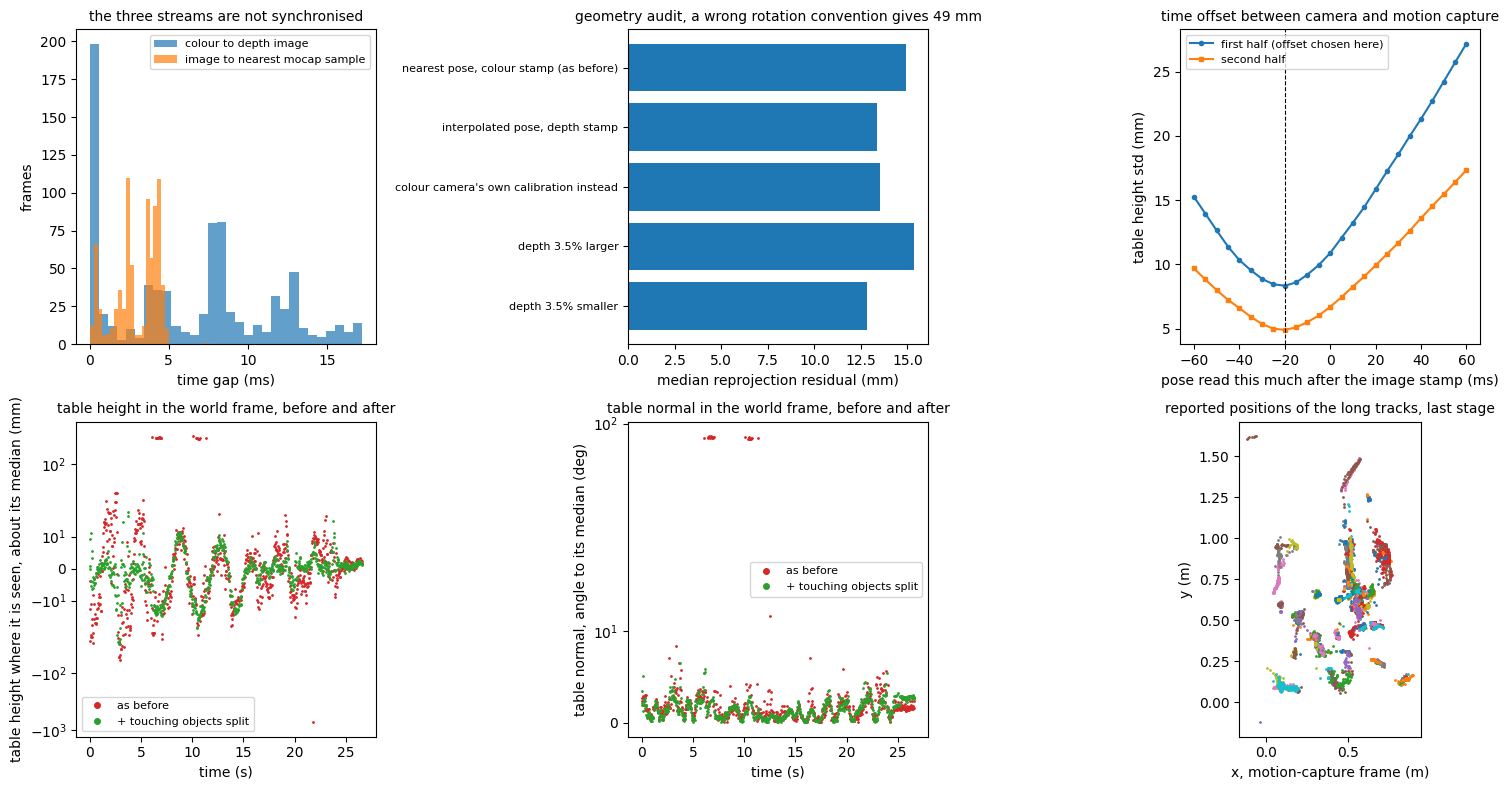

In [ ]:
if tum is not None:
    first_stage, last_stage = list(tum_runs)[0], list(tum_runs)[-1]
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    ax = axes[0, 0]
    ax.hist(image_gap, bins=30, alpha=0.7, label='colour to depth image')
    ax.hist(pose_gap, bins=30, alpha=0.7, label='image to nearest mocap sample')
    ax.set_xlabel('time gap (ms)')
    ax.set_ylabel('frames')
    ax.set_title('the three streams are not synchronised', fontsize=10)
    ax.legend(fontsize=8)

    ax = axes[0, 1]
    shown = tum_audit.iloc[:-1]
    ax.barh(range(len(shown)), shown['median residual (mm)'], color='tab:blue')
    ax.set_yticks(range(len(shown)))
    ax.set_yticklabels(shown.index, fontsize=8)
    ax.invert_yaxis()
    ax.set_xlabel('median reprojection residual (mm)')
    ax.set_title(f"geometry audit, a wrong rotation convention gives {tum_audit['median residual (mm)'].iloc[-1]:.0f} mm", fontsize=10)

    ax = axes[0, 2]
    ax.plot(sweep.index, sweep['first half'], 'o-', ms=3, label='first half (offset chosen here)')
    ax.plot(sweep.index, sweep['second half'], 's-', ms=3, label='second half')
    ax.axvline(1000 * tum_offset, color='k', lw=0.8, ls='--')
    ax.set_xlabel('pose read this much after the image stamp (ms)')
    ax.set_ylabel('table height std (mm)')
    ax.set_title('time offset between camera and motion capture', fontsize=10)
    ax.legend(fontsize=8)

    for ax, quantity in zip(axes[1, :2], ['height', 'angle']):
        for stage, sequence, color in [(first_stage, tum_nearest, 'tab:red'), (last_stage, tum_shifted, 'tab:green')]:
            frames = tum_runs[stage]['frames']
            frames = frames[frames.plane_found]
            normals, middles = table_in_world(sequence, frames)
            common = np.median(normals, axis=0) / np.linalg.norm(np.median(normals, axis=0))
            seconds = frames.stamp.values[:len(normals)] - frames.stamp.values[0]
            if quantity == 'height':
                ax.plot(seconds, 1000 * (middles - np.median(middles, axis=0)) @ common, '.', ms=2, color=color, label=stage.split(':')[0][:28])
            else:
                ax.plot(seconds, np.degrees(np.arccos(np.clip(normals @ common, -1, 1))), '.', ms=2, color=color, label=stage.split(':')[0][:28])
        ax.set_xlabel('time (s)')
        ax.set_yscale('symlog', linthresh=20)
        ax.legend(fontsize=8, markerscale=4)
    axes[1, 0].set_ylabel('table height where it is seen, about its median (mm)')
    axes[1, 0].set_title('table height in the world frame, before and after', fontsize=10)
    axes[1, 1].set_ylabel('table normal, angle to its median (deg)')
    axes[1, 1].set_title('table normal in the world frame, before and after', fontsize=10)

    ax = axes[1, 2]
    tracks = tum_runs[last_stage]['tracks']
    counts = tracks.groupby('id').size()
    for track_id in counts[counts >= 30].index:
        trail = tracks[tracks.id == track_id]
        ax.plot(trail.x, trail.y, '.', ms=2)
    ax.set_xlabel('x, motion-capture frame (m)')
    ax.set_ylabel('y (m)')
    ax.set_aspect('equal')
    ax.set_title('reported positions of the long tracks, last stage', fontsize=10)
    plt.tight_layout()
    plt.show()

In [ ]:
osd_results = None
if osd_complete:
    scene_rows, detection_rows, seconds = [], [], 0.0
    for scene in osd_scenes:
        rgb, depth, truth = osd_frame(scene)
        segmenter = TabletopSegmenter(use_color=False, camera=osd_camera)
        started = time.perf_counter()
        detections, labels = segmenter.detect(rgb, depth)
        seconds += time.perf_counter() - started
        targets, rows = score_labelled_frame(detections, labels, truth)
        found = {row['object'] for row in rows if row['kind'] in ('object', 'merged')}
        clean = {row['object'] for row in rows if row['kind'] == 'object'}
        scene_rows.append({**{key: scene[key] for key in ['split', 'group', 'name']}, 'objects': len(targets),
                           'found': len(found & targets), 'found clean': len(clean & targets), 'segments': len(rows),
                           'right segments': sum(row['kind'] in ('object', 'merged') for row in rows),
                           'table noise (mm)': 1000 * segmenter.noise_std if segmenter.plane is not None else np.nan})
        detection_rows += [{**row, 'split': scene['split'], 'group': scene['group'], 'name': scene['name']} for row in rows]
    osd_results, osd_detections = pd.DataFrame(scene_rows), pd.DataFrame(detection_rows)
    by_group = osd_results.groupby(['split', 'group'], sort=False).agg(
        scenes=('name', 'size'), objects=('objects', 'sum'), found=('found', 'sum'), clean=('found clean', 'sum'),
        segments=('segments', 'sum'), right=('right segments', 'sum'), noise_mm=('table noise (mm)', 'median'))
    by_group['recall'] = by_group.found / by_group.objects
    by_group['clean recall'] = by_group.clean / by_group.objects
    by_group['precision'] = by_group.right / by_group.segments
    print(f'{len(osd_results)} real scenes at {osd_camera.width}x{osd_camera.height}, {1000 * seconds / len(osd_results):.1f} ms per frame for the segmenter')
    print(by_group[['scenes', 'objects', 'recall', 'clean recall', 'precision', 'noise_mm']].round(3))
    wrong = osd_detections[~osd_detections.kind.isin(['object'])].kind.value_counts()
    print()
    print('segments that are not one clean object:', wrong.to_dict())


    test_scenes = [scene for scene in osd_scenes if scene['split'] == 'test']
    test_frames = [osd_frame(scene) for scene in test_scenes]
    split_rows, split_per_scene = {}, {}
    for experiment, name in split_experiments.items():
        split_rows[f'{experiment} ({name})'] = score_split(SPLIT_GRID[name], test_frames, osd_camera)
        split_per_scene[experiment] = pd.DataFrame([score_split(SPLIT_GRID[name], [frame], osd_camera) for frame in test_frames])
    print()
    print(f'touching objects on the {len(test_frames)} test scenes, chosen setting: {chosen_split}')
    print(pd.DataFrame(split_rows).T.astype({'merged': int, 'duplicates': int, 'segments': int}).round(3).to_string())
    for experiment in ['A', 'B']:
        if split_experiments[experiment] == 'none':
            continue
        fewer = split_per_scene['baseline'].merged.sum() - split_per_scene[experiment].merged.sum()
        print(f"experiment {experiment}: {fewer} fewer merged segments ({fewer / max(split_per_scene['baseline'].merged.sum(), 1):.0%}), "
              f"{split_per_scene[experiment].duplicates.sum() - split_per_scene['baseline'].duplicates.sum():+d} duplicates, "
              f"wilcoxon p = {paired_wilcoxon(split_per_scene['baseline'].merged, split_per_scene[experiment].merged):.4f} on merges per scene")

    clean = osd_detections[osd_detections.kind == 'object']
    calls = clean[clean.group.isin(['boxes', 'cylindric objects'])].groupby(['group', 'category']).size().unstack(fill_value=0)
    print()
    print('what clean segments are called')
    print(calls)

    scored = osd_detections.assign(good=osd_detections.kind == 'object')
    test_scored = scored[scored.split == 'test']

    def ranking_quality(confidence, good):
        right, wrong = confidence[good], confidence[~good]
        return np.mean(right[:, None] > wrong[None, :]) + 0.5 * np.mean(right[:, None] == wrong[None, :])

    print()
    print(f'{len(test_scored)} segments in the test scenes, {int((~test_scored.good).sum())} of them not one clean object')
    print(f'confidence with the weights from simulation: AUROC {ranking_quality(test_scored.confidence.values, test_scored.good.values):.3f} on the test scenes')
    learn_scored = scored[scored.split == 'learn']
    real_weights = fit_logistic(np.array(list(learn_scored.features)), learn_scored.good.values.astype(float), l2=1.0)
    refitted = 1 / (1 + np.exp(-np.array(list(test_scored.features)) @ real_weights))
    print(f'same features, weights fitted on the {len(learn_scored)} segments of the real learn scenes: '
          f'AUROC {ranking_quality(refitted, test_scored.good.values):.3f} on the test scenes')
else:
    print(f'Object Segmentation Database: {len(osd_scenes)} scenes found, it could not be downloaded in full. the cell is skipped')

110 real scenes at 320x240, 44.5 ms per frame for the segmenter
                         scenes  objects  recall  clean recall  precision  noise_mm
split group                                                                        
learn boxes                  17       38   1.000         1.000      1.000     1.938
      stacked boxes           8       20   1.000         0.950      0.957     1.527
      occluded objects        8       16   1.000         1.000      1.000     1.642
      cylindric objects      12       38   1.000         1.000      1.000     1.848
test  boxes                  16       36   1.000         1.000      1.000     1.489
      stacked boxes           8       21   0.952         0.857      1.000     1.510
      occluded objects        7       14   1.000         1.000      0.952     1.608
      cylindric objects      12       42   1.000         1.000      1.000     1.729
      mixed objects          12       80   0.975         0.938      0.964     1.732
      comple

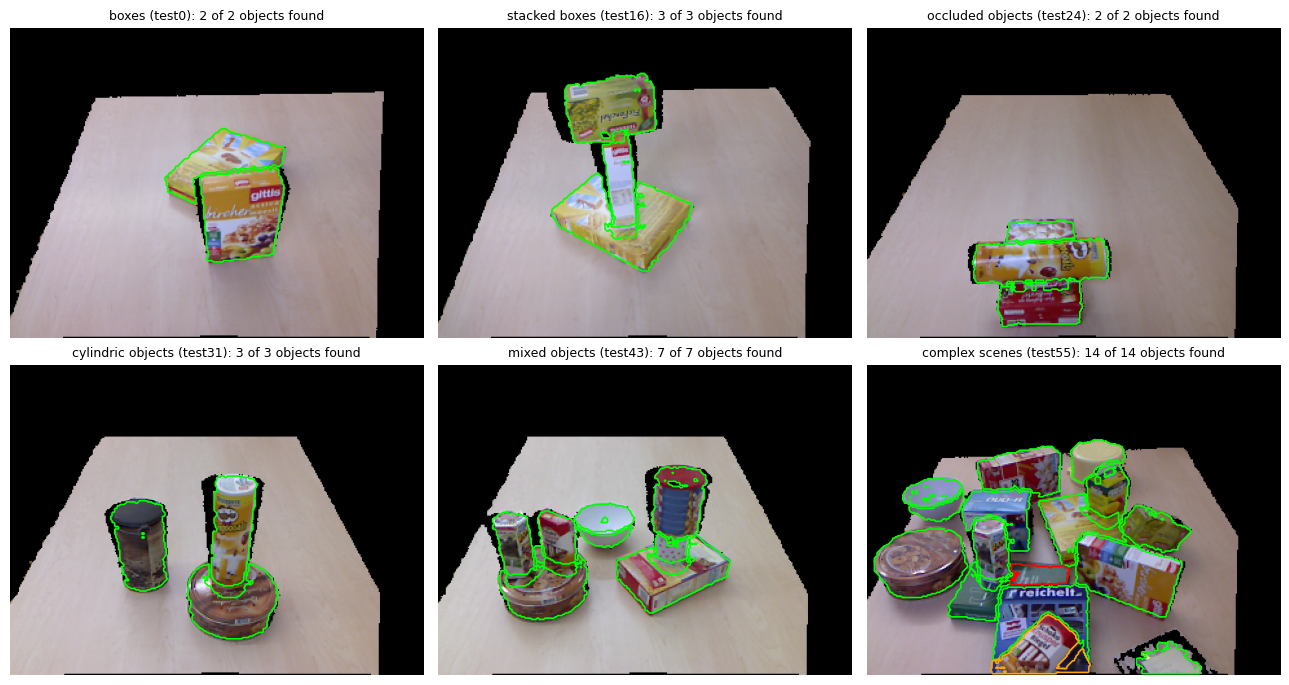

In [ ]:
if osd_results is not None:
    outline_colors = {'object': 'lime', 'merged': 'orange', 'duplicate': 'red', 'table or background': 'red'}
    shown = [next(scene for scene in osd_scenes if scene['split'] == 'test' and scene['group'] == group) for _, _, group in OSD_GROUPS['test']]
    fig, axes = plt.subplots(2, 3, figsize=(13, 7))
    for ax, scene in zip(axes.ravel(), shown):
        frame = labelled_cloud_frame(read_pcd(scene['path']))
        rgb, depth, truth = frame['rgb'][::2, ::2], frame['depth'][::2, ::2], frame['labels'][::2, ::2]
        detections, labels = TabletopSegmenter(use_color=False, camera=osd_camera).detect(rgb, depth)
        targets, rows = score_labelled_frame(detections, labels, truth)
        ax.imshow(rgb)
        for row in rows:
            ax.contour(labels == row['label_id'], levels=[0.5], colors=outline_colors[row['kind']], linewidths=1.2)
        found = {row['object'] for row in rows if row['kind'] in ('object', 'merged')}
        ax.set_title(f"{scene['group']} ({scene['name']}): {len(found & targets)} of {len(targets)} objects found", fontsize=9)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

In [ ]:
def benchmark_test(against, metric):
    return benchmark_tests[(benchmark_tests.against == against) & (benchmark_tests.metric == metric)].iloc[0]


print('tracker carried forward:', selected)
print('touching objects split with:', TabletopSegmenter.split_settings)
print()
print(f'randomized benchmark, {N_BENCHMARK} held-out scenes, complete system E against each configuration')
for against in [name for name in benchmark.config.unique() if name not in ('E: complete system', 'v1 world 3D')]:
    idf1, switches = benchmark_test(against, 'idf1'), benchmark_test(against, 'id_switches')
    print(f'  {against}: IDF1 {idf1.other:.3f} against {idf1.E:.3f} (Holm p {idf1.p_holm:.3f}), '
          f'ID switches {switches.other:.2f} against {switches.E:.2f} per scene (Holm p {switches.p_holm:.3f})')

print()
print(f'latency on this machine, {IMG_W}x{IMG_H}, one core, 99th percentile')
for scenario, group in timed.groupby('scenario', sort=False):
    perception, planning = group['perception path'].quantile(0.99), group['planning path'].quantile(0.99)
    print(f"  {scenario}: perception {perception:.1f} ms ({'inside' if perception < 1000 * DT else 'over'} the "
          f'{1000 * DT:.1f} ms frame period), planning {planning:.1f} ms beside it')

print()
calibration = coverage_table(estimates, 'mounting')
print('reported covariance, share of errors inside the 95% region:',
      {name: round(float(value), 3) for name, value in calibration['inside_95%'].items()})

if pick_trials is not None:
    tried = pick_trials[~declined]
    low, high = wilson_interval(tried.success.sum(), len(tried))
    on_target = pick_trials[pick_trials.success]
    print(f'physics pick and place, {N_PICK_TRIALS} held-out trials: {declined.sum()} declined, {tried.success.sum()} of {len(tried)} '
          f'attempted placed ({tried.success.mean():.1%} [{low:.1%}, {high:.1%}]), median placement error '
          f'{1000 * on_target.placement_error.median():.1f} mm, unwanted contact in {(pick_trials.contact_frames > 0).sum()} trials')
print('moved objects, share of kept plans that then fail:', {rule.replace(' takes it', ''): round(float((~stale_check[stale_check[rule]].works).mean()), 3)
                                                             for rule in ['fixed limit takes it', 'rule takes it']})
low_spots = spot_check[spot_check['where'] != 'nothing there']
print(f"place spots with a low object on them called free: {low_spots['before: free'].mean():.1%} before, "
      f"{low_spots['now: free'].mean():.1%} now. empty spots refused: "
      f"{1 - spot_check[spot_check['where'] == 'nothing there']['now: free'].mean():.1%} now")

print()
if osd_results is not None:
    test_groups = by_group.loc['test']
    print('Object Segmentation Database, test scenes:', {group: round(float(value), 3) for group, value in test_groups['clean recall'].items()}, '(clean recall)')
    print('  merged segments on the test scenes:', {experiment: int(split_per_scene[experiment].merged.sum()) for experiment in split_per_scene})
else:
    print('Object Segmentation Database: not available in this run')
if tum is not None:
    first, last = tum_table.columns[0], tum_table.columns[-1]
    print(f"TUM fr1/xyz: table height std {tum_table.loc['table height std (mm)', first]:.1f} mm in the first stage, "
          f"{tum_table.loc['table height std (mm)', last]:.1f} mm in the last, "
          f"{tum_table.loc['hops per track per minute', last]:.1f} hops per track per minute")
    print('  hops per track per minute by tracker:', {name: round(float(row['hops per track per minute']), 1) for name, row in hop_rows.items()})
else:
    print('TUM RGB-D: not available in this run')
if ycbv_results is not None:
    print(f'YCB-Video: {len(ycbv_results)} scenes scored, {len(check_rows) - len(ycbv_results)} left out by the input check, '
          f"recall {ycbv_results.recall.mean():.3f}, IDF1 {', '.join(f'{c[5:]} {ycbv_results[c].mean():.3f}' for c in pose_columns)}")
else:
    print('YCB-Video: not available in this run')

tracker carried forward: T18 = T14 + appearance in the association cost
touching objects split with: {'step': 3, 'crease': 0.3, 'saddle': 0.2}

randomized benchmark, 120 held-out scenes, complete system E against each configuration
  baseline: earlier pipeline: IDF1 0.974 against 0.982 (Holm p 0.048), ID switches 1.09 against 1.18 per scene (Holm p 0.108)
  A: no uncertainty-aware association: IDF1 0.977 against 0.982 (Holm p 1.000), ID switches 0.72 against 1.18 per scene (Holm p 1.000)
  B: no re-identification: IDF1 0.974 against 0.982 (Holm p 0.161), ID switches 1.27 against 1.18 per scene (Holm p 0.392)
  C: fixed measurement noise: IDF1 0.977 against 0.982 (Holm p 1.000), ID switches 1.11 against 1.18 per scene (Holm p 1.000)
  D: no uncertainty-aware grasp selection: IDF1 0.982 against 0.982 (Holm p nan), ID switches 1.18 against 1.18 per scene (Holm p nan)
  F: no table plane prior: IDF1 0.980 against 0.982 (Holm p 1.000), ID switches 0.93 against 1.18 per scene (Holm p 1.000)
